In [36]:
import os
import os, sys
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn import Sequential
import torch.optim as optim
import voxelmorph as vxm
import neurite as ne
import scipy.ndimage

os.environ['VXM_BACKEND'] = 'pytorch'

In [2]:
os.environ.get('VXM_BACKEND')

'pytorch'

In [3]:
device = torch.device('cuda:0' if torch.cuda.is_available() else 'cpu')
print(device)

cuda:0


In [4]:
# 画像を読み込み
x_train = np.load('Data/TrainData_NoBed.npz')['Train']
x_train = np.transpose(x_train, (3, 0, 1, 2))

print('Resized train vol_shape:', x_train.shape[1:])
print('Resized train shape:', x_train.shape)

Resized train vol_shape: (128, 256, 256)
Resized train shape: (400, 128, 256, 256)


In [5]:
import torch

def vxm_data_generator(x_data, batch_size):
    vol_shape = x_data.shape[1:]  # データ形状を取得
    ndims = len(vol_shape)
    
    zero_phi = np.zeros([batch_size, *vol_shape, ndims])
    
    while True:
        idx1 = np.random.randint(0, x_data.shape[0], size=batch_size)
        moving_images = x_data[idx1, ..., np.newaxis]
        # ファインチューニングでは同じ症例同士のペアを避ける
        idx2 = np.random.randint(0, x_data.shape[0], size=batch_size)
        while np.any(idx2 == idx1):
            same_case = idx2 == idx1
            idx2[same_case] = np.random.randint(0, x_data.shape[0], size=same_case.sum())
        fixed_images = x_data[idx2, ..., np.newaxis]

        # TensorFlowからPyTorchのデータ形式に変換
        moving_images = torch.tensor(moving_images).permute(0, 4, 1, 2, 3).float()
        fixed_images = torch.tensor(fixed_images).permute(0, 4, 1, 2, 3).float()

        # チャンネルを最初の次元に追加
        moving_images = moving_images.permute(0, 1, 2, 3, 4)  # チャンネルを最初の次元に移動
        fixed_images = fixed_images.permute(0, 1, 2, 3, 4)  # チャンネルを最初の次元に移動

        inputs = [moving_images, fixed_images]
        outputs = [fixed_images, zero_phi]

        yield (inputs, outputs)

In [6]:
train_generator = vxm_data_generator(x_train, batch_size=2)
in_sample, out_sample = next(train_generator)

# in_sampleとout_sampleの内容を確認する
print("Input Sample Shapes:")
print("Moving Images Shape:", in_sample[0].shape)
print("Fixed Images Shape:", in_sample[1].shape)

print("\nOutput Sample Shapes:")
print("Moved Images (Fixed) Shape:", out_sample[0].shape)
print("Zero Gradient Shape:", out_sample[1].shape)

Input Sample Shapes:
Moving Images Shape: torch.Size([2, 1, 128, 256, 256])
Fixed Images Shape: torch.Size([2, 1, 128, 256, 256])

Output Sample Shapes:
Moved Images (Fixed) Shape: torch.Size([2, 1, 128, 256, 256])
Zero Gradient Shape: (2, 128, 256, 256, 3)


In [7]:
mse_loss = vxm.losses.MSE().loss
grad_loss = vxm.losses.Grad('l2').loss

def total_loss(y_true, y_pred):
    mse = mse_loss(y_true, y_pred)
    grad = grad_loss(y_true, y_pred)
    return mse + 0.01 * grad, mse, grad
#     return mse_loss(y_true, y_pred)

def MSE_Loss(y_true, y_pred):
    y_true = y_true.to(device)
    y_pred = y_pred.to(device)
    mse = mse_loss(y_true, y_pred)
    return mse

def lncc_loss(I, J, window=9, eps=1e-5):
    # I, J: (B, 1, D, H, W)
    padding = window // 2
    weight = torch.ones(1, 1, window, window, window, device=I.device)

    I2 = I * I
    J2 = J * J
    IJ = I * J

    I_sum = F.conv3d(I, weight, padding=padding)
    J_sum = F.conv3d(J, weight, padding=padding)
    I2_sum = F.conv3d(I2, weight, padding=padding)
    J2_sum = F.conv3d(J2, weight, padding=padding)
    IJ_sum = F.conv3d(IJ, weight, padding=padding)

    win_size = window ** 3
    u_I = I_sum / win_size
    u_J = J_sum / win_size

    cross = IJ_sum - u_J * I_sum - u_I * J_sum + u_I * u_J * win_size
    I_var = I2_sum - 2 * u_I * I_sum + u_I * u_I * win_size
    J_var = J2_sum - 2 * u_J * J_sum + u_J * u_J * win_size

    lncc = cross * cross / (I_var * J_var + eps)
    return -torch.mean(lncc)  # maximize LNCC → minimize -LNCC

In [8]:
# configure unet input shape (concatenation of moving and fixed images)
ndim = 3
unet_input_features = 2
# inshape = (*x_train.shape[1:], unet_input_features)

nb_features = [
    [32, 64, 64, 64, 64],
    [64, 64, 64, 64, 64, 32, 16, 16]
]


In [9]:
import voxelmorph as vxm
import inspect

print(vxm.__file__)
print(vxm.networks.__file__)
print([name for name in dir(vxm.networks) if "VxmDense" in name])

d:\Saito\voxelmorph\__init__.py
d:\Saito\voxelmorph\torch\networks.py
['VxmDense', 'VxmDense1', 'VxmDense2', 'VxmDense_128_256', 'VxmDense_128_256_256']


In [10]:
model3D = vxm.networks.VxmDense_128_256_256((128, 256, 256), nb_features, int_steps=0)
model3D.to(device)
optimizer = optim.Adam(model3D.parameters(), lr=1e-4)

transformer = vxm.layers.SpatialTransformer((64, 128, 128)).to(device)
transformer256 = vxm.layers.SpatialTransformer((128, 256, 256)).to(device)

[64, 128, 128]


c:\Users\user\anaconda3\envs\nn\lib\site-packages\torch\functional.py:507: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at C:\cb\pytorch_1000000000000\work\aten\src\ATen\native\TensorShape.cpp:3550.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]


In [11]:
import math
from pathlib import Path
import torch
import matplotlib.pyplot as plt

band_names = ['LLL', 'LLH', 'LHL', 'LHH', 'HLL', 'HLH', 'HHL', 'HHH']

wavelet_vis_enabled = False
wavelet_vis_every = 100
wavelet_vis_dir = Path('wavelet_stage_outputs')
wavelet_vis_dir.mkdir(exist_ok=True)

class Haar3DAnalysisOnly(nn.Module):
    def __init__(self):
        super().__init__()

        hL = torch.tensor([1.0, 1.0], dtype=torch.float32) / math.sqrt(2.0)
        hH = torch.tensor([1.0, -1.0], dtype=torch.float32) / math.sqrt(2.0)

        filters = []
        names = []

        for z_name, z_filter in zip(['L', 'H'], [hL, hH]):
            for y_name, y_filter in zip(['L', 'H'], [hL, hH]):
                for x_name, x_filter in zip(['L', 'H'], [hL, hH]):
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)
                    names.append(z_name + y_name + x_name)

        weight = torch.stack(filters, dim=0).unsqueeze(1)
        self.register_buffer('weight', weight)
        self.names = names

    def forward(self, x):
        x = F.pad(x, (0, 1, 0, 1, 0, 1))
        return F.conv3d(x, self.weight, stride=1, padding=0)

def analysis_filter_3d(x, analysis_layer):
    return analysis_layer(x)

def down_sampling_3d(w):
    return w[:, :, ::2, ::2, ::2]

def up_sampling_3d(w_down):
    B, C, D, H, W = w_down.shape
    w_up = torch.zeros(
        B, C, D * 2, H * 2, W * 2,
        dtype=w_down.dtype,
        device=w_down.device
    )
    w_up[:, :, ::2, ::2, ::2] = w_down
    return w_up

def make_3d_filter(fz, fy, fx):
    return fz[:, None, None] * fy[None, :, None] * fx[None, None, :]

def create_synthesis_filters(device):
    low = torch.tensor([1.0, 1.0], dtype=torch.float32, device=device) / math.sqrt(2.0)
    high = torch.tensor([1.0, -1.0], dtype=torch.float32, device=device) / math.sqrt(2.0)

    filters = torch.stack([
        make_3d_filter(low, low, low),
        make_3d_filter(low, low, high),
        make_3d_filter(low, high, low),
        make_3d_filter(low, high, high),
        make_3d_filter(high, low, low),
        make_3d_filter(high, low, high),
        make_3d_filter(high, high, low),
        make_3d_filter(high, high, high),
    ], dim=0)

    filters = torch.flip(filters, dims=[1, 2, 3]).unsqueeze(1)
    return filters

def synthesis_filter_3d(
    w_up,
    synthesis_filters
):

    B, C, D, H, W = w_up.shape

    # ========================================================
    # 8帯域を1回のGrouped Conv3Dで処理
    #
    # input  : (B, 8, D, H, W)
    # filter : (8, 1, 2, 2, 2)
    # groups : 8
    #
    # 各Wavelet帯域に対応するfilterを独立して適用
    # ========================================================

    filtered_bands = F.conv3d(
        w_up,
        synthesis_filters,
        stride=1,
        padding=1,
        groups=C
    )

    # ========================================================
    # Originalと同じcrop
    # ========================================================

    filtered_bands = filtered_bands[
        :,
        :,
        :D,
        :H,
        :W
    ]

    # ========================================================
    # 8帯域を加算して再構成
    # ========================================================

    reconstructed = torch.sum(
        filtered_bands,
        dim=1,
        keepdim=True
    )

    return (
        reconstructed,
        filtered_bands
    )

analysis = Haar3DAnalysisOnly().to(device)
synthesis_filters = create_synthesis_filters(device)
analysis_names = analysis.names

In [12]:
from pathlib import Path
import csv
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ==========================================
# カリキュラム学習・途中経過観察の設定
# ==========================================
OBSERVE_EVERY = 1000
OBSERVE_PATIENT_ID = 0
# 正負両方向を同じ絶対値で評価する
OBSERVE_SHIFTS = [-40, -30, -20, -10, 0, 10, 20, 30, 40]
OBSERVE_RANDOM_SEED = 20260803
OBSERVE_RANDOM_MAX_SHIFT = 40.0

OBSERVE_DIR = Path("curriculum_observation")
OBSERVE_DIR.mkdir(exist_ok=True)

OBSERVE_CSV = OBSERVE_DIR / "curriculum_observation_metrics.csv"

# 観察用の患者画像を固定
observation_moving = torch.from_numpy(
    x_train[OBSERVE_PATIENT_ID:OBSERVE_PATIENT_ID + 1]
).unsqueeze(1).to(
    device=device,
    dtype=torch.float32
)


def calculate_rmse(reference, prediction):
    return torch.sqrt(
        torch.mean((reference - prediction) ** 2)
    ).item()


def calculate_dvf_rmse(reference_flow, predicted_flow):
    return torch.sqrt(
        torch.mean((reference_flow - predicted_flow) ** 2)
    ).item()


def observe_curriculum_progress(
    model,
    epoch,
    moving_image,
    shifts,
):
    """
    固定患者・固定x方向変位を使い、
    カリキュラム学習途中の性能を表示・保存する。
    """

    was_training = model.training
    model.eval()

    epoch_dir = OBSERVE_DIR / f"epoch_{epoch:06d}"
    epoch_dir.mkdir(exist_ok=True)

    result_rows = []

    with torch.no_grad():
        moving_analysis = analysis_filter_3d(
            moving_image,
            analysis
        )

        moving_w = down_sampling_3d(
            moving_analysis
        ).to(device)

        figure, axes = plt.subplots(
            len(shifts),
            4,
            figsize=(16, 4 * len(shifts)),
            constrained_layout=True
        )

        if len(shifts) == 1:
            axes = np.expand_dims(axes, axis=0)

        observation_slice = moving_image.shape[2] // 2

        moving_np = moving_image[
            0, 0, observation_slice
        ].detach().cpu().numpy()

        display_vmin, display_vmax = np.percentile(
            moving_np,
            [1, 99]
        )

        for row_index, shift_pixels in enumerate(shifts):

            # フル解像度の正解DVF
            # channel 0=z, 1=y, 2=x
            true_flow_full = torch.zeros(
                (
                    1,
                    3,
                    moving_image.shape[2],
                    moving_image.shape[3],
                    moving_image.shape[4]
                ),
                dtype=moving_image.dtype,
                device=device
            )

            true_flow_full[:, 2] = float(shift_pixels)

            # 正解画像 Moving′
            moving_prime = transformer256(
                moving_image,
                true_flow_full
            )

            moving_prime_analysis = analysis_filter_3d(
                moving_prime,
                analysis
            )

            moving_prime_w = down_sampling_3d(
                moving_prime_analysis
            ).to(device)

            # DVF予測
            predicted_flow = model(
                moving_w,
                moving_prime_w
            )

            # 8バンドへ同じDVFを適用
            moved_w = transformer(
                moving_w,
                predicted_flow
            )

            moved_up = up_sampling_3d(
                moved_w
            )

            moved, _ = synthesis_filter_3d(
                moved_up,
                synthesis_filters
            )

            moved = moved.to(device)

            # 低解像度DVFの正解
            true_flow_low = torch.zeros_like(
                predicted_flow
            )

            true_flow_low[:, 2] = (
                float(shift_pixels) / 2.0
            )

            image_rmse_before = calculate_rmse(
                moving_prime,
                moving_image
            )

            image_rmse_after = calculate_rmse(
                moving_prime,
                moved
            )

            dvf_rmse = calculate_dvf_rmse(
                true_flow_low,
                predicted_flow
            )

            predicted_x_mean = (
                predicted_flow[:, 2]
                .mean()
                .item()
            )

            result_rows.append({
                "epoch": epoch,
                "shift_pixels_fullres_x": shift_pixels,
                "true_flow_x_lowres": shift_pixels / 2.0,
                "predicted_flow_x_mean_lowres": predicted_x_mean,
                "rmse_before": image_rmse_before,
                "rmse_after": image_rmse_after,
                "dvf_rmse": dvf_rmse,
            })

            moving_prime_np = moving_prime[
                0, 0, observation_slice
            ].detach().cpu().numpy()

            moved_np = moved[
                0, 0, observation_slice
            ].detach().cpu().numpy()

            predicted_flow_x_np = predicted_flow[
                0,
                2,
                predicted_flow.shape[2] // 2
            ].detach().cpu().numpy()

            axes[row_index, 0].imshow(
                moving_np,
                cmap="gray",
                vmin=display_vmin,
                vmax=display_vmax
            )
            axes[row_index, 0].set_title(
                f"Moving\nEpoch {epoch}"
            )

            axes[row_index, 1].imshow(
                moving_prime_np,
                cmap="gray",
                vmin=display_vmin,
                vmax=display_vmax
            )
            axes[row_index, 1].set_title(
                f"Moving'\nx shift={shift_pixels}px"
            )

            axes[row_index, 2].imshow(
                moved_np,
                cmap="gray",
                vmin=display_vmin,
                vmax=display_vmax
            )
            axes[row_index, 2].set_title(
                f"Moved\nRMSE={image_rmse_after:.5f}"
            )

            dvf_image = axes[row_index, 3].imshow(
                predicted_flow_x_np,
                cmap="jet"
            )

            axes[row_index, 3].set_title(
                "Predicted DVF x\n"
                f"mean={predicted_x_mean:.3f}, "
                f"RMSE={dvf_rmse:.3f}"
            )

            figure.colorbar(
                dvf_image,
                ax=axes[row_index, 3],
                fraction=0.046,
                pad=0.04
            )

            for column_index in range(4):
                axes[row_index, column_index].axis("off")

        figure.suptitle(
            f"Curriculum learning observation — Epoch {epoch}",
            fontsize=16
        )

        figure_path = (
            epoch_dir
            / f"curriculum_observation_epoch_{epoch:06d}.png"
        )

        figure.savefig(
            figure_path,
            dpi=180,
            bbox_inches="tight"
        )

        plt.show()
        plt.close(figure)

    csv_exists = OBSERVE_CSV.exists()

    with OBSERVE_CSV.open(
        "a",
        newline="",
        encoding="utf-8"
    ) as file:
        writer = csv.DictWriter(
            file,
            fieldnames=result_rows[0].keys()
        )

        if not csv_exists:
            writer.writeheader()

        writer.writerows(result_rows)

    if was_training:
        model.train()

    print(
        f"[Observation] Epoch {epoch}: "
        f"saved to {epoch_dir}"
    )


def observe_random_deformation_progress(model, epoch, moving_image):
    """学習と同型の固定ランダム・滑らかDVFで性能を観察する。"""
    was_training = model.training
    model.eval()
    epoch_dir = OBSERVE_DIR / f"epoch_{epoch:06d}"
    epoch_dir.mkdir(exist_ok=True)

    # 毎回まったく同じDVFを作るため、局所Generatorを使う。
    random_generator = torch.Generator(device="cpu")
    random_generator.manual_seed(OBSERVE_RANDOM_SEED)
    true_flow_full = (
        torch.rand((1, 3, 8, 16, 16), generator=random_generator) * 2 - 1
    ) * OBSERVE_RANDOM_MAX_SHIFT
    true_flow_full = gaussian_smooth_3d(true_flow_full, sigma=2.0)
    true_flow_full = F.interpolate(
        true_flow_full, size=(128, 256, 256), mode="trilinear", align_corners=False
    ).to(device)

    with torch.no_grad():
        moving_prime = transformer256(moving_image, true_flow_full)
        moving_w = down_sampling_3d(analysis_filter_3d(moving_image, analysis)).to(device)
        moving_prime_w = down_sampling_3d(
            analysis_filter_3d(moving_prime, analysis)
        ).to(device)
        
        predicted_flow = model(
            moving_w,
            moving_prime_w
        )

        moved_w = transformer(
            moving_w,
            predicted_flow
        )

        moved_up = up_sampling_3d(
            moved_w
        )

        moved, _ = synthesis_filter_3d(
            moved_up,
            synthesis_filters
        )

        moved = moved.to(device)

        true_flow_low = F.interpolate(
            true_flow_full, size=predicted_flow.shape[2:], mode="trilinear", align_corners=False
        )/2.0
        rmse_before = calculate_rmse(moving_prime, moving_image)
        rmse_after = calculate_rmse(moving_prime, moved)
        dvf_rmse = calculate_dvf_rmse(true_flow_low, predicted_flow)

        result_row = {
            "epoch": epoch, "seed": OBSERVE_RANDOM_SEED,
            "max_initial_shift": OBSERVE_RANDOM_MAX_SHIFT,
            "rmse_before": rmse_before, "rmse_after": rmse_after,
            "dvf_rmse": dvf_rmse,
            "true_flow_absmax_lowres": true_flow_low.abs().max().item(),
            "predicted_flow_absmax_lowres": predicted_flow.abs().max().item(),
        }

        slice_index = moving_image.shape[2] // 2
        flow_slice = predicted_flow.shape[2] // 2
        figure, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
        image_vmin, image_vmax = np.percentile(
            moving_image[0, 0, slice_index].detach().cpu().numpy(), [1, 99]
        )
        for ax, image, title in [
            (axes[0, 0], moving_image, "Moving"),
            (axes[0, 1], moving_prime, "Target (random DVF)"),
            (axes[0, 2], moved, f"Moved (RMSE={rmse_after:.5f})"),
        ]:
            ax.imshow(image[0, 0, slice_index].detach().cpu(), cmap="gray", vmin=image_vmin, vmax=image_vmax)
            ax.set_title(title)
            ax.axis("off")
        for component, name in enumerate(["z", "y", "x"]):
            error = (predicted_flow[0, component, flow_slice] - true_flow_low[0, component, flow_slice]).detach().cpu()
            dvf = axes[1, component].imshow(error, cmap="coolwarm")
            axes[1, component].set_title(f"{name}-DVF error")
            axes[1, component].axis("off")
            figure.colorbar(dvf, ax=axes[1, component], fraction=0.046, pad=0.04)
        figure.suptitle(f"Fixed random deformation observation — Epoch {epoch}; DVF RMSE={dvf_rmse:.4f}")
        figure.savefig(epoch_dir / f"random_deformation_epoch_{epoch:06d}.png", dpi=180, bbox_inches="tight")
        plt.show()
        plt.close(figure)

    random_csv = OBSERVE_DIR / "random_deformation_observation_metrics.csv"
    csv_exists = random_csv.exists()
    with random_csv.open("a", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=result_row.keys())
        if not csv_exists:
            writer.writeheader()
        writer.writerow(result_row)
    if was_training:
        model.train()
    print(f"[Random deformation observation] Epoch {epoch}: saved to {epoch_dir}")

=== 3D Haar Orthogonality Check ===
Filter shape : torch.Size([8, 1, 2, 2, 2])
Flattened    : torch.Size([8, 8])

Gram matrix W W^T:
tensor([[1.0000e+00, 3.0002e-09, 3.0002e-09, 4.4503e-09, 1.7901e-08, 4.4503e-09,
         1.1901e-08, 3.0002e-09],
        [3.0002e-09, 1.0000e+00, 4.4503e-09, 3.0002e-09, 4.4503e-09, 1.7901e-08,
         3.0002e-09, 1.1901e-08],
        [3.0002e-09, 4.4503e-09, 1.0000e+00, 3.0002e-09, 1.1901e-08, 3.0002e-09,
         1.7901e-08, 4.4503e-09],
        [4.4503e-09, 3.0002e-09, 3.0002e-09, 1.0000e+00, 3.0002e-09, 1.1901e-08,
         4.4503e-09, 1.7901e-08],
        [1.7901e-08, 4.4503e-09, 1.1901e-08, 3.0002e-09, 1.0000e+00, 3.0002e-09,
         3.0002e-09, 4.4503e-09],
        [4.4503e-09, 1.7901e-08, 3.0002e-09, 1.1901e-08, 3.0002e-09, 1.0000e+00,
         4.4503e-09, 3.0002e-09],
        [1.1901e-08, 3.0002e-09, 1.7901e-08, 4.4503e-09, 3.0002e-09, 4.4503e-09,
         1.0000e+00, 3.0002e-09],
        [3.0002e-09, 1.1901e-08, 4.4503e-09, 1.7901e-08, 4.450

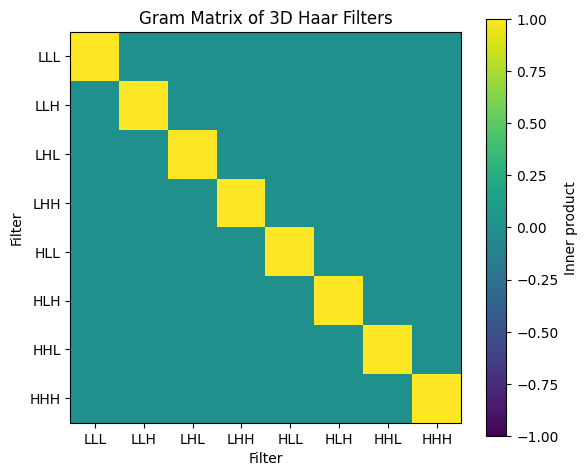

In [13]:
import torch
import matplotlib.pyplot as plt

# analysis.weight:
# shape = (8, 1, 2, 2, 2)

W = analysis.weight.detach().cpu()

# 各3Dフィルタを8次元ベクトルに変換
W_flat = W.view(W.shape[0], -1)

# Gram行列 G = W W^T
G = W_flat @ W_flat.T

# 単位行列
I = torch.eye(G.shape[0])

# 誤差
error = G - I

print("=== 3D Haar Orthogonality Check ===")
print("Filter shape :", W.shape)
print("Flattened    :", W_flat.shape)

print("\nGram matrix W W^T:")
print(G)

print("\nMax abs error from identity:")
print(error.abs().max().item())

print("\nMean abs error from identity:")
print(error.abs().mean().item())

# 各フィルタのL2ノルム
norms = torch.linalg.vector_norm(W_flat, dim=1)

print("\nFilter L2 norms:")
for name, norm in zip(analysis.names, norms):
    print(f"{name}: {norm.item():.10f}")

# 判定
tol = 1e-6

if torch.allclose(G, I, atol=tol, rtol=0):
    print("\n✅ 8個の3D Haarフィルタは正規直交です。")
else:
    print("\n❌ 正規直交条件を満たしていません。")


# 可視化
plt.figure(figsize=(6, 5))
plt.imshow(G, vmin=-1, vmax=1)
plt.colorbar(label="Inner product")
plt.xticks(range(8), analysis.names)
plt.yticks(range(8), analysis.names)
plt.title("Gram Matrix of 3D Haar Filters")
plt.xlabel("Filter")
plt.ylabel("Filter")
plt.tight_layout()
plt.show()

In [14]:
# ============================================================
# Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(tensor, sigma=1.0):
    from scipy.ndimage import gaussian_filter

    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )

In [15]:
test = torch.randn(
    2, 3, 8, 16, 16,
    device=device
)

test_smoothed = gaussian_smooth_3d(
    test,
    sigma=2.0
)

print("input :", test.shape, test.device)
print("output:", test_smoothed.shape, test_smoothed.device)

input : torch.Size([2, 3, 8, 16, 16]) cuda:0
output: torch.Size([2, 3, 8, 16, 16]) cuda:0


In [16]:
# ======================================================================
# RESTORE ORIGINAL WAVELET IMPLEMENTATION
# ======================================================================

import math
import torch
import torch.nn as nn
import torch.nn.functional as F


# ======================================================================
# 1. Haar Analysis
# ======================================================================

class Haar3DAnalysisOnly(nn.Module):

    def __init__(self):

        super().__init__()

        hL = (
            torch.tensor(
                [1.0, 1.0],
                dtype=torch.float32
            )
            /
            math.sqrt(2.0)
        )

        hH = (
            torch.tensor(
                [1.0, -1.0],
                dtype=torch.float32
            )
            /
            math.sqrt(2.0)
        )


        filters = []
        names = []


        for z_name, z_filter in zip(
            ["L", "H"],
            [hL, hH]
        ):

            for y_name, y_filter in zip(
                ["L", "H"],
                [hL, hH]
            ):

                for x_name, x_filter in zip(
                    ["L", "H"],
                    [hL, hH]
                ):

                    kernel = (
                        z_filter[:, None, None]
                        *
                        y_filter[None, :, None]
                        *
                        x_filter[None, None, :]
                    )

                    filters.append(
                        kernel
                    )

                    names.append(
                        z_name
                        +
                        y_name
                        +
                        x_name
                    )


        weight = (
            torch.stack(
                filters,
                dim=0
            )
            .unsqueeze(1)
        )


        self.register_buffer(
            "weight",
            weight
        )


        self.names = names


    def forward(
        self,
        x
    ):

        x = F.pad(
            x,
            (
                0, 1,
                0, 1,
                0, 1
            )
        )


        return F.conv3d(
            x,
            self.weight,
            stride=1,
            padding=0
        )


# ======================================================================
# 2. Analysis wrapper
#
# ★ ここが重要
#
# filtersではなくanalysis_layerを受け取る
# ======================================================================

def analysis_filter_3d(
    x,
    analysis_layer
):

    return analysis_layer(
        x
    )


# ======================================================================
# 3. Downsampling
# ======================================================================

def down_sampling_3d(
    w
):

    return w[
        :,
        :,
        ::2,
        ::2,
        ::2
    ]


# ======================================================================
# 4. Upsampling
# ======================================================================

def up_sampling_3d(
    w_down
):

    B, C, D, H, W = (
        w_down.shape
    )


    w_up = torch.zeros(

        B,
        C,
        D * 2,
        H * 2,
        W * 2,

        dtype=w_down.dtype,
        device=w_down.device

    )


    w_up[
        :,
        :,
        ::2,
        ::2,
        ::2
    ] = w_down


    return w_up


# ======================================================================
# 5. Synthesis filter creation
# ======================================================================

def make_3d_filter(
    fz,
    fy,
    fx
):

    return (
        fz[:, None, None]
        *
        fy[None, :, None]
        *
        fx[None, None, :]
    )


def create_synthesis_filters(
    device
):

    low = (
        torch.tensor(
            [1.0, 1.0],
            dtype=torch.float32,
            device=device
        )
        /
        math.sqrt(2.0)
    )


    high = (
        torch.tensor(
            [1.0, -1.0],
            dtype=torch.float32,
            device=device
        )
        /
        math.sqrt(2.0)
    )


    filters = torch.stack(

        [

            make_3d_filter(
                low,
                low,
                low
            ),

            make_3d_filter(
                low,
                low,
                high
            ),

            make_3d_filter(
                low,
                high,
                low
            ),

            make_3d_filter(
                low,
                high,
                high
            ),

            make_3d_filter(
                high,
                low,
                low
            ),

            make_3d_filter(
                high,
                low,
                high
            ),

            make_3d_filter(
                high,
                high,
                low
            ),

            make_3d_filter(
                high,
                high,
                high
            ),

        ],

        dim=0

    )


    filters = torch.flip(
        filters,
        dims=[
            1,
            2,
            3
        ]
    ).unsqueeze(
        1
    )


    return filters


# ======================================================================
# 6. Synthesis
# ======================================================================

def synthesis_filter_3d(
    w_up,
    synthesis_filters
):

    B, C, D, H, W = (
        w_up.shape
    )


    filtered_bands = F.conv3d(

        w_up,

        synthesis_filters,

        stride=1,

        padding=1,

        groups=C

    )


    # Original crop
    filtered_bands = filtered_bands[
        :,
        :,
        :D,
        :H,
        :W
    ]


    reconstructed = torch.sum(

        filtered_bands,

        dim=1,

        keepdim=True

    )


    return (
        reconstructed,
        filtered_bands
    )


# ======================================================================
# 7. CREATE FILTERS
# ======================================================================

analysis = Haar3DAnalysisOnly().to(
    device
)


synthesis_filters = create_synthesis_filters(
    device
)


analysis_names = analysis.names


# ======================================================================
# 8. CHECK CURRENT DEFINITIONS
# ======================================================================

print(
    "=" * 80
)

print(
    "ORIGINAL WAVELET IMPLEMENTATION RESTORED"
)

print(
    "=" * 80
)


print(
    "analysis:",
    type(analysis)
)

print(
    "analysis weight:",
    analysis.weight.shape,
    analysis.weight.dtype,
    analysis.weight.device
)

print(
    "synthesis:",
    synthesis_filters.shape,
    synthesis_filters.dtype,
    synthesis_filters.device
)


print()

print(
    "Bands:",
    analysis_names
)


# ======================================================================
# 9. QUICK FORWARD TEST
# ======================================================================

with torch.no_grad():

    test_image = (

        torch.from_numpy(

            np.ascontiguousarray(

                x_train[
                    0:1
                ],

                dtype=np.float32

            )

        )

        .unsqueeze(
            1
        )

        .to(
            device
        )

    )


    test_analysis = analysis_filter_3d(

        test_image,

        analysis

    )


    test_wavelet = down_sampling_3d(

        test_analysis

    )


    test_up = up_sampling_3d(

        test_wavelet

    )


    (
        test_reconstruction,
        test_filtered_bands

    ) = synthesis_filter_3d(

        test_up,

        synthesis_filters

    )


    diff = (

        test_reconstruction

        -

        test_image

    )


    mae = (
        diff.abs().mean().item()
    )

    mse = (
        diff.square().mean().item()
    )

    rmse = (
        diff.square().mean().sqrt().item()
    )

    max_abs = (
        diff.abs().max().item()
    )


# ======================================================================
# 10. RESULTS
# ======================================================================

print()

print(
    "=" * 80
)

print(
    "ZERO-FLOW RESULT"
)

print(
    "=" * 80
)


print(
    "Input        :",
    tuple(
        test_image.shape
    )
)

print(
    "Analysis     :",
    tuple(
        test_analysis.shape
    )
)

print(
    "Downsampled  :",
    tuple(
        test_wavelet.shape
    )
)

print(
    "Upsampled    :",
    tuple(
        test_up.shape
    )
)

print(
    "Bands        :",
    tuple(
        test_filtered_bands.shape
    )
)

print(
    "Reconstructed:",
    tuple(
        test_reconstruction.shape
    )
)


print()

print(
    f"MAE     : {mae:.10e}"
)

print(
    f"MSE     : {mse:.10e}"
)

print(
    f"RMSE    : {rmse:.10e}"
)

print(
    f"Max abs : {max_abs:.10e}"
)


print()


if mae < 1e-5:

    print(
        "✓ WAVELET PERFECT RECONSTRUCTION OK"
    )

else:

    raise RuntimeError(

        f"Wavelet reconstruction failed: "
        f"MAE={mae:.6e}"

    )

ORIGINAL WAVELET IMPLEMENTATION RESTORED
analysis: <class '__main__.Haar3DAnalysisOnly'>
analysis weight: torch.Size([8, 1, 2, 2, 2]) torch.float32 cuda:0
synthesis: torch.Size([8, 1, 2, 2, 2]) torch.float32 cuda:0

Bands: ['LLL', 'LLH', 'LHL', 'LHH', 'HLL', 'HLH', 'HHL', 'HHH']

ZERO-FLOW RESULT
Input        : (1, 1, 128, 256, 256)
Analysis     : (1, 8, 128, 256, 256)
Downsampled  : (1, 8, 64, 128, 128)
Upsampled    : (1, 8, 128, 256, 256)
Bands        : (1, 8, 128, 256, 256)
Reconstructed: (1, 1, 128, 256, 256)

MAE     : 3.9678877073e-08
MSE     : 5.1884634725e-15
RMSE    : 7.2030992726e-08
Max abs : 4.1723251343e-07

✓ WAVELET PERFECT RECONSTRUCTION OK


In [37]:
from pathlib import Path
import torch

LATEST_PATH = Path(
    "model_analysis_DVF_finetuned_latest.pth"
)

checkpoint = torch.load(
    LATEST_PATH,
    map_location="cpu",
    weights_only=False
)

print("Saved epoch :", checkpoint["epoch"])
print("Saved loss  :", checkpoint["loss"])

Saved epoch : 26200
Saved loss  : 0.0023162057623267174


In [38]:
from tqdm.notebook import tqdm
import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# Resume Settings
# ============================================================

LATEST_PATH = Path(
    "model_analysis_DVF_finetuned_latest.pth"
)

FINAL_PATH = Path(
    "model_analysis_DVF_finetuned_final.pth"
)

CHECKPOINT_DIR = Path(
    "finetune_checkpoints"
)

TOTAL_EPOCHS = 30000

learning_rate = 1e-5


# ============================================================
# Model
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=learning_rate
)


# ============================================================
# AMP
# ============================================================

use_amp = torch.cuda.is_available()

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# Load latest fine-tuning checkpoint
# ============================================================

checkpoint = torch.load(
    LATEST_PATH,
    map_location=device,
    weights_only=False
)


model3D.load_state_dict(
    checkpoint["model_state_dict"]
)


optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)


if "scaler_state_dict" in checkpoint:

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )


start_epoch = checkpoint["epoch"]


observation_history = checkpoint.get(
    "observation_history",
    []
)


losses = []


print("=" * 70)
print("Resume Fine-tuning")
print("=" * 70)

print(
    "Resume checkpoint :",
    LATEST_PATH.resolve()
)

print(
    "Completed epoch :",
    start_epoch
)

print(
    "Next epoch      :",
    start_epoch + 1
)

print(
    "Final epoch     :",
    TOTAL_EPOCHS
)

print(
    "Remaining       :",
    TOTAL_EPOCHS - start_epoch
)

print(
    "Saved loss      :",
    checkpoint.get("loss")
)

print(
    "Learning rate   :",
    optimizer.param_groups[0]["lr"]
)


# ============================================================
# CUDA settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True

    print(
        "GPU             :",
        torch.cuda.get_device_name(0)
    )

[64, 128, 128]
Resume Fine-tuning
Resume checkpoint : D:\Saito\model_analysis_DVF_finetuned_latest.pth
Completed epoch : 26200
Next epoch      : 26201
Final epoch     : 30000
Remaining       : 3800
Saved loss      : 0.0023162057623267174
Learning rate   : 1e-05
GPU             : NVIDIA GeForce RTX 3090


In [40]:
# ============================================================
# Observation を使わず再開
# ============================================================

ENABLE_OBSERVATION = False

print("Observation enabled :", ENABLE_OBSERVATION)

Observation enabled : False


In [42]:
# ============================================================
# Observation pair を再作成
# ============================================================

obs_generator = vxm_data_generator(
    x_train,
    batch_size=2
)

obs_batch, _ = next(
    obs_generator
)


# ============================================================
# Moving
# ============================================================

if torch.is_tensor(obs_batch[0]):

    obs_moving = obs_batch[0].to(
        device=device,
        dtype=torch.float32
    )

else:

    obs_moving = torch.as_tensor(
        obs_batch[0],
        dtype=torch.float32,
        device=device
    )


# ============================================================
# Fixed
# ============================================================

if torch.is_tensor(obs_batch[1]):

    obs_fixed = obs_batch[1].to(
        device=device,
        dtype=torch.float32
    )

else:

    obs_fixed = torch.as_tensor(
        obs_batch[1],
        dtype=torch.float32,
        device=device
    )


# ============================================================
# 1症例だけ固定
# ============================================================

obs_moving = obs_moving[
    0:1
].detach()

obs_fixed = obs_fixed[
    0:1
].detach()


# ============================================================
# Wavelet Analysis
# ============================================================

with torch.no_grad():

    obs_moving_analysis = analysis_filter_3d(
        obs_moving,
        analysis
    )

    obs_fixed_analysis = analysis_filter_3d(
        obs_fixed,
        analysis
    )


    obs_moving_w = down_sampling_3d(
        obs_moving_analysis
    ).to(device)

    obs_fixed_w = down_sampling_3d(
        obs_fixed_analysis
    ).to(device)


# ============================================================
# Check
# ============================================================

print("=" * 70)
print("Observation pair recreated")
print("=" * 70)

print(
    "Moving :",
    obs_moving.shape
)

print(
    "Fixed :",
    obs_fixed.shape
)

print(
    "Moving wavelet :",
    obs_moving_w.shape
)

print(
    "Fixed wavelet :",
    obs_fixed_w.shape
)

Observation pair recreated
Moving : torch.Size([1, 1, 128, 256, 256])
Fixed : torch.Size([1, 1, 128, 256, 256])
Moving wavelet : torch.Size([1, 8, 64, 128, 128])
Fixed wavelet : torch.Size([1, 8, 64, 128, 128])


In [43]:
# ============================================================
# Resume Fine-tuning
# 26201 -> 30000
# ============================================================

from tqdm.notebook import tqdm
import numpy as np
import torch
import matplotlib.pyplot as plt


# ============================================================
# 1. train generator 再作成
# ============================================================

train_generator = vxm_data_generator(
    x_train,
    batch_size=2
)


# ============================================================
# 2. Spatial Transformer
# ============================================================

transformer = vxm.layers.SpatialTransformer(
    (64, 128, 128)
).to(device)




# ============================================================
# 4. CUDA settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# 5. Resume
# ============================================================

model3D.train()


for epoch in tqdm(
    range(
        start_epoch,
        TOTAL_EPOCHS
    ),
    initial=start_epoch,
    total=TOTAL_EPOCHS
):

    current_epoch = epoch + 1


    # ========================================================
    # Data
    # ========================================================

    try:

        train_batch, _ = next(
            train_generator
        )

    except StopIteration:

        train_generator = vxm_data_generator(
            x_train,
            batch_size=2
        )

        train_batch, _ = next(
            train_generator
        )


    # ========================================================
    # Moving
    # ========================================================

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = train_batch[0].to(
            device=device,
            dtype=torch.float32
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    # ========================================================
    # Fixed
    # ========================================================

    if torch.is_tensor(
        train_batch[1]
    ):

        fixed_images = train_batch[1].to(
            device=device,
            dtype=torch.float32
        )

    else:

        fixed_images = torch.as_tensor(
            train_batch[1],
            dtype=torch.float32,
            device=device
        )


    # ========================================================
    # Wavelet Analysis
    # ========================================================

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )

    fixed_analysis = analysis_filter_3d(
        fixed_images,
        analysis
    )


    # ========================================================
    # Down Sampling
    # ========================================================

    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    fixed_w = down_sampling_3d(
        fixed_analysis
    ).to(device)


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # AMP Forward
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):

        # ----------------------------------------------------
        # DVF
        # ----------------------------------------------------

        Vec = model3D(
            moving_w,
            fixed_w
        )


        # ----------------------------------------------------
        # Warp
        # ----------------------------------------------------

        moving_warped = transformer(
            moving_w,
            Vec
        )


        # ----------------------------------------------------
        # Upsampling
        # ----------------------------------------------------

        moving_warped_up = up_sampling_3d(
            moving_warped
        )


        # ----------------------------------------------------
        # Synthesis
        # ----------------------------------------------------

        (
            transformed_image,
            filtered_bands
        ) = synthesis_filter_3d(
            moving_warped_up,
            synthesis_filters
        )


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss = MSE_Loss(
            fixed_images,
            transformed_image
        )


    # ========================================================
    # Backward
    # ========================================================

    scaler.scale(
        loss
    ).backward()


    # ========================================================
    # Optimizer step
    # ========================================================

    scaler.step(
        optimizer
    )

    scaler.update()


    # ========================================================
    # Loss
    # ========================================================

    loss_value = (
        loss
        .detach()
        .float()
        .cpu()
        .item()
    )


    losses.append(
        loss_value
    )


    # ========================================================
    # 100 epochごと
    # ========================================================

    if current_epoch % 100 == 0:

        print(
            f"Epoch "
            f"{current_epoch:05d}/"
            f"{TOTAL_EPOCHS}, "
            f"Loss: "
            f"{loss_value:.8f}"
        )


        torch.save(
            {
                "epoch":
                    current_epoch,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "loss":
                    loss_value,

                "observation_history":
                    observation_history,

                "learning_rate":
                    optimizer.param_groups[0]["lr"],
            },
            LATEST_PATH
        )


    # ========================================================
    # 1000 epochごと Observation
    # ========================================================

    if ENABLE_OBSERVATION and current_epoch % 1000 == 0:

        model3D.eval()


        with torch.no_grad():

            # =================================================
            # DVF prediction
            # =================================================

            obs_vec = model3D(
                obs_moving_w,
                obs_fixed_w
            )


            # =================================================
            # Warp
            # =================================================

            obs_moving_warped = transformer(
                obs_moving_w,
                obs_vec
            )


            # =================================================
            # Upsampling
            # =================================================

            obs_moving_warped_up = (
                up_sampling_3d(
                    obs_moving_warped
                )
            )


            # =================================================
            # Reconstruction
            # =================================================

            (
                obs_transformed,
                _
            ) = synthesis_filter_3d(
                obs_moving_warped_up,
                synthesis_filters
            )


            # =================================================
            # MSE
            # =================================================

            obs_mse = torch.mean(
                (
                    obs_fixed
                    - obs_transformed
                ) ** 2
            ).item()


            # =================================================
            # DVF statistics
            # =================================================

            obs_flow_np = (
                obs_vec
                .detach()
                .float()
                .cpu()
                .numpy()
            )


            obs_flow_mag = np.sqrt(
                np.sum(
                    obs_flow_np[0] ** 2,
                    axis=0
                )
            )


            dvf_mean = float(
                obs_flow_mag.mean()
            )

            dvf_p95 = float(
                np.percentile(
                    obs_flow_mag,
                    95
                )
            )

            dvf_p99 = float(
                np.percentile(
                    obs_flow_mag,
                    99
                )
            )

            dvf_max = float(
                obs_flow_mag.max()
            )


            # =================================================
            # History
            # =================================================

            observation_history.append(
                {
                    "epoch":
                        current_epoch,

                    "mse":
                        obs_mse,

                    "dvf_mean":
                        dvf_mean,

                    "dvf_p95":
                        dvf_p95,

                    "dvf_p99":
                        dvf_p99,

                    "dvf_max":
                        dvf_max,
                }
            )


            # =================================================
            # Print
            # =================================================

            print()

            print(
                "=" * 70
            )

            print(
                f"Observation Epoch "
                f"{current_epoch}"
            )

            print(
                "=" * 70
            )

            print(
                f"MSE      : "
                f"{obs_mse:.8f}"
            )

            print(
                f"DVF mean : "
                f"{dvf_mean:.4f}"
            )

            print(
                f"DVF P95  : "
                f"{dvf_p95:.4f}"
            )

            print(
                f"DVF P99  : "
                f"{dvf_p99:.4f}"
            )

            print(
                f"DVF max  : "
                f"{dvf_max:.4f}"
            )


            # =================================================
            # Visualization
            # =================================================

            slice_idx = 64


            plt.figure(
                figsize=(12, 4)
            )


            # -------------------------------------------------
            # Moving
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                1
            )

            plt.imshow(
                obs_moving[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                "Moving"
            )

            plt.axis(
                "off"
            )


            # -------------------------------------------------
            # Fixed
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                2
            )

            plt.imshow(
                obs_fixed[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                "Fixed"
            )

            plt.axis(
                "off"
            )


            # -------------------------------------------------
            # Warped
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                3
            )

            plt.imshow(
                obs_transformed[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                f"Warped - Epoch "
                f"{current_epoch}"
            )

            plt.axis(
                "off"
            )


            plt.tight_layout()

            plt.show()


        model3D.train()


    # ========================================================
    # 1000 epoch checkpoint
    # ========================================================

    if ENABLE_OBSERVATION and current_epoch % 1000 == 0:

        checkpoint_path = (
            CHECKPOINT_DIR
            / (
                f"finetune_epoch_"
                f"{current_epoch:05d}.pth"
            )
        )


        torch.save(
            {
                "epoch":
                    current_epoch,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "loss":
                    loss_value,

                "observation_history":
                    observation_history,

                "learning_rate":
                    optimizer.param_groups[0]["lr"],
            },
            checkpoint_path
        )


        print(
            f"Checkpoint saved: "
            f"{checkpoint_path}"
        )


# ============================================================
# 6. Final save
# ============================================================

torch.save(
    model3D.state_dict(),
    FINAL_PATH
)


print()
print("=" * 70)
print("Fine-tuning completed")
print("=" * 70)

print(
    "Final epoch :",
    TOTAL_EPOCHS
)

print(
    "Final loss  :",
    losses[-1]
)

print(
    "Final model :",
    FINAL_PATH.resolve()
)

 87%|########7 | 26200/30000 [00:00<?, ?it/s]

Epoch 26300/30000, Loss: 0.00327405
Epoch 26400/30000, Loss: 0.00210906
Epoch 26500/30000, Loss: 0.00175767
Epoch 26600/30000, Loss: 0.00182478
Epoch 26700/30000, Loss: 0.00251381
Epoch 26800/30000, Loss: 0.00169007
Epoch 26900/30000, Loss: 0.00205914
Epoch 27000/30000, Loss: 0.00248268
Epoch 27100/30000, Loss: 0.00237113
Epoch 27200/30000, Loss: 0.00242036
Epoch 27300/30000, Loss: 0.00213057
Epoch 27400/30000, Loss: 0.00223226
Epoch 27500/30000, Loss: 0.00207178
Epoch 27600/30000, Loss: 0.00168169
Epoch 27700/30000, Loss: 0.00311845
Epoch 27800/30000, Loss: 0.00219515
Epoch 27900/30000, Loss: 0.00198603
Epoch 28000/30000, Loss: 0.00211365
Epoch 28100/30000, Loss: 0.00189938
Epoch 28200/30000, Loss: 0.00238575
Epoch 28300/30000, Loss: 0.00183034
Epoch 28400/30000, Loss: 0.00181268
Epoch 28500/30000, Loss: 0.00168892
Epoch 28600/30000, Loss: 0.00157464
Epoch 28700/30000, Loss: 0.00214626
Epoch 28800/30000, Loss: 0.00170773
Epoch 28900/30000, Loss: 0.00207605
Epoch 29000/30000, Loss: 0.0

In [ ]:
# ============================================================
# 100 EPOCH CONTINUOUS SPEED CHECK
# ============================================================

TEST_EPOCHS = 100

print("=" * 80)
print("100 EPOCH CONTINUOUS SPEED CHECK")
print("=" * 80)

gc.collect()
torch.cuda.empty_cache()
torch.cuda.synchronize()

model_test, base_model_test = create_benchmark_model(
    compile_enabled=False
)

optimizer_test = optim.Adam(
    model_test.parameters(),
    lr=LEARNING_RATE_TEST
)

try:
    scaler_test = torch.amp.GradScaler(
        "cuda",
        enabled=USE_AMP
    )
except Exception:
    scaler_test = torch.cuda.amp.GradScaler(
        enabled=USE_AMP
    )

# ------------------------------------------------------------
# 100 epoch分のペアを新しく作る
# ------------------------------------------------------------

rng_test = np.random.default_rng(12345)

test_moving = np.empty(
    (TEST_EPOCHS, BATCH_SIZE_TEST),
    dtype=np.int64
)

test_fixed = np.empty_like(
    test_moving
)

for i in range(TEST_EPOCHS):

    m = rng_test.integers(
        0,
        N_PATIENTS,
        size=BATCH_SIZE_TEST
    )

    f = rng_test.integers(
        0,
        N_PATIENTS,
        size=BATCH_SIZE_TEST
    )

    same = (m == f)

    while np.any(same):

        f[same] = rng_test.integers(
            0,
            N_PATIENTS,
            size=int(same.sum())
        )

        same = (m == f)

    test_moving[i] = m
    test_fixed[i] = f


# ------------------------------------------------------------
# 本番に近い連続計測
# ------------------------------------------------------------

torch.cuda.synchronize()

start_time = time.perf_counter()

losses = []


for epoch in tqdm(
    range(TEST_EPOCHS),
    desc="100 epoch speed test"
):

    moving_ids = torch.from_numpy(
        test_moving[epoch]
    )

    fixed_ids = torch.from_numpy(
        test_fixed[epoch]
    )


    moving_w = torch.index_select(
        wavelet_cache,
        0,
        moving_ids
    ).to(
        device=device,
        dtype=torch.float16
    )


    fixed_w = torch.index_select(
        wavelet_cache,
        0,
        fixed_ids
    ).to(
        device=device,
        dtype=torch.float16
    )


    fixed_image = torch.index_select(
        volumes_cpu,
        0,
        fixed_ids
    ).unsqueeze(1).to(
        device=device,
        dtype=torch.float32
    )


    optimizer_test.zero_grad(
        set_to_none=True
    )


    with torch.autocast(
        device_type="cuda",
        dtype=AMP_DTYPE,
        enabled=USE_AMP
    ):

        Vec = model_test(
            moving_w,
            fixed_w
        )


        moving_warped = transformer_benchmark(
            moving_w,
            Vec
        )


        moving_up = up_sampling_3d(
            moving_warped
        )


        (
            transformed_image,
            _
        ) = synthesis_filter_3d(
            moving_up,
            synthesis_filters
        )


        loss_image = (
            fixed_image
            -
            transformed_image
        ).square().mean()


        loss_smooth = benchmark_smoothness_loss(
            Vec
        )


        loss = (
            loss_image
            +
            SMOOTHNESS_WEIGHT_TEST
            *
            loss_smooth
        )


    scaler_test.scale(
        loss
    ).backward()


    scaler_test.unscale_(
        optimizer_test
    )


    torch.nn.utils.clip_grad_norm_(
        model_test.parameters(),
        max_norm=1.0
    )


    scaler_test.step(
        optimizer_test
    )

    scaler_test.update()


    losses.append(
        loss.detach().item()
    )


torch.cuda.synchronize()

elapsed = (
    time.perf_counter()
    -
    start_time
)


sec_per_epoch = (
    elapsed
    /
    TEST_EPOCHS
)


print()
print("=" * 80)
print("RESULT")
print("=" * 80)

print(
    f"Total time       : {elapsed:.2f} sec"
)

print(
    f"Average / epoch  : {sec_per_epoch:.4f} sec"
)

print(
    f"Epoch / second   : {1 / sec_per_epoch:.2f}"
)

print(
    f"First loss       : {losses[0]:.8f}"
)

print(
    f"Last loss        : {losses[-1]:.8f}"
)


print()
print("=" * 80)
print("ESTIMATED FULL TRAINING")
print("=" * 80)

for epochs in [
    1000,
    5000,
    10000,
    30000
]:

    hours = (
        sec_per_epoch
        *
        epochs
        /
        3600
    )

    print(
        f"{epochs:>6,} epochs : "
        f"{hours:.2f} h"
    )


# ------------------------------------------------------------
# cleanup
# ------------------------------------------------------------

del model_test
del base_model_test
del optimizer_test
del scaler_test

gc.collect()
torch.cuda.empty_cache()

CURRENT SPEED
1 epoch    : 0.227 sec
Forward    : 61.20 ms
Backward   : 128.70 ms
CPU prep   : 9.49 ms
H2D        : 19.56 ms
Peak VRAM  : 10.66 GiB

ESTIMATED TIME
 1,000 epochs : 0.06 h
 5,000 epochs : 0.32 h
10,000 epochs : 0.63 h
30,000 epochs : 1.89 h


In [17]:
checkpoint_path = (
    r"curriculum_checkpoints\pretrain_epoch_07000.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model3D.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

start_epoch = checkpoint["epoch"]
shift_range = checkpoint["shift_range"]

print("checkpoint loaded")
print("start_epoch :", start_epoch)
print("shift_range :", shift_range)

checkpoint loaded
start_epoch : 7000
shift_range : 4


In [18]:
model_ids = {
    id(p)
    for p in model3D.parameters()
}

optimizer_ids = {
    id(p)
    for group in benchmark_optimizer.param_groups
    for p in group["params"]
}

print("=" * 60)
print("BENCHMARK OPTIMIZER CHECK")
print("=" * 60)

print(
    "Model params     :",
    len(model_ids)
)

print(
    "Optimizer params :",
    len(optimizer_ids)
)

print(
    "Shared params    :",
    len(model_ids & optimizer_ids)
)

print(
    "Exact match      :",
    model_ids == optimizer_ids
)

NameError: name 'benchmark_optimizer' is not defined

In [22]:
# ============================================================
# 8万epoch事前学習モデル
# Loss balance + Smoothness + EPE 評価
#
# 評価するもの
#   1. Raw DVF MSE
#   2. Raw Image MSE
#   3. Weighted DVF Loss  = Raw DVF MSE × 0.01
#   4. Weighted Image Loss = Raw Image MSE × 100
#   5. Loss contribution
#   6. GT / Pred Smoothness
#   7. EPE
#   8. GT / Pred DVF distribution
#
# ※ model3Dの重みは更新しない
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np


# ============================================================
# 設定
# ============================================================

SHIFT_RANGES = [
    1,
    10,
    20,
    30,
    40
]

NUM_TESTS = 5

SIGMA = 2.0

DVF_WEIGHT = 0.01
IMAGE_WEIGHT = 100.0


# ============================================================
# モデルを評価モード
# ============================================================

# ============================================================
# 8万epoch事前学習済みモデルを明示的にロード
# ============================================================

pretrained_path = "model_DVF_pretrain_final.pth"

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)

model3D.load_state_dict(
    torch.load(
        pretrained_path,
        map_location=device,
        weights_only=True
    )
)

model3D.eval()

print("Loaded:", pretrained_path)
print("8万epoch事前学習モデルで評価します")


# ============================================================
# Smoothness
#
# 隣接voxel間のDVF差の二乗平均
# ============================================================

def calculate_smoothness(dvf):

    dvf = dvf.float()

    dz = (
        dvf[:, :, 1:, :, :]
        - dvf[:, :, :-1, :, :]
    )

    dy = (
        dvf[:, :, :, 1:, :]
        - dvf[:, :, :, :-1, :]
    )

    dx = (
        dvf[:, :, :, :, 1:]
        - dvf[:, :, :, :, :-1]
    )

    smooth_z = (
        dz ** 2
    ).mean()

    smooth_y = (
        dy ** 2
    ).mean()

    smooth_x = (
        dx ** 2
    ).mean()

    smooth_total = (
        smooth_z
        + smooth_y
        + smooth_x
    ) / 3.0

    return {
        "total":
            smooth_total.item(),

        "z":
            smooth_z.item(),

        "y":
            smooth_y.item(),

        "x":
            smooth_x.item()
    }


# ============================================================
# DVF分布
#
# CUDA torch.quantile のサイズ制限を避けるため，
# CPUへ移してNumPyで計算
# ============================================================

def calculate_dvf_stats(dvf):

    values = (
        dvf
        .detach()
        .float()
        .abs()
        .cpu()
        .numpy()
        .reshape(-1)
    )

    return {
        "mean_abs":
            float(
                np.mean(values)
            ),

        "p95":
            float(
                np.percentile(
                    values,
                    95
                )
            ),

        "p99":
            float(
                np.percentile(
                    values,
                    99
                )
            ),

        "max_abs":
            float(
                np.max(values)
            )
    }


# ============================================================
# 結果保存
# ============================================================

all_results = []


# ============================================================
# 固定Movingを取得
#
# 全shift_rangeで同じMovingを使用
# ============================================================

eval_batch, _ = next(
    train_generator
)

if torch.is_tensor(
    eval_batch[0]
):

    moving_images = (
        eval_batch[0]
        .to(
            device=device,
            dtype=torch.float32
        )
    )

else:

    moving_images = torch.as_tensor(
        eval_batch[0],
        dtype=torch.float32,
        device=device
    )


B = moving_images.shape[0]


print()
print("=" * 90)
print("PRETRAIN LOSS / SMOOTHNESS ANALYSIS")
print("=" * 90)

print(
    "Moving shape :",
    tuple(
        moving_images.shape
    )
)

print(
    "Batch size   :",
    B
)

print(
    "Tests/shift  :",
    NUM_TESTS
)

print(
    "DVF weight   :",
    DVF_WEIGHT
)

print(
    "Image weight :",
    IMAGE_WEIGHT
)


# ============================================================
# MovingのWavelet係数
#
# Moving自体は全テスト共通なので1回だけ計算
# ============================================================

with torch.no_grad():

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )

    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)


print(
    "Moving Wavelet:",
    tuple(
        moving_w.shape
    )
)


# ============================================================
# テスト
# ============================================================

for test_idx in range(
    NUM_TESTS
):

    # ========================================================
    # 同じランダムDVF形状を
    # shift_rangeだけ変えて使用する
    # ========================================================

    torch.manual_seed(
        1000 + test_idx
    )

    base_random = (
        torch.rand(
            (
                B,
                3,
                8,
                16,
                16
            ),
            dtype=torch.float32,
            device=device
        )
        * 2.0
        - 1.0
    )


    for shift_range_test in SHIFT_RANGES:

        # ====================================================
        # 1. Coarse GT DVF
        #
        # 学習時と同じ
        # random × shift_range
        # ====================================================

        displacement_coarse = (
            base_random
            * shift_range_test
        )


        # ====================================================
        # 2. Gaussian smoothing
        #
        # 学習時と同じ sigma=2.0
        # ====================================================

        displacement_coarse = (
            gaussian_smooth_3d(
                displacement_coarse,
                sigma=SIGMA
            )
        )


        # ====================================================
        # 3. Full resolution GT DVF
        #
        # (B,3,128,256,256)
        # ====================================================

        displacement_full = F.interpolate(
            displacement_coarse,
            size=(
                128,
                256,
                256
            ),
            mode="trilinear",
            align_corners=False
        )


        # ====================================================
        # 4. Moving -> Moving'
        #
        # Full resolution GT DVFを使用
        # ====================================================

        with torch.no_grad():

            moving_prime = transformer256(
                moving_images,
                displacement_full
            )


        # ====================================================
        # 5. Wavelet resolution GT DVF
        #
        # (64,128,128)
        #
        # Full -> Halfなので変位量も /2
        # ====================================================

        gt_dvf_low = F.interpolate(
            displacement_full,
            size=(
                64,
                128,
                128
            ),
            mode="trilinear",
            align_corners=False
        ) / 2.0


        # ====================================================
        # 6. Moving' Wavelet
        # ====================================================

        with torch.no_grad():

            moving_prime_analysis = (
                analysis_filter_3d(
                    moving_prime,
                    analysis
                )
            )

            moving_prime_w = (
                down_sampling_3d(
                    moving_prime_analysis
                )
                .to(device)
            )


        # ====================================================
        # 7. VoxelMorph
        # ====================================================

        with torch.no_grad():

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                pred_vec = model3D(
                    moving_w,
                    moving_prime_w
                )


        # ====================================================
        # 8. Pred DVFでWavelet係数を変形
        # ====================================================

        with torch.no_grad():

            with torch.cuda.amp.autocast(
                enabled=torch.cuda.is_available()
            ):

                moving_warped = transformer(
                    moving_w,
                    pred_vec
                )

                moving_warped_up = (
                    up_sampling_3d(
                        moving_warped
                    )
                )

                pred_image, _ = (
                    synthesis_filter_3d(
                        moving_warped_up,
                        synthesis_filters
                    )
                )

            pred_image = (
                pred_image
                .float()
                .to(device)
            )


        # ====================================================
        # 9. Raw DVF MSE
        # ====================================================

        raw_dvf_mse = F.mse_loss(
            pred_vec.float(),
            gt_dvf_low.float()
        ).item()


        # ====================================================
        # 10. Raw Image MSE
        # ====================================================

        raw_image_mse = F.mse_loss(
            pred_image.float(),
            moving_prime.float()
        ).item()


        # ====================================================
        # 11. Weighted Loss
        # ====================================================

        weighted_dvf = (
            raw_dvf_mse
            * DVF_WEIGHT
        )

        weighted_image = (
            raw_image_mse
            * IMAGE_WEIGHT
        )

        total_weighted = (
            weighted_dvf
            + weighted_image
        )


        # ====================================================
        # 12. Loss contribution
        # ====================================================

        dvf_contribution = (
            weighted_dvf
            / max(
                total_weighted,
                1e-12
            )
            * 100.0
        )

        image_contribution = (
            weighted_image
            / max(
                total_weighted,
                1e-12
            )
            * 100.0
        )


        # ====================================================
        # 13. EPE
        #
        # voxelごとの3次元変位ベクトル誤差
        # ====================================================

        epe_map = torch.sqrt(
            torch.sum(
                (
                    pred_vec.float()
                    - gt_dvf_low.float()
                ) ** 2,
                dim=1
            )
        )

        epe = (
            epe_map
            .mean()
            .item()
        )


        # ====================================================
        # 14. Smoothness
        # ====================================================

        gt_smooth = (
            calculate_smoothness(
                gt_dvf_low
            )
        )

        pred_smooth = (
            calculate_smoothness(
                pred_vec
            )
        )


        smooth_ratio = (
            pred_smooth["total"]
            / max(
                gt_smooth["total"],
                1e-12
            )
        )


        # ====================================================
        # 15. DVF distribution
        # ====================================================

        gt_stats = (
            calculate_dvf_stats(
                gt_dvf_low
            )
        )

        pred_stats = (
            calculate_dvf_stats(
                pred_vec
            )
        )


        # ====================================================
        # 16. 保存
        # ====================================================

        result = {

            "test":
                test_idx + 1,

            "shift":
                shift_range_test,

            "raw_dvf":
                raw_dvf_mse,

            "raw_image":
                raw_image_mse,

            "weighted_dvf":
                weighted_dvf,

            "weighted_image":
                weighted_image,

            "dvf_contribution":
                dvf_contribution,

            "image_contribution":
                image_contribution,

            "epe":
                epe,

            "gt_smooth":
                gt_smooth["total"],

            "pred_smooth":
                pred_smooth["total"],

            "smooth_ratio":
                smooth_ratio,

            "gt_mean":
                gt_stats["mean_abs"],

            "gt_p95":
                gt_stats["p95"],

            "gt_p99":
                gt_stats["p99"],

            "gt_max":
                gt_stats["max_abs"],

            "pred_mean":
                pred_stats["mean_abs"],

            "pred_p95":
                pred_stats["p95"],

            "pred_p99":
                pred_stats["p99"],

            "pred_max":
                pred_stats["max_abs"]
        }

        all_results.append(
            result
        )


        # ====================================================
        # 個別表示
        # ====================================================

        print()

        print(
            f"[Test {test_idx + 1:02d}] "
            f"shift={shift_range_test:2d}"
        )

        print(
            f"  Raw DVF MSE       : "
            f"{raw_dvf_mse:.8e}"
        )

        print(
            f"  Raw Image MSE     : "
            f"{raw_image_mse:.8e}"
        )

        print(
            f"  Weighted DVF      : "
            f"{weighted_dvf:.8e}"
        )

        print(
            f"  Weighted Image    : "
            f"{weighted_image:.8e}"
        )

        print(
            f"  Contribution      : "
            f"DVF={dvf_contribution:.2f}% | "
            f"Image={image_contribution:.2f}%"
        )

        print(
            f"  EPE               : "
            f"{epe:.6f} voxel"
        )

        print(
            f"  Smoothness        : "
            f"GT={gt_smooth['total']:.8e} | "
            f"Pred={pred_smooth['total']:.8e} | "
            f"Ratio={smooth_ratio:.2f}x"
        )

        print(
            f"  GT DVF            : "
            f"mean={gt_stats['mean_abs']:.4f} | "
            f"P95={gt_stats['p95']:.4f} | "
            f"P99={gt_stats['p99']:.4f} | "
            f"max={gt_stats['max_abs']:.4f}"
        )

        print(
            f"  Pred DVF          : "
            f"mean={pred_stats['mean_abs']:.4f} | "
            f"P95={pred_stats['p95']:.4f} | "
            f"P99={pred_stats['p99']:.4f} | "
            f"max={pred_stats['max_abs']:.4f}"
        )


# ============================================================
# shiftごとの平均
# ============================================================

print()
print()
print("=" * 120)
print("AVERAGE BY SHIFT RANGE")
print("=" * 120)


for shift_range_test in SHIFT_RANGES:

    subset = [
        r
        for r in all_results
        if r["shift"] == shift_range_test
    ]


    def avg(key):

        return float(
            np.mean(
                [
                    r[key]
                    for r in subset
                ]
            )
        )


    def std(key):

        return float(
            np.std(
                [
                    r[key]
                    for r in subset
                ]
            )
        )


    print()
    print("-" * 120)

    print(
        f"SHIFT RANGE = {shift_range_test}"
    )

    print("-" * 120)


    print(
        f"Raw DVF MSE        : "
        f"{avg('raw_dvf'):.8e} "
        f"± {std('raw_dvf'):.8e}"
    )

    print(
        f"Raw Image MSE      : "
        f"{avg('raw_image'):.8e} "
        f"± {std('raw_image'):.8e}"
    )


    print()

    print(
        f"Weighted DVF       : "
        f"{avg('weighted_dvf'):.8e}"
    )

    print(
        f"Weighted Image     : "
        f"{avg('weighted_image'):.8e}"
    )


    print()

    print(
        f"DVF contribution   : "
        f"{avg('dvf_contribution'):.2f}%"
    )

    print(
        f"Image contribution : "
        f"{avg('image_contribution'):.2f}%"
    )


    print()

    print(
        f"EPE                : "
        f"{avg('epe'):.6f} "
        f"± {std('epe'):.6f} voxel"
    )


    print()

    print(
        f"GT Smoothness      : "
        f"{avg('gt_smooth'):.8e}"
    )

    print(
        f"Pred Smoothness    : "
        f"{avg('pred_smooth'):.8e}"
    )

    print(
        f"Pred / GT Smooth   : "
        f"{avg('smooth_ratio'):.2f}x"
    )


    print()

    print(
        f"GT DVF             : "
        f"mean={avg('gt_mean'):.4f} | "
        f"P95={avg('gt_p95'):.4f} | "
        f"P99={avg('gt_p99'):.4f} | "
        f"max={avg('gt_max'):.4f}"
    )

    print(
        f"Pred DVF           : "
        f"mean={avg('pred_mean'):.4f} | "
        f"P95={avg('pred_p95'):.4f} | "
        f"P99={avg('pred_p99'):.4f} | "
        f"max={avg('pred_max'):.4f}"
    )


# ============================================================
# 最終サマリー
# ============================================================

print()
print()
print("=" * 120)
print("SUMMARY TABLE")
print("=" * 120)

print(
    f"{'Shift':>6} | "
    f"{'DVF%':>8} | "
    f"{'Image%':>8} | "
    f"{'EPE':>10} | "
    f"{'GT Smooth':>12} | "
    f"{'Pred Smooth':>12} | "
    f"{'P/G Ratio':>10} | "
    f"{'GT Max':>8} | "
    f"{'Pred Max':>9}"
)

print("-" * 120)


for shift_range_test in SHIFT_RANGES:

    subset = [
        r
        for r in all_results
        if r["shift"] == shift_range_test
    ]

    def avg2(key):

        return float(
            np.mean(
                [
                    r[key]
                    for r in subset
                ]
            )
        )


    print(
        f"{shift_range_test:6d} | "
        f"{avg2('dvf_contribution'):8.2f} | "
        f"{avg2('image_contribution'):8.2f} | "
        f"{avg2('epe'):10.4f} | "
        f"{avg2('gt_smooth'):12.6e} | "
        f"{avg2('pred_smooth'):12.6e} | "
        f"{avg2('smooth_ratio'):10.2f} | "
        f"{avg2('gt_max'):8.3f} | "
        f"{avg2('pred_max'):9.3f}"
    )


print()
print("=" * 120)
print("評価終了")
print("model3Dの重みは更新していません。")
print("=" * 120)

[64, 128, 128]
Loaded: model_DVF_pretrain_final.pth
8万epoch事前学習モデルで評価します

PRETRAIN LOSS / SMOOTHNESS ANALYSIS
Moving shape : (2, 1, 128, 256, 256)
Batch size   : 2
Tests/shift  : 5
DVF weight   : 0.01
Image weight : 100.0
Moving Wavelet: (2, 8, 64, 128, 128)

[Test 01] shift= 1
  Raw DVF MSE       : 3.41251493e-02
  Raw Image MSE     : 2.09340615e-05
  Weighted DVF      : 3.41251493e-04
  Weighted Image    : 2.09340615e-03
  Contribution      : DVF=14.02% | Image=85.98%
  EPE               : 0.273046 voxel
  Smoothness        : GT=7.32284377e-07 | Pred=1.28826057e-03 | Ratio=1759.24x
  GT DVF            : mean=0.0185 | P95=0.0452 | P99=0.0622 | max=0.1178
  Pred DVF          : mean=0.1379 | P95=0.3833 | P99=0.5591 | max=1.0947

[Test 01] shift=10
  Raw DVF MSE       : 6.13889657e-02
  Raw Image MSE     : 2.55361083e-04
  Weighted DVF      : 6.13889657e-04
  Weighted Image    : 2.55361083e-02
  Contribution      : DVF=2.35% | Image=97.65%
  EPE               : 0.337430 voxel
  Smoothnes

LOAD MODELS
[64, 128, 128]
[64, 128, 128]
λ=0    : finetuned_smooth_0p0_final.pth
λ=0.02 : finetuned_smooth_0p02_final.pth

PATIENT PAIR
Pair index : 0
Moving ID  : 279
Fixed ID   : 90

PAIR METRICS

λ = 0
  Image MSE  : 0.00738907
  Smoothness : 0.22102258
  DVF mean   : 5.2853
  DVF P95    : 16.4437
  DVF P99    : 22.9704
  DVF max    : 30.3642
  Jac <= 0   : 11.318%

λ = 0.02
  Image MSE  : 0.00840744
  Smoothness : 0.08829047
  DVF mean   : 4.6737
  DVF P95    : 15.1489
  DVF P99    : 20.9137
  DVF max    : 26.2514
  Jac <= 0   : 7.294%

Image slice: 64
DVF slice  : 32


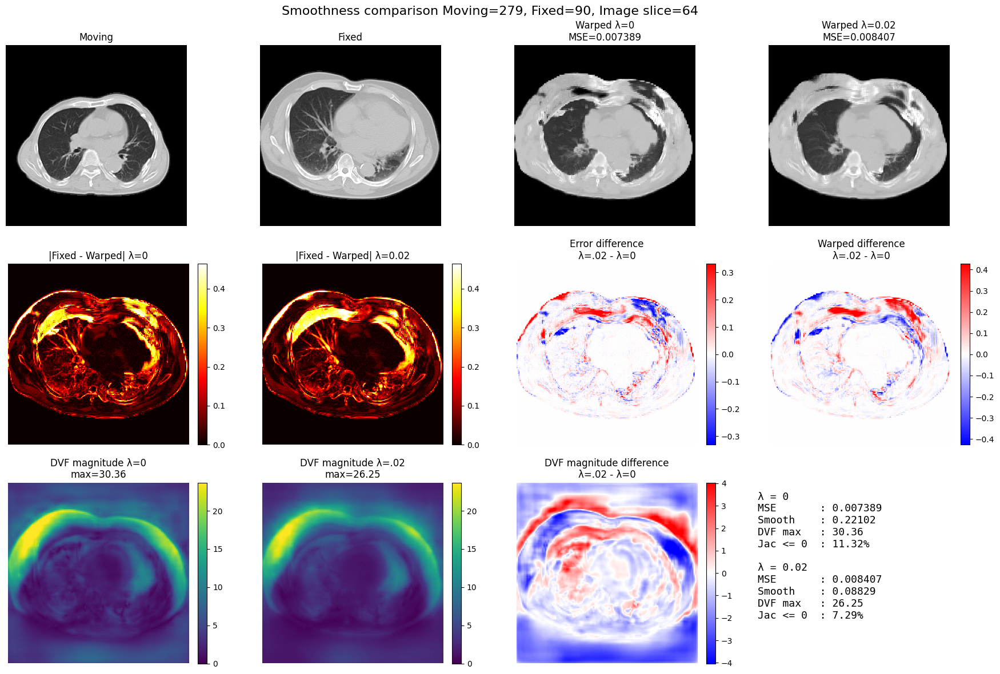

In [26]:
# ======================================================================
# λ = 0 vs λ = 0.02
# Image / Error / DVF Visualization
#
# 比較:
#   ・Moving
#   ・Fixed
#   ・Warped (λ=0)
#   ・Warped (λ=0.02)
#   ・|Fixed - Warped| error map
#   ・DVF magnitude
#
# 同一患者ペア・同一スライスで比較
# ======================================================================

import gc
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt


# ======================================================================
# 1. SETTINGS
# ======================================================================

MODEL_PATH_0 = Path(
    r"D:\Saito\smoothness_ablation\finetuned_smooth_0p0_final.pth"
)

MODEL_PATH_002 = Path(
    r"D:\Saito\smoothness_ablation\finetuned_smooth_0p02_final.pth"
)


# ----------------------------------------------------------------------
# 可視化する評価ペア
#
# 0 ～ 9
# ----------------------------------------------------------------------

PAIR_INDEX = 0


# ----------------------------------------------------------------------
# axial方向
#
# Noneなら中央スライス
# ----------------------------------------------------------------------

SLICE_Z = None


# ======================================================================
# 2. CHECK
# ======================================================================

required_names = [
    "wavelet_cache",
    "volumes_cpu",
    "eval_pairs",
    "nb_features",
    "synthesis_filters",
    "transformer_ablation",
    "up_sampling_3d",
    "synthesis_filter_3d",
]


missing = [
    name
    for name in required_names
    if name not in globals()
]


if missing:

    raise RuntimeError(
        "Notebook上に以下がありません:\n"
        +
        "\n".join(missing)
    )


if not MODEL_PATH_0.exists():

    raise FileNotFoundError(
        MODEL_PATH_0
    )


if not MODEL_PATH_002.exists():

    raise FileNotFoundError(
        MODEL_PATH_002
    )


# ======================================================================
# 3. MODEL LOADER
# ======================================================================

def load_visualization_model(
    model_path
):

    model = vxm.networks.VxmDense_128_256_256(
        (128, 256, 256),
        nb_features,
        int_steps=0
    )


    try:

        state = torch.load(
            model_path,
            map_location="cpu",
            weights_only=True
        )

    except TypeError:

        state = torch.load(
            model_path,
            map_location="cpu"
        )


    # checkpoint形式にも対応
    if (
        isinstance(state, dict)
        and
        "model_state_dict" in state
    ):

        state = state[
            "model_state_dict"
        ]


    model.load_state_dict(
        state,
        strict=True
    )


    model = model.to(
        device
    )


    model.eval()


    return model


# ======================================================================
# 4. LOAD MODELS
# ======================================================================

print("=" * 80)
print("LOAD MODELS")
print("=" * 80)


model_0 = load_visualization_model(
    MODEL_PATH_0
)


model_002 = load_visualization_model(
    MODEL_PATH_002
)


print(
    "λ=0    :",
    MODEL_PATH_0.name
)

print(
    "λ=0.02 :",
    MODEL_PATH_002.name
)


# ======================================================================
# 5. SELECT SAME PATIENT PAIR
# ======================================================================

moving_id, fixed_id = eval_pairs[
    PAIR_INDEX
]


print()
print("=" * 80)
print("PATIENT PAIR")
print("=" * 80)

print(
    f"Pair index : {PAIR_INDEX}"
)

print(
    f"Moving ID  : {moving_id}"
)

print(
    f"Fixed ID   : {fixed_id}"
)


# ======================================================================
# 6. PREPARE INPUT
# ======================================================================

moving_w = (
    wavelet_cache[
        moving_id:moving_id + 1
    ]
    .to(
        device=device,
        dtype=torch.float16
    )
)


fixed_w = (
    wavelet_cache[
        fixed_id:fixed_id + 1
    ]
    .to(
        device=device,
        dtype=torch.float16
    )
)


moving_image = (
    volumes_cpu[
        moving_id:moving_id + 1
    ]
    .unsqueeze(1)
    .to(
        device=device,
        dtype=torch.float32
    )
)


fixed_image = (
    volumes_cpu[
        fixed_id:fixed_id + 1
    ]
    .unsqueeze(1)
    .to(
        device=device,
        dtype=torch.float32
    )
)


# ======================================================================
# 7. FORWARD
# ======================================================================

@torch.no_grad()
def run_model_for_visualization(
    model,
    moving_w,
    fixed_w
):

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=True
    ):

        flow = model(
            moving_w,
            fixed_w
        )


        warped_coeff = transformer_ablation(
            moving_w,
            flow
        )


        up = up_sampling_3d(
            warped_coeff
        )


        warped_image, _ = synthesis_filter_3d(
            up,
            synthesis_filters
        )


    return (
        warped_image.float(),
        flow.float()
    )


warped_0, flow_0 = run_model_for_visualization(
    model_0,
    moving_w,
    fixed_w
)


warped_002, flow_002 = run_model_for_visualization(
    model_002,
    moving_w,
    fixed_w
)


# ======================================================================
# 8. METRICS
# ======================================================================

mse_0 = (
    warped_0
    -
    fixed_image
).square().mean().item()


mse_002 = (
    warped_002
    -
    fixed_image
).square().mean().item()


smooth_0 = (
    ablation_smoothness(
        flow_0
    ).item()
)


smooth_002 = (
    ablation_smoothness(
        flow_002
    ).item()
)


stats_0 = dvf_statistics(
    flow_0
)


stats_002 = dvf_statistics(
    flow_002
)


jac_0 = jacobian_negative_percent(
    flow_0
)


jac_002 = jacobian_negative_percent(
    flow_002
)


print()
print("=" * 80)
print("PAIR METRICS")
print("=" * 80)

print()
print("λ = 0")

print(
    f"  Image MSE  : {mse_0:.8f}"
)

print(
    f"  Smoothness : {smooth_0:.8f}"
)

print(
    f"  DVF mean   : {stats_0['mean']:.4f}"
)

print(
    f"  DVF P95    : {stats_0['p95']:.4f}"
)

print(
    f"  DVF P99    : {stats_0['p99']:.4f}"
)

print(
    f"  DVF max    : {stats_0['max']:.4f}"
)

print(
    f"  Jac <= 0   : {jac_0:.3f}%"
)


print()
print("λ = 0.02")

print(
    f"  Image MSE  : {mse_002:.8f}"
)

print(
    f"  Smoothness : {smooth_002:.8f}"
)

print(
    f"  DVF mean   : {stats_002['mean']:.4f}"
)

print(
    f"  DVF P95    : {stats_002['p95']:.4f}"
)

print(
    f"  DVF P99    : {stats_002['p99']:.4f}"
)

print(
    f"  DVF max    : {stats_002['max']:.4f}"
)

print(
    f"  Jac <= 0   : {jac_002:.3f}%"
)


# ======================================================================
# 9. DVF MAGNITUDE
# ======================================================================

dvf_mag_0 = torch.sqrt(
    torch.sum(
        flow_0 ** 2,
        dim=1
    )
)


dvf_mag_002 = torch.sqrt(
    torch.sum(
        flow_002 ** 2,
        dim=1
    )
)


# ======================================================================
# 10. CPU
# ======================================================================

moving_np = (
    moving_image[
        0,
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


fixed_np = (
    fixed_image[
        0,
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


warped_0_np = (
    warped_0[
        0,
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


warped_002_np = (
    warped_002[
        0,
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


dvf_0_np = (
    dvf_mag_0[
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


dvf_002_np = (
    dvf_mag_002[
        0
    ]
    .detach()
    .cpu()
    .numpy()
)


# ======================================================================
# 11. SLICE
# ======================================================================

if SLICE_Z is None:

    slice_z_image = (
        moving_np.shape[0]
        //
        2
    )

else:

    slice_z_image = int(
        SLICE_Z
    )


# DVFは64 sliceなので画像128 sliceと対応させる
slice_z_dvf = min(
    slice_z_image // 2,
    dvf_0_np.shape[0] - 1
)


print()
print(
    "Image slice:",
    slice_z_image
)

print(
    "DVF slice  :",
    slice_z_dvf
)


# ======================================================================
# 12. IMAGE SLICES
# ======================================================================

moving_slice = moving_np[
    slice_z_image
]


fixed_slice = fixed_np[
    slice_z_image
]


warped_0_slice = warped_0_np[
    slice_z_image
]


warped_002_slice = warped_002_np[
    slice_z_image
]


error_0 = np.abs(
    fixed_slice
    -
    warped_0_slice
)


error_002 = np.abs(
    fixed_slice
    -
    warped_002_slice
)


dvf_slice_0 = dvf_0_np[
    slice_z_dvf
]


dvf_slice_002 = dvf_002_np[
    slice_z_dvf
]


# ======================================================================
# 13. COMMON DISPLAY RANGE
# ======================================================================

image_vmin = min(
    np.percentile(
        moving_slice,
        1
    ),
    np.percentile(
        fixed_slice,
        1
    ),
)


image_vmax = max(
    np.percentile(
        moving_slice,
        99
    ),
    np.percentile(
        fixed_slice,
        99
    ),
)


error_vmax = max(
    np.percentile(
        error_0,
        99
    ),
    np.percentile(
        error_002,
        99
    ),
)


dvf_vmax = max(
    np.percentile(
        dvf_slice_0,
        99
    ),
    np.percentile(
        dvf_slice_002,
        99
    ),
)


# ======================================================================
# 14. VISUALIZATION
# ======================================================================

fig = plt.figure(
    figsize=(
        18,
        12
    )
)


# ----------------------------------------------------------------------
# Moving
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    1
)

im = ax.imshow(
    moving_slice,
    cmap="gray",
    vmin=image_vmin,
    vmax=image_vmax
)

ax.set_title(
    "Moving"
)

ax.axis(
    "off"
)


# ----------------------------------------------------------------------
# Fixed
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    2
)

ax.imshow(
    fixed_slice,
    cmap="gray",
    vmin=image_vmin,
    vmax=image_vmax
)

ax.set_title(
    "Fixed"
)

ax.axis(
    "off"
)


# ----------------------------------------------------------------------
# λ=0 warped
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    3
)

ax.imshow(
    warped_0_slice,
    cmap="gray",
    vmin=image_vmin,
    vmax=image_vmax
)

ax.set_title(
    f"Warped λ=0\nMSE={mse_0:.6f}"
)

ax.axis(
    "off"
)


# ----------------------------------------------------------------------
# λ=.02 warped
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    4
)

ax.imshow(
    warped_002_slice,
    cmap="gray",
    vmin=image_vmin,
    vmax=image_vmax
)

ax.set_title(
    f"Warped λ=0.02\nMSE={mse_002:.6f}"
)

ax.axis(
    "off"
)


# ----------------------------------------------------------------------
# λ=0 error
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    5
)

im_error_0 = ax.imshow(
    error_0,
    cmap="hot",
    vmin=0,
    vmax=error_vmax
)

ax.set_title(
    "|Fixed - Warped| λ=0"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_error_0,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# λ=.02 error
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    6
)

im_error_002 = ax.imshow(
    error_002,
    cmap="hot",
    vmin=0,
    vmax=error_vmax
)

ax.set_title(
    "|Fixed - Warped| λ=0.02"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_error_002,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# Error difference
#
# 正:
# λ=.02の方が誤差大
#
# 負:
# λ=.02の方が誤差小
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    7
)

error_difference = (
    error_002
    -
    error_0
)


error_diff_max = np.percentile(
    np.abs(
        error_difference
    ),
    99
)


im_diff = ax.imshow(
    error_difference,
    cmap="bwr",
    vmin=-error_diff_max,
    vmax=error_diff_max
)

ax.set_title(
    "Error difference\nλ=.02 - λ=0"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_diff,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# Warped difference
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    8
)

warped_difference = (
    warped_002_slice
    -
    warped_0_slice
)


warped_diff_max = np.percentile(
    np.abs(
        warped_difference
    ),
    99
)


im_warp_diff = ax.imshow(
    warped_difference,
    cmap="bwr",
    vmin=-warped_diff_max,
    vmax=warped_diff_max
)

ax.set_title(
    "Warped difference\nλ=.02 - λ=0"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_warp_diff,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# DVF λ=0
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    9
)

im_dvf0 = ax.imshow(
    dvf_slice_0,
    cmap="viridis",
    vmin=0,
    vmax=dvf_vmax
)

ax.set_title(
    f"DVF magnitude λ=0\n"
    f"max={stats_0['max']:.2f}"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_dvf0,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# DVF λ=.02
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    10
)

im_dvf002 = ax.imshow(
    dvf_slice_002,
    cmap="viridis",
    vmin=0,
    vmax=dvf_vmax
)

ax.set_title(
    f"DVF magnitude λ=.02\n"
    f"max={stats_002['max']:.2f}"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_dvf002,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# DVF difference
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    11
)

dvf_difference = (
    dvf_slice_002
    -
    dvf_slice_0
)


dvf_diff_max = np.percentile(
    np.abs(
        dvf_difference
    ),
    99
)


im_dvf_diff = ax.imshow(
    dvf_difference,
    cmap="bwr",
    vmin=-dvf_diff_max,
    vmax=dvf_diff_max
)

ax.set_title(
    "DVF magnitude difference\nλ=.02 - λ=0"
)

ax.axis(
    "off"
)

plt.colorbar(
    im_dvf_diff,
    ax=ax,
    fraction=0.046,
    pad=0.04
)


# ----------------------------------------------------------------------
# Summary
# ----------------------------------------------------------------------

ax = plt.subplot(
    3,
    4,
    12
)

ax.axis(
    "off"
)


summary_text = (
    "λ = 0\n"
    f"MSE       : {mse_0:.6f}\n"
    f"Smooth    : {smooth_0:.5f}\n"
    f"DVF max   : {stats_0['max']:.2f}\n"
    f"Jac <= 0  : {jac_0:.2f}%\n"
    "\n"
    "λ = 0.02\n"
    f"MSE       : {mse_002:.6f}\n"
    f"Smooth    : {smooth_002:.5f}\n"
    f"DVF max   : {stats_002['max']:.2f}\n"
    f"Jac <= 0  : {jac_002:.2f}%"
)


ax.text(
    0.05,
    0.95,
    summary_text,
    va="top",
    ha="left",
    fontsize=13,
    family="monospace"
)


plt.suptitle(
    (
        f"Smoothness comparison "
        f"Moving={moving_id}, Fixed={fixed_id}, "
        f"Image slice={slice_z_image}"
    ),
    fontsize=16
)


plt.tight_layout()

plt.show()


# ======================================================================
# 15. CLEANUP
# ======================================================================

del model_0
del model_002

gc.collect()

torch.cuda.empty_cache()

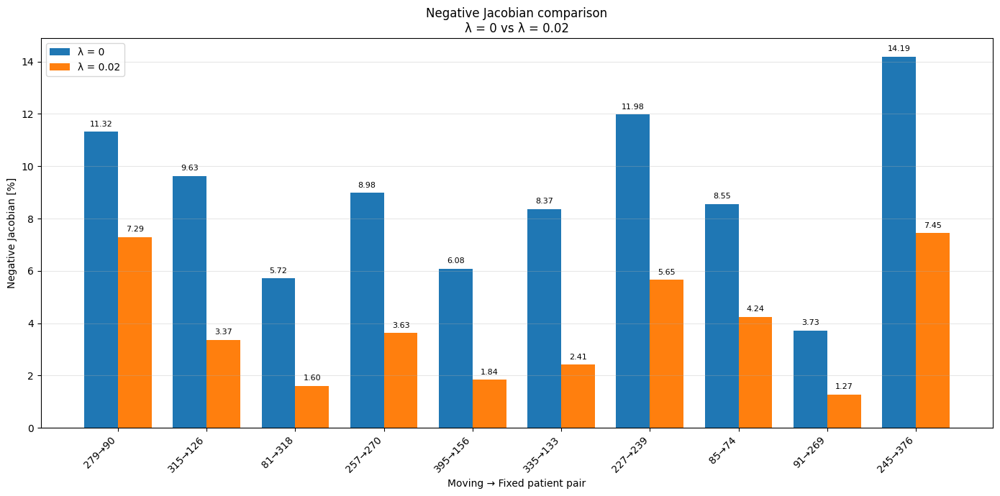

Saved: D:\Saito\smoothness_ablation\jacobian_10pairs_lambda0_vs_lambda002.png

SUMMARY
Jacobian improved: 10 / 10 pairs
λ=0 mean    : 8.856%
λ=0.02 mean : 3.877%
Reduction    : 56.22%


In [28]:
# ======================================================================
# λ=0 vs λ=0.02
# 10ペアの Negative Jacobian [%] 比較
# ======================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ======================================================================
# 1. LOAD
# ======================================================================

CSV_PATH = Path(
    r"D:\Saito\smoothness_ablation\lambda0_vs_lambda002_pairwise.csv"
)

df = pd.read_csv(
    CSV_PATH
)


# ======================================================================
# 2. LABEL
# ======================================================================

pair_labels = [
    f"{int(row.moving_id)}→{int(row.fixed_id)}"
    for _, row in df.iterrows()
]


jac_0 = df[
    "jac_lambda0"
].to_numpy()

jac_002 = df[
    "jac_lambda002"
].to_numpy()


# ======================================================================
# 3. BAR GRAPH
# ======================================================================

x = np.arange(
    len(df)
)

width = 0.38


fig, ax = plt.subplots(
    figsize=(14, 7)
)


bars0 = ax.bar(
    x - width / 2,
    jac_0,
    width,
    label="λ = 0"
)


bars002 = ax.bar(
    x + width / 2,
    jac_002,
    width,
    label="λ = 0.02"
)


# ======================================================================
# 4. VALUE LABEL
# ======================================================================

for bar in bars0:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.15,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


for bar in bars002:

    height = bar.get_height()

    ax.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.15,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=8
    )


# ======================================================================
# 5. DISPLAY
# ======================================================================

ax.set_xlabel(
    "Moving → Fixed patient pair"
)

ax.set_ylabel(
    "Negative Jacobian [%]"
)

ax.set_title(
    "Negative Jacobian comparison\n"
    "λ = 0 vs λ = 0.02"
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    pair_labels,
    rotation=45,
    ha="right"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


# ======================================================================
# 6. SAVE
# ======================================================================

SAVE_PATH = Path(
    r"D:\Saito\smoothness_ablation\jacobian_10pairs_lambda0_vs_lambda002.png"
)

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


print(
    "Saved:",
    SAVE_PATH
)


# ======================================================================
# 7. SUMMARY
# ======================================================================

improved = (
    jac_002
    <
    jac_0
)

print()
print("=" * 70)
print("SUMMARY")
print("=" * 70)

print(
    f"Jacobian improved: "
    f"{improved.sum()} / {len(improved)} pairs"
)

print(
    f"λ=0 mean    : "
    f"{jac_0.mean():.3f}%"
)

print(
    f"λ=0.02 mean : "
    f"{jac_002.mean():.3f}%"
)

print(
    f"Reduction    : "
    f"{(1 - jac_002.mean() / jac_0.mean()) * 100:.2f}%"
)

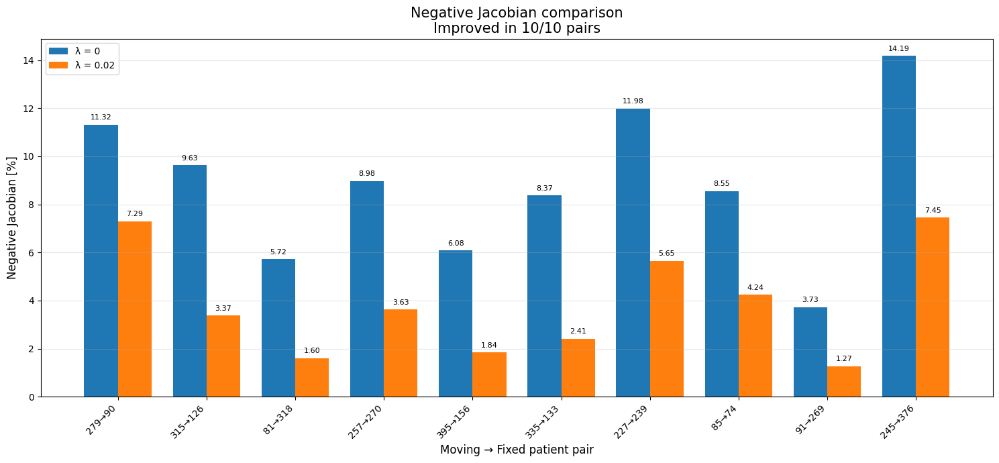


JACOBIAN SUMMARY
Improved pairs : 10/10
Improvement rate: 100.0%
λ=0 mean       : 8.8557%
λ=0.02 mean    : 3.8767%
Reduction       : 56.22%

Saved: D:\Saito\smoothness_ablation\jacobian_10pairs_lambda0_vs_lambda002.png


In [29]:
# ======================================================================
# CELL 1
# λ=0 vs λ=0.02
# 10ペアの Negative Jacobian 比較グラフ
# ======================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# ======================================================================
# SETTINGS
# ======================================================================

CSV_PATH = Path(
    r"D:\Saito\smoothness_ablation\lambda0_vs_lambda002_pairwise.csv"
)

SAVE_PATH = Path(
    r"D:\Saito\smoothness_ablation\jacobian_10pairs_lambda0_vs_lambda002.png"
)


# ======================================================================
# LOAD CSV
# ======================================================================

if not CSV_PATH.exists():
    raise FileNotFoundError(
        f"CSVが見つかりません:\n{CSV_PATH}"
    )

df = pd.read_csv(
    CSV_PATH
)


# ======================================================================
# DATA
# ======================================================================

pair_labels = [
    f"{int(row.moving_id)}→{int(row.fixed_id)}"
    for _, row in df.iterrows()
]

jac_0 = df[
    "jac_lambda0"
].to_numpy()

jac_002 = df[
    "jac_lambda002"
].to_numpy()


# ======================================================================
# IMPROVEMENT CHECK
# ======================================================================

improved = (
    jac_002
    <
    jac_0
)

n_improved = int(
    improved.sum()
)

n_pairs = len(
    improved
)


# ======================================================================
# BAR GRAPH
# ======================================================================

x = np.arange(
    n_pairs
)

width = 0.38


fig, ax = plt.subplots(
    figsize=(15, 7)
)


bars_0 = ax.bar(
    x - width / 2,
    jac_0,
    width,
    label="λ = 0"
)


bars_002 = ax.bar(
    x + width / 2,
    jac_002,
    width,
    label="λ = 0.02"
)


# ======================================================================
# VALUE LABELS
# ======================================================================

for bar in bars_0:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        height + 0.15,

        f"{height:.2f}",

        ha="center",
        va="bottom",
        fontsize=8
    )


for bar in bars_002:

    height = bar.get_height()

    ax.text(
        bar.get_x()
        +
        bar.get_width() / 2,

        height + 0.15,

        f"{height:.2f}",

        ha="center",
        va="bottom",
        fontsize=8
    )


# ======================================================================
# GRAPH SETTINGS
# ======================================================================

ax.set_xlabel(
    "Moving → Fixed patient pair",
    fontsize=12
)

ax.set_ylabel(
    "Negative Jacobian [%]",
    fontsize=12
)

ax.set_title(
    (
        "Negative Jacobian comparison\n"
        f"Improved in {n_improved}/{n_pairs} pairs"
    ),
    fontsize=15
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    pair_labels,
    rotation=45,
    ha="right"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.3
)


plt.tight_layout()


# ======================================================================
# SAVE
# ======================================================================

plt.savefig(
    SAVE_PATH,
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# ======================================================================
# SUMMARY
# ======================================================================

mean_0 = jac_0.mean()

mean_002 = jac_002.mean()

reduction = (
    1.0
    -
    mean_002 / mean_0
) * 100.0


print()
print("=" * 80)
print("JACOBIAN SUMMARY")
print("=" * 80)

print(
    f"Improved pairs : "
    f"{n_improved}/{n_pairs}"
)

print(
    f"Improvement rate: "
    f"{n_improved / n_pairs * 100:.1f}%"
)

print(
    f"λ=0 mean       : "
    f"{mean_0:.4f}%"
)

print(
    f"λ=0.02 mean    : "
    f"{mean_002:.4f}%"
)

print(
    f"Reduction       : "
    f"{reduction:.2f}%"
)

print()
print(
    "Saved:",
    SAVE_PATH
)

In [30]:
# ======================================================================
# CELL 2
# Differentiable Jacobian Folding Loss
#
# flow shape:
#   [B, 3, D, H, W]
#
# 想定:
#   channel 0 = z
#   channel 1 = y
#   channel 2 = x
# ======================================================================

import torch
import torch.nn.functional as F


def jacobian_folding_loss(
    flow,
    margin=0.0
):

    # ==================================================================
    # float32
    # ==================================================================

    f = flow.float()


    uz = f[
        :,
        0
    ]

    uy = f[
        :,
        1
    ]

    ux = f[
        :,
        2
    ]


    # ==================================================================
    # Forward difference
    # ==================================================================

    duz_dz = (
        uz[:, 1:, :-1, :-1]
        -
        uz[:, :-1, :-1, :-1]
    )

    duz_dy = (
        uz[:, :-1, 1:, :-1]
        -
        uz[:, :-1, :-1, :-1]
    )

    duz_dx = (
        uz[:, :-1, :-1, 1:]
        -
        uz[:, :-1, :-1, :-1]
    )


    duy_dz = (
        uy[:, 1:, :-1, :-1]
        -
        uy[:, :-1, :-1, :-1]
    )

    duy_dy = (
        uy[:, :-1, 1:, :-1]
        -
        uy[:, :-1, :-1, :-1]
    )

    duy_dx = (
        uy[:, :-1, :-1, 1:]
        -
        uy[:, :-1, :-1, :-1]
    )


    dux_dz = (
        ux[:, 1:, :-1, :-1]
        -
        ux[:, :-1, :-1, :-1]
    )

    dux_dy = (
        ux[:, :-1, 1:, :-1]
        -
        ux[:, :-1, :-1, :-1]
    )

    dux_dx = (
        ux[:, :-1, :-1, 1:]
        -
        ux[:, :-1, :-1, :-1]
    )


    # ==================================================================
    # J = I + ∇u
    # ==================================================================

    J00 = 1.0 + duz_dz
    J01 = duz_dy
    J02 = duz_dx

    J10 = duy_dz
    J11 = 1.0 + duy_dy
    J12 = duy_dx

    J20 = dux_dz
    J21 = dux_dy
    J22 = 1.0 + dux_dx


    # ==================================================================
    # determinant
    # ==================================================================

    detJ = (

        J00
        *
        (
            J11 * J22
            -
            J12 * J21
        )

        -

        J01
        *
        (
            J10 * J22
            -
            J12 * J20
        )

        +

        J02
        *
        (
            J10 * J21
            -
            J11 * J20
        )
    )


    # ==================================================================
    # Folding penalty
    #
    # margin=0
    #   detJ < 0 のみ罰する
    #
    # margin=0.1
    #   detJ < 0.1 も少し罰する
    # ==================================================================

    penalty = F.relu(
        margin
        -
        detJ
    )


    loss = (
        penalty
        .square()
        .mean()
    )


    return loss

In [35]:
# ======================================================================
# FINAL 400-PATIENT / 30,000-EPOCH FINE-TUNING
#
# Conditions
#
# A) MSE
#    L = MSE
#
# B) MSE + Smoothness
#    L = MSE + 0.02 * Smoothness
#
# C) MSE + Smoothness + Jacobian
#    L = MSE + 0.02 * Smoothness + 0.001 * Jacobian
#
#
# IMPORTANT
#
# ・400症例すべてをFine-tuningに使用
# ・3条件とも同じ事前学習モデルから開始
# ・3条件とも同じ患者ペア順
# ・3条件とも30,000 epoch
# ・Test101はこのセルでは一切使用しない
# ・30,000 epoch終了時の3モデルをTest101にぶつける
# ======================================================================


from tqdm.notebook import tqdm

import gc
import os
import random
import time
from pathlib import Path

import numpy as np
import pandas as pd

import torch


# ======================================================================
# 1. SETTINGS
# ======================================================================

PRETRAINED_PATH = Path(
    r"D:\Saito\model_DVF_pretrain_final.pth"
)

OUTPUT_DIR = Path(
    r"D:\Saito\final_finetune_400_30000"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ----------------------------------------------------------------------
# Fine-tuning
# ----------------------------------------------------------------------

FINETUNE_EPOCHS = 30000

BATCH_SIZE = 2

LEARNING_RATE = 1e-6

GRAD_CLIP = 1.0


# ----------------------------------------------------------------------
# Regularization
# ----------------------------------------------------------------------

SMOOTHNESS_WEIGHT = 0.02

JACOBIAN_WEIGHT = 0.001


# ----------------------------------------------------------------------
# Logging
# ----------------------------------------------------------------------

PRINT_EVERY = 100

CHECKPOINT_EVERY = 1000


# ----------------------------------------------------------------------
# Seed
# ----------------------------------------------------------------------

SEED = 42


# ======================================================================
# 2. RANDOM SEED
# ======================================================================

random.seed(SEED)

np.random.seed(SEED)

torch.manual_seed(SEED)


if torch.cuda.is_available():

    torch.cuda.manual_seed_all(
        SEED
    )


# ======================================================================
# 3. GPU SETTINGS
# ======================================================================

device = torch.device(

    "cuda"

    if torch.cuda.is_available()

    else "cpu"
)


torch.backends.cudnn.benchmark = True


if hasattr(
    torch.backends.cuda.matmul,
    "allow_tf32"
):

    torch.backends.cuda.matmul.allow_tf32 = True


if hasattr(
    torch.backends.cudnn,
    "allow_tf32"
):

    torch.backends.cudnn.allow_tf32 = True


print("=" * 100)
print("DEVICE")
print("=" * 100)

print(
    "Device:",
    device
)


if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )


# ======================================================================
# 4. REQUIRED OBJECT CHECK
#
# これらは今までのNotebookセルで定義済みであることを想定
# ======================================================================

required_names = [

    "wavelet_cache",

    "volumes_cpu",

    "nb_features",

    "synthesis_filters",

    "transformer_ablation",

    "up_sampling_3d",

    "synthesis_filter_3d",

    "ablation_smoothness",

    "jacobian_folding_loss",

    "vxm",
]


missing = [

    name

    for name in required_names

    if name not in globals()
]


if missing:

    raise RuntimeError(

        "以下の変数・関数がNotebook上にありません:\n\n"

        +

        "\n".join(missing)
    )


# ======================================================================
# 5. DATA CHECK
# ======================================================================

N_PATIENTS = len(
    volumes_cpu
)


print()
print("=" * 100)
print("DATASET")
print("=" * 100)

print(
    "Number of patients:",
    N_PATIENTS
)


if N_PATIENTS != 400:

    raise ValueError(

        f"400症例を想定していますが、"
        f"現在 {N_PATIENTS} 症例です。"
    )


if len(wavelet_cache) != 400:

    raise ValueError(

        "wavelet_cache が400症例ではありません。"
    )


# ======================================================================
# 6. ALL 400 PATIENT IDS
# ======================================================================

train_ids = np.arange(
    N_PATIENTS
)


print()
print(
    "Fine-tuning patients:",
    len(train_ids)
)


# ======================================================================
# 7. CREATE FIXED TRAINING PAIRS
#
# 30,000 epoch × batch size 2
#
# 3条件すべて完全に同じMoving / Fixedペアを使用
# ======================================================================

rng_pairs = np.random.default_rng(
    SEED + 200
)


train_pairs = []


for epoch in range(
    FINETUNE_EPOCHS
):

    moving_ids = rng_pairs.choice(

        train_ids,

        size=BATCH_SIZE,

        replace=True
    )


    fixed_ids = []


    for moving_id in moving_ids:

        fixed_id = rng_pairs.choice(
            train_ids
        )


        while fixed_id == moving_id:

            fixed_id = rng_pairs.choice(
                train_ids
            )


        fixed_ids.append(
            int(fixed_id)
        )


    train_pairs.append(

        (

            [
                int(x)

                for x in moving_ids
            ],

            fixed_ids
        )
    )


print()
print("=" * 100)
print("FIXED TRAINING PAIRS")
print("=" * 100)

print(
    "Epochs:",
    len(train_pairs)
)


print(
    "Batch size:",
    BATCH_SIZE
)


print()

for i in range(5):

    print(
        f"Epoch {i+1}:",
        train_pairs[i]
    )


# ======================================================================
# 8. SAVE ALL TRAINING PAIRS
#
# 再現性のためCSV保存
# ======================================================================

pair_rows = []


for epoch_index, (
    moving_ids,
    fixed_ids
) in enumerate(
    train_pairs,
    start=1
):

    for batch_position in range(
        BATCH_SIZE
    ):

        pair_rows.append({

            "epoch":
                epoch_index,

            "batch_position":
                batch_position,

            "moving_id":
                moving_ids[
                    batch_position
                ],

            "fixed_id":
                fixed_ids[
                    batch_position
                ],
        })


PAIR_CSV = (

    OUTPUT_DIR

    /

    "fixed_training_pairs_30000epochs.csv"
)


pd.DataFrame(
    pair_rows
).to_csv(
    PAIR_CSV,
    index=False
)


print()
print(
    "Saved training pairs:"
)

print(
    PAIR_CSV
)


# ======================================================================
# 9. LOAD PRETRAINED WEIGHTS
# ======================================================================

if not PRETRAINED_PATH.exists():

    raise FileNotFoundError(
        PRETRAINED_PATH
    )


try:

    pretrained_state = torch.load(

        PRETRAINED_PATH,

        map_location="cpu",

        weights_only=True
    )

except TypeError:

    pretrained_state = torch.load(

        PRETRAINED_PATH,

        map_location="cpu"
    )


# ----------------------------------------------------------------------
# checkpoint形式への対応
# ----------------------------------------------------------------------

if (

    isinstance(
        pretrained_state,
        dict
    )

    and

    "model_state_dict"
    in pretrained_state
):

    pretrained_state = pretrained_state[
        "model_state_dict"
    ]


print()
print("=" * 100)
print("PRETRAINED WEIGHTS")
print("=" * 100)

print(
    PRETRAINED_PATH
)


# ======================================================================
# 10. MODEL FACTORY
#
# 条件ごとに完全に新しく作り直す
# ======================================================================

def create_fresh_model():

    model = vxm.networks.VxmDense_128_256_256(

        (128, 256, 256),

        nb_features,

        int_steps=0
    )


    model.load_state_dict(

        pretrained_state,

        strict=True
    )


    model = model.to(
        device
    )


    return model


# ======================================================================
# 11. LOSS CONDITIONS
# ======================================================================

conditions = [

    # ------------------------------------------------------------------
    # A
    # ------------------------------------------------------------------

    {
        "name":
            "MSE",

        "smooth_weight":
            0.0,

        "jacobian_weight":
            0.0,
    },


    # ------------------------------------------------------------------
    # B
    # ------------------------------------------------------------------

    {
        "name":
            "MSE_Smooth",

        "smooth_weight":
            0.02,

        "jacobian_weight":
            0.0,
    },


    # ------------------------------------------------------------------
    # C
    # ------------------------------------------------------------------

    {
        "name":
            "MSE_Smooth_Jac",

        "smooth_weight":
            0.02,

        "jacobian_weight":
            0.001,
    },
]


print()
print("=" * 100)
print("FINAL CONDITIONS")
print("=" * 100)


for condition in conditions:

    print(
        condition
    )


# ======================================================================
# 12. TRAINING SUMMARY
# ======================================================================

final_summary = []


# ======================================================================
# 13. RUN ALL CONDITIONS
# ======================================================================

for condition in conditions:

    condition_name = condition[
        "name"
    ]


    smooth_weight = condition[
        "smooth_weight"
    ]


    jacobian_weight = condition[
        "jacobian_weight"
    ]


    print()
    print()
    print("=" * 120)

    print(
        f"START: {condition_name}"
    )

    print("=" * 120)


    print(
        f"Epochs           : "
        f"{FINETUNE_EPOCHS}"
    )

    print(
        f"Batch size       : "
        f"{BATCH_SIZE}"
    )

    print(
        f"Learning rate    : "
        f"{LEARNING_RATE}"
    )

    print(
        f"Smooth λ         : "
        f"{smooth_weight}"
    )

    print(
        f"Jacobian γ       : "
        f"{jacobian_weight}"
    )


    # ==================================================================
    # 14. RESET RANDOM SEED
    #
    # 条件間のランダム差をできるだけ抑える
    # ==================================================================

    random.seed(SEED)

    np.random.seed(SEED)

    torch.manual_seed(SEED)


    if torch.cuda.is_available():

        torch.cuda.manual_seed_all(
            SEED
        )


    # ==================================================================
    # 15. FRESH PRETRAINED MODEL
    # ==================================================================

    model = create_fresh_model()


    # ==================================================================
    # 16. OPTIMIZER
    # ==================================================================

    optimizer = torch.optim.Adam(

        model.parameters(),

        lr=LEARNING_RATE
    )


    # ==================================================================
    # 17. AMP GRAD SCALER
    # ==================================================================

    scaler = torch.cuda.amp.GradScaler(

        enabled=torch.cuda.is_available()
    )


    # ==================================================================
    # 18. HISTORY
    # ==================================================================

    history = []


    start_time = time.time()


    # ==================================================================
    # 19. TRAINING LOOP
    # ==================================================================

    for epoch in tqdm(

        range(
            1,
            FINETUNE_EPOCHS + 1
        ),

        desc=condition_name
    ):

        model.train()


        # --------------------------------------------------------------
        # Fixed pair
        # --------------------------------------------------------------

        moving_ids, fixed_ids = train_pairs[
            epoch - 1
        ]


        # --------------------------------------------------------------
        # Moving wavelet coefficients
        # --------------------------------------------------------------

        moving_w = (

            wavelet_cache[
                moving_ids
            ]

            .to(

                device=device,

                dtype=torch.float16,

                non_blocking=True
            )
        )


        # --------------------------------------------------------------
        # Fixed wavelet coefficients
        # --------------------------------------------------------------

        fixed_w = (

            wavelet_cache[
                fixed_ids
            ]

            .to(

                device=device,

                dtype=torch.float16,

                non_blocking=True
            )
        )


        # --------------------------------------------------------------
        # Fixed original CT
        # --------------------------------------------------------------

        fixed_image = (

            volumes_cpu[
                fixed_ids
            ]

            .unsqueeze(1)

            .to(

                device=device,

                dtype=torch.float32,

                non_blocking=True
            )
        )


        # --------------------------------------------------------------
        # Zero grad
        # --------------------------------------------------------------

        optimizer.zero_grad(
            set_to_none=True
        )


        # --------------------------------------------------------------
        # Forward
        # --------------------------------------------------------------

        with torch.autocast(

            device_type="cuda",

            dtype=torch.float16,

            enabled=torch.cuda.is_available()
        ):

            # ----------------------------------------------------------
            # VoxelMorph
            # ----------------------------------------------------------

            flow = model(

                moving_w,

                fixed_w
            )


            # ----------------------------------------------------------
            # Warp wavelet coefficients
            # ----------------------------------------------------------

            warped_coeff = transformer_ablation(

                moving_w,

                flow
            )


            # ----------------------------------------------------------
            # Upsampling
            # ----------------------------------------------------------

            up = up_sampling_3d(
                warped_coeff
            )


            # ----------------------------------------------------------
            # Synthesis filtering
            # ----------------------------------------------------------

            warped_image, _ = synthesis_filter_3d(

                up,

                synthesis_filters
            )


            # ==========================================================
            # IMAGE MSE
            # ==========================================================

            loss_mse = (

                warped_image.float()

                -

                fixed_image

            ).square().mean()


            # ==========================================================
            # SMOOTHNESS
            # ==========================================================

            loss_smooth = ablation_smoothness(
                flow
            )


            # ==========================================================
            # JACOBIAN FOLDING
            # ==========================================================

            loss_jacobian = jacobian_folding_loss(

                flow,

                margin=0.0
            )


            # ==========================================================
            # TOTAL LOSS
            # ==========================================================

            loss_total = (

                loss_mse

                +

                smooth_weight
                *
                loss_smooth

                +

                jacobian_weight
                *
                loss_jacobian
            )


        # --------------------------------------------------------------
        # Backward
        # --------------------------------------------------------------

        scaler.scale(
            loss_total
        ).backward()


        # --------------------------------------------------------------
        # Gradient clipping
        # --------------------------------------------------------------

        scaler.unscale_(
            optimizer
        )


        torch.nn.utils.clip_grad_norm_(

            model.parameters(),

            GRAD_CLIP
        )


        # --------------------------------------------------------------
        # Optimizer step
        # --------------------------------------------------------------

        scaler.step(
            optimizer
        )


        scaler.update()


        # ==============================================================
        # LOG
        # ==============================================================

        if (

            epoch == 1

            or

            epoch % PRINT_EVERY == 0

            or

            epoch == FINETUNE_EPOCHS
        ):

            current = {

                "epoch":
                    epoch,

                "total_loss":
                    float(
                        loss_total.detach().item()
                    ),

                "mse":
                    float(
                        loss_mse.detach().item()
                    ),

                "smoothness":
                    float(
                        loss_smooth.detach().item()
                    ),

                "jacobian_loss":
                    float(
                        loss_jacobian.detach().item()
                    ),
            }


            history.append(
                current
            )


            print()
            print(
                f"Epoch "
                f"{epoch:05d}/{FINETUNE_EPOCHS}"
            )

            print(
                f"Total loss : "
                f"{current['total_loss']:.8f}"
            )

            print(
                f"MSE        : "
                f"{current['mse']:.8f}"
            )

            print(
                f"Smooth     : "
                f"{current['smoothness']:.8f}"
            )

            print(
                f"Jac loss   : "
                f"{current['jacobian_loss']:.8f}"
            )


        # ==============================================================
        # CHECKPOINT
        # ==============================================================

        if (
            epoch % CHECKPOINT_EVERY == 0
        ):

            checkpoint_path = (

                OUTPUT_DIR

                /

                f"{condition_name}"
                f"_epoch_{epoch:05d}.pth"
            )


            torch.save(

                {

                    "condition":
                        condition_name,

                    "epoch":
                        epoch,

                    "model_state_dict":
                        model.state_dict(),

                    "optimizer_state_dict":
                        optimizer.state_dict(),

                    "scaler_state_dict":
                        scaler.state_dict(),

                    "smoothness_weight":
                        smooth_weight,

                    "jacobian_weight":
                        jacobian_weight,

                    "learning_rate":
                        LEARNING_RATE,

                    "batch_size":
                        BATCH_SIZE,

                    "seed":
                        SEED,

                    "history":
                        history,
                },

                checkpoint_path
            )


            print(
                f"Checkpoint saved: "
                f"{checkpoint_path}"
            )


    # ==================================================================
    # 20. TRAINING FINISHED
    # ==================================================================

    elapsed_minutes = (

        time.time()

        -

        start_time

    ) / 60.0


    # ==================================================================
    # 21. FINAL MODEL SAVE
    # ==================================================================

    final_model_path = (

        OUTPUT_DIR

        /

        f"{condition_name}_final.pth"
    )


    torch.save(

        {

            "condition":
                condition_name,

            "epoch":
                FINETUNE_EPOCHS,

            "model_state_dict":
                model.state_dict(),

            "smoothness_weight":
                smooth_weight,

            "jacobian_weight":
                jacobian_weight,

            "learning_rate":
                LEARNING_RATE,

            "batch_size":
                BATCH_SIZE,

            "seed":
                SEED,
        },

        final_model_path
    )


    # ==================================================================
    # 22. SAVE HISTORY CSV
    # ==================================================================

    history_df = pd.DataFrame(
        history
    )


    history_csv = (

        OUTPUT_DIR

        /

        f"{condition_name}_training_history.csv"
    )


    history_df.to_csv(

        history_csv,

        index=False
    )


    # ==================================================================
    # 23. CONDITION SUMMARY
    # ==================================================================

    final_summary.append({

        "condition":
            condition_name,

        "smoothness_weight":
            smooth_weight,

        "jacobian_weight":
            jacobian_weight,

        "final_training_mse":
            float(
                loss_mse.detach().item()
            ),

        "final_training_smoothness":
            float(
                loss_smooth.detach().item()
            ),

        "final_training_jacobian_loss":
            float(
                loss_jacobian.detach().item()
            ),

        "time_minutes":
            elapsed_minutes,

        "model_path":
            str(
                final_model_path
            ),
    })


    print()
    print("=" * 120)

    print(
        f"FINISHED: {condition_name}"
    )

    print("=" * 120)


    print(
        f"Final MSE      : "
        f"{loss_mse.item():.8f}"
    )

    print(
        f"Final Smooth   : "
        f"{loss_smooth.item():.8f}"
    )

    print(
        f"Final Jac loss : "
        f"{loss_jacobian.item():.8f}"
    )

    print(
        f"Time           : "
        f"{elapsed_minutes:.2f} min"
    )

    print(
        f"Saved model    : "
        f"{final_model_path}"
    )


    # ==================================================================
    # 24. CLEAN GPU MEMORY
    # ==================================================================

    del model
    del optimizer
    del scaler

    del moving_w
    del fixed_w
    del fixed_image

    del flow
    del warped_coeff
    del up
    del warped_image

    gc.collect()


    if torch.cuda.is_available():

        torch.cuda.empty_cache()


# ======================================================================
# 25. FINAL SUMMARY
# ======================================================================

summary_df = pd.DataFrame(
    final_summary
)


SUMMARY_CSV = (

    OUTPUT_DIR

    /

    "final_400_30000_training_summary.csv"
)


summary_df.to_csv(

    SUMMARY_CSV,

    index=False
)


print()
print()
print("=" * 150)
print("FINAL 400-PATIENT / 30,000-EPOCH TRAINING SUMMARY")
print("=" * 150)


print(

    summary_df.to_string(

        index=False,

        float_format=lambda x: f"{x:.8f}"
    )
)


print()
print(
    "Saved summary:"
)

print(
    SUMMARY_CSV
)


print()
print("=" * 150)
print("FINAL MODELS FOR TEST101")
print("=" * 150)

print(
    OUTPUT_DIR
    /
    "MSE_final.pth"
)

print(
    OUTPUT_DIR
    /
    "MSE_Smooth_final.pth"
)

print(
    OUTPUT_DIR
    /
    "MSE_Smooth_Jac_final.pth"
)

DEVICE
Device: cuda
GPU: NVIDIA GeForce RTX 3090

DATASET
Number of patients: 400

Fine-tuning patients: 400

FIXED TRAINING PAIRS
Epochs: 30000
Batch size: 2

Epoch 1: ([295, 34], [175, 348])
Epoch 2: ([135, 167], [374, 49])
Epoch 3: ([201, 281], [142, 125])
Epoch 4: ([102, 147], [375, 255])
Epoch 5: ([14, 281], [385, 330])

Saved training pairs:
D:\Saito\final_finetune_400_30000\fixed_training_pairs_30000epochs.csv

PRETRAINED WEIGHTS
D:\Saito\model_DVF_pretrain_final.pth

FINAL CONDITIONS
{'name': 'MSE', 'smooth_weight': 0.0, 'jacobian_weight': 0.0}
{'name': 'MSE_Smooth', 'smooth_weight': 0.02, 'jacobian_weight': 0.0}
{'name': 'MSE_Smooth_Jac', 'smooth_weight': 0.02, 'jacobian_weight': 0.001}


START: MSE
Epochs           : 30000
Batch size       : 2
Learning rate    : 1e-06
Smooth λ         : 0.0
Jacobian γ       : 0.0
[64, 128, 128]


MSE:   0%|          | 0/30000 [00:00<?, ?it/s]


Epoch 00001/30000
Total loss : 0.02610153
MSE        : 0.02610153
Smooth     : 0.04380339
Jac loss   : 0.00131576

Epoch 00100/30000
Total loss : 0.03451787
MSE        : 0.03451787
Smooth     : 0.06823595
Jac loss   : 0.00386392

Epoch 00200/30000
Total loss : 0.01268390
MSE        : 0.01268390
Smooth     : 0.06756227
Jac loss   : 0.00489732

Epoch 00300/30000
Total loss : 0.00832482
MSE        : 0.00832482
Smooth     : 0.07634372
Jac loss   : 0.01090672

Epoch 00400/30000
Total loss : 0.00442249
MSE        : 0.00442249
Smooth     : 0.06734745
Jac loss   : 0.00532858

Epoch 00500/30000
Total loss : 0.01034150
MSE        : 0.01034150
Smooth     : 0.08961485
Jac loss   : 0.01360955

Epoch 00600/30000
Total loss : 0.01520681
MSE        : 0.01520681
Smooth     : 0.12503420
Jac loss   : 0.02667786

Epoch 00700/30000
Total loss : 0.00567257
MSE        : 0.00567257
Smooth     : 0.08642246
Jac loss   : 0.01084085

Epoch 00800/30000
Total loss : 0.00874294
MSE        : 0.00874294
Smooth     : 

MSE_Smooth:   0%|          | 0/30000 [00:00<?, ?it/s]


Epoch 00001/30000
Total loss : 0.02697760
MSE        : 0.02610153
Smooth     : 0.04380339
Jac loss   : 0.00131576

Epoch 00100/30000
Total loss : 0.03590318
MSE        : 0.03466572
Smooth     : 0.06187306
Jac loss   : 0.00295250

Epoch 00200/30000
Total loss : 0.01395420
MSE        : 0.01283334
Smooth     : 0.05604313
Jac loss   : 0.00287052

Epoch 00300/30000
Total loss : 0.00958658
MSE        : 0.00840744
Smooth     : 0.05895682
Jac loss   : 0.00600871

Epoch 00400/30000
Total loss : 0.00549266
MSE        : 0.00449258
Smooth     : 0.05000420
Jac loss   : 0.00271897

Epoch 00500/30000
Total loss : 0.01224091
MSE        : 0.01098596
Smooth     : 0.06274782
Jac loss   : 0.00642128

Epoch 00600/30000
Total loss : 0.01769391
MSE        : 0.01598204
Smooth     : 0.08559361
Jac loss   : 0.01105070

Epoch 00700/30000
Total loss : 0.00708998
MSE        : 0.00597274
Smooth     : 0.05586193
Jac loss   : 0.00443628

Epoch 00800/30000
Total loss : 0.01066537
MSE        : 0.00925308
Smooth     : 

MSE_Smooth_Jac:   0%|          | 0/30000 [00:00<?, ?it/s]


Epoch 00001/30000
Total loss : 0.02697892
MSE        : 0.02610153
Smooth     : 0.04380339
Jac loss   : 0.00131576

Epoch 00100/30000
Total loss : 0.03590651
MSE        : 0.03466684
Smooth     : 0.06183632
Jac loss   : 0.00294530

Epoch 00200/30000
Total loss : 0.01395706
MSE        : 0.01283476
Smooth     : 0.05597239
Jac loss   : 0.00285612

Epoch 00300/30000
Total loss : 0.00959185
MSE        : 0.00840915
Smooth     : 0.05883660
Jac loss   : 0.00596752

Epoch 00400/30000
Total loss : 0.00549473
MSE        : 0.00449438
Smooth     : 0.04988266
Jac loss   : 0.00269616

Epoch 00500/30000
Total loss : 0.01224986
MSE        : 0.01099197
Smooth     : 0.06257679
Jac loss   : 0.00635714

Epoch 00600/30000
Total loss : 0.01770961
MSE        : 0.01599249
Smooth     : 0.08531012
Jac loss   : 0.01092067

Epoch 00700/30000
Total loss : 0.00709333
MSE        : 0.00597572
Smooth     : 0.05566214
Jac loss   : 0.00436953

Epoch 00800/30000
Total loss : 0.01068007
MSE        : 0.00926159
Smooth     : 

In [32]:
# ======================================================================
# CELL 4
# γ=0 baseline + Jacobian penalty conditions comparison
# ======================================================================

from pathlib import Path

import pandas as pd


# ======================================================================
# LOAD
# ======================================================================

RESULT_CSV = Path(
    r"D:\Saito\jacobian_ablation\jacobian_ablation_summary.csv"
)


df_jac = pd.read_csv(
    RESULT_CSV
)


# ======================================================================
# BASELINE
#
# Smoothness λ=0.02
# Jacobian γ=0
# ======================================================================

baseline = {

    "smoothness_weight":
        0.02,

    "jacobian_weight":
        0.0,

    "image_mse":
        0.00539653,

    "smoothness":
        0.05595856,

    "dvf_mean":
        3.221829,

    "dvf_p95":
        8.582615,

    "dvf_p99":
        12.194854,

    "dvf_max":
        17.023110,

    "jacobian_negative_percent":
        3.876661,

    "jacobian_loss":
        float("nan"),

    "time_minutes":
        float("nan"),
}


baseline_df = pd.DataFrame(
    [
        baseline
    ]
)


# ======================================================================
# COMBINE
# ======================================================================

comparison_df = pd.concat(
    [
        baseline_df,
        df_jac
    ],
    ignore_index=True
)


comparison_df = comparison_df.sort_values(
    "jacobian_weight"
).reset_index(
    drop=True
)


# ======================================================================
# RELATIVE TO γ=0
# ======================================================================

baseline_mse = comparison_df.loc[
    comparison_df[
        "jacobian_weight"
    ] == 0.0,
    "image_mse"
].iloc[0]


baseline_jac = comparison_df.loc[
    comparison_df[
        "jacobian_weight"
    ] == 0.0,
    "jacobian_negative_percent"
].iloc[0]


baseline_smooth = comparison_df.loc[
    comparison_df[
        "jacobian_weight"
    ] == 0.0,
    "smoothness"
].iloc[0]


baseline_dvf_max = comparison_df.loc[
    comparison_df[
        "jacobian_weight"
    ] == 0.0,
    "dvf_max"
].iloc[0]


comparison_df[
    "mse_change_percent"
] = (
    (
        comparison_df[
            "image_mse"
        ]
        /
        baseline_mse
    )
    -
    1.0
) * 100.0


comparison_df[
    "jac_change_percent"
] = (
    (
        comparison_df[
            "jacobian_negative_percent"
        ]
        /
        baseline_jac
    )
    -
    1.0
) * 100.0


comparison_df[
    "smooth_change_percent"
] = (
    (
        comparison_df[
            "smoothness"
        ]
        /
        baseline_smooth
    )
    -
    1.0
) * 100.0


comparison_df[
    "dvf_max_change_percent"
] = (
    (
        comparison_df[
            "dvf_max"
        ]
        /
        baseline_dvf_max
    )
    -
    1.0
) * 100.0


# ======================================================================
# PRINT
# ======================================================================

display_columns = [

    "jacobian_weight",

    "image_mse",

    "mse_change_percent",

    "smoothness",

    "smooth_change_percent",

    "dvf_max",

    "dvf_max_change_percent",

    "jacobian_negative_percent",

    "jac_change_percent",
]


print()
print("=" * 140)
print("SMOOTHNESS λ=0.02 + JACOBIAN PENALTY COMPARISON")
print("=" * 140)


print(
    comparison_df[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)


# ======================================================================
# BEST JACOBIAN
# ======================================================================

best_idx = comparison_df[
    "jacobian_negative_percent"
].idxmin()


best = comparison_df.loc[
    best_idx
]


print()
print("=" * 100)
print("LOWEST NEGATIVE JACOBIAN")
print("=" * 100)

print(
    f"γ          : "
    f"{best['jacobian_weight']}"
)

print(
    f"Image MSE  : "
    f"{best['image_mse']:.8f}"
)

print(
    f"Smoothness : "
    f"{best['smoothness']:.8f}"
)

print(
    f"DVF max    : "
    f"{best['dvf_max']:.4f}"
)

print(
    f"Jac <= 0   : "
    f"{best['jacobian_negative_percent']:.6f}%"
)


# ======================================================================
# SAVE
# ======================================================================

SAVE_PATH = Path(
    r"D:\Saito\jacobian_ablation\jacobian_ablation_with_baseline.csv"
)


comparison_df.to_csv(
    SAVE_PATH,
    index=False
)


print()
print(
    "Saved:",
    SAVE_PATH
)


SMOOTHNESS λ=0.02 + JACOBIAN PENALTY COMPARISON
 jacobian_weight  image_mse  mse_change_percent  smoothness  smooth_change_percent   dvf_max  dvf_max_change_percent  jacobian_negative_percent  jac_change_percent
        0.000000   0.005397            0.000000    0.055959               0.000000 17.023110                0.000000                   3.876661            0.000000
        0.001000   0.005403            0.123000    0.055527              -0.771690 16.965940               -0.335836                   3.798177           -2.024527
        0.005000   0.005424            0.503490    0.054128              -3.272167 16.800636               -1.306897                   3.540689           -8.666521
        0.010000   0.005445            0.895729    0.052872              -5.516325 16.680587               -2.012103                   3.303957          -14.773121

LOWEST NEGATIVE JACOBIAN
γ          : 0.01
Image MSE  : 0.00544487
Smoothness : 0.05287170
DVF max    : 16.6806
Jac <= 0   : 3.303

In [ ]:
# ============================================================
# Wavelet解像度のGT DVFを作成
#
# Full resolution
# (B, 3, 128, 256, 256)
#
# ↓
#
# Wavelet resolution
# (B, 3, 64, 128, 128)
#
# 解像度が各軸1/2なので変位量も /2
# ============================================================

displacement_field128 = F.interpolate(
    displacement_field,
    size=(
        64,
        128,
        128
    ),
    mode="trilinear",
    align_corners=False
) / 2.0

print(
    "displacement_field128:",
    displacement_field128.shape
)

displacement_field128: torch.Size([2, 3, 64, 128, 128])


In [ ]:
# ============================================================
# 8万epoch事前学習モデルをロード
# ============================================================

pretrained_path = "model_DVF_pretrain_final.pth"

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)

model3D.load_state_dict(
    torch.load(
        pretrained_path,
        map_location=device,
        weights_only=True
    )
)

print(
    "Loaded:",
    pretrained_path
)


# ============================================================
# ★重要
# 新しく作ったmodel3Dに対してoptimizerを作り直す
# ============================================================

optimizer = torch.optim.Adam(
    model3D.parameters(),
    lr=1e-5
)


# ============================================================
# AMP scalerも新規作成
# ============================================================

scaler = torch.cuda.amp.GradScaler(
    enabled=torch.cuda.is_available()
)


# ============================================================
# optimizerとmodel3Dが同じparameterを見ているか確認
# ============================================================

model_param_ids = {
    id(p)
    for p in model3D.parameters()
}

optimizer_param_ids = {
    id(p)
    for group in optimizer.param_groups
    for p in group["params"]
}

shared = (
    model_param_ids
    & optimizer_param_ids
)

print()
print("=" * 60)
print("MODEL / OPTIMIZER CHECK")
print("=" * 60)

print(
    "Model params     :",
    len(model_param_ids)
)

print(
    "Optimizer params :",
    len(optimizer_param_ids)
)

print(
    "Shared params    :",
    len(shared)
)

print(
    "Exact match      :",
    model_param_ids
    == optimizer_param_ids
)

print("=" * 60)

[64, 128, 128]
Loaded: model_DVF_pretrain_final.pth

MODEL / OPTIMIZER CHECK
Model params     : 58
Optimizer params : 58
Shared params    : 58
Exact match      : True


In [ ]:
# ============================================================
# Moving -> Moving'
# ============================================================

moving_images2 = transformer256(
    moving_images,
    displacement_field
)


# ============================================================
# Moving / Moving' をWavelet変換
# ============================================================

moving_analysis = analysis_filter_3d(
    moving_images,
    analysis
)

moving_images2_analysis = analysis_filter_3d(
    moving_images2,
    analysis
)


# ============================================================
# Downsampling
#
# (B,1,128,256,256)
#        ↓
# (B,8,64,128,128)
# ============================================================

moving_w = down_sampling_3d(
    moving_analysis
).to(device)

moving_images2_w = down_sampling_3d(
    moving_images2_analysis
).to(device)


# ============================================================
# VoxelMorph
# ============================================================

with torch.cuda.amp.autocast(
    enabled=torch.cuda.is_available()
):

    Vec = model3D(
        moving_w,
        moving_images2_w
    )

    # ========================================================
    # Wavelet空間でMovingを変形
    # ========================================================

    moving_warped = transformer(
        moving_w,
        Vec
    )

    # ========================================================
    # Wavelet再構成
    # ========================================================

    moving_warped_up = up_sampling_3d(
        moving_warped
    )

    transformed_image, _ = synthesis_filter_3d(
        moving_warped_up,
        synthesis_filters
    )


    # ========================================================
    # Raw Image Loss
    # ========================================================

    loss_image_raw = MSE_Loss(
        moving_images2,
        transformed_image
    )


    # ========================================================
    # Raw DVF Loss
    #
    # displacement_field128 は
    # Half resolution + /2 済み
    # ========================================================

    loss_vec_raw = MSE_Loss(
        displacement_field128,
        Vec
    )


    # ========================================================
    # Raw Smoothness Loss
    # ========================================================

    dz = (
        Vec[:, :, 1:, :, :]
        - Vec[:, :, :-1, :, :]
    )

    dy = (
        Vec[:, :, :, 1:, :]
        - Vec[:, :, :, :-1, :]
    )

    dx = (
        Vec[:, :, :, :, 1:]
        - Vec[:, :, :, :, :-1]
    )

    loss_smooth_raw = (
        (dz ** 2).mean()
        + (dy ** 2).mean()
        + (dx ** 2).mean()
    ) / 3.0


    # ========================================================
    # Weight
    # ========================================================

    loss_image = (
        100.0
        * loss_image_raw
    )

    loss_vec = (
        0.1
        * loss_vec_raw
    )

    loss_smooth = (
        0.1
        * loss_smooth_raw
    )


    # ========================================================
    # Total Loss
    # ========================================================

    loss = (
        loss_image
        + loss_vec
        + loss_smooth
    )


# ============================================================
# Backward
# ============================================================

optimizer.zero_grad(
    set_to_none=True
)

scaler.scale(
    loss
).backward()

scaler.step(
    optimizer
)

scaler.update()


# ============================================================
# Loss表示
# ============================================================

total_value = max(
    loss.detach().float().item(),
    1e-12
)

image_percent = (
    loss_image.detach().float().item()
    / total_value
    * 100.0
)

vec_percent = (
    loss_vec.detach().float().item()
    / total_value
    * 100.0
)

smooth_percent = (
    loss_smooth.detach().float().item()
    / total_value
    * 100.0
)


print("=" * 80)

print(
    f"Total Loss   : {loss.item():.8e}"
)

print(
    f"Image Loss   : {loss_image.item():.8e} "
    f"({image_percent:.2f}%)"
)

print(
    f"DVF Loss     : {loss_vec.item():.8e} "
    f"({vec_percent:.2f}%)"
)

print(
    f"Smooth Loss  : {loss_smooth.item():.8e} "
    f"({smooth_percent:.2f}%)"
)

print("-" * 80)

print(
    f"Raw Image    : {loss_image_raw.item():.8e}"
)

print(
    f"Raw DVF      : {loss_vec_raw.item():.8e}"
)

print(
    f"Raw Smooth   : {loss_smooth_raw.item():.8e}"
)

print("=" * 80)

Total Loss   : 6.61067590e-02
Image Loss   : 3.06891687e-02 (46.42%)
DVF Loss     : 3.45558114e-02 (52.27%)
Smooth Loss  : 8.61778099e-04 (1.30%)
--------------------------------------------------------------------------------
Raw Image    : 3.06891685e-04
Raw DVF      : 3.45558107e-01
Raw Smooth   : 8.61778110e-03


In [ ]:
# ============================================================
# Loss Weight
# ============================================================

IMAGE_WEIGHT = 100.0

# DVF教師との一致
beta = 0.1

# DVFの平滑性
lambda_smooth = 0.1


# ============================================================
# Smoothness Loss
#
# DVF:
# (B, 3, 64, 128, 128)
#
# 隣接voxel間の変位差を小さくする
# ============================================================

def dvf_smoothness_loss(dvf):

    # z方向
    dz = (
        dvf[:, :, 1:, :, :]
        - dvf[:, :, :-1, :, :]
    )

    # y方向
    dy = (
        dvf[:, :, :, 1:, :]
        - dvf[:, :, :, :-1, :]
    )

    # x方向
    dx = (
        dvf[:, :, :, :, 1:]
        - dvf[:, :, :, :, :-1]
    )

    loss_z = (
        dz ** 2
    ).mean()

    loss_y = (
        dy ** 2
    ).mean()

    loss_x = (
        dx ** 2
    ).mean()

    loss_smooth = (
        loss_z
        + loss_y
        + loss_x
    ) / 3.0

    return loss_smooth


# ============================================================
# Forward
# ============================================================

optimizer.zero_grad(
    set_to_none=True
)


with torch.cuda.amp.autocast(
    enabled=torch.cuda.is_available()
):

    # --------------------------------------------------------
    # VoxelMorph
    #
    # Vec:
    # (B, 3, 64, 128, 128)
    # --------------------------------------------------------

    Vec = model3D(
        moving_w,
        moving_images2_w
    )


    # --------------------------------------------------------
    # Wavelet係数をPred DVFで変形
    # --------------------------------------------------------

    moving_warped = transformer(
        moving_w,
        Vec
    )


    # --------------------------------------------------------
    # Upsampling
    # --------------------------------------------------------

    moving_warped_up = up_sampling_3d(
        moving_warped
    )


    # --------------------------------------------------------
    # Synthesis
    # --------------------------------------------------------

    transformed_image, _ = synthesis_filter_3d(
        moving_warped_up,
        synthesis_filters
    )


    # ========================================================
    # 1. Image Loss
    #
    # Moving'' と Moving' の一致
    # ========================================================

    loss_image_raw = MSE_Loss(
        moving_images2,
        transformed_image
    )


    # ========================================================
    # 2. DVF Loss
    #
    # Pred DVF と GT DVF の一致
    #
    # displacement_field128 は
    # F.interpolate(...)/2.0 済みを使用
    # ========================================================

    loss_vec_raw = MSE_Loss(
        displacement_field128,
        Vec
    )


    # ========================================================
    # 3. Smoothness Loss
    #
    # Pred DVFの隣接voxel差
    # ========================================================

    loss_smooth_raw = (
        dvf_smoothness_loss(
            Vec
        )
    )


    # ========================================================
    # Weightを掛ける
    # ========================================================

    loss_image = (
        IMAGE_WEIGHT
        * loss_image_raw
    )

    loss_vec = (
        beta
        * loss_vec_raw
    )

    loss_smooth = (
        lambda_smooth
        * loss_smooth_raw
    )


    # ========================================================
    # Total Loss
    # ========================================================

    loss = (
        loss_image
        + loss_vec
        + loss_smooth
    )


# ============================================================
# Backward
# ============================================================

scaler.scale(
    loss
).backward()


# ============================================================
# Optimizer
# ============================================================

scaler.step(
    optimizer
)

scaler.update()

In [ ]:
total_value = max(
    loss.detach().float().item(),
    1e-12
)

image_percent = (
    loss_image.detach().float().item()
    / total_value
    * 100.0
)

vec_percent = (
    loss_vec.detach().float().item()
    / total_value
    * 100.0
)

smooth_percent = (
    loss_smooth.detach().float().item()
    / total_value
    * 100.0
)

print("=" * 80)

print(
    f"Total={loss.item():.8f} | "
    f"Image={loss_image.item():.8f} "
    f"({image_percent:.2f}%) | "
    f"DVF={loss_vec.item():.8f} "
    f"({vec_percent:.2f}%) | "
    f"Smooth={loss_smooth.item():.8f} "
    f"({smooth_percent:.2f}%)"
)

print(
    f"Raw | "
    f"Image={loss_image_raw.item():.8e} | "
    f"DVF={loss_vec_raw.item():.8e} | "
    f"Smooth={loss_smooth_raw.item():.8e}"
)

print("=" * 80)

Total=0.06370985 | Image=0.03056011 (47.97%) | DVF=0.03229603 (50.69%) | Smooth=0.00085371 (1.34%)
Raw | Image=3.05601134e-04 | DVF=3.22960287e-01 | Smooth=8.53709038e-03


In [ ]:
import inspect

print(
    inspect.getsource(
        gaussian_smooth_3d
    )
)

def gaussian_smooth_3d(
    tensor,
    sigma=1.0,
    truncate=4.0
):

    # --------------------------------------------------------
    # sigmaチェック
    # --------------------------------------------------------

    if sigma <= 0:
        return tensor


    # ========================================================
    # Kernel radius
    #
    # SciPy gaussian_filter のデフォルト:
    #
    # truncate = 4.0
    # radius ≈ round(truncate * sigma)
    #
    # sigma=2.0
    # → radius=8
    # → kernel size=17
    # ========================================================

    radius = int(
        truncate * sigma
        + 0.5
    )


    # ========================================================
    # 1D Gaussian kernel
    # ========================================================

    x = torch.arange(
        -radius,
        radius + 1,
        device=tensor.device,
        dtype=tensor.dtype
    )

    kernel_1d = torch.exp(
        -0.5
        * (x / sigma) ** 2
    )

    kernel_

In [ ]:
import torch
import torch.nn.functional as F


# ============================================================
# SciPy gaussian_filter(mode="reflect") に合わせた
# GPU版 3D Gaussian smoothing
#
# 入力:
#   tensor : (B, C, D, H, W)
#
# 特徴:
#   ・CPUへの転送なし
#   ・SciPyを学習ループ内で使用しない
#   ・Z=8, sigma=2.0, radius=8でも使用可能
#   ・Z/Y/Xすべて同じreflect規則
#   ・チャネル方向，バッチ方向にはGaussianをかけない
# ============================================================


def scipy_reflect_indices(
    length,
    radius,
    device
):
    """
    SciPy ndimage の mode='reflect'
    (half-sample symmetric) 相当のindexを生成する．

    例:
        元index:
            0 1 2 3

        左側:
            ... 2 1 0 | 0 1 2 3

        右側:
            0 1 2 3 | 3 2 1 ...
    """

    if length <= 0:
        raise ValueError(
            f"length must be > 0, got {length}"
        )

    positions = torch.arange(
        -radius,
        length + radius,
        device=device,
        dtype=torch.long
    )

    if length == 1:
        return torch.zeros_like(
            positions
        )

    # SciPy reflect:
    #
    # period = 2 * length
    #
    # 0 1 2 3 の場合
    #
    # ... 3 2 1 0 | 0 1 2 3 | 3 2 1 0 ...
    #

    period = (
        2 * length
    )

    indices = torch.remainder(
        positions,
        period
    )

    indices = torch.where(
        indices < length,
        indices,
        period - 1 - indices
    )

    return indices.long()


# ============================================================
# 指定軸をSciPy reflect方式でpadding
# ============================================================

def scipy_reflect_pad_axis(
    tensor,
    radius,
    dim
):

    if radius == 0:
        return tensor

    length = tensor.shape[dim]

    indices = scipy_reflect_indices(
        length=length,
        radius=radius,
        device=tensor.device
    )

    return torch.index_select(
        tensor,
        dim,
        indices
    )


# ============================================================
# GPU Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=1.0,
    truncate=4.0
):

    # --------------------------------------------------------
    # sigmaチェック
    # --------------------------------------------------------

    if sigma <= 0:
        return tensor


    # ========================================================
    # Kernel radius
    #
    # SciPy gaussian_filter のデフォルト:
    #
    # truncate = 4.0
    # radius ≈ round(truncate * sigma)
    #
    # sigma=2.0
    # → radius=8
    
    # → kernel size=17
    # ========================================================

    radius = int(
        truncate * sigma
        + 0.5
    )


    # ========================================================
    # 1D Gaussian kernel
    # ========================================================

    x = torch.arange(
        -radius,
        radius + 1,
        device=tensor.device,
        dtype=tensor.dtype
    )

    kernel_1d = torch.exp(
        -0.5
        * (x / sigma) ** 2
    )

    kernel_1d = (
        kernel_1d
        / kernel_1d.sum()
    )


    channels = tensor.shape[1]


    # ========================================================
    # Z方向
    #
    # dim=2
    # ========================================================

    kernel_z = (
        kernel_1d
        .view(
            1,
            1,
            -1,
            1,
            1
        )
        .repeat(
            channels,
            1,
            1,
            1,
            1
        )
    )

    out = scipy_reflect_pad_axis(
        tensor,
        radius=radius,
        dim=2
    )

    out = F.conv3d(
        out,
        kernel_z,
        groups=channels
    )


    # ========================================================
    # Y方向
    #
    # dim=3
    # ========================================================

    kernel_y = (
        kernel_1d
        .view(
            1,
            1,
            1,
            -1,
            1
        )
        .repeat(
            channels,
            1,
            1,
            1,
            1
        )
    )

    out = scipy_reflect_pad_axis(
        out,
        radius=radius,
        dim=3
    )

    out = F.conv3d(
        out,
        kernel_y,
        groups=channels
    )


    # ========================================================
    # X方向
    #
    # dim=4
    # ========================================================

    kernel_x = (
        kernel_1d
        .view(
            1,
            1,
            1,
            1,
            -1
        )
        .repeat(
            channels,
            1,
            1,
            1,
            1
        )
    )

    out = scipy_reflect_pad_axis(
        out,
        radius=radius,
        dim=4
    )

    out = F.conv3d(
        out,
        kernel_x,
        groups=channels
    )


    return out

In [ ]:
# ============================================================
# Data Loading 高速化ベンチマーク
#
# 比較:
#   A : 現在の vxm_data_generator
#   B : x_train NumPy 直接index
#   C : CPU float32 Tensor化してindex
#   D : CPU Tensor + index_select
#
# ★ 学習はしない
# ★ モデルは触らない
# ★ まず最速の方式を特定する
# ============================================================

import time
import numpy as np
import torch


# ============================================================
# 設定
# ============================================================

BATCH_SIZE = 2
NUM_WARMUP = 5
NUM_TESTS = 50


def sync_cuda():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


# ============================================================
# 基本情報
# ============================================================

print("=" * 90)
print("DATA INFORMATION")
print("=" * 90)

print(
    "x_train type :",
    type(x_train)
)

print(
    "x_train shape:",
    x_train.shape
)

print(
    "x_train dtype:",
    x_train.dtype
)

print(
    f"x_train size : "
    f"{x_train.nbytes / 1024**3:.2f} GB"
)


# ============================================================
# CPU float32 Tensorを一度だけ作る
#
# ここは最初に時間がかかってOK
# 学習中には繰り返さない
# ============================================================

print()
print("=" * 90)
print("CREATE CPU FLOAT32 TENSOR")
print("=" * 90)

start = time.perf_counter()

x_train_cpu = torch.from_numpy(
    x_train
).float()

elapsed = (
    time.perf_counter()
    - start
)

print(
    f"Conversion time : "
    f"{elapsed:.3f} sec"
)

print(
    "Tensor shape    :",
    x_train_cpu.shape
)

print(
    "Tensor dtype    :",
    x_train_cpu.dtype
)

print(
    "Tensor device   :",
    x_train_cpu.device
)

print(
    f"Tensor size     : "
    f"{x_train_cpu.numel() * x_train_cpu.element_size() / 1024**3:.2f} GB"
)


# ============================================================
# 同じindex列を全方式で使用
#
# 公平な比較にする
# ============================================================

rng = np.random.default_rng(
    12345
)

all_indices = [
    rng.integers(
        0,
        len(x_train),
        size=BATCH_SIZE
    )
    for _ in range(
        NUM_WARMUP + NUM_TESTS
    )
]


# ============================================================
# 計測関数
# ============================================================

def summarize(
    name,
    times
):

    times = np.asarray(
        times,
        dtype=np.float64
    )

    print(
        f"{name:<28}"
        f"{times.mean():>12.6f}s "
        f"{np.median(times):>12.6f}s "
        f"{times.std():>12.6f}s "
        f"{times.min():>12.6f}s "
        f"{times.max():>12.6f}s"
    )

    return times


# ============================================================
# A. 現在のgenerator
# ============================================================

generator_test = vxm_data_generator(
    x_train,
    BATCH_SIZE
)


# Warm-up
for _ in range(NUM_WARMUP):

    batch, _ = next(
        generator_test
    )

    moving = batch[0].to(
        device=device,
        dtype=torch.float32
    )

    sync_cuda()


times_A = []


for _ in range(NUM_TESTS):

    sync_cuda()

    start = time.perf_counter()

    batch, _ = next(
        generator_test
    )

    moving = batch[0].to(
        device=device,
        dtype=torch.float32
    )

    sync_cuda()

    times_A.append(
        time.perf_counter()
        - start
    )


# ============================================================
# B. NumPy直接index
# ============================================================

# Warm-up
for i in range(NUM_WARMUP):

    idx = all_indices[i]

    batch_np = x_train[
        idx
    ]

    batch_cpu = torch.as_tensor(
        batch_np,
        dtype=torch.float32
    )

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()


times_B = []


for i in range(
    NUM_WARMUP,
    NUM_WARMUP + NUM_TESTS
):

    idx = all_indices[i]

    sync_cuda()

    start = time.perf_counter()

    batch_np = x_train[
        idx
    ]

    batch_cpu = torch.as_tensor(
        batch_np,
        dtype=torch.float32
    )

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()

    times_B.append(
        time.perf_counter()
        - start
    )


# ============================================================
# C. CPU Tensor直接index
# ============================================================

# Warm-up
for i in range(NUM_WARMUP):

    idx_np = all_indices[i]

    idx = torch.as_tensor(
        idx_np,
        dtype=torch.long
    )

    batch_cpu = x_train_cpu[
        idx
    ]

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()


times_C = []


for i in range(
    NUM_WARMUP,
    NUM_WARMUP + NUM_TESTS
):

    idx = torch.as_tensor(
        all_indices[i],
        dtype=torch.long
    )

    sync_cuda()

    start = time.perf_counter()

    batch_cpu = x_train_cpu[
        idx
    ]

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()

    times_C.append(
        time.perf_counter()
        - start
    )


# ============================================================
# D. CPU Tensor + index_select
# ============================================================

# Warm-up
for i in range(NUM_WARMUP):

    idx = torch.as_tensor(
        all_indices[i],
        dtype=torch.long
    )

    batch_cpu = torch.index_select(
        x_train_cpu,
        dim=0,
        index=idx
    )

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()


times_D = []


for i in range(
    NUM_WARMUP,
    NUM_WARMUP + NUM_TESTS
):

    idx = torch.as_tensor(
        all_indices[i],
        dtype=torch.long
    )

    sync_cuda()

    start = time.perf_counter()

    batch_cpu = torch.index_select(
        x_train_cpu,
        dim=0,
        index=idx
    )

    moving = batch_cpu.to(
        device=device
    )

    sync_cuda()

    times_D.append(
        time.perf_counter()
        - start
    )


# ============================================================
# 結果
# ============================================================

print()
print("=" * 100)
print("DATA LOADING BENCHMARK")
print("=" * 100)

print(
    f"{'Method':<28}"
    f"{'Mean':>13}"
    f"{'Median':>13}"
    f"{'Std':>13}"
    f"{'Min':>13}"
    f"{'Max':>13}"
)

print("-" * 100)


A = summarize(
    "A Current generator",
    times_A
)

B = summarize(
    "B NumPy direct",
    times_B
)

C = summarize(
    "C CPU Tensor index",
    times_C
)

D = summarize(
    "D CPU index_select",
    times_D
)


print("=" * 100)


# ============================================================
# 現在方式に対する倍率
# ============================================================

print()
print("=" * 90)
print("SPEEDUP vs CURRENT GENERATOR")
print("=" * 90)

for name, values in [

    (
        "NumPy direct",
        B
    ),

    (
        "CPU Tensor index",
        C
    ),

    (
        "CPU index_select",
        D
    ),

]:

    print(
        f"{name:<25}: "
        f"{A.mean() / values.mean():.2f}x"
    )


print("=" * 90)


# ============================================================
# 20,000 epoch換算
# ============================================================

print()
print("=" * 90)
print("20,000 EPOCH DATA-TIME ESTIMATE")
print("=" * 90)


for name, values in [

    (
        "Current generator",
        A
    ),

    (
        "NumPy direct",
        B
    ),

    (
        "CPU Tensor index",
        C
    ),

    (
        "CPU index_select",
        D
    ),

]:

    hours = (
        values.mean()
        * 20000
        / 3600
    )

    print(
        f"{name:<25}: "
        f"{hours:.2f} hours"
    )


print("=" * 90)

DATA INFORMATION
x_train type : <class 'numpy.ndarray'>
x_train shape: (400, 128, 256, 256)
x_train dtype: float64
x_train size : 25.00 GB

CREATE CPU FLOAT32 TENSOR
Conversion time : 1.292 sec
Tensor shape    : torch.Size([400, 128, 256, 256])
Tensor dtype    : torch.float32
Tensor device   : cpu
Tensor size     : 12.50 GB

DATA LOADING BENCHMARK
Method                               Mean       Median          Std          Min          Max
----------------------------------------------------------------------------------------------------
A Current generator             0.892337s     0.892526s     0.007702s     0.876358s     0.919723s
B NumPy direct                  0.449295s     0.448942s     0.005850s     0.436125s     0.462461s
C CPU Tensor index              0.062608s     0.062998s     0.006529s     0.050032s     0.078695s
D CPU index_select              0.060879s     0.060837s     0.005300s     0.054653s     0.083788s

SPEEDUP vs CURRENT GENERATOR
NumPy direct             : 1.99x


In [ ]:
x_train_cpu = torch.from_numpy(
    x_train
).float()

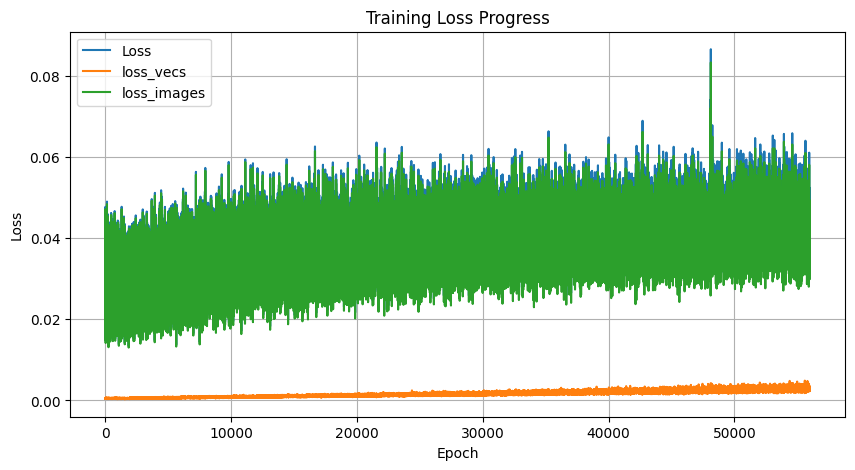

Epoch 80000/80000, Loss: 0.050140, loss_vec: 0.002674, loss_image: 0.047466, Shift Range: ±40

[Timing Epoch 80000]
Data              : 0.8676 sec
DVF generation    : 0.0022 sec
Transformer256    : 0.0050 sec
Wavelet analysis  : 0.0043 sec
AMP forward       : 0.0796 sec
AMP backward      : 0.2193 sec
Optimizer         : 0.0042 sec
Total             : 13.4175 sec

事前学習済みモデルを保存しました: model_DVF_pretrain_final.pth


In [ ]:
# NotdecoderHight
from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from pathlib import Path
import time


# ============================================================
# Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(tensor, sigma=1.0):
    from scipy.ndimage import gaussian_filter

    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )

# ============================================================
# 本番学習用にモデルを再初期化
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# Optimizerも再初期化
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=1e-4
)

print("本番学習用のmodel3D / optimizerを再初期化しました")

# ============================================================
# CUDA / AMP check
# ============================================================

use_amp = torch.cuda.is_available()

print("========================================")
print("CUDA / AMP settings")
print("========================================")
print("CUDA available :", torch.cuda.is_available())
print("device         :", device)

if torch.cuda.is_available():
    print("GPU            :", torch.cuda.get_device_name(0))
    print(
        "GPU memory     :",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB"
    )

print("AMP enabled    :", use_amp)
print("========================================")


# ============================================================
# AMP GradScaler
# ============================================================

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# cuDNN settings
#
# 入力サイズが毎回同じなので benchmark=True が有利なことがある
# ============================================================

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# Training settings
# ============================================================

epochs = 80000
shift_range = 1

losses = []
loss_vecs = []
loss_images = []

# ============================================================
# Resume training
# ============================================================

checkpoint_path = Path(
    "curriculum_checkpoints/pretrain_epoch_24000.pth"
)

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

model3D.load_state_dict(
    checkpoint["model_state_dict"]
)

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)

scaler.load_state_dict(
    checkpoint["scaler_state_dict"]
)

start_epoch = checkpoint["epoch"]
shift_range = checkpoint["shift_range"]

print("========================================")
print("Resume training")
print("========================================")
print("Checkpoint :", checkpoint_path)
print("Start epoch:", start_epoch)
print("Shift range:", f"±{shift_range}")
print("========================================")

# ============================================================
# Timing settings
#
# 最初の数epochと100epochごとに速度を確認
# ============================================================

PROFILE_FIRST_EPOCHS = 3
PROFILE_EVERY = 100

amp_dtype_checked = False


# ============================================================
# Training
# ============================================================

for epoch in tqdm(
    range(start_epoch, epochs),
    initial=start_epoch,
    total=epochs
):

    do_profile = (
        epoch < PROFILE_FIRST_EPOCHS
        or (epoch + 1) % PROFILE_EVERY == 0
    )

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    epoch_start = time.perf_counter()


    # ========================================================
    # Curriculum
    # ========================================================

    if epoch % 2000 == 0 and epoch > 0:

        shift_range += 1

        print(
            f"Epoch {epoch}: "
            f"Increasing shift range to ±{shift_range} voxels."
        )


    # ========================================================
    # Data
    # ========================================================

    t0 = time.perf_counter()

    train_batch, _ = next(train_generator)

    if torch.is_tensor(train_batch[0]):

        moving_images = train_batch[0].to(
            device=device,
            dtype=torch.float32,
            non_blocking=True
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_data = time.perf_counter() - t0


    # ========================================================
    # Batch / coarse DVF size
    # ========================================================

    B = moving_images.shape[0]

    D, H, W = 8, 16, 16


    # ========================================================
    # Synthetic DVF
    # ========================================================

    t0 = time.perf_counter()

    displacement_field = (
        torch.rand(
            (B, 3, D, H, W),
            dtype=torch.float32,
            device=device
        ) * 2 - 1
    ) * shift_range


    displacement_field = gaussian_smooth_3d(
        displacement_field,
        sigma=2.0
    )


    displacement_field = F.interpolate(
        displacement_field,
        size=(128, 256, 256),
        mode='trilinear',
        align_corners=False
    )


    displacement_field128 = F.interpolate(
        displacement_field,
        size=(64, 128, 128),
        mode='trilinear',
        align_corners=False
    ) / 2.0

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_dvf = time.perf_counter() - t0


    # ========================================================
    # Full-resolution deformation
    #
    # FP32
    # ========================================================

    t0 = time.perf_counter()

    moving_images2 = transformer256(
        moving_images,
        displacement_field
    )

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_transformer256 = time.perf_counter() - t0


    # ========================================================
    # Wavelet Analysis
    #
    # FP32
    # ========================================================

    t0 = time.perf_counter()

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )

    moving_images2_analysis = analysis_filter_3d(
        moving_images2,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    moving_images2_w = down_sampling_3d(
        moving_images2_analysis
    ).to(device)

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_wavelet_analysis = time.perf_counter() - t0


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # AMP Forward
    # ========================================================

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t0 = time.perf_counter()

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):

        # ----------------------------------------------------
        # VoxelMorph
        # ----------------------------------------------------

        Vec = model3D(
            moving_w,
            moving_images2_w
        )


        # ----------------------------------------------------
        # AMP dtype確認
        #
        # 最初の1回だけ表示
        # ----------------------------------------------------

        if not amp_dtype_checked:

            print("\n========================================")
            print("AMP dtype check")
            print("========================================")
            print("moving_w dtype :", moving_w.dtype)
            print("Vec dtype      :", Vec.dtype)
            print("========================================\n")

            amp_dtype_checked = True


        # ----------------------------------------------------
        # Wavelet-space deformation
        # ----------------------------------------------------

        moving_warped = transformer(
            moving_w,
            Vec
        )


        # ----------------------------------------------------
        # Up Sampling
        # ----------------------------------------------------

        moving_warped_up = up_sampling_3d(
            moving_warped
        )


        # ----------------------------------------------------
        # Synthesis Filter
        # ----------------------------------------------------

        transformed_image, filtered_bands = (
            synthesis_filter_3d(
                moving_warped_up,
                synthesis_filters
            )
        )


        # ----------------------------------------------------
        # Loss
        # ----------------------------------------------------

        loss_vec = (
            MSE_Loss(
                displacement_field128,
                Vec
            ) * 0.01
        )

        loss_image = (
            MSE_Loss(
                moving_images2,
                transformed_image
            ) * 100
        )

        loss = (
            loss_vec
            + loss_image
        )

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_forward = time.perf_counter() - t0


    # ========================================================
    # AMP Backward
    # ========================================================

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t0 = time.perf_counter()

    scaler.scale(
        loss
    ).backward()

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_backward = time.perf_counter() - t0


    # ========================================================
    # AMP Optimizer Step
    # ========================================================

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t0 = time.perf_counter()

    scaler.step(
        optimizer
    )

    scaler.update()

    if do_profile and torch.cuda.is_available():
        torch.cuda.synchronize()

    t_optimizer = time.perf_counter() - t0


    # ========================================================
    # Loss history
    # ========================================================

    losses.append(
        loss.detach().float().cpu().item()
    )

    loss_vecs.append(
        loss_vec.detach().float().cpu().item()
    )

    loss_images.append(
        loss_image.detach().float().cpu().item()
    )


    # ========================================================
    # Curriculum observation
    # ========================================================

    if (
        (epoch + 1) % OBSERVE_EVERY == 0
        or (epoch + 1) == epochs
    ):

        observe_curriculum_progress(
            model=model3D,
            epoch=epoch + 1,
            moving_image=observation_moving,
            shifts=OBSERVE_SHIFTS,
        )

        observe_random_deformation_progress(
            model=model3D,
            epoch=epoch + 1,
            moving_image=observation_moving,
        )


    # ========================================================
    # Latest model
    #
    # 100 epochごと
    # 重みのみ
    # ========================================================

    if (epoch + 1) % 100 == 0:

        torch.save(
            model3D.state_dict(),
            'model_DVF_pretrain_latest.pth'
        )


    # ========================================================
    # Full checkpoint
    #
    # OBSERVE_EVERYごと
    # ========================================================

    if (epoch + 1) % OBSERVE_EVERY == 0:

        checkpoint_dir = Path(
            "curriculum_checkpoints"
        )

        checkpoint_dir.mkdir(
            exist_ok=True
        )

        torch.save(
            {
                "epoch": epoch + 1,
                "model_state_dict": model3D.state_dict(),
                "optimizer_state_dict": optimizer.state_dict(),
                "scaler_state_dict": scaler.state_dict(),
                "shift_range": shift_range,
            },
            checkpoint_dir
            / f"pretrain_epoch_{epoch + 1:05d}.pth"
        )


    # ========================================================
    # Loss plot
    #
    # 500, 1000, 1500 ...
    # ========================================================

    if (epoch + 1) % 500 == 0:

        clear_output(
            wait=True
        )

        plt.figure(
            figsize=(10, 5)
        )

        plt.plot(
            losses,
            label='Loss'
        )

        plt.plot(
            loss_vecs,
            label='loss_vecs'
        )

        plt.plot(
            loss_images,
            label='loss_images'
        )

        plt.xlabel(
            'Epoch'
        )

        plt.ylabel(
            'Loss'
        )

        plt.title(
            'Training Loss Progress'
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.show()


    # ========================================================
    # Log
    #
    # 100 epochごと
    # ========================================================

    if (epoch + 1) % 100 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Loss: {loss.item():.6f}, "
            f"loss_vec: {loss_vec.item():.6f}, "
            f"loss_image: {loss_image.item():.6f}, "
            f"Shift Range: ±{shift_range}"
        )


    # ========================================================
    # Timing profile
    # ========================================================

    if do_profile:

        if torch.cuda.is_available():
            torch.cuda.synchronize()

        epoch_total = time.perf_counter() - epoch_start

        print(
            "\n"
            f"[Timing Epoch {epoch + 1}]\n"
            f"Data              : {t_data:.4f} sec\n"
            f"DVF generation    : {t_dvf:.4f} sec\n"
            f"Transformer256    : {t_transformer256:.4f} sec\n"
            f"Wavelet analysis  : {t_wavelet_analysis:.4f} sec\n"
            f"AMP forward       : {t_forward:.4f} sec\n"
            f"AMP backward      : {t_backward:.4f} sec\n"
            f"Optimizer         : {t_optimizer:.4f} sec\n"
            f"Total             : {epoch_total:.4f} sec\n"
        )


# ============================================================
# Final save
#
# 評価用：重みだけ
# ============================================================

torch.save(
    model3D.state_dict(),
    'model_DVF_pretrain_final.pth'
)


print(
    '事前学習済みモデルを保存しました: '
    'model_DVF_pretrain_final.pth'
)

In [ ]:
# NotdecoderHight
from tqdm.notebook import tqdm
from IPython.display import clear_output
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from pathlib import Path
import time


# ============================================================
# Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(tensor, sigma=1.0):
    from scipy.ndimage import gaussian_filter

    tensor_np = tensor.detach().cpu().numpy()

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[0, 0, sigma, sigma, sigma]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )

# ============================================================
# 本番学習用にモデルを再初期化
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)

[64, 128, 128]


[64, 128, 128]
Loaded pretrained model: model_DVF_pretrain_final.pth
Moving: (1, 1, 128, 256, 256)
Moving_w: (1, 8, 64, 128, 128)

Deformation strength = 1
GT full max abs: 0.20374922454357147
GT low max abs : 0.10187461227178574

----- DVF prediction -----
EPE mean : 0.30833483 voxel
EPE std  : 0.17983845 voxel
EPE max  : 1.12908721 voxel
Pred Vec mean abs: 0.15877631306648254
Pred Vec max abs : 0.953125

----- Moving' vs Warped -----
MAE        : 1.56935747e-03
RMSE       : 4.00569188e-03
RelativeL2 : 1.21771488e-02


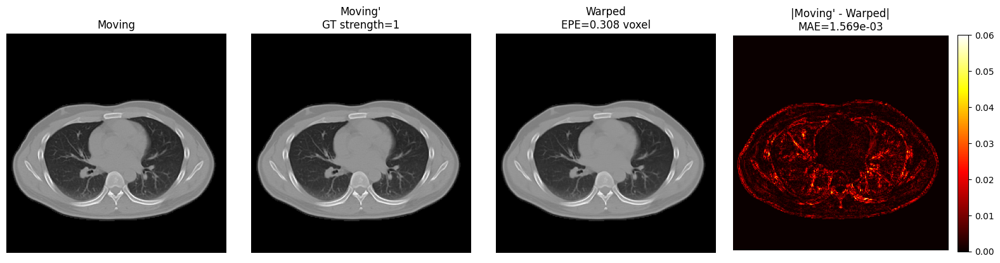


Deformation strength = 10
GT full max abs: 2.037492275238037
GT low max abs : 1.0187461376190186

----- DVF prediction -----
EPE mean : 0.33487204 voxel
EPE std  : 0.22099280 voxel
EPE max  : 3.33062911 voxel
Pred Vec mean abs: 0.20128023624420166
Pred Vec max abs : 3.0390625

----- Moving' vs Warped -----
MAE        : 3.29200225e-03
RMSE       : 9.78236886e-03
RelativeL2 : 2.98823360e-02


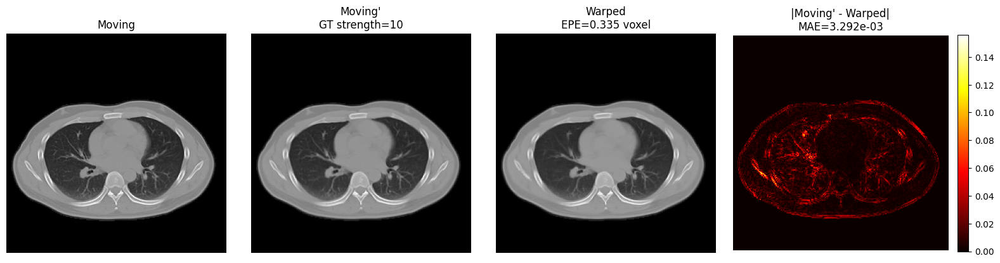


Deformation strength = 20
GT full max abs: 4.074984550476074
GT low max abs : 2.037492275238037

----- DVF prediction -----
EPE mean : 0.47203082 voxel
EPE std  : 0.37916312 voxel
EPE max  : 7.55402088 voxel
Pred Vec mean abs: 0.311795711517334
Pred Vec max abs : 7.00390625

----- Moving' vs Warped -----
MAE        : 4.81340010e-03
RMSE       : 1.52496124e-02
RelativeL2 : 4.67037037e-02


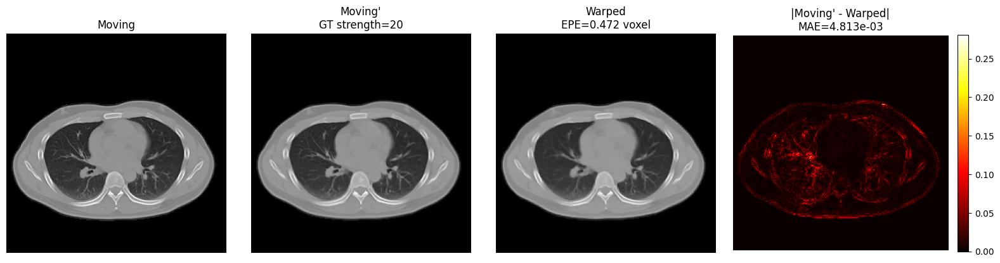


Deformation strength = 30
GT full max abs: 6.112476825714111
GT low max abs : 3.0562384128570557

----- DVF prediction -----
EPE mean : 0.64371622 voxel
EPE std  : 0.56615019 voxel
EPE max  : 8.38197899 voxel
Pred Vec mean abs: 0.3968616724014282
Pred Vec max abs : 7.53125

----- Moving' vs Warped -----
MAE        : 5.43117709e-03
RMSE       : 1.71739738e-02
RelativeL2 : 5.27116656e-02


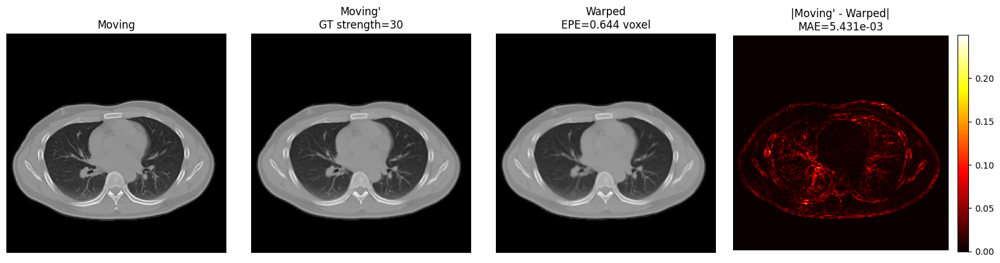


Deformation strength = 40
GT full max abs: 8.149969100952148
GT low max abs : 4.074984550476074

----- DVF prediction -----
EPE mean : 0.84624332 voxel
EPE std  : 0.73832208 voxel
EPE max  : 7.81415129 voxel
Pred Vec mean abs: 0.4704500138759613
Pred Vec max abs : 6.99609375

----- Moving' vs Warped -----
MAE        : 5.62508637e-03
RMSE       : 1.70510029e-02
RelativeL2 : 5.24670742e-02


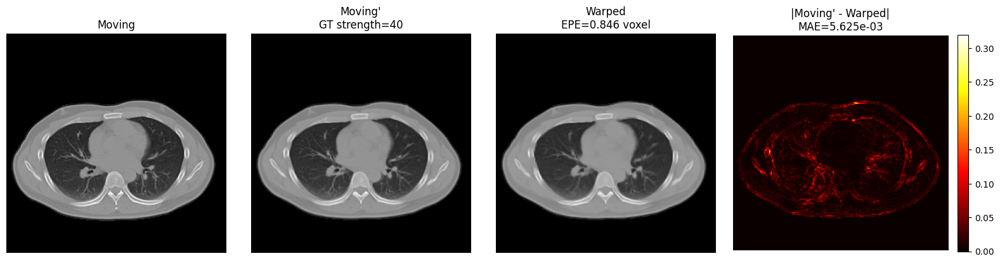

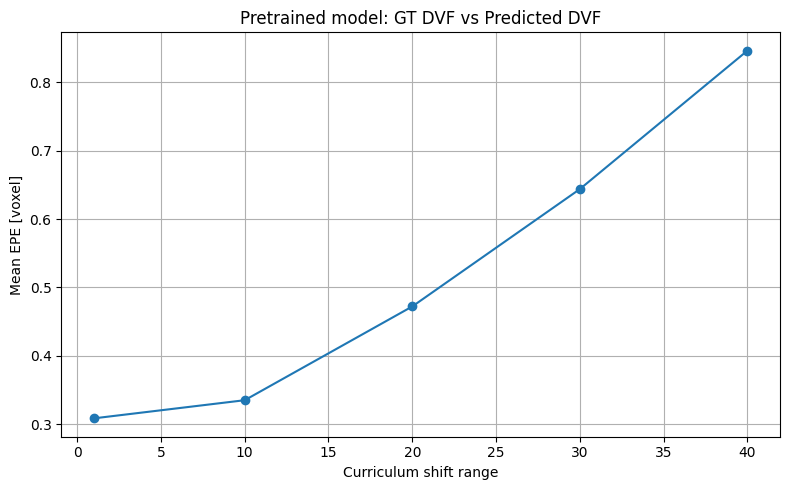

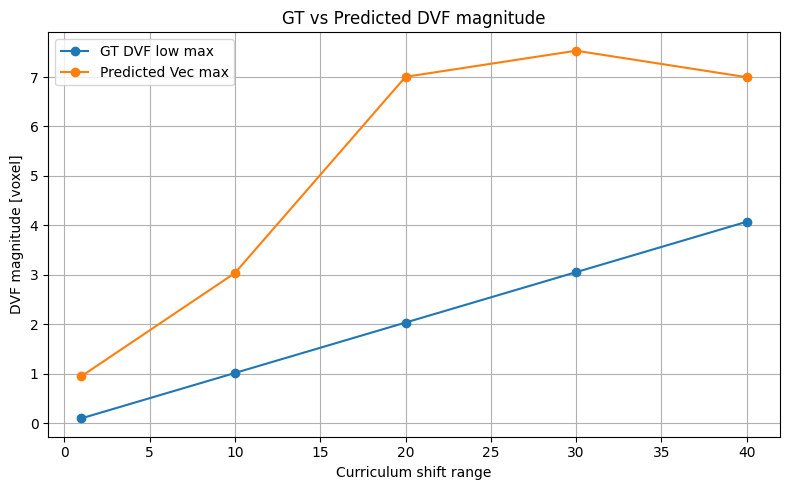


SUMMARY
Pred mean abs: 0.4704500138759613
Pred 95 percentile: 1.162109375
Pred 99 percentile: 1.7802734375
Pred max: 6.99609375
shift= 1 | GT low max=0.1019 | Pred max=0.9531 | EPE=0.3083 voxel | MAE=1.569357e-03
shift=10 | GT low max=1.0187 | Pred max=3.0391 | EPE=0.3349 voxel | MAE=3.292002e-03
shift=20 | GT low max=2.0375 | Pred max=7.0039 | EPE=0.4720 voxel | MAE=4.813400e-03
shift=30 | GT low max=3.0562 | Pred max=7.5312 | EPE=0.6437 voxel | MAE=5.431177e-03
shift=40 | GT low max=4.0750 | Pred max=6.9961 | EPE=0.8462 voxel | MAE=5.625086e-03
GT mean abs: 0.6889399886131287
GT 95 percentile: 1.7380212545394897
GT 99 percentile: 2.2586512565612793
GT max: 4.074984550476074


In [ ]:
import os
import math
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ============================================================
# 設定
# ============================================================

pretrained_path = "model_DVF_pretrain_final.pth"

# 評価したい変形強度
deformation_strengths = [
    1,
    10,
    20,
    30,
    40,
]

# 表示断面
slice_z = 64

# 同じ変形形状を全強度で使う
random_seed = 0

# 学習時と同じGaussian smoothing
sigma = 2.0


# ============================================================
# 事前学習モデル読み込み
# ============================================================

if not os.path.exists(pretrained_path):
    raise FileNotFoundError(
        f"事前学習済み重みが見つかりません: {pretrained_path}"
    )

model_eval = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)

model_eval.load_state_dict(
    torch.load(
        pretrained_path,
        map_location=device,
        weights_only=True
    )
)

model_eval.eval()

print(
    f"Loaded pretrained model: {pretrained_path}"
)


# ============================================================
# Spatial Transformer
# ============================================================

transformer_low_eval = vxm.layers.SpatialTransformer(
    (64, 128, 128)
).to(device)

transformer_full_eval = vxm.layers.SpatialTransformer(
    (128, 256, 256)
).to(device)


# ============================================================
# 評価用Movingを1枚取得
#
# train_generatorは使い切っている可能性があるため，
# 評価用generatorを新しく作る
# ============================================================

eval_batch_size = 1

eval_generator = vxm_data_generator(
    x_train,
    eval_batch_size
)

eval_batch, _ = next(
    eval_generator
)

if torch.is_tensor(eval_batch[0]):

    moving_eval = eval_batch[0].to(
        device=device,
        dtype=torch.float32
    )

else:

    moving_eval = torch.as_tensor(
        eval_batch[0],
        dtype=torch.float32,
        device=device
    )

print(
    "Moving:",
    tuple(moving_eval.shape)
)


# ============================================================
# Movingを事前にWavelet変換
# ============================================================

with torch.no_grad():

    moving_analysis_eval = analysis_filter_3d(
        moving_eval,
        analysis
    )

    moving_w_eval = down_sampling_3d(
        moving_analysis_eval
    ).to(device)

print(
    "Moving_w:",
    tuple(moving_w_eval.shape)
)


# ============================================================
# 学習時と同じ形のsmooth random DVFを作る
#
# 重要：
# ここでは「正規化して最大値をstrengthにする」のではなく，
# 現在の学習コードと同じ
#
# random × shift_range
#   ↓
# Gaussian smoothing
#   ↓
# interpolation
#
# とする
# ============================================================

torch.manual_seed(
    random_seed
)

D0, H0, W0 = (
    8,
    16,
    16
)

base_random = (
    torch.rand(
        (
            1,
            3,
            D0,
            H0,
            W0
        ),
        dtype=torch.float32,
        device=device
    )
    * 2.0
    - 1.0
)


# ============================================================
# EPE
# ============================================================

def calc_epe(
    gt_dvf,
    pred_dvf
):

    gt = gt_dvf.float()
    pred = pred_dvf.float()

    diff = (
        pred
        - gt
    )

    # 各voxelにおける3次元変位ベクトルの距離
    epe_map = torch.sqrt(
        torch.sum(
            diff ** 2,
            dim=1
        )
        + 1e-12
    )

    return {
        "mean":
            epe_map.mean().item(),

        "std":
            epe_map.std().item(),

        "max":
            epe_map.max().item(),

        "map":
            epe_map
    }


# ============================================================
# Image metrics
# ============================================================

def calc_image_metrics(
    reference,
    target
):

    diff = (
        reference.float()
        - target.float()
    )

    mae = torch.mean(
        torch.abs(diff)
    ).item()

    mse = torch.mean(
        diff ** 2
    ).item()

    rmse = float(
        np.sqrt(
            mse
        )
    )

    relative_l2 = (
        torch.linalg.vector_norm(
            diff
        )
        /
        (
            torch.linalg.vector_norm(
                reference.float()
            )
            + 1e-12
        )
    ).item()

    return {
        "MAE":
            mae,

        "MSE":
            mse,

        "RMSE":
            rmse,

        "RelativeL2":
            relative_l2,
    }


# ============================================================
# 結果保存
# ============================================================

results = []


# ============================================================
# 1，10，20，30，40 voxelを評価
# ============================================================

for deformation_strength in deformation_strengths:

    print(
        "\n"
        "============================================================"
    )

    print(
        f"Deformation strength = "
        f"{deformation_strength}"
    )

    print(
        "============================================================"
    )


    # ========================================================
    # 学習時と同じ人工DVF生成
    #
    # random × shift_range
    # ========================================================

    coarse_dvf = (
        base_random
        * float(
            deformation_strength
        )
    )


    # ========================================================
    # Gaussian smoothing
    # ========================================================

    gt_dvf_coarse = gaussian_smooth_3d(
        coarse_dvf,
        sigma=sigma
    )


    # ========================================================
    # Full-resolution GT DVF
    #
    # (1,3,128,256,256)
    # ========================================================

    gt_dvf_full = F.interpolate(
        gt_dvf_coarse,
        size=(
            128,
            256,
            256
        ),
        mode="trilinear",
        align_corners=False
    )


    # ========================================================
    # Wavelet-space GT DVF
    #
    # 学習時と同じ /2補正
    #
    # (1,3,64,128,128)
    # ========================================================

    gt_dvf_low = F.interpolate(
        gt_dvf_full,
        size=(
            64,
            128,
            128
        ),
        mode="trilinear",
        align_corners=False
    ) / 2.0


    print(
        "GT full max abs:",
        gt_dvf_full
        .abs()
        .max()
        .item()
    )

    print(
        "GT low max abs :",
        gt_dvf_low
        .abs()
        .max()
        .item()
    )


    with torch.no_grad():

        # ====================================================
        # GT DVFで直接変形
        #
        # Moving'
        # ====================================================

        moving_prime = transformer_full_eval(
            moving_eval,
            gt_dvf_full
        )


        # ====================================================
        # Moving' をWavelet変換
        # ====================================================

        moving_prime_analysis = analysis_filter_3d(
            moving_prime,
            analysis
        )

        moving_prime_w = down_sampling_3d(
            moving_prime_analysis
        ).to(device)


        # ====================================================
        # VoxelMorphでDVF予測
        # ====================================================

        with torch.cuda.amp.autocast(
            enabled=torch.cuda.is_available()
        ):

            pred_vec = model_eval(
                moving_w_eval,
                moving_prime_w
            )


        # ====================================================
        # GT DVF vs Predicted DVF
        # ====================================================

        epe = calc_epe(
            gt_dvf_low,
            pred_vec
        )


        # ====================================================
        # 予測DVFでWavelet空間を変形
        # ====================================================

        warped_w_pred = transformer_low_eval(
            moving_w_eval,
            pred_vec
        )


        # ====================================================
        # Up Sampling
        # ====================================================

        warped_w_pred_up = up_sampling_3d(
            warped_w_pred
        )


        # ====================================================
        # Synthesis Filter
        #
        # -> Warped
        # ====================================================

        warped_pred, _ = synthesis_filter_3d(
            warped_w_pred_up,
            synthesis_filters
        )


        # ====================================================
        # Moving' vs Warped
        # ====================================================

        image_metrics = calc_image_metrics(
            moving_prime,
            warped_pred
        )


    # ========================================================
    # 数値表示
    # ========================================================

    print(
        "\n----- DVF prediction -----"
    )

    print(
        f"EPE mean : "
        f"{epe['mean']:.8f} voxel"
    )

    print(
        f"EPE std  : "
        f"{epe['std']:.8f} voxel"
    )

    print(
        f"EPE max  : "
        f"{epe['max']:.8f} voxel"
    )

    print(
        "Pred Vec mean abs:",
        pred_vec
        .float()
        .abs()
        .mean()
        .item()
    )

    print(
        "Pred Vec max abs :",
        pred_vec
        .float()
        .abs()
        .max()
        .item()
    )


    print(
        "\n----- Moving' vs Warped -----"
    )

    print(
        f"MAE        : "
        f"{image_metrics['MAE']:.8e}"
    )

    print(
        f"RMSE       : "
        f"{image_metrics['RMSE']:.8e}"
    )

    print(
        f"RelativeL2 : "
        f"{image_metrics['RelativeL2']:.8e}"
    )


    # ========================================================
    # 保存
    # ========================================================

    results.append({
        "strength":
            deformation_strength,

        "GT_full_max":
            gt_dvf_full
            .abs()
            .max()
            .item(),

        "GT_low_max":
            gt_dvf_low
            .abs()
            .max()
            .item(),

        "Pred_max":
            pred_vec
            .float()
            .abs()
            .max()
            .item(),

        "EPE_mean":
            epe["mean"],

        "EPE_std":
            epe["std"],

        "EPE_max":
            epe["max"],

        "MAE":
            image_metrics["MAE"],

        "RMSE":
            image_metrics["RMSE"],

        "RelativeL2":
            image_metrics["RelativeL2"],
    })


    # ========================================================
    # 画像表示
    # ========================================================

    z = min(
        slice_z,
        moving_eval.shape[2] - 1
    )

    moving_np = (
        moving_eval[
            0,
            0,
            z
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    prime_np = (
        moving_prime[
            0,
            0,
            z
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    warped_np = (
        warped_pred[
            0,
            0,
            z
        ]
        .detach()
        .float()
        .cpu()
        .numpy()
    )

    diff_np = np.abs(
        prime_np
        - warped_np
    )


    # ========================================================
    # 4枚表示
    # ========================================================

    plt.figure(
        figsize=(
            16,
            4
        )
    )


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    plt.subplot(
        1,
        4,
        1
    )

    plt.imshow(
        moving_np,
        cmap="gray"
    )

    plt.title(
        "Moving"
    )

    plt.axis(
        "off"
    )


    # --------------------------------------------------------
    # Moving'
    # --------------------------------------------------------

    plt.subplot(
        1,
        4,
        2
    )

    plt.imshow(
        prime_np,
        cmap="gray"
    )

    plt.title(
        "Moving'\n"
        f"GT strength={deformation_strength}"
    )

    plt.axis(
        "off"
    )


    # --------------------------------------------------------
    # Predicted Warped
    # --------------------------------------------------------

    plt.subplot(
        1,
        4,
        3
    )

    plt.imshow(
        warped_np,
        cmap="gray"
    )

    plt.title(
        "Warped\n"
        f"EPE={epe['mean']:.3f} voxel"
    )

    plt.axis(
        "off"
    )


    # --------------------------------------------------------
    # Difference
    # --------------------------------------------------------

    plt.subplot(
        1,
        4,
        4
    )

    im = plt.imshow(
        diff_np,
        cmap="hot",
        vmin=0
    )

    plt.title(
        "|Moving' - Warped|\n"
        f"MAE={image_metrics['MAE']:.3e}"
    )

    plt.axis(
        "off"
    )

    plt.colorbar(
        im,
        fraction=0.046,
        pad=0.04
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# EPEグラフ
# ============================================================

strength_values = np.array([
    row["strength"]
    for row in results
])

epe_values = np.array([
    row["EPE_mean"]
    for row in results
])

plt.figure(
    figsize=(
        8,
        5
    )
)

plt.plot(
    strength_values,
    epe_values,
    marker="o"
)

plt.xlabel(
    "Curriculum shift range"
)

plt.ylabel(
    "Mean EPE [voxel]"
)

plt.title(
    "Pretrained model: GT DVF vs Predicted DVF"
)

plt.grid(
    True
)

plt.tight_layout()

plt.show()


# ============================================================
# GT最大変位 vs 予測最大変位
# ============================================================

gt_low_max_values = np.array([
    row["GT_low_max"]
    for row in results
])

pred_max_values = np.array([
    row["Pred_max"]
    for row in results
])

plt.figure(
    figsize=(
        8,
        5
    )
)

plt.plot(
    strength_values,
    gt_low_max_values,
    marker="o",
    label="GT DVF low max"
)

plt.plot(
    strength_values,
    pred_max_values,
    marker="o",
    label="Predicted Vec max"
)

plt.xlabel(
    "Curriculum shift range"
)

plt.ylabel(
    "DVF magnitude [voxel]"
)

plt.title(
    "GT vs Predicted DVF magnitude"
)

plt.grid(
    True
)

plt.legend()

plt.tight_layout()

plt.show()


# ============================================================
# 最後に表形式で表示
# ============================================================

print(
    "\n"
    "============================================================"
)

print(
    "SUMMARY"
)

print(
    "============================================================"
)

pred_abs = pred_vec.detach().float().abs()

print(
    "Pred mean abs:",
    pred_abs.mean().item()
)

print(
    "Pred 95 percentile:",
    torch.quantile(
        pred_abs.flatten(),
        0.95
    ).item()
)

print(
    "Pred 99 percentile:",
    torch.quantile(
        pred_abs.flatten(),
        0.99
    ).item()
)

print(
    "Pred max:",
    pred_abs.max().item()
)

for row in results:

    print(
        f"shift={row['strength']:2d} | "
        f"GT low max={row['GT_low_max']:.4f} | "
        f"Pred max={row['Pred_max']:.4f} | "
        f"EPE={row['EPE_mean']:.4f} voxel | "
        f"MAE={row['MAE']:.6e}"
    )
    
gt_abs = gt_dvf_low.detach().float().abs()

print(
    "GT mean abs:",
    gt_abs.mean().item()
)

print(
    "GT 95 percentile:",
    torch.quantile(
        gt_abs.flatten(),
        0.95
    ).item()
)

print(
    "GT 99 percentile:",
    torch.quantile(
        gt_abs.flatten(),
        0.99
    ).item()
)

print(
    "GT max:",
    gt_abs.max().item()
)

GT shape  : torch.Size([1, 3, 64, 128, 128])
Pred shape: torch.Size([1, 3, 64, 128, 128])
GT inner shape  : torch.Size([1, 3, 54, 118, 118])
Pred inner shape: torch.Size([1, 3, 54, 118, 118])

GT DVF neighbor differences
Z direction
  mean abs : 0.025172
  95%      : 0.069293
  99%      : 0.091097
  max      : 0.119727
Y direction
  mean abs : 0.024131
  95%      : 0.063992
  99%      : 0.090736
  max      : 0.126092
X direction
  mean abs : 0.023996
  95%      : 0.064381
  99%      : 0.088939
  max      : 0.141916

Predicted DVF neighbor differences
Z direction
  mean abs : 0.041800
  95%      : 0.142090
  99%      : 0.286804
  max      : 7.765625
Y direction
  mean abs : 0.058467
  95%      : 0.204102
  99%      : 0.479370
  max      : 4.488281
X direction
  mean abs : 0.048434
  95%      : 0.177979
  99%      : 0.372803
  max      : 4.767578

GT gradient magnitude
Mean : 0.09355350583791733
95%  : 0.13214053213596344
99%  : 0.14693683385849
Max  : 0.1805218905210495

Pred gradient m

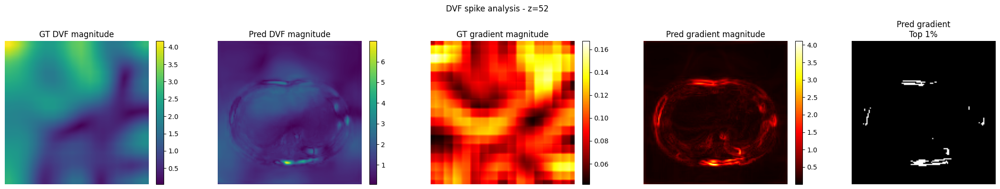

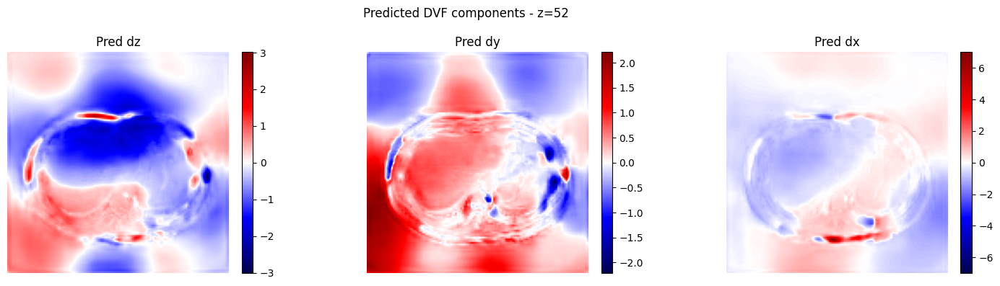



INNER REGION ANALYSIS
GT inner shape  : torch.Size([1, 3, 54, 118, 118])
Pred inner shape: torch.Size([1, 3, 54, 118, 118])

GT inner DVF
Mean abs : 0.6589699387550354
95%      : 1.6513497829437256
99%      : 2.150686264038086
Max      : 3.8464062213897705

Pred inner DVF
Mean abs : 0.47306281328201294
95%      : 1.134765625
99%      : 1.728515625
Max      : 6.99609375

GT INNER neighbor differences
Z direction
  mean abs : 0.028098
  95%      : 0.070755
  99%      : 0.090893
  max      : 0.115456
Y direction
  mean abs : 0.024060
  95%      : 0.060026
  99%      : 0.084977
  max      : 0.119988
X direction
  mean abs : 0.024391
  95%      : 0.062136
  99%      : 0.084165
  max      : 0.140462

Pred INNER neighbor differences
Z direction
  mean abs : 0.043051
  95%      : 0.147217
  99%      : 0.295410
  max      : 2.009766
Y direction
  mean abs : 0.063938
  95%      : 0.225830
  99%      : 0.535645
  max      : 4.488281
X direction
  mean abs : 0.051549
  95%      : 0.189941
  99% 

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt


# ============================================================
# GT / Pred DVF
#
# gt_dvf_low : (B, 3, 64, 128, 128)
# pred_vec    : (B, 3, 64, 128, 128)
# ============================================================

gt = gt_dvf_low.detach().float()
pred = pred_vec.detach().float()
gt_inner = gt[:, :, 5:-5, 5:-5, 5:-5]
pred_inner = pred[:, :, 5:-5, 5:-5, 5:-5]

print("GT shape  :", gt.shape)
print("Pred shape:", pred.shape)

print("GT inner shape  :", gt_inner.shape)
print("Pred inner shape:", pred_inner.shape)


# ============================================================
# 1. 隣接voxel間のDVF差
#
# 各方向について
#
# dz = d(z+1) - d(z)
# dy = d(y+1) - d(y)
# dx = d(x+1) - d(x)
#
# を計算
# ============================================================

def dvf_neighbor_differences(dvf):

    diff_z = (
        dvf[:, :, 1:, :, :]
        - dvf[:, :, :-1, :, :]
    )

    diff_y = (
        dvf[:, :, :, 1:, :]
        - dvf[:, :, :, :-1, :]
    )

    diff_x = (
        dvf[:, :, :, :, 1:]
        - dvf[:, :, :, :, :-1]
    )

    return diff_z, diff_y, diff_x


gt_dz, gt_dy, gt_dx = dvf_neighbor_differences(gt)
pred_dz, pred_dy, pred_dx = dvf_neighbor_differences(pred)


# ============================================================
# 2. 隣接voxel差の統計
# ============================================================

def print_diff_stats(name, dz, dy, dx):

    print()
    print("=" * 60)
    print(name)
    print("=" * 60)

    for direction, diff in [
        ("Z", dz),
        ("Y", dy),
        ("X", dx),
    ]:

        values = diff.abs().flatten()

        print(
            f"{direction} direction"
        )

        print(
            f"  mean abs : "
            f"{values.mean().item():.6f}"
        )

        print(
            f"  95%      : "
            f"{torch.quantile(values, 0.95).item():.6f}"
        )

        print(
            f"  99%      : "
            f"{torch.quantile(values, 0.99).item():.6f}"
        )

        print(
            f"  max      : "
            f"{values.max().item():.6f}"
        )


print_diff_stats(
    "GT DVF neighbor differences",
    gt_dz,
    gt_dy,
    gt_dx
)

print_diff_stats(
    "Predicted DVF neighbor differences",
    pred_dz,
    pred_dy,
    pred_dx
)


# ============================================================
# 3. 各voxelでのDVFベクトルMagnitude
#
# sqrt(dz^2 + dy^2 + dx^2)
# ============================================================

gt_vector_magnitude = torch.sqrt(
    torch.sum(
        gt ** 2,
        dim=1
    )
)

pred_vector_magnitude = torch.sqrt(
    torch.sum(
        pred ** 2,
        dim=1
    )
)


# ============================================================
# 4. DVFの空間勾配Magnitude
#
# 3つのDVF成分について，
# 隣接voxelとの差をまとめて評価する
#
# 出力shapeを合わせるため中央領域を使用
# ============================================================

def dvf_gradient_magnitude(dvf):

    # --------------------------------------------
    # z方向
    # --------------------------------------------

    dz = (
        dvf[:, :, 1:, :, :]
        - dvf[:, :, :-1, :, :]
    )

    # --------------------------------------------
    # y方向
    # --------------------------------------------

    dy = (
        dvf[:, :, :, 1:, :]
        - dvf[:, :, :, :-1, :]
    )

    # --------------------------------------------
    # x方向
    # --------------------------------------------

    dx = (
        dvf[:, :, :, :, 1:]
        - dvf[:, :, :, :, :-1]
    )


    # --------------------------------------------
    # 共通サイズ
    #
    # (D-1, H-1, W-1)
    # --------------------------------------------

    dz = dz[:, :, :, :-1, :-1]
    dy = dy[:, :, :-1, :, :-1]
    dx = dx[:, :, :-1, :-1, :]


    # --------------------------------------------
    # 3 DVF components × 3 spatial directions
    # の勾配Magnitude
    # --------------------------------------------

    grad_mag = torch.sqrt(
        torch.sum(
            dz ** 2,
            dim=1
        )
        +
        torch.sum(
            dy ** 2,
            dim=1
        )
        +
        torch.sum(
            dx ** 2,
            dim=1
        )
        +
        1e-12
    )

    return grad_mag


gt_grad_mag = dvf_gradient_magnitude(
    gt
)

pred_grad_mag = dvf_gradient_magnitude(
    pred
)


# ============================================================
# 5. Gradient magnitude統計
# ============================================================

def print_gradient_stats(
    name,
    grad
):

    values = grad.flatten()

    print()
    print("=" * 60)
    print(name)
    print("=" * 60)

    print(
        "Mean :",
        values.mean().item()
    )

    print(
        "95%  :",
        torch.quantile(
            values,
            0.95
        ).item()
    )

    print(
        "99%  :",
        torch.quantile(
            values,
            0.99
        ).item()
    )

    print(
        "Max  :",
        values.max().item()
    )


print_gradient_stats(
    "GT gradient magnitude",
    gt_grad_mag
)

print_gradient_stats(
    "Pred gradient magnitude",
    pred_grad_mag
)


# ============================================================
# 6. Predicted DVFで最も大きな値の位置
#
# predは
# (B, C, Z, Y, X)
# ============================================================

pred_abs = pred.abs()

flat_index = torch.argmax(
    pred_abs
)

index = np.unravel_index(
    flat_index.cpu().item(),
    pred_abs.shape
)

batch_idx = index[0]
component_idx = index[1]
z_max = index[2]
y_max = index[3]
x_max = index[4]

component_names = [
    "Z displacement",
    "Y displacement",
    "X displacement",
]

print()
print("=" * 60)
print("Largest predicted DVF value")
print("=" * 60)

print(
    "Component :",
    component_names[
        component_idx
    ]
)

print(
    "Location  :",
    f"(z={z_max}, y={y_max}, x={x_max})"
)

print(
    "Pred value:",
    pred[
        batch_idx,
        component_idx,
        z_max,
        y_max,
        x_max
    ].item()
)

print(
    "GT value  :",
    gt[
        batch_idx,
        component_idx,
        z_max,
        y_max,
        x_max
    ].item()
)


# ============================================================
# 7. 最大値位置で3成分全部を比較
# ============================================================

print()
print("DVF vector at spike position")

print(
    "GT   :",
    gt[
        batch_idx,
        :,
        z_max,
        y_max,
        x_max
    ].cpu().numpy()
)

print(
    "Pred :",
    pred[
        batch_idx,
        :,
        z_max,
        y_max,
        x_max
    ].cpu().numpy()
)


# ============================================================
# 8. Pred gradientの上位1%をSpike候補とする
# ============================================================

threshold_99 = torch.quantile(
    pred_grad_mag.flatten(),
    0.99
)

spike_mask = (
    pred_grad_mag
    >= threshold_99
)

print()
print("=" * 60)
print("Spike detection")
print("=" * 60)

print(
    "99% gradient threshold:",
    threshold_99.item()
)

print(
    "Spike voxels:",
    spike_mask.sum().item()
)

print(
    "Total voxels:",
    spike_mask.numel()
)

print(
    "Spike ratio:",
    spike_mask.float().mean().item() * 100,
    "%"
)


# ============================================================
# 9. 最大DVFが存在するz断面を表示
#
# low-resolution DVFなのでzは0～63
# ============================================================

display_z = min(
    z_max,
    pred_grad_mag.shape[1] - 1
)

print()
print(
    f"Visualizing Wavelet-space z = {display_z}"
)


# ============================================================
# CPUへ
# ============================================================

gt_mag_np = (
    gt_vector_magnitude[
        0,
        display_z
    ]
    .cpu()
    .numpy()
)

pred_mag_np = (
    pred_vector_magnitude[
        0,
        display_z
    ]
    .cpu()
    .numpy()
)

gt_grad_np = (
    gt_grad_mag[
        0,
        display_z
    ]
    .cpu()
    .numpy()
)

pred_grad_np = (
    pred_grad_mag[
        0,
        display_z
    ]
    .cpu()
    .numpy()
)

spike_np = (
    spike_mask[
        0,
        display_z
    ]
    .cpu()
    .numpy()
)


# ============================================================
# 10. DVF magnitude / gradientを表示
# ============================================================

fig, axes = plt.subplots(
    1,
    5,
    figsize=(22, 4)
)


# ------------------------------------------------------------
# GT DVF magnitude
# ------------------------------------------------------------

im0 = axes[0].imshow(
    gt_mag_np,
    cmap="viridis"
)

axes[0].set_title(
    "GT DVF magnitude"
)

axes[0].axis(
    "off"
)

plt.colorbar(
    im0,
    ax=axes[0],
    fraction=0.046,
    pad=0.04
)


# ------------------------------------------------------------
# Pred DVF magnitude
# ------------------------------------------------------------

im1 = axes[1].imshow(
    pred_mag_np,
    cmap="viridis"
)

axes[1].set_title(
    "Pred DVF magnitude"
)

axes[1].axis(
    "off"
)

plt.colorbar(
    im1,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)


# ------------------------------------------------------------
# GT gradient
# ------------------------------------------------------------

im2 = axes[2].imshow(
    gt_grad_np,
    cmap="hot"
)

axes[2].set_title(
    "GT gradient magnitude"
)

axes[2].axis(
    "off"
)

plt.colorbar(
    im2,
    ax=axes[2],
    fraction=0.046,
    pad=0.04
)


# ------------------------------------------------------------
# Pred gradient
# ------------------------------------------------------------

im3 = axes[3].imshow(
    pred_grad_np,
    cmap="hot"
)

axes[3].set_title(
    "Pred gradient magnitude"
)

axes[3].axis(
    "off"
)

plt.colorbar(
    im3,
    ax=axes[3],
    fraction=0.046,
    pad=0.04
)


# ------------------------------------------------------------
# Spike mask
# ------------------------------------------------------------

axes[4].imshow(
    spike_np,
    cmap="gray"
)

axes[4].set_title(
    "Pred gradient\nTop 1%"
)

axes[4].axis(
    "off"
)


plt.suptitle(
    f"DVF spike analysis - z={display_z}"
)

plt.tight_layout()

plt.show()


# ============================================================
# 11. Predの3成分を個別表示
# ============================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 4)
)

pred_component_names = [
    "Pred dz",
    "Pred dy",
    "Pred dx",
]

for c in range(3):

    component_image = (
        pred[
            0,
            c,
            display_z
        ]
        .cpu()
        .numpy()
    )

    max_value = np.max(
        np.abs(
            component_image
        )
    )

    im = axes[c].imshow(
        component_image,
        cmap="seismic",
        vmin=-max_value,
        vmax=max_value
    )

    axes[c].set_title(
        pred_component_names[c]
    )

    axes[c].axis(
        "off"
    )

    plt.colorbar(
        im,
        ax=axes[c],
        fraction=0.046,
        pad=0.04
    )


plt.suptitle(
    f"Predicted DVF components - z={display_z}"
)

plt.tight_layout()

plt.show()

# ============================================================
# 境界5 voxelを除外した内部領域で再評価
# ============================================================

print("\n")
print("=" * 60)
print("INNER REGION ANALYSIS")
print("=" * 60)

gt_inner = gt[:, :, 5:-5, 5:-5, 5:-5]
pred_inner = pred[:, :, 5:-5, 5:-5, 5:-5]

print("GT inner shape  :", gt_inner.shape)
print("Pred inner shape:", pred_inner.shape)


# ============================================================
# DVF値そのものの統計
# ============================================================

def print_dvf_value_stats(name, dvf):

    values = dvf.abs().flatten()

    print()
    print(name)

    print(
        "Mean abs :",
        values.mean().item()
    )

    print(
        "95%      :",
        torch.quantile(
            values,
            0.95
        ).item()
    )

    print(
        "99%      :",
        torch.quantile(
            values,
            0.99
        ).item()
    )

    print(
        "Max      :",
        values.max().item()
    )


print_dvf_value_stats(
    "GT inner DVF",
    gt_inner
)

print_dvf_value_stats(
    "Pred inner DVF",
    pred_inner
)


# ============================================================
# 隣接voxel差
# ============================================================

gt_inner_dz, gt_inner_dy, gt_inner_dx = (
    dvf_neighbor_differences(
        gt_inner
    )
)

pred_inner_dz, pred_inner_dy, pred_inner_dx = (
    dvf_neighbor_differences(
        pred_inner
    )
)


print_diff_stats(
    "GT INNER neighbor differences",
    gt_inner_dz,
    gt_inner_dy,
    gt_inner_dx
)

print_diff_stats(
    "Pred INNER neighbor differences",
    pred_inner_dz,
    pred_inner_dy,
    pred_inner_dx
)


# ============================================================
# Gradient magnitude
# ============================================================

gt_inner_grad = dvf_gradient_magnitude(
    gt_inner
)

pred_inner_grad = dvf_gradient_magnitude(
    pred_inner
)


print_gradient_stats(
    "GT INNER gradient magnitude",
    gt_inner_grad
)

print_gradient_stats(
    "Pred INNER gradient magnitude",
    pred_inner_grad
)


# ============================================================
# 内部領域でPred最大値の位置
# ============================================================

pred_inner_abs = pred_inner.abs()

flat_index_inner = torch.argmax(
    pred_inner_abs
)

index_inner = np.unravel_index(
    flat_index_inner.cpu().item(),
    pred_inner_abs.shape
)

b_i = index_inner[0]
c_i = index_inner[1]
z_i = index_inner[2]
y_i = index_inner[3]
x_i = index_inner[4]


# 元画像座標へ戻す
z_original = z_i + 5
y_original = y_i + 5
x_original = x_i + 5


print()
print("=" * 60)
print("Largest predicted DVF value in INNER region")
print("=" * 60)

print(
    "Component :",
    component_names[c_i]
)

print(
    "Inner loc :",
    f"(z={z_i}, y={y_i}, x={x_i})"
)

print(
    "Original loc:",
    f"(z={z_original}, "
    f"y={y_original}, "
    f"x={x_original})"
)

print(
    "Pred value:",
    pred[
        b_i,
        c_i,
        z_original,
        y_original,
        x_original
    ].item()
)

print(
    "GT value  :",
    gt[
        b_i,
        c_i,
        z_original,
        y_original,
        x_original
    ].item()
)

In [ ]:
import torch

print(
    "CUDA available:",
    torch.cuda.is_available()
)

print(
    "GPU:",
    torch.cuda.get_device_name(0)
)

x = torch.tensor(
    [1.0],
    device="cuda"
)

print(x)

print("CUDA test OK")

CUDA available: True
GPU: NVIDIA GeForce RTX 3090
tensor([1.], device='cuda:0')
CUDA test OK



① Before Gaussian
Shape     : (1, 3, 8, 16, 16)
Mean abs  : 20.138206
95%       : 37.860554
99%       : 39.561802
Max       : 39.998600

② After Gaussian
Shape     : (1, 3, 8, 16, 16)
Mean abs  : 1.408513
95%       : 3.547532
99%       : 4.598182
Max       : 8.149969

③ Full resolution
Shape     : (1, 3, 128, 256, 256)
Mean abs  : 1.378058
95%       : 3.472474
99%       : 4.510686
Max       : 8.149969

④ Wavelet resolution /2
Shape     : (1, 3, 64, 128, 128)
Mean abs  : 0.688940
95%       : 1.724565
99%       : 2.220891
Max       : 4.074985

① Before Gaussian - Neighbor difference
Z
  mean : 26.697098
  95%  : 62.253517
  99%  : 72.602791
  max  : 78.646347
Y
  mean : 26.799498
  95%  : 61.887184
  99%  : 72.403297
  max  : 78.246643
X
  mean : 26.542942
  95%  : 62.408581
  99%  : 72.157120
  max  : 78.452103

② After Gaussian - Neighbor difference
Z
  mean : 0.462045
  95%  : 1.179425
  99%  : 1.511272
  max  : 1.915623
Y
  mean : 0.418371
  95%  : 1.068767
  99%  : 1.505736
  max  

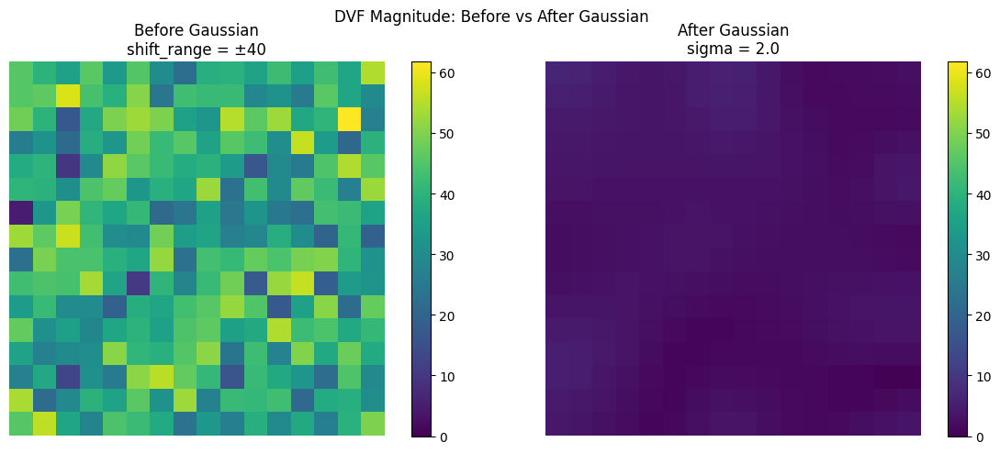

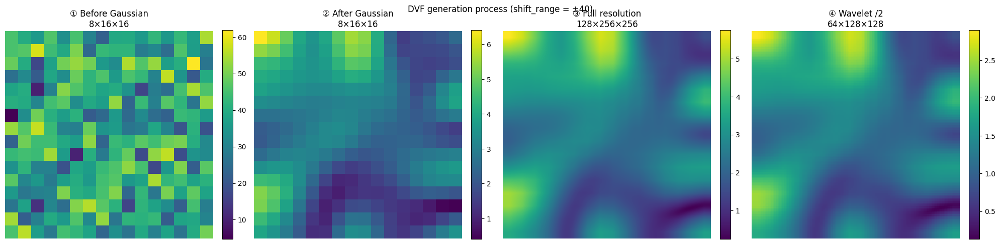


Gaussian smoothing effect
Before max  : 39.998600
After max   : 8.149969
Max ratio   : 0.203756
Max reduction : 79.62%

Before mean : 20.138206
After mean  : 1.408513
Mean ratio  : 0.069942
Mean reduction : 93.01%


In [ ]:
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


# ============================================================
# 設定
# ============================================================

shift_range_test = 40
sigma_test = 2.0
random_seed = 0

torch.manual_seed(random_seed)


# ============================================================
# 1. Gaussian前
# 学習時と同じ coarse DVF
#
# (1, 3, 8, 16, 16)
# ============================================================

dvf_before = (
    torch.rand(
        (1, 3, 8, 16, 16),
        dtype=torch.float32,
        device=device
    ) * 2 - 1
) * shift_range_test


# ============================================================
# 2. Gaussian後
# ============================================================

dvf_after_gaussian = gaussian_smooth_3d(
    dvf_before,
    sigma=sigma_test
)


# ============================================================
# 3. Full resolution
#
# (1, 3, 128, 256, 256)
# ============================================================

dvf_full = F.interpolate(
    dvf_after_gaussian,
    size=(128, 256, 256),
    mode="trilinear",
    align_corners=False
)


# ============================================================
# 4. Wavelet resolution
#
# (1, 3, 64, 128, 128)
#
# voxel単位を合わせるため /2
# ============================================================

dvf_low = F.interpolate(
    dvf_full,
    size=(64, 128, 128),
    mode="trilinear",
    align_corners=False
) / 2.0


# ============================================================
# quantile計算用サンプリング
# ============================================================

def sample_for_quantile(
    values,
    max_samples=1_000_000
):

    values = values.flatten()

    if values.numel() <= max_samples:
        return values

    step = max(
        values.numel() // max_samples,
        1
    )

    sampled = values[::step]

    return sampled[:max_samples]


# ============================================================
# DVF値統計
# ============================================================

def print_value_stats(
    name,
    dvf
):

    values = (
        dvf
        .detach()
        .float()
        .abs()
        .cpu()
        .flatten()
    )

    q_values = sample_for_quantile(
        values
    )

    print()
    print("=" * 65)
    print(name)
    print("=" * 65)

    print(
        f"Shape     : {tuple(dvf.shape)}"
    )

    print(
        f"Mean abs  : {values.mean().item():.6f}"
    )

    print(
        f"95%       : "
        f"{torch.quantile(q_values, 0.95).item():.6f}"
    )

    print(
        f"99%       : "
        f"{torch.quantile(q_values, 0.99).item():.6f}"
    )

    print(
        f"Max       : {values.max().item():.6f}"
    )


# ============================================================
# 隣接voxel差
# ============================================================

def neighbor_difference_stats(
    name,
    dvf
):

    # CPUで計算
    x = (
        dvf
        .detach()
        .float()
        .cpu()
    )

    dz = (
        x[:, :, 1:, :, :]
        - x[:, :, :-1, :, :]
    )

    dy = (
        x[:, :, :, 1:, :]
        - x[:, :, :, :-1, :]
    )

    dx = (
        x[:, :, :, :, 1:]
        - x[:, :, :, :, :-1]
    )

    print()
    print("=" * 65)
    print(name)
    print("=" * 65)

    for direction, diff in [
        ("Z", dz),
        ("Y", dy),
        ("X", dx),
    ]:

        values = (
            diff
            .abs()
            .flatten()
        )

        q_values = sample_for_quantile(
            values
        )

        print(
            f"{direction}"
        )

        print(
            f"  mean : "
            f"{values.mean().item():.6f}"
        )

        print(
            f"  95%  : "
            f"{torch.quantile(q_values, 0.95).item():.6f}"
        )

        print(
            f"  99%  : "
            f"{torch.quantile(q_values, 0.99).item():.6f}"
        )

        print(
            f"  max  : "
            f"{values.max().item():.6f}"
        )


# ============================================================
# 統計
# ============================================================

print_value_stats(
    "① Before Gaussian",
    dvf_before
)

print_value_stats(
    "② After Gaussian",
    dvf_after_gaussian
)

print_value_stats(
    "③ Full resolution",
    dvf_full
)

print_value_stats(
    "④ Wavelet resolution /2",
    dvf_low
)


# ============================================================
# 隣接voxel差
# ============================================================

neighbor_difference_stats(
    "① Before Gaussian - Neighbor difference",
    dvf_before
)

neighbor_difference_stats(
    "② After Gaussian - Neighbor difference",
    dvf_after_gaussian
)

neighbor_difference_stats(
    "③ Full resolution - Neighbor difference",
    dvf_full
)

neighbor_difference_stats(
    "④ Wavelet resolution /2 - Neighbor difference",
    dvf_low
)


# ============================================================
# DVF magnitude
#
# sqrt(dz^2 + dy^2 + dx^2)
# ============================================================

def vector_magnitude(
    dvf
):

    return torch.sqrt(
        torch.sum(
            dvf.detach().float() ** 2,
            dim=1
        )
    )


mag_before = vector_magnitude(
    dvf_before
)

mag_gaussian = vector_magnitude(
    dvf_after_gaussian
)

mag_full = vector_magnitude(
    dvf_full
)

mag_low = vector_magnitude(
    dvf_low
)


# ============================================================
# 中央断面
# ============================================================

def center_slice(
    magnitude
):

    z = magnitude.shape[1] // 2

    return (
        magnitude[
            0,
            z
        ]
        .cpu()
        .numpy()
    )


img_before = center_slice(
    mag_before
)

img_gaussian = center_slice(
    mag_gaussian
)

img_full = center_slice(
    mag_full
)

img_low = center_slice(
    mag_low
)


# ============================================================
# Gaussian前後
#
# 同じカラースケールで比較
# ============================================================

common_max = max(
    img_before.max(),
    img_gaussian.max()
)

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12, 5)
)


im = axes[0].imshow(
    img_before,
    cmap="viridis",
    vmin=0,
    vmax=common_max
)

axes[0].set_title(
    f"Before Gaussian\n"
    f"shift_range = ±{shift_range_test}"
)

axes[0].axis(
    "off"
)

plt.colorbar(
    im,
    ax=axes[0]
)


im = axes[1].imshow(
    img_gaussian,
    cmap="viridis",
    vmin=0,
    vmax=common_max
)

axes[1].set_title(
    f"After Gaussian\n"
    f"sigma = {sigma_test}"
)

axes[1].axis(
    "off"
)

plt.colorbar(
    im,
    ax=axes[1]
)


plt.suptitle(
    "DVF Magnitude: Before vs After Gaussian"
)

plt.tight_layout()

plt.show()


# ============================================================
# 4段階比較
#
# 注意：
# 解像度・単位が違うので，
# ここでは各画像ごとにcolor scaleを設定
# ============================================================

fig, axes = plt.subplots(
    1,
    4,
    figsize=(20, 5)
)

images = [
    img_before,
    img_gaussian,
    img_full,
    img_low,
]

titles = [
    "① Before Gaussian\n8×16×16",
    "② After Gaussian\n8×16×16",
    "③ Full resolution\n128×256×256",
    "④ Wavelet /2\n64×128×128",
]


for ax, image, title in zip(
    axes,
    images,
    titles
):

    im = ax.imshow(
        image,
        cmap="viridis"
    )

    ax.set_title(
        title
    )

    ax.axis(
        "off"
    )

    plt.colorbar(
        im,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )


plt.suptitle(
    f"DVF generation process "
    f"(shift_range = ±{shift_range_test})"
)

plt.tight_layout()

plt.show()


# ============================================================
# Gaussianの減衰率
# ============================================================

before_abs = (
    dvf_before
    .detach()
    .float()
    .abs()
    .cpu()
)

after_abs = (
    dvf_after_gaussian
    .detach()
    .float()
    .abs()
    .cpu()
)


before_max = (
    before_abs
    .max()
    .item()
)

after_max = (
    after_abs
    .max()
    .item()
)

before_mean = (
    before_abs
    .mean()
    .item()
)

after_mean = (
    after_abs
    .mean()
    .item()
)


print()
print("=" * 65)
print("Gaussian smoothing effect")
print("=" * 65)

print(
    f"Before max  : {before_max:.6f}"
)

print(
    f"After max   : {after_max:.6f}"
)

print(
    f"Max ratio   : "
    f"{after_max / before_max:.6f}"
)

print(
    f"Max reduction : "
    f"{(1 - after_max / before_max) * 100:.2f}%"
)

print()

print(
    f"Before mean : {before_mean:.6f}"
)

print(
    f"After mean  : {after_mean:.6f}"
)

print(
    f"Mean ratio  : "
    f"{after_mean / before_mean:.6f}"
)

print(
    f"Mean reduction : "
    f"{(1 - after_mean / before_mean) * 100:.2f}%"
)

In [ ]:
import torch
import torch.nn.functional as F
import numpy as np


# ============================================================
# 設定
# ============================================================

shift_range_test = 40
sigma_test = 2.0
num_tests = 10

model3D.eval()


# ============================================================
# Smoothness Loss
#
# 隣接voxel間のDVF差の二乗平均
# ============================================================

def smoothness_loss_3d(dvf):

    dz = (
        dvf[:, :, 1:, :, :]
        - dvf[:, :, :-1, :, :]
    )

    dy = (
        dvf[:, :, :, 1:, :]
        - dvf[:, :, :, :-1, :]
    )

    dx = (
        dvf[:, :, :, :, 1:]
        - dvf[:, :, :, :, :-1]
    )

    loss_z = (dz ** 2).mean()
    loss_y = (dy ** 2).mean()
    loss_x = (dx ** 2).mean()

    loss = (
        loss_z
        + loss_y
        + loss_x
    ) / 3.0

    return loss, loss_z, loss_y, loss_x


# ============================================================
# 結果保存
# ============================================================

results = []


print("=" * 100)
print(
    "Loss balance analysis "
    f"(shift_range = ±{shift_range_test})"
)
print("=" * 100)


# ============================================================
# 複数バッチで評価
# ============================================================

for test_idx in range(num_tests):

    # --------------------------------------------------------
    # 学習データ取得
    # --------------------------------------------------------

    train_batch, _ = next(train_generator)

    moving_images = torch.tensor(
        train_batch[0],
        dtype=torch.float32,
        device=device
    )

    B = moving_images.shape[0]


    # --------------------------------------------------------
    # 学習時と同じ粗いランダムDVF
    #
    # (B,3,8,16,16)
    # --------------------------------------------------------

    displacement_field = (
        torch.rand(
            (B, 3, 8, 16, 16),
            dtype=torch.float32,
            device=device
        ) * 2 - 1
    ) * shift_range_test


    # --------------------------------------------------------
    # Gaussian smoothing
    #
    # 学習時と同じ sigma=2.0
    # --------------------------------------------------------

    displacement_field = gaussian_smooth_3d(
        displacement_field,
        sigma=sigma_test
    )


    # --------------------------------------------------------
    # Full resolution
    #
    # (B,3,128,256,256)
    # --------------------------------------------------------

    displacement_field = F.interpolate(
        displacement_field,
        size=(128, 256, 256),
        mode="trilinear",
        align_corners=False
    )


    # --------------------------------------------------------
    # Full resolutionでMovingを変形
    # Moving' を作成
    # --------------------------------------------------------

    moving_images2 = transformer256(
        moving_images,
        displacement_field
    )


    # --------------------------------------------------------
    # Wavelet解像度のGT DVF
    #
    # ★ 現在の正しい単位に合わせて /2
    #
    # (B,3,64,128,128)
    # --------------------------------------------------------

    displacement_field_low = F.interpolate(
        displacement_field,
        size=(64, 128, 128),
        mode="trilinear",
        align_corners=False
    ) / 2.0


    # --------------------------------------------------------
    # Wavelet変換
    # --------------------------------------------------------

    moving_w = haar_wavelet_3d(
        moving_images
    )

    moving_images2_w = haar_wavelet_3d(
        moving_images2
    )

    moving_w = moving_w.to(
        device
    )

    moving_images2_w = moving_images2_w.to(
        device
    )


    # --------------------------------------------------------
    # VoxelMorph
    # --------------------------------------------------------

    with torch.no_grad():

        Vec = model3D(
            moving_w,
            moving_images2_w
        )


        # ----------------------------------------------------
        # 8成分を同じDVFで変形
        # ----------------------------------------------------

        moving_warped = transformer(
            moving_w,
            Vec
        )


        # ----------------------------------------------------
        # inverse Haar
        # ----------------------------------------------------

        transformed_image = inverse_haar_wavelet_3d(
            moving_warped
        )

        transformed_image = transformed_image.to(
            device
        )


        # ====================================================
        # 1. 重みを掛ける前のLoss
        # ====================================================

        raw_vec_loss = F.mse_loss(
            Vec.float(),
            displacement_field_low.float()
        )

        raw_image_loss = F.mse_loss(
            transformed_image.float(),
            moving_images2.float()
        )


        # ====================================================
        # 2. 現在の学習コードと同じ重み
        # ====================================================

        weighted_vec_loss = (
            raw_vec_loss * 0.01
        )

        weighted_image_loss = (
            raw_image_loss * 100.0
        )


        # ====================================================
        # 3. GT DVF smoothness
        # ====================================================

        (
            gt_smooth,
            gt_smooth_z,
            gt_smooth_y,
            gt_smooth_x
        ) = smoothness_loss_3d(
            displacement_field_low.float()
        )


        # ====================================================
        # 4. Pred DVF smoothness
        # ====================================================

        (
            pred_smooth,
            pred_smooth_z,
            pred_smooth_y,
            pred_smooth_x
        ) = smoothness_loss_3d(
            Vec.float()
        )


        # ====================================================
        # 5. EPE
        # ====================================================

        epe = torch.sqrt(
            torch.sum(
                (
                    Vec.float()
                    - displacement_field_low.float()
                ) ** 2,
                dim=1
            )
        ).mean()


    # ========================================================
    # 保存
    # ========================================================

    results.append(
        {
            "raw_vec":
                raw_vec_loss.item(),

            "raw_image":
                raw_image_loss.item(),

            "weighted_vec":
                weighted_vec_loss.item(),

            "weighted_image":
                weighted_image_loss.item(),

            "gt_smooth":
                gt_smooth.item(),

            "pred_smooth":
                pred_smooth.item(),

            "epe":
                epe.item(),
        }
    )


    # ========================================================
    # 個別結果
    # ========================================================

    print()

    print(
        f"[Test {test_idx + 1:02d}]"
    )

    print(
        f"Raw DVF MSE       : "
        f"{raw_vec_loss.item():.8f}"
    )

    print(
        f"Raw Image MSE     : "
        f"{raw_image_loss.item():.8f}"
    )

    print(
        f"DVF × 0.01        : "
        f"{weighted_vec_loss.item():.8f}"
    )

    print(
        f"Image × 100       : "
        f"{weighted_image_loss.item():.8f}"
    )

    print(
        f"GT Smoothness     : "
        f"{gt_smooth.item():.8f}"
    )

    print(
        f"Pred Smoothness   : "
        f"{pred_smooth.item():.8f}"
    )

    print(
        f"Pred / GT Smooth  : "
        f"{pred_smooth.item() / max(gt_smooth.item(), 1e-12):.2f}x"
    )

    print(
        f"EPE               : "
        f"{epe.item():.6f} voxel"
    )


# ============================================================
# 平均・標準偏差
# ============================================================

def mean_std(key):

    values = np.array(
        [
            result[key]
            for result in results
        ],
        dtype=np.float64
    )

    return (
        values.mean(),
        values.std()
    )


print()
print("=" * 100)
print("AVERAGE RESULTS")
print("=" * 100)


keys = [
    ("raw_vec", "Raw DVF MSE"),
    ("raw_image", "Raw Image MSE"),
    ("weighted_vec", "DVF × 0.01"),
    ("weighted_image", "Image × 100"),
    ("gt_smooth", "GT Smoothness"),
    ("pred_smooth", "Pred Smoothness"),
    ("epe", "EPE"),
]


for key, label in keys:

    mean_value, std_value = mean_std(
        key
    )

    print(
        f"{label:<20} : "
        f"{mean_value:.8f} "
        f"± {std_value:.8f}"
    )


# ============================================================
# Lossの寄与率
# ============================================================

mean_vec, _ = mean_std(
    "weighted_vec"
)

mean_image, _ = mean_std(
    "weighted_image"
)

total_weighted = (
    mean_vec
    + mean_image
)


print()
print("=" * 100)
print("CURRENT LOSS CONTRIBUTION")
print("=" * 100)

print(
    f"DVF loss contribution   : "
    f"{mean_vec / total_weighted * 100:.2f}%"
)

print(
    f"Image loss contribution : "
    f"{mean_image / total_weighted * 100:.2f}%"
)

print(
    f"Image / DVF weighted ratio : "
    f"{mean_image / max(mean_vec, 1e-12):.2f}x"
)


# ============================================================
# Smoothness比較
# ============================================================

mean_gt_smooth, _ = mean_std(
    "gt_smooth"
)

mean_pred_smooth, _ = mean_std(
    "pred_smooth"
)


print()
print("=" * 100)
print("SMOOTHNESS COMPARISON")
print("=" * 100)

print(
    f"GT Smoothness   : "
    f"{mean_gt_smooth:.8f}"
)

print(
    f"Pred Smoothness : "
    f"{mean_pred_smooth:.8f}"
)

print(
    f"Pred / GT       : "
    f"{mean_pred_smooth / max(mean_gt_smooth, 1e-12):.2f}x"
)

Loss balance analysis (shift_range = ±40)


C:\Users\user\AppData\Local\Temp\ipykernel_6588\1191329149.py:80: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  moving_images = torch.tensor(


NameError: name 'haar_wavelet_3d' is not defined

In [ ]:
# ============================================================
# Resume settings
# ============================================================

RESUME_PATH = Path(
    "finetune_checkpoints/finetune_epoch_26000.pth"
)

TOTAL_EPOCHS = 30000


# ============================================================
# Model
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=learning_rate
)


# ============================================================
# AMP scaler
# ============================================================

use_amp = torch.cuda.is_available()

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# Resume checkpoint
# ============================================================

if not RESUME_PATH.exists():

    raise FileNotFoundError(
        f"Resume checkpoint not found: "
        f"{RESUME_PATH.resolve()}"
    )


checkpoint = torch.load(
    RESUME_PATH,
    map_location=device,
    weights_only=False
)


# ------------------------------------------------------------
# Model weights
# ------------------------------------------------------------

model3D.load_state_dict(
    checkpoint["model_state_dict"]
)


# ------------------------------------------------------------
# Optimizer state
# ------------------------------------------------------------

optimizer.load_state_dict(
    checkpoint["optimizer_state_dict"]
)


# ------------------------------------------------------------
# AMP scaler state
# ------------------------------------------------------------

if (
    "scaler_state_dict" in checkpoint
    and checkpoint["scaler_state_dict"] is not None
):

    scaler.load_state_dict(
        checkpoint["scaler_state_dict"]
    )


# ------------------------------------------------------------
# Resume epoch
# ------------------------------------------------------------

start_epoch = checkpoint["epoch"]


# ------------------------------------------------------------
# Observation history
# ------------------------------------------------------------

observation_history = checkpoint.get(
    "observation_history",
    []
)


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

last_loss = checkpoint.get(
    "loss",
    None
)


print("=" * 70)
print("Resume fine-tuning")
print("=" * 70)

print(
    "Checkpoint :",
    RESUME_PATH.resolve()
)

print(
    "Resume from epoch :",
    start_epoch
)

print(
    "Continue until    :",
    TOTAL_EPOCHS
)

print(
    "Remaining epochs  :",
    TOTAL_EPOCHS - start_epoch
)

print(
    "Previous loss     :",
    last_loss
)

Pretrained model
Path : D:\Saito\model_DVF_pretrain_final.pth
Size : 35.45894241333008 MB
[64, 128, 128]
Loaded pretrained model: D:\Saito\model_DVF_pretrain_final.pth

Environment
AMP enabled : True
GPU : NVIDIA GeForce RTX 3090
TF32 matmul : True
TF32 cuDNN  : True
Observation pair created
Moving: torch.Size([2, 1, 128, 256, 256])
Fixed : torch.Size([2, 1, 128, 256, 256])

Fixed observation pair
Moving : torch.Size([1, 1, 128, 256, 256])
Fixed  : torch.Size([1, 1, 128, 256, 256])
Moving wavelet : torch.Size([1, 8, 64, 128, 128])
Fixed wavelet  : torch.Size([1, 8, 64, 128, 128])


  0%|          | 0/30000 [00:00<?, ?it/s]

Epoch 00100/30000, Loss: 0.00705823
Epoch 00200/30000, Loss: 0.00570804
Epoch 00300/30000, Loss: 0.00319351
Epoch 00400/30000, Loss: 0.00546547
Epoch 00500/30000, Loss: 0.00269214
Epoch 00600/30000, Loss: 0.00290159
Epoch 00700/30000, Loss: 0.00613682
Epoch 00800/30000, Loss: 0.00496813
Epoch 00900/30000, Loss: 0.00325102
Epoch 01000/30000, Loss: 0.00284727

Observation Epoch 1000
MSE      : 0.00493914
DVF mean : 5.5891
DVF P95  : 20.4427
DVF P99  : 33.2450
DVF max  : 40.5601


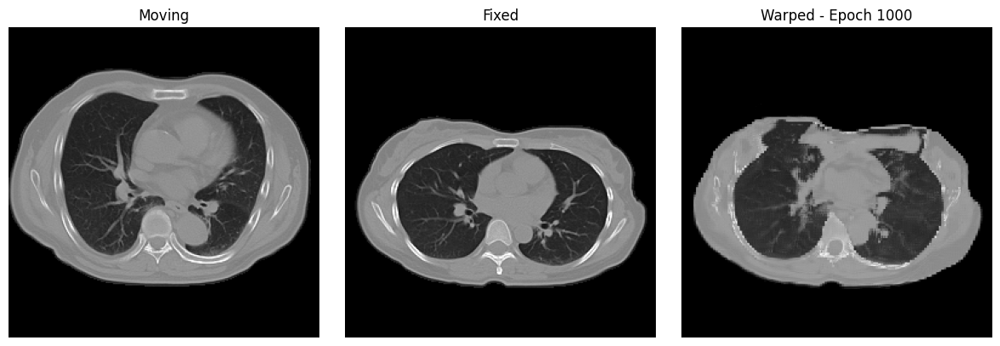

Checkpoint saved: finetune_checkpoints\finetune_epoch_01000.pth
Epoch 01100/30000, Loss: 0.00283848
Epoch 01200/30000, Loss: 0.00457516
Epoch 01300/30000, Loss: 0.00305175
Epoch 01400/30000, Loss: 0.00413802
Epoch 01500/30000, Loss: 0.00322737
Epoch 01600/30000, Loss: 0.00451252
Epoch 01700/30000, Loss: 0.00287303
Epoch 01800/30000, Loss: 0.00338370
Epoch 01900/30000, Loss: 0.00275891
Epoch 02000/30000, Loss: 0.00250305

Observation Epoch 2000
MSE      : 0.00396378
DVF mean : 5.6979
DVF P95  : 21.5271
DVF P99  : 36.2837
DVF max  : 46.5769


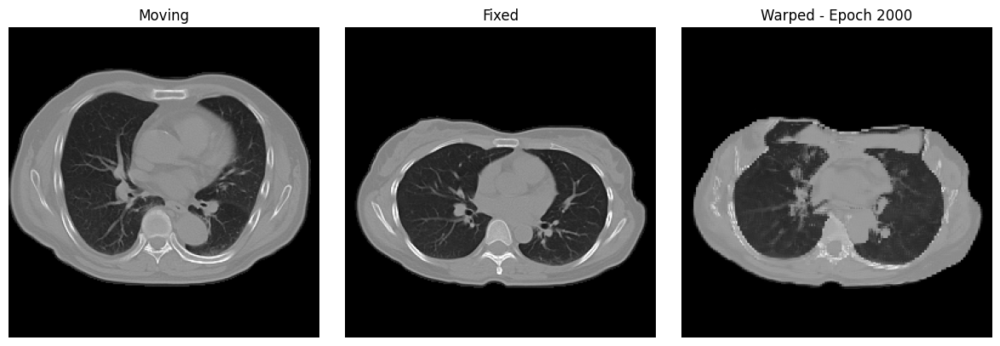

Checkpoint saved: finetune_checkpoints\finetune_epoch_02000.pth
Epoch 02100/30000, Loss: 0.00271258
Epoch 02200/30000, Loss: 0.00250158
Epoch 02300/30000, Loss: 0.00345764
Epoch 02400/30000, Loss: 0.00330617
Epoch 02500/30000, Loss: 0.00282092
Epoch 02600/30000, Loss: 0.00353375
Epoch 02700/30000, Loss: 0.00423699
Epoch 02800/30000, Loss: 0.00289858
Epoch 02900/30000, Loss: 0.00305481
Epoch 03000/30000, Loss: 0.00294992

Observation Epoch 3000
MSE      : 0.00363871
DVF mean : 5.7549
DVF P95  : 21.8308
DVF P99  : 36.3234
DVF max  : 46.4689


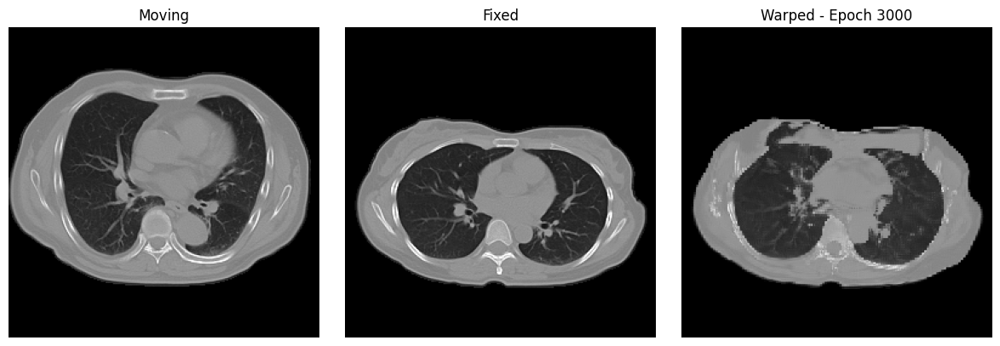

Checkpoint saved: finetune_checkpoints\finetune_epoch_03000.pth
Epoch 03100/30000, Loss: 0.00279081
Epoch 03200/30000, Loss: 0.00258190
Epoch 03300/30000, Loss: 0.00379386
Epoch 03400/30000, Loss: 0.00320968
Epoch 03500/30000, Loss: 0.00257163
Epoch 03600/30000, Loss: 0.00280704
Epoch 03700/30000, Loss: 0.00530430
Epoch 03800/30000, Loss: 0.00261461
Epoch 03900/30000, Loss: 0.00248144
Epoch 04000/30000, Loss: 0.00335789

Observation Epoch 4000
MSE      : 0.00331908
DVF mean : 6.4147
DVF P95  : 23.9289
DVF P99  : 42.6367
DVF max  : 52.7345


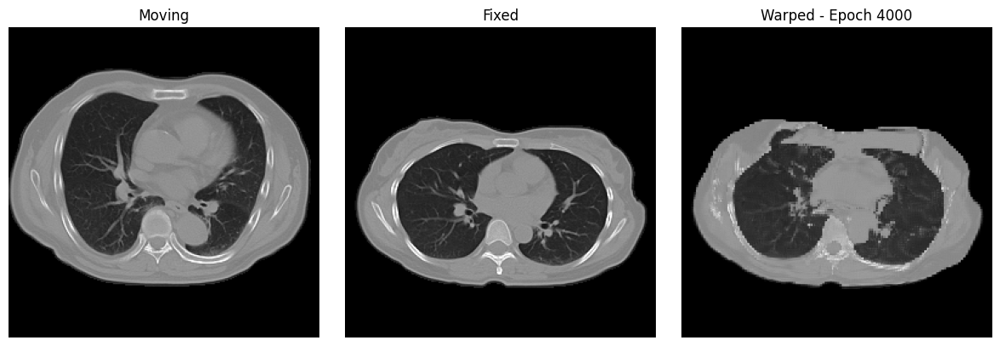

Checkpoint saved: finetune_checkpoints\finetune_epoch_04000.pth
Epoch 04100/30000, Loss: 0.00313618
Epoch 04200/30000, Loss: 0.00279012
Epoch 04300/30000, Loss: 0.00275503
Epoch 04400/30000, Loss: 0.00263290
Epoch 04500/30000, Loss: 0.00218771
Epoch 04600/30000, Loss: 0.00307697
Epoch 04700/30000, Loss: 0.00254626
Epoch 04800/30000, Loss: 0.00223147
Epoch 04900/30000, Loss: 0.00350715
Epoch 05000/30000, Loss: 0.00228429

Observation Epoch 5000
MSE      : 0.00320435
DVF mean : 5.9768
DVF P95  : 22.1032
DVF P99  : 39.6551
DVF max  : 49.3216


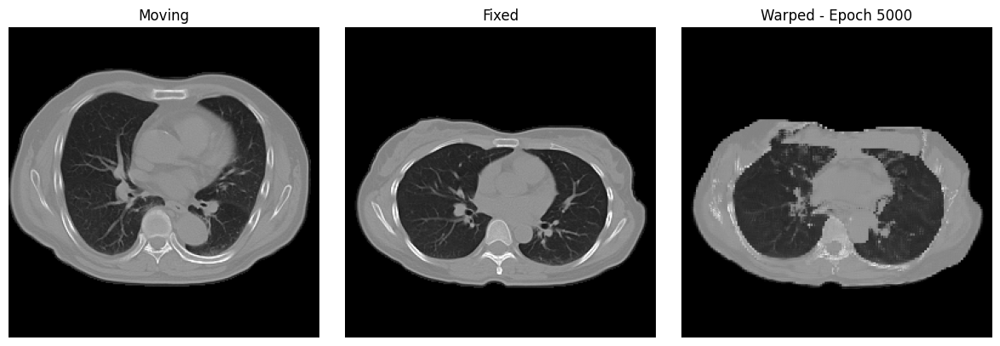

Checkpoint saved: finetune_checkpoints\finetune_epoch_05000.pth
Epoch 05100/30000, Loss: 0.00340611
Epoch 05200/30000, Loss: 0.00215422
Epoch 05300/30000, Loss: 0.00216950
Epoch 05400/30000, Loss: 0.00233646
Epoch 05500/30000, Loss: 0.00298416
Epoch 05600/30000, Loss: 0.00231196
Epoch 05700/30000, Loss: 0.00185476
Epoch 05800/30000, Loss: 0.00202243
Epoch 05900/30000, Loss: 0.00228772
Epoch 06000/30000, Loss: 0.00245412

Observation Epoch 6000
MSE      : 0.00323659
DVF mean : 5.8067
DVF P95  : 22.1480
DVF P99  : 42.4206
DVF max  : 54.7741


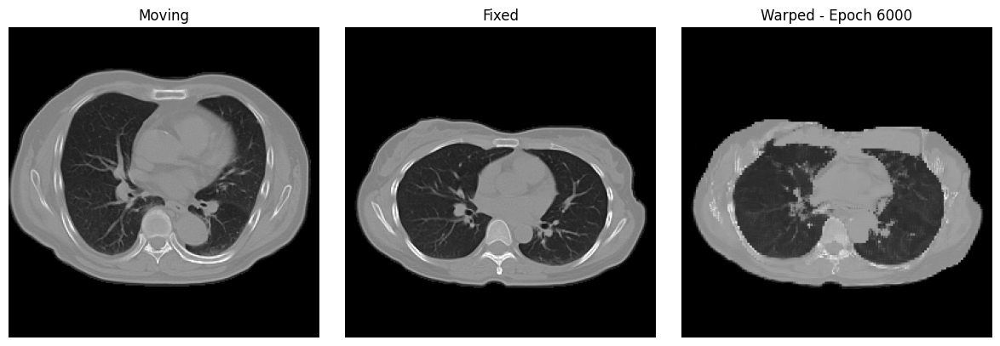

Checkpoint saved: finetune_checkpoints\finetune_epoch_06000.pth
Epoch 06100/30000, Loss: 0.00345412
Epoch 06200/30000, Loss: 0.00356279
Epoch 06300/30000, Loss: 0.00231260
Epoch 06400/30000, Loss: 0.00217407
Epoch 06500/30000, Loss: 0.00246398
Epoch 06600/30000, Loss: 0.00214780
Epoch 06700/30000, Loss: 0.00307701
Epoch 06800/30000, Loss: 0.00274308
Epoch 06900/30000, Loss: 0.00275315
Epoch 07000/30000, Loss: 0.00250852

Observation Epoch 7000
MSE      : 0.00307832
DVF mean : 5.9574
DVF P95  : 21.7543
DVF P99  : 39.6083
DVF max  : 50.4875


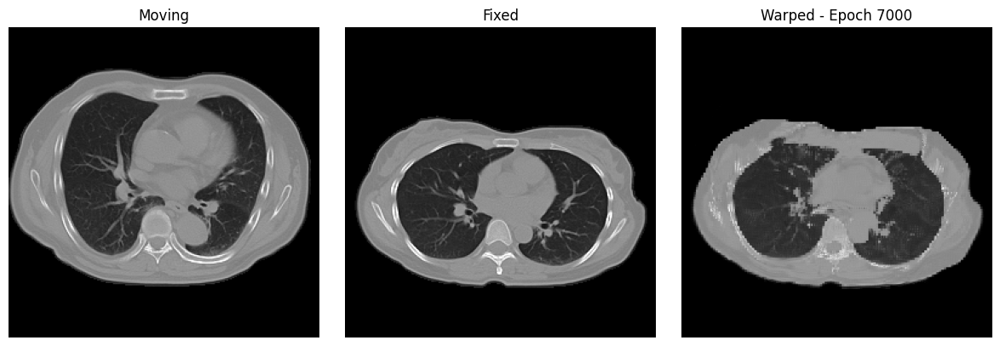

Checkpoint saved: finetune_checkpoints\finetune_epoch_07000.pth
Epoch 07100/30000, Loss: 0.00258505
Epoch 07200/30000, Loss: 0.00268372
Epoch 07300/30000, Loss: 0.00272845
Epoch 07400/30000, Loss: 0.00206796
Epoch 07500/30000, Loss: 0.00282077
Epoch 07600/30000, Loss: 0.00281364
Epoch 07700/30000, Loss: 0.00214062
Epoch 07800/30000, Loss: 0.00294427
Epoch 07900/30000, Loss: 0.00234168
Epoch 08000/30000, Loss: 0.00210998

Observation Epoch 8000
MSE      : 0.00306110
DVF mean : 5.9740
DVF P95  : 21.4606
DVF P99  : 39.5796
DVF max  : 49.4668


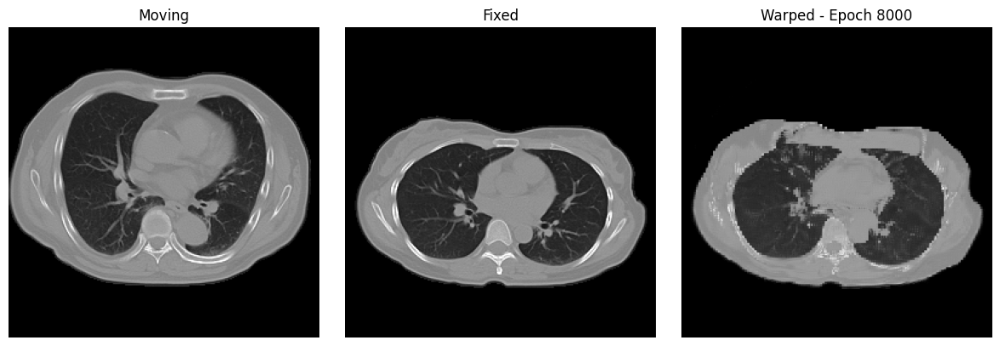

Checkpoint saved: finetune_checkpoints\finetune_epoch_08000.pth
Epoch 08100/30000, Loss: 0.00261201
Epoch 08200/30000, Loss: 0.00290552
Epoch 08300/30000, Loss: 0.00284186
Epoch 08400/30000, Loss: 0.00203670
Epoch 08500/30000, Loss: 0.00191360
Epoch 08600/30000, Loss: 0.00199942
Epoch 08700/30000, Loss: 0.00290358
Epoch 08800/30000, Loss: 0.00253143
Epoch 08900/30000, Loss: 0.00246608
Epoch 09000/30000, Loss: 0.00231365

Observation Epoch 9000
MSE      : 0.00301203
DVF mean : 5.6981
DVF P95  : 20.3147
DVF P99  : 39.1472
DVF max  : 50.6257


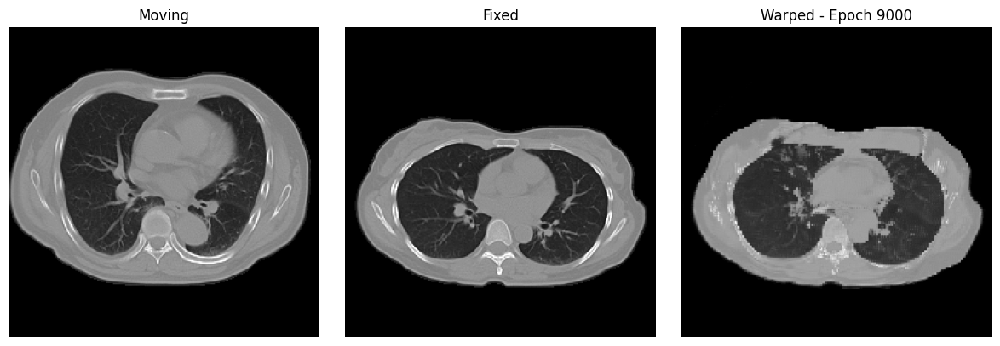

Checkpoint saved: finetune_checkpoints\finetune_epoch_09000.pth
Epoch 09100/30000, Loss: 0.00251655
Epoch 09200/30000, Loss: 0.00232212
Epoch 09300/30000, Loss: 0.00201609
Epoch 09400/30000, Loss: 0.00253693
Epoch 09500/30000, Loss: 0.00253763
Epoch 09600/30000, Loss: 0.00245641
Epoch 09700/30000, Loss: 0.00243273
Epoch 09800/30000, Loss: 0.00256213
Epoch 09900/30000, Loss: 0.00269520
Epoch 10000/30000, Loss: 0.00194568

Observation Epoch 10000
MSE      : 0.00295287
DVF mean : 6.1631
DVF P95  : 21.4586
DVF P99  : 40.7625
DVF max  : 51.1495


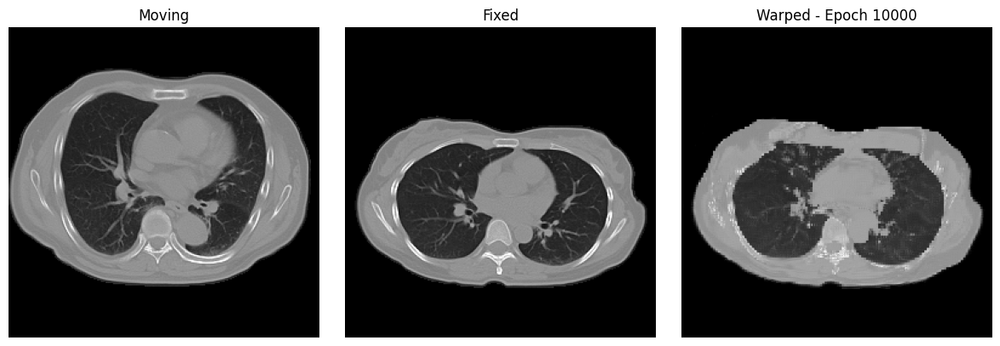

Checkpoint saved: finetune_checkpoints\finetune_epoch_10000.pth
Epoch 10100/30000, Loss: 0.00269489
Epoch 10200/30000, Loss: 0.00422404
Epoch 10300/30000, Loss: 0.00213578
Epoch 10400/30000, Loss: 0.00263945
Epoch 10500/30000, Loss: 0.00260678
Epoch 10600/30000, Loss: 0.00279559
Epoch 10700/30000, Loss: 0.00235469
Epoch 10800/30000, Loss: 0.00248171
Epoch 10900/30000, Loss: 0.00275031
Epoch 11000/30000, Loss: 0.00218977

Observation Epoch 11000
MSE      : 0.00290904
DVF mean : 5.9564
DVF P95  : 20.7458
DVF P99  : 40.1342
DVF max  : 50.6146


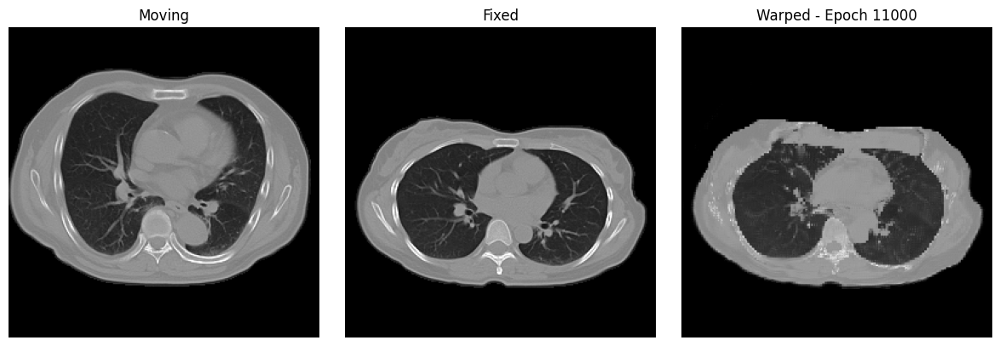

Checkpoint saved: finetune_checkpoints\finetune_epoch_11000.pth
Epoch 11100/30000, Loss: 0.00275203
Epoch 11200/30000, Loss: 0.00254519
Epoch 11300/30000, Loss: 0.00213180
Epoch 11400/30000, Loss: 0.00214624
Epoch 11500/30000, Loss: 0.00199306
Epoch 11600/30000, Loss: 0.00246008
Epoch 11700/30000, Loss: 0.00241562
Epoch 11800/30000, Loss: 0.00207712
Epoch 11900/30000, Loss: 0.00256604
Epoch 12000/30000, Loss: 0.00242158

Observation Epoch 12000
MSE      : 0.00286863
DVF mean : 5.8369
DVF P95  : 20.6439
DVF P99  : 39.9117
DVF max  : 51.4581


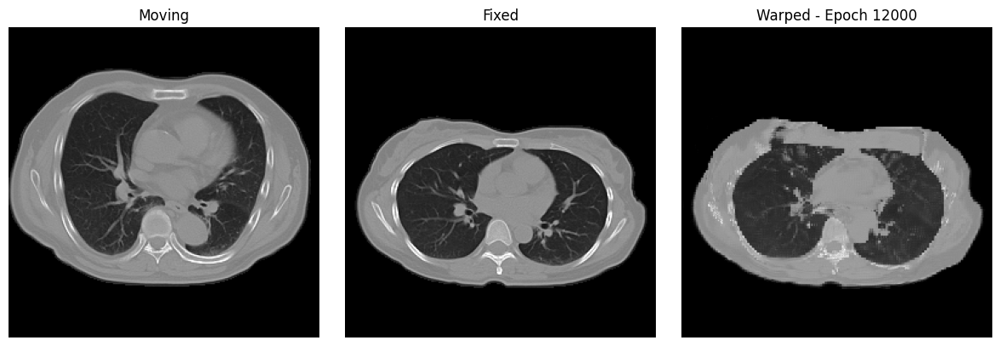

Checkpoint saved: finetune_checkpoints\finetune_epoch_12000.pth
Epoch 12100/30000, Loss: 0.00238361
Epoch 12200/30000, Loss: 0.00266676
Epoch 12300/30000, Loss: 0.00288072
Epoch 12400/30000, Loss: 0.00287225
Epoch 12500/30000, Loss: 0.00202286
Epoch 12600/30000, Loss: 0.00219230
Epoch 12700/30000, Loss: 0.00269770
Epoch 12800/30000, Loss: 0.00204395
Epoch 12900/30000, Loss: 0.00276849
Epoch 13000/30000, Loss: 0.00240190

Observation Epoch 13000
MSE      : 0.00286252
DVF mean : 5.7190
DVF P95  : 19.6100
DVF P99  : 37.6416
DVF max  : 49.0844


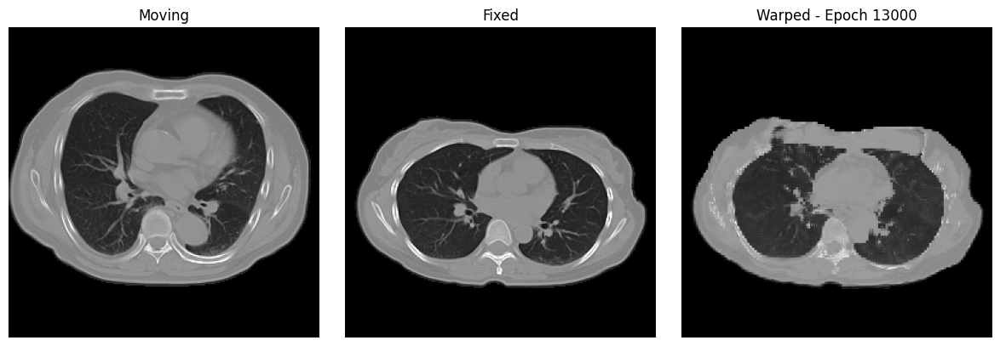

Checkpoint saved: finetune_checkpoints\finetune_epoch_13000.pth
Epoch 13100/30000, Loss: 0.00229553
Epoch 13200/30000, Loss: 0.00238309
Epoch 13300/30000, Loss: 0.00271158
Epoch 13400/30000, Loss: 0.00216250
Epoch 13500/30000, Loss: 0.00266080
Epoch 13600/30000, Loss: 0.00274969
Epoch 13700/30000, Loss: 0.00259729
Epoch 13800/30000, Loss: 0.00259534
Epoch 13900/30000, Loss: 0.00233846
Epoch 14000/30000, Loss: 0.00220329

Observation Epoch 14000
MSE      : 0.00277579
DVF mean : 5.6805
DVF P95  : 20.2666
DVF P99  : 38.7932
DVF max  : 50.5371


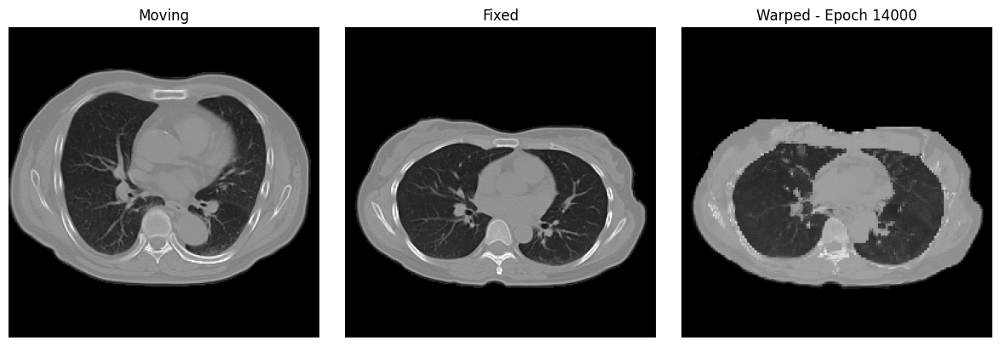

Checkpoint saved: finetune_checkpoints\finetune_epoch_14000.pth
Epoch 14100/30000, Loss: 0.00249241
Epoch 14200/30000, Loss: 0.00267137
Epoch 14300/30000, Loss: 0.00233124
Epoch 14400/30000, Loss: 0.00213938
Epoch 14500/30000, Loss: 0.00205256
Epoch 14600/30000, Loss: 0.00203310
Epoch 14700/30000, Loss: 0.00273407
Epoch 14800/30000, Loss: 0.00276181
Epoch 14900/30000, Loss: 0.00211100
Epoch 15000/30000, Loss: 0.00233050

Observation Epoch 15000
MSE      : 0.00277152
DVF mean : 5.8044
DVF P95  : 20.2567
DVF P99  : 38.4249
DVF max  : 49.1574


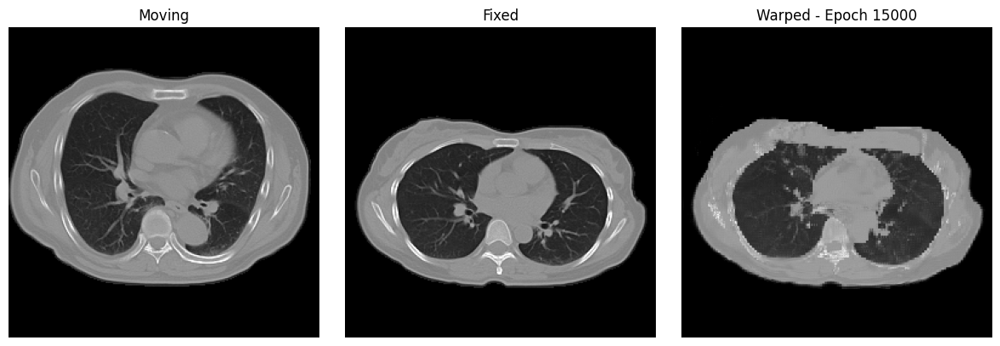

Checkpoint saved: finetune_checkpoints\finetune_epoch_15000.pth
Epoch 15100/30000, Loss: 0.00296831
Epoch 15200/30000, Loss: 0.00222199
Epoch 15300/30000, Loss: 0.00216332
Epoch 15400/30000, Loss: 0.00204799
Epoch 15500/30000, Loss: 0.00259547
Epoch 15600/30000, Loss: 0.00198901
Epoch 15700/30000, Loss: 0.00207138
Epoch 15800/30000, Loss: 0.00226429
Epoch 15900/30000, Loss: 0.00207616
Epoch 16000/30000, Loss: 0.00197331

Observation Epoch 16000
MSE      : 0.00275842
DVF mean : 5.7152
DVF P95  : 19.7364
DVF P99  : 37.4365
DVF max  : 49.2833


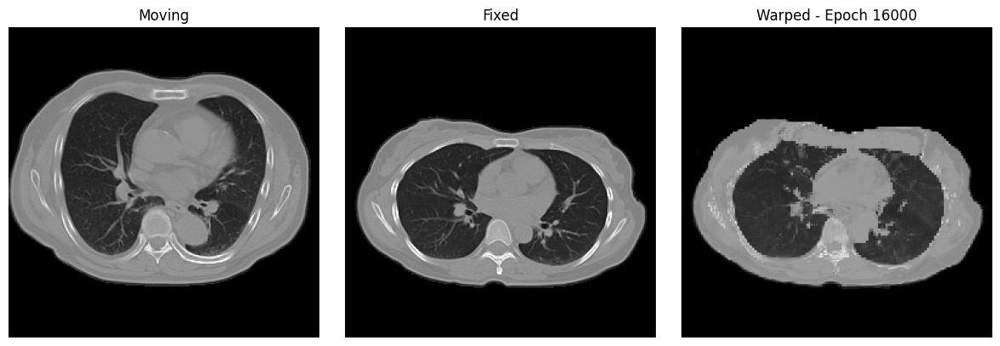

Checkpoint saved: finetune_checkpoints\finetune_epoch_16000.pth
Epoch 16100/30000, Loss: 0.00221501
Epoch 16200/30000, Loss: 0.00347132
Epoch 16300/30000, Loss: 0.00271343
Epoch 16400/30000, Loss: 0.00184474
Epoch 16500/30000, Loss: 0.00187199
Epoch 16600/30000, Loss: 0.00243560
Epoch 16700/30000, Loss: 0.00191401
Epoch 16800/30000, Loss: 0.00217059
Epoch 16900/30000, Loss: 0.00235371
Epoch 17000/30000, Loss: 0.00266544

Observation Epoch 17000
MSE      : 0.00275321
DVF mean : 5.5980
DVF P95  : 19.0690
DVF P99  : 36.2498
DVF max  : 47.4621


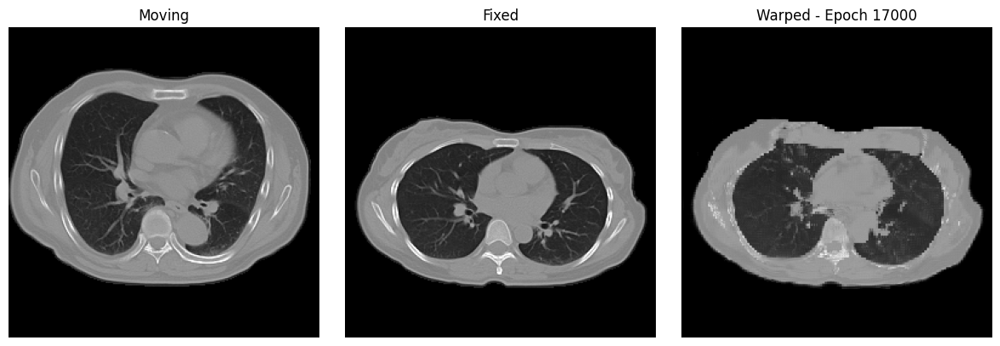

Checkpoint saved: finetune_checkpoints\finetune_epoch_17000.pth
Epoch 17100/30000, Loss: 0.00198979
Epoch 17200/30000, Loss: 0.00151708
Epoch 17300/30000, Loss: 0.00211163
Epoch 17400/30000, Loss: 0.00245404
Epoch 17500/30000, Loss: 0.00194694
Epoch 17600/30000, Loss: 0.00221866
Epoch 17700/30000, Loss: 0.00190723
Epoch 17800/30000, Loss: 0.00159166
Epoch 17900/30000, Loss: 0.00217102
Epoch 18000/30000, Loss: 0.00207232

Observation Epoch 18000
MSE      : 0.00271630
DVF mean : 5.5611
DVF P95  : 19.3967
DVF P99  : 35.6951
DVF max  : 45.3298


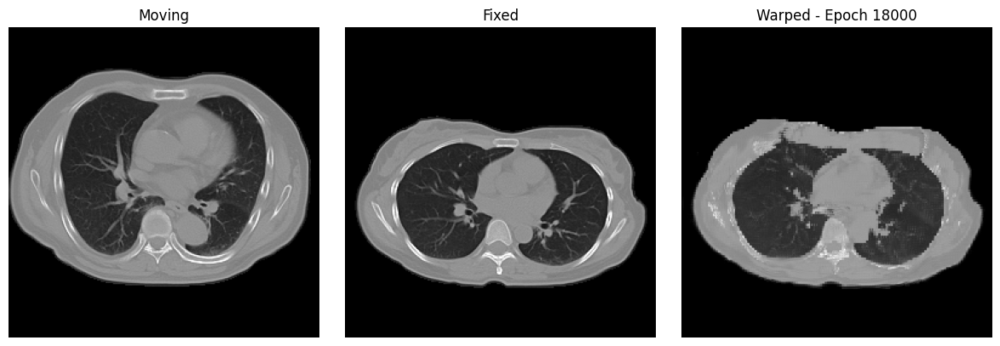

Checkpoint saved: finetune_checkpoints\finetune_epoch_18000.pth
Epoch 18100/30000, Loss: 0.00232735
Epoch 18200/30000, Loss: 0.00212629
Epoch 18300/30000, Loss: 0.00186068
Epoch 18400/30000, Loss: 0.00210949
Epoch 18500/30000, Loss: 0.00212892
Epoch 18600/30000, Loss: 0.00275132
Epoch 18700/30000, Loss: 0.00237909
Epoch 18800/30000, Loss: 0.00243190
Epoch 18900/30000, Loss: 0.00224950
Epoch 19000/30000, Loss: 0.00202728

Observation Epoch 19000
MSE      : 0.00268905
DVF mean : 5.6246
DVF P95  : 19.2459
DVF P99  : 34.7163
DVF max  : 45.9196


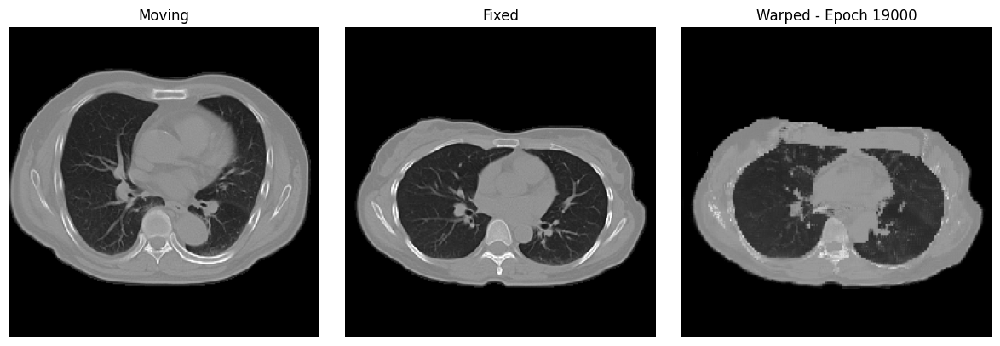

Checkpoint saved: finetune_checkpoints\finetune_epoch_19000.pth
Epoch 19100/30000, Loss: 0.00238409
Epoch 19200/30000, Loss: 0.00199682
Epoch 19300/30000, Loss: 0.00360260
Epoch 19400/30000, Loss: 0.00250821
Epoch 19500/30000, Loss: 0.00231293
Epoch 19600/30000, Loss: 0.00247483
Epoch 19700/30000, Loss: 0.00202669
Epoch 19800/30000, Loss: 0.00206028
Epoch 19900/30000, Loss: 0.00215154
Epoch 20000/30000, Loss: 0.00248141

Observation Epoch 20000
MSE      : 0.00267345
DVF mean : 5.6356
DVF P95  : 19.2515
DVF P99  : 34.9619
DVF max  : 44.8768


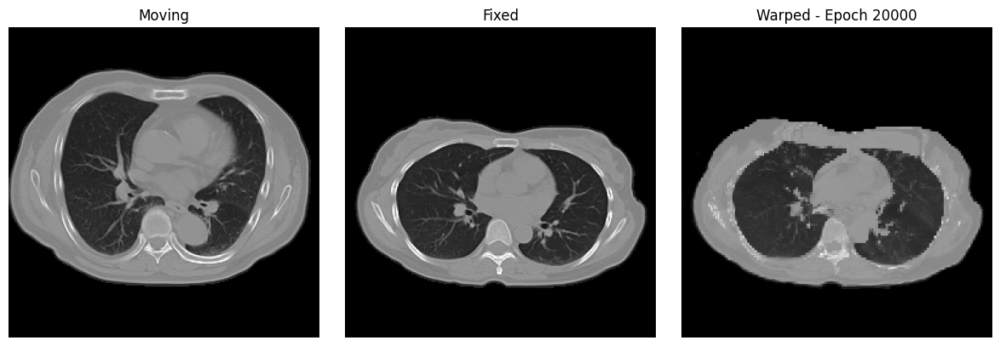

Checkpoint saved: finetune_checkpoints\finetune_epoch_20000.pth
Epoch 20100/30000, Loss: 0.00277019
Epoch 20200/30000, Loss: 0.00185130
Epoch 20300/30000, Loss: 0.00227155
Epoch 20400/30000, Loss: 0.00194202
Epoch 20500/30000, Loss: 0.00221085
Epoch 20600/30000, Loss: 0.00273111
Epoch 20700/30000, Loss: 0.00216851
Epoch 20800/30000, Loss: 0.00210534
Epoch 20900/30000, Loss: 0.00214702
Epoch 21000/30000, Loss: 0.00181426

Observation Epoch 21000
MSE      : 0.00265965
DVF mean : 5.6745
DVF P95  : 19.0392
DVF P99  : 34.4000
DVF max  : 44.2935


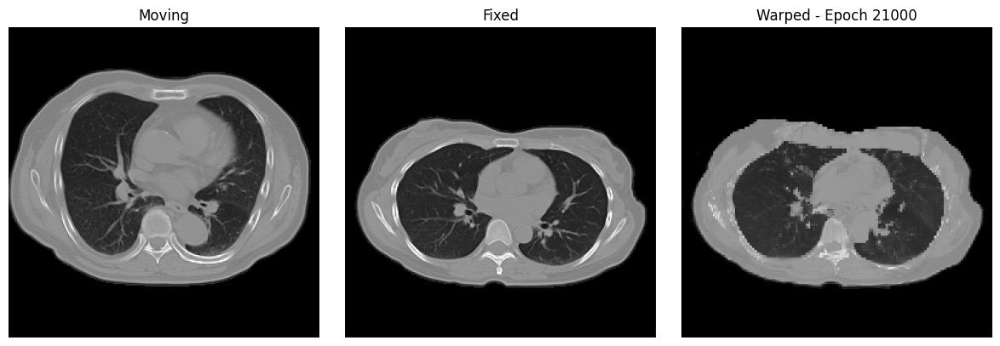

Checkpoint saved: finetune_checkpoints\finetune_epoch_21000.pth
Epoch 21100/30000, Loss: 0.00214682
Epoch 21200/30000, Loss: 0.00190399
Epoch 21300/30000, Loss: 0.00229166
Epoch 21400/30000, Loss: 0.00209722
Epoch 21500/30000, Loss: 0.00229084
Epoch 21600/30000, Loss: 0.00223288
Epoch 21700/30000, Loss: 0.00221143
Epoch 21800/30000, Loss: 0.00215666
Epoch 21900/30000, Loss: 0.00179636
Epoch 22000/30000, Loss: 0.00197651

Observation Epoch 22000
MSE      : 0.00264810
DVF mean : 5.4742
DVF P95  : 18.9208
DVF P99  : 33.8082
DVF max  : 44.0037


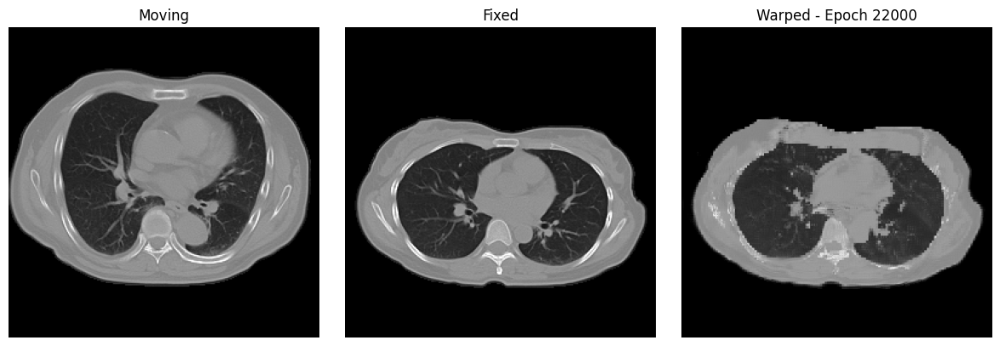

Checkpoint saved: finetune_checkpoints\finetune_epoch_22000.pth
Epoch 22100/30000, Loss: 0.00210779
Epoch 22200/30000, Loss: 0.00259482
Epoch 22300/30000, Loss: 0.00225627
Epoch 22400/30000, Loss: 0.00173893
Epoch 22500/30000, Loss: 0.00184501
Epoch 22600/30000, Loss: 0.00239607
Epoch 22700/30000, Loss: 0.00250223
Epoch 22800/30000, Loss: 0.00228591
Epoch 22900/30000, Loss: 0.00211456
Epoch 23000/30000, Loss: 0.00254940

Observation Epoch 23000
MSE      : 0.00268586
DVF mean : 5.2708
DVF P95  : 17.9607
DVF P99  : 32.7959
DVF max  : 45.6911


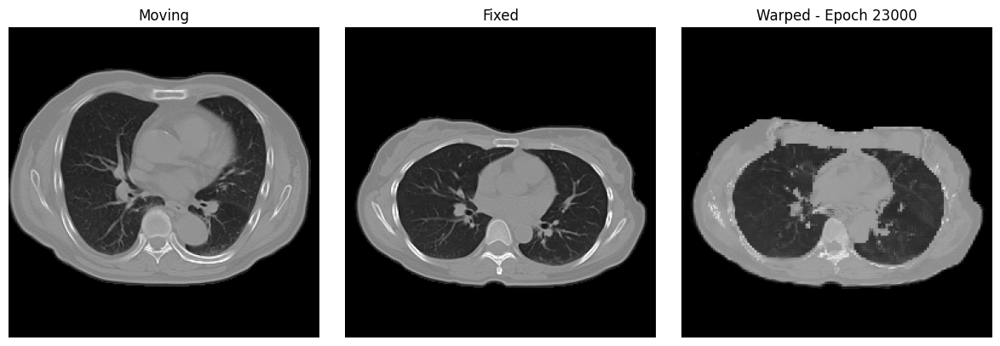

Checkpoint saved: finetune_checkpoints\finetune_epoch_23000.pth
Epoch 23100/30000, Loss: 0.00221951
Epoch 23200/30000, Loss: 0.00233901
Epoch 23300/30000, Loss: 0.00205365
Epoch 23400/30000, Loss: 0.00236210
Epoch 23500/30000, Loss: 0.00199213
Epoch 23600/30000, Loss: 0.00315949
Epoch 23700/30000, Loss: 0.00213220
Epoch 23800/30000, Loss: 0.00214783
Epoch 23900/30000, Loss: 0.00210579
Epoch 24000/30000, Loss: 0.00221983

Observation Epoch 24000
MSE      : 0.00260745
DVF mean : 5.6262
DVF P95  : 18.6947
DVF P99  : 33.3833
DVF max  : 44.7669


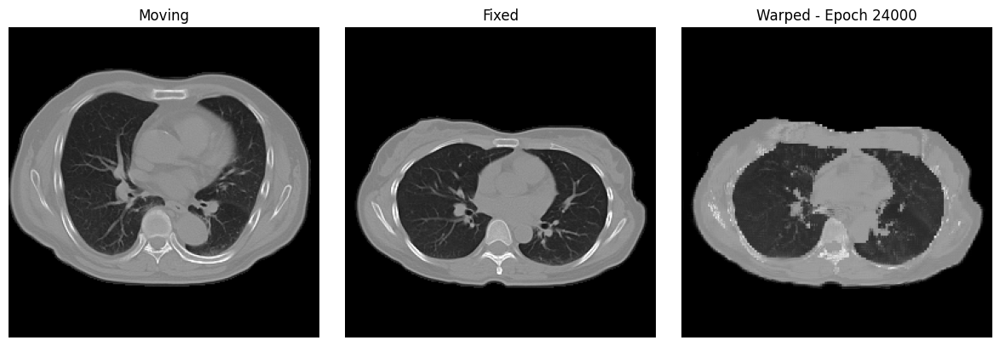

Checkpoint saved: finetune_checkpoints\finetune_epoch_24000.pth
Epoch 24100/30000, Loss: 0.00259781
Epoch 24200/30000, Loss: 0.00182155
Epoch 24300/30000, Loss: 0.00214066
Epoch 24400/30000, Loss: 0.00195964
Epoch 24500/30000, Loss: 0.00252131
Epoch 24600/30000, Loss: 0.00206782
Epoch 24700/30000, Loss: 0.00182693
Epoch 24800/30000, Loss: 0.00178049
Epoch 24900/30000, Loss: 0.00223028
Epoch 25000/30000, Loss: 0.00182992

Observation Epoch 25000
MSE      : 0.00259743
DVF mean : 5.5752
DVF P95  : 18.5290
DVF P99  : 33.1086
DVF max  : 44.2375


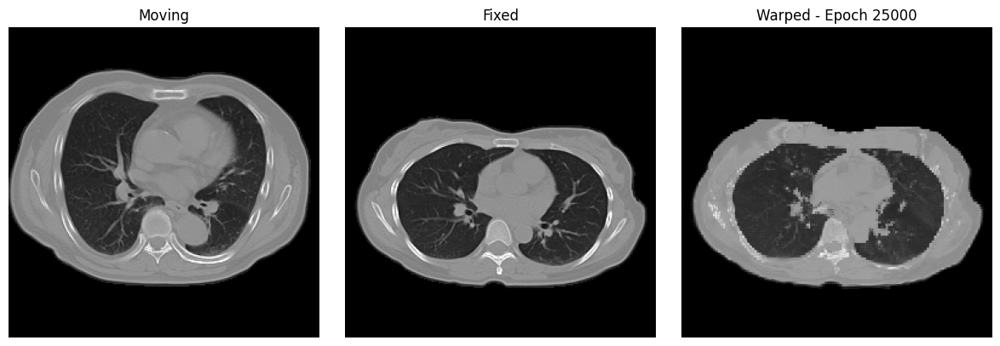

Checkpoint saved: finetune_checkpoints\finetune_epoch_25000.pth
Epoch 25100/30000, Loss: 0.00242629
Epoch 25200/30000, Loss: 0.00263352
Epoch 25300/30000, Loss: 0.00259679
Epoch 25400/30000, Loss: 0.00267958
Epoch 25500/30000, Loss: 0.00192886
Epoch 25600/30000, Loss: 0.00209346
Epoch 25700/30000, Loss: 0.00192420
Epoch 25800/30000, Loss: 0.00250802
Epoch 25900/30000, Loss: 0.00210510
Epoch 26000/30000, Loss: 0.00273161

Observation Epoch 26000
MSE      : 0.00260466
DVF mean : 5.5452
DVF P95  : 18.2147
DVF P99  : 33.0646
DVF max  : 45.4075


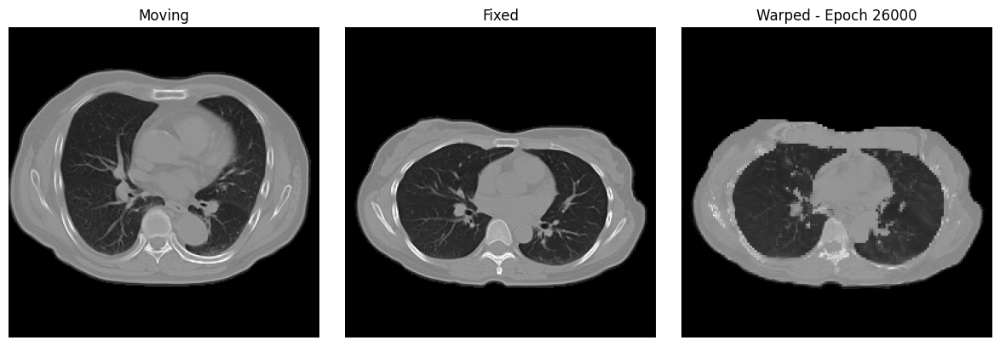

Checkpoint saved: finetune_checkpoints\finetune_epoch_26000.pth
Epoch 26100/30000, Loss: 0.00178340
Epoch 26200/30000, Loss: 0.00231621


KeyboardInterrupt: 

In [ ]:
from tqdm.notebook import tqdm
import os
import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

PRETRAINED_PATH = Path(
    "model_DVF_pretrain_final.pth"
)

LATEST_PATH = Path(
    "model_analysis_DVF_finetuned_latest.pth"
)

FINAL_PATH = Path(
    "model_analysis_DVF_finetuned_final.pth"
)

CHECKPOINT_DIR = Path(
    "finetune_checkpoints"
)

CHECKPOINT_DIR.mkdir(
    exist_ok=True
)

epochs = 30000

learning_rate = 1e-5

losses = []


# ============================================================
# 1. 8万epochの事前学習済み重みを確認
# ============================================================

if not PRETRAINED_PATH.exists():

    raise FileNotFoundError(
        f"事前学習済み重みが見つかりません: "
        f"{PRETRAINED_PATH.resolve()}"
    )


print("=" * 70)
print("Pretrained model")
print("=" * 70)

print(
    "Path :",
    PRETRAINED_PATH.resolve()
)

print(
    "Size :",
    PRETRAINED_PATH.stat().st_size / 1024**2,
    "MB"
)


# ============================================================
# 2. 事前学習時と同一構造のVoxelMorph
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# 3. Pretrained weights load
# ============================================================

pretrained_state = torch.load(
    PRETRAINED_PATH,
    map_location=device,
    weights_only=True
)


# ------------------------------------------------------------
# weights-only / checkpoint形式の両方に対応
# ------------------------------------------------------------

if (
    isinstance(pretrained_state, dict)
    and "model_state_dict" in pretrained_state
):

    model3D.load_state_dict(
        pretrained_state["model_state_dict"]
    )

else:

    model3D.load_state_dict(
        pretrained_state
    )


print(
    f"Loaded pretrained model: "
    f"{PRETRAINED_PATH.resolve()}"
)


# ============================================================
# 4. Fine-tuning optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=learning_rate
)


# ============================================================
# 5. AMP GradScaler
# ============================================================

use_amp = torch.cuda.is_available()

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# 6. CUDA / cuDNN / TF32
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


print()
print("=" * 70)
print("Environment")
print("=" * 70)

print(
    "AMP enabled :",
    use_amp
)

if torch.cuda.is_available():

    print(
        "GPU :",
        torch.cuda.get_device_name(0)
    )

    print(
        "TF32 matmul :",
        torch.backends.cuda.matmul.allow_tf32
    )

    print(
        "TF32 cuDNN  :",
        torch.backends.cudnn.allow_tf32
    )


# ============================================================
# 7. Wavelet-space Spatial Transformer
# ============================================================

transformer = vxm.layers.SpatialTransformer(
    (64, 128, 128)
).to(device)


# ============================================================
# 8. 固定観察ペアを1組作る
# ============================================================

# 学習用とは別に観察用generatorを作る
obs_generator = vxm_data_generator(
    x_train,
    batch_size=2
)

# 観察用ペアを1バッチ取得
obs_batch, _ = next(obs_generator)

# ------------------------------------------------------------
# Moving
# ------------------------------------------------------------
if torch.is_tensor(obs_batch[0]):
    obs_moving = obs_batch[0].float().to(device)
else:
    obs_moving = torch.from_numpy(
        obs_batch[0]
    ).float().to(device)

# ------------------------------------------------------------
# Fixed
# ------------------------------------------------------------
if torch.is_tensor(obs_batch[1]):
    obs_fixed = obs_batch[1].float().to(device)
else:
    obs_fixed = torch.from_numpy(
        obs_batch[1]
    ).float().to(device)

print("Observation pair created")
print("Moving:", obs_moving.shape)
print("Fixed :", obs_fixed.shape)


# ------------------------------------------------------------
# 観察では1症例目だけ固定
# ------------------------------------------------------------

obs_moving = obs_moving[
    0:1
].detach()

obs_fixed = obs_fixed[
    0:1
].detach()


print()
print("=" * 70)
print("Fixed observation pair")
print("=" * 70)

print(
    "Moving :",
    obs_moving.shape
)

print(
    "Fixed  :",
    obs_fixed.shape
)


# ============================================================
# 9. 固定観察ペアのWavelet係数を先に計算
#
# 毎回同じなので1000epochごとに再計算する必要がない
# ============================================================

with torch.no_grad():

    obs_moving_analysis = analysis_filter_3d(
        obs_moving,
        analysis
    )

    obs_fixed_analysis = analysis_filter_3d(
        obs_fixed,
        analysis
    )

    obs_moving_w = down_sampling_3d(
        obs_moving_analysis
    ).to(device)

    obs_fixed_w = down_sampling_3d(
        obs_fixed_analysis
    ).to(device)


print(
    "Moving wavelet :",
    obs_moving_w.shape
)

print(
    "Fixed wavelet  :",
    obs_fixed_w.shape
)


# ============================================================
# 10. 観察履歴
# ============================================================

observation_history = []


# ============================================================
# 11. Fine-tuning
# ============================================================

model3D.train()


for epoch in tqdm(
    range(epochs)
):

    # ========================================================
    # Data
    # ========================================================

    try:
        train_batch, _ = next(train_generator)

    except StopIteration:
        # generatorを最初から作り直す
        train_generator = vxm_data_generator(
            x_train,
            batch_size=2
        )

        train_batch, _ = next(train_generator)

    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = train_batch[0].to(
            device=device,
            dtype=torch.float32
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    # --------------------------------------------------------
    # Fixed
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[1]
    ):

        fixed_images = train_batch[1].to(
            device=device,
            dtype=torch.float32
        )

    else:

        fixed_images = torch.as_tensor(
            train_batch[1],
            dtype=torch.float32,
            device=device
        )


    # ========================================================
    # Wavelet Analysis
    #
    # FP32で実行
    # ========================================================

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )

    fixed_analysis = analysis_filter_3d(
        fixed_images,
        analysis
    )


    # ========================================================
    # Down Sampling
    #
    # (B, 8, 128,256,256)
    # ↓
    # (B, 8, 64,128,128)
    # ========================================================

    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    fixed_w = down_sampling_3d(
        fixed_analysis
    ).to(device)


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # AMP Forward
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):

        # ----------------------------------------------------
        # VoxelMorph
        #
        # Vec:
        # (B, 3, 64,128,128)
        #
        # ※ Fine-tuning / Validationでは /2 しない
        # ----------------------------------------------------

        Vec = model3D(
            moving_w,
            fixed_w
        )


        # ----------------------------------------------------
        # Wavelet-space deformation
        # ----------------------------------------------------

        moving_warped = transformer(
            moving_w,
            Vec
        )


        # ----------------------------------------------------
        # Zero-insertion Upsampling
        # ----------------------------------------------------

        moving_warped_up = up_sampling_3d(
            moving_warped
        )


        # ----------------------------------------------------
        # Synthesis Filter
        # ----------------------------------------------------

        transformed_image, filtered_bands = (
            synthesis_filter_3d(
                moving_warped_up,
                synthesis_filters
            )
        )


        # ----------------------------------------------------
        # Fine-tuning Loss
        #
        # 現在は画像MSEのみ
        # ----------------------------------------------------

        loss = MSE_Loss(
            fixed_images,
            transformed_image
        )


    # ========================================================
    # AMP Backward
    # ========================================================

    scaler.scale(
        loss
    ).backward()


    # ========================================================
    # Optimizer Step
    # ========================================================

    scaler.step(
        optimizer
    )

    scaler.update()


    # ========================================================
    # Loss history
    # ========================================================

    loss_value = (
        loss
        .detach()
        .float()
        .cpu()
        .item()
    )

    losses.append(
        loss_value
    )


    # ========================================================
    # 100 epochごと
    #
    # Log + latest checkpoint
    # ========================================================

    if (epoch + 1) % 100 == 0:

        print(
            f"Epoch {epoch + 1:05d}/{epochs}, "
            f"Loss: {loss_value:.8f}"
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "loss":
                    loss_value,

                "learning_rate":
                    learning_rate,
            },
            LATEST_PATH
        )


    # ========================================================
    # 1000 epochごと
    #
    # 固定観察ペアによる評価
    # ========================================================

    if (epoch + 1) % 1000 == 0:

        # ----------------------------------------------------
        # Evaluation mode
        # ----------------------------------------------------

        model3D.eval()


        with torch.no_grad():

            # =================================================
            # Predict DVF
            # =================================================

            obs_vec = model3D(
                obs_moving_w,
                obs_fixed_w
            )


            # =================================================
            # Warp Wavelet coefficients
            # =================================================

            obs_moving_warped = transformer(
                obs_moving_w,
                obs_vec
            )


            # =================================================
            # Upsampling
            # =================================================

            obs_moving_warped_up = (
                up_sampling_3d(
                    obs_moving_warped
                )
            )


            # =================================================
            # Reconstruction
            # =================================================

            (
                obs_transformed,
                _
            ) = synthesis_filter_3d(
                obs_moving_warped_up,
                synthesis_filters
            )


            # =================================================
            # Image MSE
            # =================================================

            obs_mse = torch.mean(
                (
                    obs_fixed
                    - obs_transformed
                ) ** 2
            ).item()


            # =================================================
            # DVF statistics
            #
            # Wavelet空間
            # (64,128,128) voxel単位
            # =================================================

            obs_flow_np = (
                obs_vec
                .detach()
                .float()
                .cpu()
                .numpy()
            )


            # -------------------------------------------------
            # 3方向ベクトルの大きさ
            # -------------------------------------------------

            obs_flow_mag = np.sqrt(
                np.sum(
                    obs_flow_np[0] ** 2,
                    axis=0
                )
            )


            dvf_mean = float(
                obs_flow_mag.mean()
            )

            dvf_p95 = float(
                np.percentile(
                    obs_flow_mag,
                    95
                )
            )

            dvf_p99 = float(
                np.percentile(
                    obs_flow_mag,
                    99
                )
            )

            dvf_max = float(
                obs_flow_mag.max()
            )


            # =================================================
            # Observation history
            # =================================================

            observation_history.append(
                {
                    "epoch":
                        epoch + 1,

                    "mse":
                        obs_mse,

                    "dvf_mean":
                        dvf_mean,

                    "dvf_p95":
                        dvf_p95,

                    "dvf_p99":
                        dvf_p99,

                    "dvf_max":
                        dvf_max,
                }
            )


            # =================================================
            # Print
            # =================================================

            print()
            print(
                "=" * 70
            )

            print(
                f"Observation Epoch "
                f"{epoch + 1}"
            )

            print(
                "=" * 70
            )

            print(
                f"MSE      : "
                f"{obs_mse:.8f}"
            )

            print(
                f"DVF mean : "
                f"{dvf_mean:.4f}"
            )

            print(
                f"DVF P95  : "
                f"{dvf_p95:.4f}"
            )

            print(
                f"DVF P99  : "
                f"{dvf_p99:.4f}"
            )

            print(
                f"DVF max  : "
                f"{dvf_max:.4f}"
            )


            # =================================================
            # Visualization
            # =================================================

            slice_idx = 64


            plt.figure(
                figsize=(12, 4)
            )


            # -------------------------------------------------
            # Moving
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                1
            )

            plt.imshow(
                obs_moving[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                "Moving"
            )

            plt.axis(
                "off"
            )


            # -------------------------------------------------
            # Fixed
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                2
            )

            plt.imshow(
                obs_fixed[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                "Fixed"
            )

            plt.axis(
                "off"
            )


            # -------------------------------------------------
            # Warped
            # -------------------------------------------------

            plt.subplot(
                1,
                3,
                3
            )

            plt.imshow(
                obs_transformed[
                    0,
                    0,
                    slice_idx
                ]
                .detach()
                .float()
                .cpu(),
                cmap="gray"
            )

            plt.title(
                f"Warped - Epoch "
                f"{epoch + 1}"
            )

            plt.axis(
                "off"
            )


            plt.tight_layout()

            plt.show()


        # ----------------------------------------------------
        # Training modeへ戻す
        # ----------------------------------------------------

        model3D.train()


    # ========================================================
    # 1000 epochごとの履歴checkpoint
    # ========================================================

    if (epoch + 1) % 1000 == 0:

        checkpoint_path = (
            CHECKPOINT_DIR
            / (
                f"finetune_epoch_"
                f"{epoch + 1:05d}.pth"
            )
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "loss":
                    loss_value,

                "observation_history":
                    observation_history,

                "learning_rate":
                    learning_rate,
            },
            checkpoint_path
        )


        print(
            f"Checkpoint saved: "
            f"{checkpoint_path}"
        )


# ============================================================
# 12. Final save
# ============================================================

torch.save(
    model3D.state_dict(),
    FINAL_PATH
)


print()
print("=" * 70)
print("Fine-tuning completed")
print("=" * 70)

print(
    "Final model :",
    FINAL_PATH.resolve()
)


# ============================================================
# 13. Loss curve
# ============================================================

plt.figure(
    figsize=(10, 4)
)

plt.plot(
    np.arange(
        1,
        len(losses) + 1
    ),
    losses
)

plt.xlabel(
    "Epoch"
)

plt.ylabel(
    "Training MSE"
)

plt.title(
    "Fine-tuning Loss"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()

plt.show()


# ============================================================
# 14. Observation history
# ============================================================

if len(
    observation_history
) > 0:

    obs_epochs = [
        x["epoch"]
        for x
        in observation_history
    ]

    obs_mses = [
        x["mse"]
        for x
        in observation_history
    ]

    obs_dvf_mean = [
        x["dvf_mean"]
        for x
        in observation_history
    ]

    obs_dvf_p95 = [
        x["dvf_p95"]
        for x
        in observation_history
    ]

    obs_dvf_p99 = [
        x["dvf_p99"]
        for x
        in observation_history
    ]

    obs_dvf_max = [
        x["dvf_max"]
        for x
        in observation_history
    ]


    # --------------------------------------------------------
    # Fixed pair MSE
    # --------------------------------------------------------

    plt.figure(
        figsize=(8, 4)
    )

    plt.plot(
        obs_epochs,
        obs_mses,
        marker="o"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Fixed-pair MSE"
    )

    plt.title(
        "Observation Pair MSE"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # --------------------------------------------------------
    # DVF statistics
    # --------------------------------------------------------

    plt.figure(
        figsize=(9, 5)
    )

    plt.plot(
        obs_epochs,
        obs_dvf_mean,
        marker="o",
        label="Mean"
    )

    plt.plot(
        obs_epochs,
        obs_dvf_p95,
        marker="o",
        label="P95"
    )

    plt.plot(
        obs_epochs,
        obs_dvf_p99,
        marker="o",
        label="P99"
    )

    plt.plot(
        obs_epochs,
        obs_dvf_max,
        marker="o",
        label="Max"
    )

    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "DVF magnitude "
        "(wavelet voxel)"
    )

    plt.title(
        "Observation Pair DVF Statistics"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()

In [ ]:
# ============================================================
# Fast Fine-tuning
#
# 80k pretrained DVF model
# Different-patient registration
#
# Loss:
#   Image similarity
#   +
#   0.1 * DVF smoothness
#
# Lung mask:
#   Fixed lung mask
#
# Speed-up:
#   - GPU
#   - AMP
#   - TF32
#   - Observation Wavelet precompute
#   - No .item() every epoch
#   - Checkpoint every 1000 epochs
#   - Evaluation every 1000 epochs
# ============================================================

from tqdm.notebook import tqdm

import numpy as np
import torch
import torch.nn.functional as F
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

DATA_DIR = Path("Data")

RAW_DATA_PATH = (
    DATA_DIR
    / "TrainData_NoBed.npz"
)

PRETRAINED_PATH = Path(
    "model_DVF_pretrain_final.pth"
)

LATEST_PATH = Path(
    "model_DVF_finetuned_latest.pth"
)

FINAL_PATH = Path(
    "model_DVF_finetuned_final.pth"
)

CHECKPOINT_DIR = Path(
    "finetune_checkpoints_different_patients"
)

CHECKPOINT_DIR.mkdir(
    exist_ok=True
)


# ============================================================
# Training settings
# ============================================================

epochs = 30000

learning_rate = 1e-6

smoothness_weight = 0.1

batch_size = 2

log_every = 100

evaluation_every = 1000

checkpoint_every = 1000


# ============================================================
# CUDA
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


print("=" * 70)
print("DEVICE")
print("=" * 70)

print(
    "device:",
    device
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0)
            .total_memory
            / 1024**3,
            2
        ),
        "GB"
    )


# ============================================================
# Lung-masked archive candidates
# ============================================================

MASKED_ARCHIVE_CANDIDATES = [

    DATA_DIR
    / "TrainData_NoBed_LungMasked.npz",

    DATA_DIR
    / "TrainData_NoBed_lung_masked.npz",

    DATA_DIR
    / "TrainData_NoBed_Masked.npz",

    DATA_DIR
    / "TrainData_NoBed_masked.npz",
]


VOLUME_KEYS = (

    "Train_lung_masked",

    "train_lung_masked",

    "TrainMasked",

    "masked_train",

    "Train",
)


MASK_KEYS = (

    "Train_lung_mask",

    "train_lung_mask",

    "LungMask",

    "lung_mask",

    "TrainMask",

    "train_mask",

    "Mask",

    "mask",
)


# ============================================================
# 1. Utility
# ============================================================

def to_n_dhw(
    array,
    label
):

    array = np.asarray(
        array,
        dtype=np.float32
    )

    if array.ndim != 4:

        raise ValueError(
            f"{label} must be 4-D; "
            f"got {array.shape}"
        )


    # --------------------------------------------------------
    # (N,128,256,256)
    # --------------------------------------------------------

    if array.shape[1:] == (
        128,
        256,
        256
    ):

        return array


    # --------------------------------------------------------
    # (128,256,256,N)
    # --------------------------------------------------------

    if array.shape[:3] == (
        128,
        256,
        256
    ):

        return np.transpose(
            array,
            (3,0,1,2)
        )


    # --------------------------------------------------------
    # (N,256,256,128)
    # --------------------------------------------------------

    if array.shape[1:] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (0,3,1,2)
        )


    # --------------------------------------------------------
    # (256,256,128,N)
    # --------------------------------------------------------

    if array.shape[:3] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (3,2,0,1)
        )


    raise ValueError(
        f"{label} unsupported shape: "
        f"{array.shape}"
    )


# ============================================================
# 2. First available key
# ============================================================

def first_available_key(
    archive,
    candidates
):

    return next(
        (
            key
            for key in candidates
            if key in archive.files
        ),
        None
    )


# ============================================================
# 3. Load training data
# ============================================================

def load_lung_preferred_training_data():

    masked_path = next(
        (
            path
            for path
            in MASKED_ARCHIVE_CANDIDATES
            if path.exists()
        ),
        None
    )


    archive_path = (
        masked_path
        if masked_path is not None
        else RAW_DATA_PATH
    )


    if not archive_path.exists():

        raise FileNotFoundError(
            f"Training archive not found:\n"
            f"{archive_path.resolve()}"
        )


    with np.load(
        archive_path,
        allow_pickle=False
    ) as archive:


        volume_key = first_available_key(
            archive,
            VOLUME_KEYS
        )


        if volume_key is None:

            raise KeyError(
                f"No volume key in "
                f"{archive_path}\n"
                f"Available keys: "
                f"{archive.files}"
            )


        volumes = to_n_dhw(
            archive[volume_key],
            f"{archive_path}:"
            f"{volume_key}"
        )


        mask_key = first_available_key(
            archive,
            MASK_KEYS
        )


        if mask_key is None:

            masks = None

        else:

            masks = to_n_dhw(
                archive[mask_key],
                f"{archive_path}:"
                f"{mask_key}"
            )


    # ========================================================
    # Lung mask
    # ========================================================

    if masks is not None:


        if masks.shape != volumes.shape:

            raise ValueError(
                f"Volume/mask mismatch: "
                f"{volumes.shape} "
                f"vs "
                f"{masks.shape}"
            )


        masks = (
            masks > 0
        ).astype(
            np.float32
        )


        # ----------------------------------------------------
        # 入力画像もlung masked
        # ----------------------------------------------------

        volumes = (
            volumes
            *
            masks
        )


        print()
        print("=" * 70)
        print("LUNG MASK")
        print("=" * 70)

        print(
            "Archive:",
            archive_path
        )

        print(
            "Mask key:",
            mask_key
        )


    elif masked_path is not None:

        print()
        print(
            "Using pre-masked archive:"
        )

        print(
            archive_path
        )


    else:

        print()
        print(
            "WARNING: No lung mask found."
        )

        print(
            "Using unmasked volumes."
        )


    print()

    print(
        "Training volume shape:",
        volumes.shape
    )

    print(
        "Training volume dtype:",
        volumes.dtype
    )


    return (
        volumes,
        masks,
        archive_path
    )


# ============================================================
# 4. Different patient generator
#
# Moving != Fixed
#
# CPU側では必要なbatchだけ取得
# ============================================================

def different_patient_generator(
    volumes,
    masks=None,
    batch_size=2,
    seed=42
):

    n_patients = len(
        volumes
    )


    if n_patients < 2:

        raise ValueError(
            "At least 2 patients are required."
        )


    rng = np.random.default_rng(
        seed
    )


    while True:


        # ====================================================
        # Moving patient IDs
        # ====================================================

        moving_indices = rng.integers(
            0,
            n_patients,
            size=batch_size
        )


        # ====================================================
        # Fixed patient IDs
        # ====================================================

        fixed_indices = rng.integers(
            0,
            n_patients,
            size=batch_size
        )


        # ====================================================
        # Same patientを排除
        # ====================================================

        same = (
            moving_indices
            ==
            fixed_indices
        )


        while np.any(
            same
        ):


            fixed_indices[
                same
            ] = rng.integers(
                0,
                n_patients,
                size=int(
                    same.sum()
                )
            )


            same = (
                moving_indices
                ==
                fixed_indices
            )


        # ====================================================
        # NumPy -> Tensor
        # ====================================================

        moving = torch.from_numpy(
            volumes[
                moving_indices
            ]
        ).unsqueeze(
            1
        )


        fixed = torch.from_numpy(
            volumes[
                fixed_indices
            ]
        ).unsqueeze(
            1
        )


        if masks is None:

            fixed_mask = None

        else:

            fixed_mask = torch.from_numpy(
                masks[
                    fixed_indices
                ]
            ).unsqueeze(
                1
            )


        yield (
            moving,
            fixed,
            fixed_mask,
            moving_indices,
            fixed_indices
        )


# ============================================================
# 5. Masked MSE
# ============================================================

def masked_mse(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).square()


    if mask is None:

        return error.mean()


    return (
        error
        *
        mask
    ).sum() / (
        mask.sum()
        .clamp_min(
            eps
        )
    )


# ============================================================
# 6. Masked MAE
# ============================================================

def masked_mae(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).abs()


    if mask is None:

        return error.mean()


    return (
        error
        *
        mask
    ).sum() / (
        mask.sum()
        .clamp_min(
            eps
        )
    )


# ============================================================
# 7. DVF Smoothness
# ============================================================

def smoothness_loss(
    flow
):

    dz = (
        flow[
            :,
            :,
            1:,
            :,
            :
        ]
        -
        flow[
            :,
            :,
            :-1,
            :,
            :
        ]
    ).square().mean()


    dy = (
        flow[
            :,
            :,
            :,
            1:,
            :
        ]
        -
        flow[
            :,
            :,
            :,
            :-1,
            :
        ]
    ).square().mean()


    dx = (
        flow[
            :,
            :,
            :,
            :,
            1:
        ]
        -
        flow[
            :,
            :,
            :,
            :,
            :-1
        ]
    ).square().mean()


    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 8. Sharpness
# ============================================================

def gradient_sharpness(
    image
):

    dz = (
        image[
            :,
            :,
            1:,
            :,
            :
        ]
        -
        image[
            :,
            :,
            :-1,
            :,
            :
        ]
    ).abs().mean()


    dy = (
        image[
            :,
            :,
            :,
            1:,
            :
        ]
        -
        image[
            :,
            :,
            :,
            :-1,
            :
        ]
    ).abs().mean()


    dx = (
        image[
            :,
            :,
            :,
            :,
            1:
        ]
        -
        image[
            :,
            :,
            :,
            :,
            :-1
        ]
    ).abs().mean()


    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 9. Jacobian determinant
#
# VoxelMorph:
#
# flow[:,0] = z
# flow[:,1] = y
# flow[:,2] = x
#
# Spatial tensor:
#
# D,H,W = z,y,x
# ============================================================

def jacobian_determinant_3d(
    flow
):

    flow = flow.float()


    fz = flow[
        :,
        0
    ]

    fy = flow[
        :,
        1
    ]

    fx = flow[
        :,
        2
    ]


    # ========================================================
    # z-flow derivatives
    # ========================================================

    dfz_dz = (
        fz[
            :,
            2:,
            1:-1,
            1:-1
        ]
        -
        fz[
            :,
            :-2,
            1:-1,
            1:-1
        ]
    ) / 2.0


    dfz_dy = (
        fz[
            :,
            1:-1,
            2:,
            1:-1
        ]
        -
        fz[
            :,
            1:-1,
            :-2,
            1:-1
        ]
    ) / 2.0


    dfz_dx = (
        fz[
            :,
            1:-1,
            1:-1,
            2:
        ]
        -
        fz[
            :,
            1:-1,
            1:-1,
            :-2
        ]
    ) / 2.0


    # ========================================================
    # y-flow derivatives
    # ========================================================

    dfy_dz = (
        fy[
            :,
            2:,
            1:-1,
            1:-1
        ]
        -
        fy[
            :,
            :-2,
            1:-1,
            1:-1
        ]
    ) / 2.0


    dfy_dy = (
        fy[
            :,
            1:-1,
            2:,
            1:-1
        ]
        -
        fy[
            :,
            1:-1,
            :-2,
            1:-1
        ]
    ) / 2.0


    dfy_dx = (
        fy[
            :,
            1:-1,
            1:-1,
            2:
        ]
        -
        fy[
            :,
            1:-1,
            1:-1,
            :-2
        ]
    ) / 2.0


    # ========================================================
    # x-flow derivatives
    # ========================================================

    dfx_dz = (
        fx[
            :,
            2:,
            1:-1,
            1:-1
        ]
        -
        fx[
            :,
            :-2,
            1:-1,
            1:-1
        ]
    ) / 2.0


    dfx_dy = (
        fx[
            :,
            1:-1,
            2:,
            1:-1
        ]
        -
        fx[
            :,
            1:-1,
            :-2,
            1:-1
        ]
    ) / 2.0


    dfx_dx = (
        fx[
            :,
            1:-1,
            1:-1,
            2:
        ]
        -
        fx[
            :,
            1:-1,
            1:-1,
            :-2
        ]
    ) / 2.0


    # ========================================================
    # Jacobian
    # ========================================================

    J11 = (
        1.0
        +
        dfz_dz
    )

    J12 = dfz_dy

    J13 = dfz_dx


    J21 = dfy_dz

    J22 = (
        1.0
        +
        dfy_dy
    )

    J23 = dfy_dx


    J31 = dfx_dz

    J32 = dfx_dy

    J33 = (
        1.0
        +
        dfx_dx
    )


    detJ = (

        J11
        *
        (
            J22
            *
            J33

            -

            J23
            *
            J32
        )

        -

        J12
        *
        (
            J21
            *
            J33

            -

            J23
            *
            J31
        )

        +

        J13
        *
        (
            J21
            *
            J32

            -

            J22
            *
            J31
        )
    )


    return detJ


# ============================================================
# 10. Load Data
# ============================================================

(
    volumes,
    lung_masks,
    archive_path
) = load_lung_preferred_training_data()


finetune_generator = (
    different_patient_generator(
        volumes,
        masks=lung_masks,
        batch_size=batch_size,
        seed=42
    )
)


# ============================================================
# 11. Pretrained checkpoint check
# ============================================================

if not PRETRAINED_PATH.exists():

    raise FileNotFoundError(
        f"Pretrained model not found:\n"
        f"{PRETRAINED_PATH.resolve()}"
    )


print()
print("=" * 70)
print("PRETRAINED MODEL")
print("=" * 70)

print(
    PRETRAINED_PATH.resolve()
)


# ============================================================
# 12. Model
#
# IMPORTANT:
# 事前学習と完全に同じ構造
# ============================================================

model3D = (
    vxm.networks.VxmDense_128_256_256(
        (128,256,256),
        nb_features,
        int_steps=0
    )
    .to(
        device
    )
)


# ============================================================
# 13. Load pretrained weights
# ============================================================

try:

    pretrained_state = torch.load(
        PRETRAINED_PATH,
        map_location=device,
        weights_only=True
    )

except TypeError:

    pretrained_state = torch.load(
        PRETRAINED_PATH,
        map_location=device
    )


if (
    isinstance(
        pretrained_state,
        dict
    )
    and
    "model_state_dict"
    in pretrained_state
):

    model3D.load_state_dict(
        pretrained_state[
            "model_state_dict"
        ]
    )

else:

    model3D.load_state_dict(
        pretrained_state
    )


print(
    "80k pretrained model loaded."
)


# ============================================================
# 14. Spatial Transformer
# ============================================================

transformer = (
    vxm.layers.SpatialTransformer(
        (64,128,128)
    )
    .to(
        device
    )
)


# ============================================================
# 15. GPU check
# ============================================================

print()
print("=" * 70)
print("GPU CHECK")
print("=" * 70)

print(
    "Model device:",
    next(
        model3D.parameters()
    ).device
)

print(
    "CUDA:",
    torch.cuda.is_available()
)


# ============================================================
# 16. Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=learning_rate
)


# ============================================================
# 17. AMP
# ============================================================

use_amp = (
    torch.cuda.is_available()
)


scaler = (
    torch.cuda.amp.GradScaler(
        enabled=use_amp
    )
)


print(
    "AMP:",
    use_amp
)

print(
    "LR:",
    learning_rate
)

print(
    "Smoothness weight:",
    smoothness_weight
)


# ============================================================
# 18. Fixed Observation Pair
# ============================================================

(
    obs_moving_cpu,
    obs_fixed_cpu,
    obs_mask_cpu,
    obs_moving_ids,
    obs_fixed_ids
) = next(
    finetune_generator
)


# ------------------------------------------------------------
# 1 pairのみ使用
# ------------------------------------------------------------

obs_moving = (
    obs_moving_cpu[
        0:1
    ]
    .to(
        device=device,
        dtype=torch.float32
    )
)


obs_fixed = (
    obs_fixed_cpu[
        0:1
    ]
    .to(
        device=device,
        dtype=torch.float32
    )
)


if obs_mask_cpu is None:

    obs_mask = None

else:

    obs_mask = (
        obs_mask_cpu[
            0:1
        ]
        .to(
            device=device,
            dtype=torch.float32
        )
    )


print()
print("=" * 70)
print("OBSERVATION PAIR")
print("=" * 70)

print(
    "Moving patient:",
    int(
        obs_moving_ids[0]
    )
)

print(
    "Fixed patient :",
    int(
        obs_fixed_ids[0]
    )
)

print(
    "Moving:",
    obs_moving.shape
)

print(
    "Fixed :",
    obs_fixed.shape
)


# ============================================================
# 19. Observation Wavelet Precompute
#
# ★ 一度しか計算しない
# ============================================================

with torch.no_grad():


    obs_moving_analysis = (
        analysis_filter_3d(
            obs_moving,
            analysis
        )
    )


    obs_fixed_analysis = (
        analysis_filter_3d(
            obs_fixed,
            analysis
        )
    )


    obs_moving_w = (
        down_sampling_3d(
            obs_moving_analysis
        )
    )


    obs_fixed_w = (
        down_sampling_3d(
            obs_fixed_analysis
        )
    )


    del obs_moving_analysis

    del obs_fixed_analysis


print(
    "Observation Moving Wavelet:",
    obs_moving_w.shape
)

print(
    "Observation Fixed Wavelet :",
    obs_fixed_w.shape
)


# ============================================================
# 20. History
#
# 100epochごとのみ保存
# ============================================================

loss_epochs = []

losses = []

image_losses = []

smooth_losses = []

observation_history = []


# ============================================================
# 21. Training
# ============================================================

model3D.train()


for epoch in tqdm(
    range(
        1,
        epochs + 1
    ),
    desc="Fine-tuning"
):


    # ========================================================
    # Data
    # ========================================================

    (
        moving_cpu,
        fixed_cpu,
        fixed_mask_cpu,
        moving_ids,
        fixed_ids
    ) = next(
        finetune_generator
    )


    # ========================================================
    # CPU -> GPU
    # ========================================================

    moving_images = moving_cpu.to(
        device=device,
        dtype=torch.float32
    )


    fixed_images = fixed_cpu.to(
        device=device,
        dtype=torch.float32
    )


    if fixed_mask_cpu is None:

        fixed_mask = None

    else:

        fixed_mask = fixed_mask_cpu.to(
            device=device,
            dtype=torch.float32
        )


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # Forward
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # Analysis Filter
        # ====================================================

        moving_analysis = (
            analysis_filter_3d(
                moving_images,
                analysis
            )
        )


        fixed_analysis = (
            analysis_filter_3d(
                fixed_images,
                analysis
            )
        )


        # ====================================================
        # Downsample
        # ====================================================

        moving_w = (
            down_sampling_3d(
                moving_analysis
            )
        )


        fixed_w = (
            down_sampling_3d(
                fixed_analysis
            )
        )


        # ====================================================
        # DVF
        #
        # (B,3,64,128,128)
        #
        # Fine-tuningなので /2 はしない
        # ====================================================

        Vec = model3D(
            moving_w,
            fixed_w
        )


        # ====================================================
        # Warp all 8 bands
        # ====================================================

        moving_warped = (
            transformer(
                moving_w,
                Vec
            )
        )


        # ====================================================
        # Upsampling
        # ====================================================

        moving_warped_up = (
            up_sampling_3d(
                moving_warped
            )
        )


        # ====================================================
        # Synthesis
        # ====================================================

        (
            transformed_image,
            _
        ) = synthesis_filter_3d(
            moving_warped_up,
            synthesis_filters
        )


        # ====================================================
        # Image Loss
        # ====================================================

        loss_image = masked_mse(
            fixed_images,
            transformed_image,
            fixed_mask
        )


        # ====================================================
        # DVF Smoothness
        # ====================================================

        loss_smooth = (
            smoothness_loss(
                Vec
            )
        )


        # ====================================================
        # Total Loss
        # ====================================================

        loss = (

            loss_image

            +

            smoothness_weight
            *
            loss_smooth
        )


    # ========================================================
    # Backward
    # ========================================================

    scaler.scale(
        loss
    ).backward()


    # ========================================================
    # Gradient clipping
    # ========================================================

    scaler.unscale_(
        optimizer
    )


    torch.nn.utils.clip_grad_norm_(
        model3D.parameters(),
        max_norm=1.0
    )


    # ========================================================
    # Optimizer step
    # ========================================================

    scaler.step(
        optimizer
    )


    scaler.update()


    # ========================================================
    # GPU memory references cleanup
    #
    # empty_cache() は呼ばない
    #
    # empty_cache() は逆に遅くなる
    # ========================================================

    del moving_analysis

    del fixed_analysis

    del moving_w

    del fixed_w

    del moving_warped

    del moving_warped_up


    # ========================================================
    # Log
    #
    # ★ 毎epoch .item() しない
    #
    # 100epochごとのみGPU同期
    # ========================================================

    if (
        epoch
        %
        log_every
        ==
        0
    ):


        log_values = (
            torch.stack(
                [
                    loss.detach().float(),
                    loss_image.detach().float(),
                    loss_smooth.detach().float()
                ]
            )
            .cpu()
        )


        loss_value = float(
            log_values[0]
        )


        image_value = float(
            log_values[1]
        )


        smooth_value = float(
            log_values[2]
        )


        weighted_value = (
            smoothness_weight
            *
            smooth_value
        )


        loss_epochs.append(
            epoch
        )

        losses.append(
            loss_value
        )

        image_losses.append(
            image_value
        )

        smooth_losses.append(
            smooth_value
        )


        print(
            f"Epoch "
            f"{epoch:05d}/{epochs} | "
            f"total={loss_value:.8f} | "
            f"image={image_value:.8f} | "
            f"smooth={smooth_value:.8f} | "
            f"weighted={weighted_value:.8f}"
        )


    # ========================================================
    # Evaluation
    #
    # 1000 epoch
    # ========================================================

    if (
        epoch
        %
        evaluation_every
        ==
        0
    ):


        model3D.eval()


        with torch.inference_mode():


            # =================================================
            # AMP
            # =================================================

            with torch.cuda.amp.autocast(
                enabled=use_amp
            ):


                # =============================================
                # DVF
                #
                # Waveletは事前計算済み
                # =============================================

                obs_vec = model3D(
                    obs_moving_w,
                    obs_fixed_w
                )


                # =============================================
                # Warp
                # =============================================

                obs_warped_w = (
                    transformer(
                        obs_moving_w,
                        obs_vec
                    )
                )


                # =============================================
                # Upsample
                # =============================================

                obs_warped_up = (
                    up_sampling_3d(
                        obs_warped_w
                    )
                )


                # =============================================
                # Synthesis
                # =============================================

                (
                    obs_transformed,
                    _
                ) = synthesis_filter_3d(
                    obs_warped_up,
                    synthesis_filters
                )


            # =================================================
            # Evaluation FP32
            # =================================================

            obs_vec_float = (
                obs_vec.float()
            )


            obs_transformed_float = (
                obs_transformed.float()
            )


            # =================================================
            # MSE
            # =================================================

            obs_mse_tensor = (
                masked_mse(
                    obs_fixed,
                    obs_transformed_float,
                    obs_mask
                )
            )


            # =================================================
            # MAE
            # =================================================

            obs_mae_tensor = (
                masked_mae(
                    obs_fixed,
                    obs_transformed_float,
                    obs_mask
                )
            )


            # =================================================
            # Sharpness
            # =================================================

            sharp_moving_tensor = (
                gradient_sharpness(
                    obs_moving
                )
            )


            sharp_warped_tensor = (
                gradient_sharpness(
                    obs_transformed_float
                )
            )


            # =================================================
            # DVF magnitude
            # =================================================

            flow_mag = (
                torch.linalg.vector_norm(
                    obs_vec_float,
                    dim=1
                )
            )


            flow_flat = (
                flow_mag.flatten()
            )


            # =================================================
            # Quantile
            # =================================================

            q = torch.quantile(
                flow_flat,
                torch.tensor(
                    [
                        0.95,
                        0.99
                    ],
                    device=flow_flat.device,
                    dtype=flow_flat.dtype
                )
            )


            # =================================================
            # Jacobian
            # =================================================

            detJ = (
                jacobian_determinant_3d(
                    obs_vec_float
                )
            )


            folding_tensor = (
                (
                    detJ <= 0
                )
                .float()
                .mean()
            )


            compression_tensor = (
                (
                    detJ < 0.2
                )
                .float()
                .mean()
            )


            expansion_tensor = (
                (
                    detJ > 2.0
                )
                .float()
                .mean()
            )


            # =================================================
            # ★ GPU -> CPU を一回にまとめる
            # =================================================

            eval_values = (
                torch.stack(
                    [

                        obs_mse_tensor,

                        obs_mae_tensor,

                        sharp_moving_tensor,

                        sharp_warped_tensor,

                        flow_flat.mean(),

                        q[0],

                        q[1],

                        flow_flat.max(),

                        folding_tensor,

                        compression_tensor,

                        expansion_tensor

                    ]
                )
                .float()
                .cpu()
            )


            # =================================================
            # Values
            # =================================================

            obs_mse = float(
                eval_values[0]
            )


            obs_mae = float(
                eval_values[1]
            )


            sharp_moving = float(
                eval_values[2]
            )


            sharp_warped = float(
                eval_values[3]
            )


            sharp_ratio = (
                sharp_warped
                /
                max(
                    sharp_moving,
                    1e-8
                )
            )


            dvf_mean = float(
                eval_values[4]
            )


            dvf_p95 = float(
                eval_values[5]
            )


            dvf_p99 = float(
                eval_values[6]
            )


            dvf_max = float(
                eval_values[7]
            )


            folding_ratio = (
                float(
                    eval_values[8]
                )
                *
                100.0
            )


            strong_compression = (
                float(
                    eval_values[9]
                )
                *
                100.0
            )


            expansion = (
                float(
                    eval_values[10]
                )
                *
                100.0
            )


            # =================================================
            # History
            # =================================================

            observation_history.append(
                {

                    "epoch":
                        epoch,

                    "mse":
                        obs_mse,

                    "mae":
                        obs_mae,

                    "sharpness":
                        sharp_ratio,

                    "dvf_mean":
                        dvf_mean,

                    "dvf_p95":
                        dvf_p95,

                    "dvf_p99":
                        dvf_p99,

                    "dvf_max":
                        dvf_max,

                    "folding":
                        folding_ratio,

                    "compression":
                        strong_compression,

                    "expansion":
                        expansion,
                }
            )


            # =================================================
            # Print
            # =================================================

            print()
            print("=" * 75)

            print(
                f"Observation Epoch "
                f"{epoch}"
            )

            print("=" * 75)


            print(
                f"MSE              : "
                f"{obs_mse:.8f}"
            )


            print(
                f"MAE              : "
                f"{obs_mae:.8f}"
            )


            print(
                f"Sharpness ratio  : "
                f"{sharp_ratio:.4f}"
            )


            print(
                f"DVF mean         : "
                f"{dvf_mean:.4f}"
            )


            print(
                f"DVF P95          : "
                f"{dvf_p95:.4f}"
            )


            print(
                f"DVF P99          : "
                f"{dvf_p99:.4f}"
            )


            print(
                f"DVF max          : "
                f"{dvf_max:.4f}"
            )


            print(
                f"Folding          : "
                f"{folding_ratio:.4f}%"
            )


            print(
                f"Jacobian < 0.2   : "
                f"{strong_compression:.4f}%"
            )


            print(
                f"Jacobian > 2.0   : "
                f"{expansion:.4f}%"
            )


            # =================================================
            # GPU memory
            # =================================================

            if torch.cuda.is_available():

                print(
                    f"GPU allocated    : "
                    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
                )

                print(
                    f"GPU reserved     : "
                    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
                )


            # =================================================
            # Visualization
            # =================================================

            slice_idx = min(
                64,
                obs_moving.shape[2] - 1
            )


            # -------------------------------------------------
            # 必要な1sliceだけCPUへ
            # -------------------------------------------------

            moving_plot = (
                obs_moving[
                    0,
                    0,
                    slice_idx
                ]
                .float()
                .cpu()
                .numpy()
            )


            fixed_plot = (
                obs_fixed[
                    0,
                    0,
                    slice_idx
                ]
                .float()
                .cpu()
                .numpy()
            )


            warped_plot = (
                obs_transformed_float[
                    0,
                    0,
                    slice_idx
                ]
                .cpu()
                .numpy()
            )


            plt.figure(
                figsize=(12,4)
            )


            plt.subplot(
                1,
                3,
                1
            )

            plt.imshow(
                moving_plot,
                cmap="gray"
            )

            plt.title(
                "Moving"
            )

            plt.axis(
                "off"
            )


            plt.subplot(
                1,
                3,
                2
            )

            plt.imshow(
                fixed_plot,
                cmap="gray"
            )

            plt.title(
                "Fixed"
            )

            plt.axis(
                "off"
            )


            plt.subplot(
                1,
                3,
                3
            )

            plt.imshow(
                warped_plot,
                cmap="gray"
            )

            plt.title(
                f"Warped Epoch {epoch}"
            )

            plt.axis(
                "off"
            )


            plt.tight_layout()

            plt.show()


            # =================================================
            # Eval tensors cleanup
            # =================================================

            del obs_vec

            del obs_warped_w

            del obs_warped_up

            del obs_transformed

            del obs_vec_float

            del obs_transformed_float

            del flow_mag

            del flow_flat

            del detJ


        model3D.train()


    # ========================================================
    # Checkpoint
    #
    # 1000epoch ONLY
    # ========================================================

    if (
        epoch
        %
        checkpoint_every
        ==
        0
    ):


        checkpoint_path = (

            CHECKPOINT_DIR

            /

            f"finetune_epoch_"
            f"{epoch:05d}.pth"
        )


        save_state = {

            "epoch":
                epoch,

            "model_state_dict":
                model3D.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "smoothness_weight":
                smoothness_weight,

            "learning_rate":
                learning_rate,

            "observation_history":
                observation_history,

            "archive_path":
                str(
                    archive_path
                ),

            "used_lung_mask":
                lung_masks is not None,
        }


        # ----------------------------------------------------
        # Epoch-specific checkpoint
        # ----------------------------------------------------

        torch.save(
            save_state,
            checkpoint_path
        )


        # ----------------------------------------------------
        # Latest
        # ----------------------------------------------------

        torch.save(
            save_state,
            LATEST_PATH
        )


        print(
            f"Checkpoint saved: "
            f"{checkpoint_path}"
        )


# ============================================================
# 22. Final save
# ============================================================

final_state = {

    "epoch":
        epochs,

    "model_state_dict":
        model3D.state_dict(),

    "optimizer_state_dict":
        optimizer.state_dict(),

    "scaler_state_dict":
        scaler.state_dict(),

    "smoothness_weight":
        smoothness_weight,

    "learning_rate":
        learning_rate,

    "observation_history":
        observation_history,

    "archive_path":
        str(
            archive_path
        ),

    "used_lung_mask":
        lung_masks is not None,
}


torch.save(
    final_state,
    FINAL_PATH
)


print()
print("=" * 70)
print("FINE-TUNING COMPLETED")
print("=" * 70)

print(
    "Final model:",
    FINAL_PATH.resolve()
)


# ============================================================
# 23. Training Loss
# ============================================================

if len(
    loss_epochs
) > 0:


    plt.figure(
        figsize=(10,5)
    )


    plt.plot(
        loss_epochs,
        losses,
        label="Total"
    )


    plt.plot(
        loss_epochs,
        image_losses,
        label="Image"
    )


    plt.plot(
        loss_epochs,
        smooth_losses,
        label="Smoothness"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "Loss"
    )


    plt.title(
        "Fine-tuning Loss"
    )


    plt.legend()


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


# ============================================================
# 24. Observation MSE
# ============================================================

if len(
    observation_history
) > 0:


    obs_epochs = [

        x["epoch"]

        for x
        in observation_history
    ]


    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["mse"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "MSE"
    )


    plt.title(
        "Observation MSE"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    # ========================================================
    # Folding
    # ========================================================

    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["folding"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "Folding (%)"
    )


    plt.title(
        "Observation Folding Rate"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    # ========================================================
    # Sharpness
    # ========================================================

    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["sharpness"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.axhline(
        1.0,
        linestyle="--"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "Sharpness ratio"
    )


    plt.title(
        "Observation Sharpness"
    )


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()


    # ========================================================
    # DVF
    # ========================================================

    plt.figure(
        figsize=(9,5)
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_mean"]
            for x
            in observation_history
        ],
        marker="o",
        label="Mean"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_p95"]
            for x
            in observation_history
        ],
        marker="o",
        label="P95"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_p99"]
            for x
            in observation_history
        ],
        marker="o",
        label="P99"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_max"]
            for x
            in observation_history
        ],
        marker="o",
        label="Max"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "DVF magnitude"
    )


    plt.title(
        "Observation DVF"
    )


    plt.legend()


    plt.grid(
        alpha=0.3
    )


    plt.tight_layout()

    plt.show()

No lung mask found.
Using unmasked volumes.

Training volume shape: (400, 128, 256, 256)

Pretrained model
D:\Saito\model_DVF_pretrain_final.pth
[64, 128, 128]
80k pretrained model loaded.

Environment
Device: cuda:0
AMP: True
Learning rate: 1e-06
Smoothness weight: 0.1
Batch size: 2
GPU: NVIDIA GeForce RTX 3090

Fixed observation pair
Moving patient: 35
Fixed patient : 261
Moving: torch.Size([1, 1, 128, 256, 256])
Fixed : torch.Size([1, 1, 128, 256, 256])
Observation wavelet Moving: torch.Size([1, 8, 64, 128, 128])
Observation wavelet Fixed : torch.Size([1, 8, 64, 128, 128])


Fine-tuning:   0%|          | 0/30000 [00:00<?, ?it/s]

KeyboardInterrupt: 

INPUT
Moving: torch.Size([1, 1, 128, 256, 256])
Fixed : torch.Size([1, 1, 128, 256, 256])

WAVELET
moving_w: torch.Size([1, 8, 64, 128, 128])
fixed_w : torch.Size([1, 8, 64, 128, 128])

LEARNED FLOW
Wavelet-space DVF: torch.Size([1, 3, 64, 128, 128])
Full-resolution DVF: torch.Size([1, 3, 128, 256, 256])

ZERO-FLOW RECONSTRUCTION
MAE     : 0.0000000588
MSE     : 0.0000000000
RMSE    : 0.0000001685
Max abs : 0.0000098348

REGISTRATION ERROR vs FIXED

Wavelet-space warp
MAE     : 0.0577869415
MSE     : 0.0187861845
RMSE    : 0.1370627028

Full-resolution warp
MAE     : 0.0591347441
MSE     : 0.0196171757
RMSE    : 0.1400613283

WAVELET vs FULL-RES WARP
MAE     : 0.0094635915
MSE     : 0.0006691209
RMSE    : 0.0258673719
Max abs : 0.7704805732

SHARPNESS
Moving        : 0.01345401
Fixed         : 0.01647437
Zero-flow     : 0.01345399
Wavelet warp  : 0.01082164
Full-res warp : 0.01082564

SHARPNESS RATIO
Zero / Moving     : 1.0000
Wavelet / Moving  : 0.8043
Full-res / Moving : 0.8046

DVF 

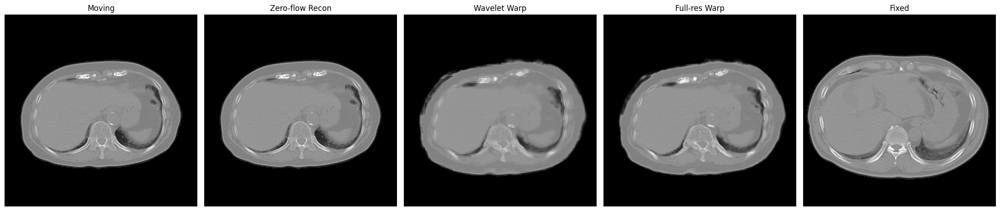

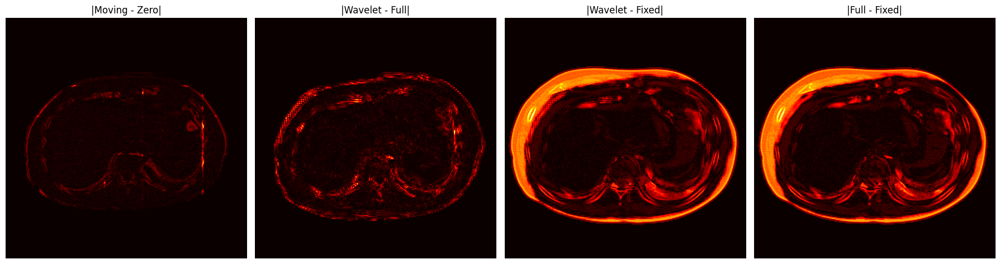

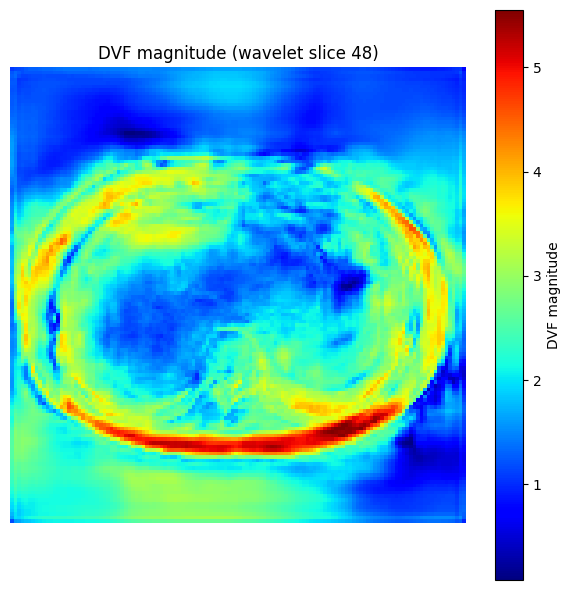


AUTOMATIC DIAGNOSIS
✓ Zero-flow reconstruction is accurate.
  Analysis / Down / Up / Synthesis alone is probably not the main problem.

✓ Zero-flow preserves sharpness well.

⚠ Wavelet and Full-resolution warp have similar sharpness.
  DVF itself or SpatialTransformer interpolation may be the main cause.



VxmDense_128_256_256(
  (unet_model): Unet_128_256_128(
    (pooling): ModuleList(
      (0-5): 6 x MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (upsampling): ModuleList(
      (0-5): 6 x Upsample(scale_factor=2.0, mode='nearest')
    )
    (encoder_LLL): ModuleList(
      (0): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(2, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (1): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (2-4): 3 x ModuleList(
        (0): ConvBlock(
          (main): Conv3d(128, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
    )
    (encoder_L2H1): ModuleList(
      (0):

In [ ]:
# ============================================================
# Wavelet Warp 粗さ診断セル
#
# 目的：
# 1. Zero-flow reconstruction は綺麗か
# 2. Wavelet-space warp だけ粗いのか
# 3. Full-resolution warp も粗いのか
# 4. DVF自体が粗すぎるのか
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 0. 評価モード
# ============================================================

model3D.eval()


# ============================================================
# 1. 観察ペア取得
#
# 既に obs_moving / obs_fixed がある前提
# ============================================================

with torch.no_grad():

    moving = obs_moving.to(
        device=device,
        dtype=torch.float32
    )

    fixed = obs_fixed.to(
        device=device,
        dtype=torch.float32
    )


    print("=" * 80)
    print("INPUT")
    print("=" * 80)

    print("Moving:", moving.shape)
    print("Fixed :", fixed.shape)


    # ========================================================
    # 2. Wavelet Analysis
    # ========================================================

    moving_analysis = analysis_filter_3d(
        moving,
        analysis
    )

    fixed_analysis = analysis_filter_3d(
        fixed,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    fixed_w = down_sampling_3d(
        fixed_analysis
    ).to(device)


    print()
    print("=" * 80)
    print("WAVELET")
    print("=" * 80)

    print("moving_w:", moving_w.shape)
    print("fixed_w :", fixed_w.shape)


    # ========================================================
    # 3. Zero-flow reconstruction
    #
    # DVFを全て0にする
    # これで粗いならWavelet再構成そのものがおかしい
    # ========================================================

    zero_flow = torch.zeros(
        (
            moving_w.shape[0],
            3,
            moving_w.shape[2],
            moving_w.shape[3],
            moving_w.shape[4]
        ),
        dtype=moving_w.dtype,
        device=device
    )


    zero_warped_w = transformer(
        moving_w,
        zero_flow
    )


    zero_warped_up = up_sampling_3d(
        zero_warped_w
    )


    zero_reconstructed, _ = synthesis_filter_3d(
        zero_warped_up,
        synthesis_filters
    )


    # ========================================================
    # 4. Learned DVF
    # ========================================================

    learned_flow = model3D(
        moving_w,
        fixed_w
    )


    print()
    print("=" * 80)
    print("LEARNED FLOW")
    print("=" * 80)

    print(
        "Wavelet-space DVF:",
        learned_flow.shape
    )


    # ========================================================
    # 5. Wavelet-space Warp
    #
    # 今の研究手法
    # ========================================================

    wavelet_warped_w = transformer(
        moving_w,
        learned_flow
    )


    wavelet_warped_up = up_sampling_3d(
        wavelet_warped_w
    )


    wavelet_reconstructed, _ = synthesis_filter_3d(
        wavelet_warped_up,
        synthesis_filters
    )


    # ========================================================
    # 6. DVFをFull-resolutionに拡大
    #
    # 64x128x128
    #   ↓
    # 128x256x256
    #
    # voxel単位も2倍になるので *2
    # ========================================================

    full_flow = F.interpolate(
        learned_flow,
        size=(
            moving.shape[2],
            moving.shape[3],
            moving.shape[4]
        ),
        mode="trilinear",
        align_corners=False
    ) * 2.0


    print(
        "Full-resolution DVF:",
        full_flow.shape
    )


    # ========================================================
    # 7. Full-resolution Warp
    #
    # Moving画像そのものを直接変形
    # ========================================================

    fullres_warped = transformer256(
        moving,
        full_flow
    )


# ============================================================
# 8. 基本誤差
# ============================================================

def calc_metrics(
    ref,
    img
):

    diff = ref - img

    mae = torch.mean(
        torch.abs(diff)
    ).item()

    mse = torch.mean(
        diff ** 2
    ).item()

    rmse = np.sqrt(
        mse
    )

    max_abs = torch.max(
        torch.abs(diff)
    ).item()

    return mae, mse, rmse, max_abs


# ============================================================
# 9. Sharpness
#
# 1voxel隣との絶対差
# 値が高いほどエッジ情報が多い
# ============================================================

def gradient_sharpness(
    img
):

    dx = torch.abs(
        img[:, :, :, :, 1:]
        -
        img[:, :, :, :, :-1]
    ).mean()

    dy = torch.abs(
        img[:, :, :, 1:, :]
        -
        img[:, :, :, :-1, :]
    ).mean()

    dz = torch.abs(
        img[:, :, 1:, :, :]
        -
        img[:, :, :-1, :, :]
    ).mean()

    return (
        (dx + dy + dz) / 3.0
    ).item()


# ============================================================
# 10. Zero-flow reconstruction error
# ============================================================

zero_mae, zero_mse, zero_rmse, zero_max = calc_metrics(
    moving,
    zero_reconstructed
)


# ============================================================
# 11. Registration error
# ============================================================

wav_mae, wav_mse, wav_rmse, wav_max = calc_metrics(
    fixed,
    wavelet_reconstructed
)


full_mae, full_mse, full_rmse, full_max = calc_metrics(
    fixed,
    fullres_warped
)


# ============================================================
# 12. Wavelet版とFull-res版の直接差
# ============================================================

wf_mae, wf_mse, wf_rmse, wf_max = calc_metrics(
    fullres_warped,
    wavelet_reconstructed
)


# ============================================================
# 13. Sharpness
# ============================================================

sharp_moving = gradient_sharpness(
    moving
)

sharp_fixed = gradient_sharpness(
    fixed
)

sharp_zero = gradient_sharpness(
    zero_reconstructed
)

sharp_wavelet = gradient_sharpness(
    wavelet_reconstructed
)

sharp_fullres = gradient_sharpness(
    fullres_warped
)


# ============================================================
# 14. DVF statistics
# ============================================================

flow_mag = torch.sqrt(
    torch.sum(
        learned_flow ** 2,
        dim=1
    )
)


flow_flat = flow_mag.flatten()


dvf_mean = flow_flat.mean().item()

dvf_p95 = torch.quantile(
    flow_flat,
    0.95
).item()

dvf_p99 = torch.quantile(
    flow_flat,
    0.99
).item()

dvf_max = flow_flat.max().item()


# ============================================================
# 15. 数値表示
# ============================================================

print()
print("=" * 80)
print("ZERO-FLOW RECONSTRUCTION")
print("=" * 80)

print(
    f"MAE     : {zero_mae:.10f}"
)

print(
    f"MSE     : {zero_mse:.10f}"
)

print(
    f"RMSE    : {zero_rmse:.10f}"
)

print(
    f"Max abs : {zero_max:.10f}"
)


print()
print("=" * 80)
print("REGISTRATION ERROR vs FIXED")
print("=" * 80)

print()
print("Wavelet-space warp")

print(
    f"MAE     : {wav_mae:.10f}"
)

print(
    f"MSE     : {wav_mse:.10f}"
)

print(
    f"RMSE    : {wav_rmse:.10f}"
)


print()
print("Full-resolution warp")

print(
    f"MAE     : {full_mae:.10f}"
)

print(
    f"MSE     : {full_mse:.10f}"
)

print(
    f"RMSE    : {full_rmse:.10f}"
)


print()
print("=" * 80)
print("WAVELET vs FULL-RES WARP")
print("=" * 80)

print(
    f"MAE     : {wf_mae:.10f}"
)

print(
    f"MSE     : {wf_mse:.10f}"
)

print(
    f"RMSE    : {wf_rmse:.10f}"
)

print(
    f"Max abs : {wf_max:.10f}"
)


print()
print("=" * 80)
print("SHARPNESS")
print("=" * 80)

print(
    f"Moving        : {sharp_moving:.8f}"
)

print(
    f"Fixed         : {sharp_fixed:.8f}"
)

print(
    f"Zero-flow     : {sharp_zero:.8f}"
)

print(
    f"Wavelet warp  : {sharp_wavelet:.8f}"
)

print(
    f"Full-res warp : {sharp_fullres:.8f}"
)


print()
print("=" * 80)
print("SHARPNESS RATIO")
print("=" * 80)

print(
    f"Zero / Moving     : "
    f"{sharp_zero / sharp_moving:.4f}"
)

print(
    f"Wavelet / Moving  : "
    f"{sharp_wavelet / sharp_moving:.4f}"
)

print(
    f"Full-res / Moving : "
    f"{sharp_fullres / sharp_moving:.4f}"
)


print()
print("=" * 80)
print("DVF STATISTICS")
print("=" * 80)

print(
    f"DVF mean : {dvf_mean:.4f}"
)

print(
    f"DVF P95  : {dvf_p95:.4f}"
)

print(
    f"DVF P99  : {dvf_p99:.4f}"
)

print(
    f"DVF max  : {dvf_max:.4f}"
)


# ============================================================
# 16. 表示スライス
#
# Fixedの身体面積が大きいsliceを自動選択
# ============================================================

with torch.no_grad():

    slice_score = torch.mean(
        torch.abs(fixed[0, 0]),
        dim=(
            1,
            2
        )
    )

    slice_idx = torch.argmax(
        slice_score
    ).item()


print()
print(
    "Display slice:",
    slice_idx
)


# ============================================================
# 17. CT画像比較
# ============================================================

display_images = [
    (
        "Moving",
        moving
    ),
    (
        "Zero-flow Recon",
        zero_reconstructed
    ),
    (
        "Wavelet Warp",
        wavelet_reconstructed
    ),
    (
        "Full-res Warp",
        fullres_warped
    ),
    (
        "Fixed",
        fixed
    )
]


plt.figure(
    figsize=(
        22,
        5
    )
)


for i, (
    title,
    image
) in enumerate(
    display_images
):

    plt.subplot(
        1,
        5,
        i + 1
    )

    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .detach()
        .float()
        .cpu(),
        cmap="gray"
    )

    plt.title(
        title
    )

    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 18. Difference画像
# ============================================================

diff_zero = torch.abs(
    moving
    - zero_reconstructed
)


diff_wavelet_full = torch.abs(
    wavelet_reconstructed
    - fullres_warped
)


diff_wavelet_fixed = torch.abs(
    wavelet_reconstructed
    - fixed
)


diff_full_fixed = torch.abs(
    fullres_warped
    - fixed
)


diff_images = [
    (
        "|Moving - Zero|",
        diff_zero
    ),
    (
        "|Wavelet - Full|",
        diff_wavelet_full
    ),
    (
        "|Wavelet - Fixed|",
        diff_wavelet_fixed
    ),
    (
        "|Full - Fixed|",
        diff_full_fixed
    )
]


plt.figure(
    figsize=(
        18,
        5
    )
)


for i, (
    title,
    image
) in enumerate(
    diff_images
):

    plt.subplot(
        1,
        4,
        i + 1
    )

    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .detach()
        .float()
        .cpu(),
        cmap="hot"
    )

    plt.title(
        title
    )

    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 19. DVF magnitude表示
# ============================================================

plt.figure(
    figsize=(
        6,
        6
    )
)

plt.imshow(
    flow_mag[
        0,
        slice_idx // 2
    ]
    .detach()
    .float()
    .cpu(),
    cmap="jet"
)

plt.colorbar(
    label="DVF magnitude"
)

plt.title(
    "DVF magnitude "
    f"(wavelet slice {slice_idx // 2})"
)

plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ============================================================
# 20. 自動診断
# ============================================================

print()
print("=" * 80)
print("AUTOMATIC DIAGNOSIS")
print("=" * 80)


zero_ratio = (
    sharp_zero
    / sharp_moving
)

wavelet_ratio = (
    sharp_wavelet
    / sharp_moving
)

full_ratio = (
    sharp_fullres
    / sharp_moving
)


if zero_mae < 1e-3:

    print(
        "✓ Zero-flow reconstruction is accurate."
    )

    print(
        "  Analysis / Down / Up / Synthesis "
        "alone is probably not the main problem."
    )

else:

    print(
        "⚠ Zero-flow reconstruction error is large."
    )

    print(
        "  First check Analysis / Down / Up / Synthesis."
    )


print()


if (
    zero_ratio > 0.97
):

    print(
        "✓ Zero-flow preserves sharpness well."
    )

else:

    print(
        "⚠ Image already loses sharpness "
        "without deformation."
    )


print()


if (
    wavelet_ratio
    <
    full_ratio * 0.90
):

    print(
        "⚠ Wavelet-space warp is much less sharp "
        "than Full-resolution warp."
    )

    print(
        "  Strong suspicion:"
    )

    print(
        "  SpatialTransformer interpolation "
        "of Wavelet coefficients."
    )

elif (
    abs(
        wavelet_ratio
        -
        full_ratio
    )
    < 0.05
):

    print(
        "⚠ Wavelet and Full-resolution warp "
        "have similar sharpness."
    )

    print(
        "  DVF itself or SpatialTransformer "
        "interpolation may be the main cause."
    )

else:

    print(
        "Wavelet-space warp is somewhat less sharp."
    )


print()


if dvf_p99 > 20:

    print(
        "⚠ DVF P99 is quite large "
        "in Wavelet voxel units."
    )

    print(
        "  Large deformation may amplify "
        "interpolation artifacts."
    )


print("=" * 80)


# ============================================================
# 評価モードから戻す
# ============================================================

model3D.train()

In [ ]:
# ============================================================
# Fast Fine-tuning
#
# 80k pretrained DVF model
# Different-patient registration
#
# Loss:
#   Image similarity
#   +
#   0.01 * DVF smoothness
#
# Lung mask:
#   Fixed lung mask
#
# Speed-up:
#   - GPU
#   - AMP
#   - TF32
#   - Observation Wavelet precompute
#   - No .item() every epoch
#   - Checkpoint every 1000 epochs
#   - Evaluation every 1000 epochs
# ============================================================

from tqdm.notebook import tqdm

import numpy as np
import torch
import torch.optim as optim
import matplotlib.pyplot as plt

from pathlib import Path


# ============================================================
# 0. Settings
# ============================================================

DATA_DIR = Path("Data")

RAW_DATA_PATH = (
    DATA_DIR
    / "TrainData_NoBed.npz"
)

PRETRAINED_PATH = Path(
    "model_DVF_pretrain_final.pth"
)

LATEST_PATH = Path(
    "model_DVF_finetuned_smooth001_latest.pth"
)

FINAL_PATH = Path(
    "model_DVF_finetuned_smooth001_final.pth"
)

CHECKPOINT_DIR = Path(
    "finetune_checkpoints_smooth001"
)

CHECKPOINT_DIR.mkdir(
    exist_ok=True
)


# ============================================================
# Training settings
# ============================================================

epochs = 30000

learning_rate = 1e-6

smoothness_weight = 0.01

batch_size = 2

log_every = 100

evaluation_every = 1000

checkpoint_every = 1000


# ============================================================
# CUDA
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)


if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


print("=" * 70)
print("DEVICE")
print("=" * 70)

print(
    "device:",
    device
)

print(
    "CUDA available:",
    torch.cuda.is_available()
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM:",
        round(
            torch.cuda.get_device_properties(0)
            .total_memory
            / 1024**3,
            2
        ),
        "GB"
    )


# ============================================================
# Lung-masked archive candidates
# ============================================================

MASKED_ARCHIVE_CANDIDATES = [

    DATA_DIR
    / "TrainData_NoBed_LungMasked.npz",

    DATA_DIR
    / "TrainData_NoBed_lung_masked.npz",

    DATA_DIR
    / "TrainData_NoBed_Masked.npz",

    DATA_DIR
    / "TrainData_NoBed_masked.npz",
]


VOLUME_KEYS = (

    "Train_lung_masked",

    "train_lung_masked",

    "TrainMasked",

    "masked_train",

    "Train",
)


MASK_KEYS = (

    "Train_lung_mask",

    "train_lung_mask",

    "LungMask",

    "lung_mask",

    "TrainMask",

    "train_mask",

    "Mask",

    "mask",
)


# ============================================================
# 1. Utility
# ============================================================

def to_n_dhw(
    array,
    label
):

    array = np.asarray(
        array,
        dtype=np.float32
    )

    if array.ndim != 4:

        raise ValueError(
            f"{label} must be 4-D; "
            f"got {array.shape}"
        )


    # --------------------------------------------------------
    # (N,128,256,256)
    # --------------------------------------------------------

    if array.shape[1:] == (
        128,
        256,
        256
    ):

        return array


    # --------------------------------------------------------
    # (128,256,256,N)
    # --------------------------------------------------------

    if array.shape[:3] == (
        128,
        256,
        256
    ):

        return np.transpose(
            array,
            (3,0,1,2)
        )


    # --------------------------------------------------------
    # (N,256,256,128)
    # --------------------------------------------------------

    if array.shape[1:] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (0,3,1,2)
        )


    # --------------------------------------------------------
    # (256,256,128,N)
    # --------------------------------------------------------

    if array.shape[:3] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (3,2,0,1)
        )


    raise ValueError(
        f"{label} unsupported shape: "
        f"{array.shape}"
    )


# ============================================================
# 2. First available key
# ============================================================

def first_available_key(
    archive,
    candidates
):

    return next(
        (
            key
            for key in candidates
            if key in archive.files
        ),
        None
    )


# ============================================================
# 3. Load training data
# ============================================================

def load_lung_preferred_training_data():

    masked_path = next(
        (
            path
            for path
            in MASKED_ARCHIVE_CANDIDATES
            if path.exists()
        ),
        None
    )


    archive_path = (
        masked_path
        if masked_path is not None
        else RAW_DATA_PATH
    )


    if not archive_path.exists():

        raise FileNotFoundError(
            f"Training archive not found:\n"
            f"{archive_path.resolve()}"
        )


    with np.load(
        archive_path,
        allow_pickle=False
    ) as archive:


        volume_key = first_available_key(
            archive,
            VOLUME_KEYS
        )


        if volume_key is None:

            raise KeyError(
                f"No volume key in "
                f"{archive_path}\n"
                f"Available keys: "
                f"{archive.files}"
            )


        volumes = to_n_dhw(
            archive[volume_key],
            f"{archive_path}:{volume_key}"
        )


        mask_key = first_available_key(
            archive,
            MASK_KEYS
        )


        if mask_key is None:

            masks = None

        else:

            masks = to_n_dhw(
                archive[mask_key],
                f"{archive_path}:{mask_key}"
            )


    # ========================================================
    # Lung mask
    # ========================================================

    if masks is not None:


        if masks.shape != volumes.shape:

            raise ValueError(
                f"Volume/mask mismatch: "
                f"{volumes.shape} "
                f"vs "
                f"{masks.shape}"
            )


        masks = (
            masks > 0
        ).astype(
            np.float32
        )


        # ----------------------------------------------------
        # 入力も肺マスク済みにする
        # ----------------------------------------------------

        volumes = (
            volumes
            *
            masks
        )


        print()
        print("=" * 70)
        print("LUNG MASK")
        print("=" * 70)

        print(
            "Archive:",
            archive_path
        )

        print(
            "Mask key:",
            mask_key
        )


    elif masked_path is not None:

        print()
        print(
            "Using pre-masked archive:"
        )

        print(
            archive_path
        )


    else:

        print()
        print(
            "WARNING: No lung mask found."
        )

        print(
            "Using unmasked volumes."
        )


    print()

    print(
        "Training volume shape:",
        volumes.shape
    )

    print(
        "Training volume dtype:",
        volumes.dtype
    )


    return (
        volumes,
        masks,
        archive_path
    )


# ============================================================
# 4. Different-patient generator
#
# Moving != Fixed
# Fixed側maskのみ返す
# ============================================================

def different_patient_generator(
    volumes,
    masks=None,
    batch_size=2,
    seed=42
):

    n_patients = len(
        volumes
    )


    if n_patients < 2:

        raise ValueError(
            "At least 2 patients are required."
        )


    rng = np.random.default_rng(
        seed
    )


    while True:


        moving_indices = rng.integers(
            0,
            n_patients,
            size=batch_size
        )


        fixed_indices = rng.integers(
            0,
            n_patients,
            size=batch_size
        )


        # ====================================================
        # 同一患者を排除
        # ====================================================

        same = (
            moving_indices
            ==
            fixed_indices
        )


        while np.any(
            same
        ):


            fixed_indices[
                same
            ] = rng.integers(
                0,
                n_patients,
                size=int(
                    same.sum()
                )
            )


            same = (
                moving_indices
                ==
                fixed_indices
            )


        # ====================================================
        # NumPy -> Torch
        # ====================================================

        moving = torch.from_numpy(
            volumes[
                moving_indices
            ]
        ).unsqueeze(
            1
        )


        fixed = torch.from_numpy(
            volumes[
                fixed_indices
            ]
        ).unsqueeze(
            1
        )


        if masks is None:

            fixed_mask = None

        else:

            fixed_mask = torch.from_numpy(
                masks[
                    fixed_indices
                ]
            ).unsqueeze(
                1
            )


        yield (
            moving,
            fixed,
            fixed_mask,
            moving_indices,
            fixed_indices
        )


# ============================================================
# 5. Masked MSE
# ============================================================

def masked_mse(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).square()


    if mask is None:

        return error.mean()


    return (
        error
        *
        mask
    ).sum() / (
        mask.sum()
        .clamp_min(
            eps
        )
    )


# ============================================================
# 6. Masked MAE
# ============================================================

def masked_mae(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).abs()


    if mask is None:

        return error.mean()


    return (
        error
        *
        mask
    ).sum() / (
        mask.sum()
        .clamp_min(
            eps
        )
    )


# ============================================================
# 7. DVF Smoothness
# ============================================================

def smoothness_loss(
    flow
):

    dz = (
        flow[:, :, 1:, :, :]
        -
        flow[:, :, :-1, :, :]
    ).square().mean()


    dy = (
        flow[:, :, :, 1:, :]
        -
        flow[:, :, :, :-1, :]
    ).square().mean()


    dx = (
        flow[:, :, :, :, 1:]
        -
        flow[:, :, :, :, :-1]
    ).square().mean()


    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 8. Sharpness
# ============================================================

def gradient_sharpness(
    image
):

    dz = (
        image[:, :, 1:, :, :]
        -
        image[:, :, :-1, :, :]
    ).abs().mean()


    dy = (
        image[:, :, :, 1:, :]
        -
        image[:, :, :, :-1, :]
    ).abs().mean()


    dx = (
        image[:, :, :, :, 1:]
        -
        image[:, :, :, :, :-1]
    ).abs().mean()


    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 9. Jacobian determinant
#
# VoxelMorph PyTorch:
# flow[:,0] = z
# flow[:,1] = y
# flow[:,2] = x
#
# Tensor order:
# D,H,W = z,y,x
# ============================================================

def jacobian_determinant_3d(
    flow
):

    flow = flow.float()


    fz = flow[:,0]
    fy = flow[:,1]
    fx = flow[:,2]


    # ========================================================
    # z component
    # ========================================================

    dfz_dz = (
        fz[:,2:,1:-1,1:-1]
        -
        fz[:,:-2,1:-1,1:-1]
    ) / 2.0


    dfz_dy = (
        fz[:,1:-1,2:,1:-1]
        -
        fz[:,1:-1,:-2,1:-1]
    ) / 2.0


    dfz_dx = (
        fz[:,1:-1,1:-1,2:]
        -
        fz[:,1:-1,1:-1,:-2]
    ) / 2.0


    # ========================================================
    # y component
    # ========================================================

    dfy_dz = (
        fy[:,2:,1:-1,1:-1]
        -
        fy[:,:-2,1:-1,1:-1]
    ) / 2.0


    dfy_dy = (
        fy[:,1:-1,2:,1:-1]
        -
        fy[:,1:-1,:-2,1:-1]
    ) / 2.0


    dfy_dx = (
        fy[:,1:-1,1:-1,2:]
        -
        fy[:,1:-1,1:-1,:-2]
    ) / 2.0


    # ========================================================
    # x component
    # ========================================================

    dfx_dz = (
        fx[:,2:,1:-1,1:-1]
        -
        fx[:,:-2,1:-1,1:-1]
    ) / 2.0


    dfx_dy = (
        fx[:,1:-1,2:,1:-1]
        -
        fx[:,1:-1,:-2,1:-1]
    ) / 2.0


    dfx_dx = (
        fx[:,1:-1,1:-1,2:]
        -
        fx[:,1:-1,1:-1,:-2]
    ) / 2.0


    # ========================================================
    # J = I + grad(flow)
    # ========================================================

    J11 = 1.0 + dfz_dz
    J12 = dfz_dy
    J13 = dfz_dx

    J21 = dfy_dz
    J22 = 1.0 + dfy_dy
    J23 = dfy_dx

    J31 = dfx_dz
    J32 = dfx_dy
    J33 = 1.0 + dfx_dx


    detJ = (

        J11
        *
        (
            J22 * J33
            -
            J23 * J32
        )

        -

        J12
        *
        (
            J21 * J33
            -
            J23 * J31
        )

        +

        J13
        *
        (
            J21 * J32
            -
            J22 * J31
        )
    )


    return detJ


# ============================================================
# 10. Load Data
# ============================================================

(
    volumes,
    lung_masks,
    archive_path
) = load_lung_preferred_training_data()


finetune_generator = (
    different_patient_generator(
        volumes,
        masks=lung_masks,
        batch_size=batch_size,
        seed=42
    )
)


# ============================================================
# 11. Pretrained checkpoint check
# ============================================================

if not PRETRAINED_PATH.exists():

    raise FileNotFoundError(
        f"Pretrained model not found:\n"
        f"{PRETRAINED_PATH.resolve()}"
    )


print()
print("=" * 70)
print("PRETRAINED MODEL")
print("=" * 70)

print(
    PRETRAINED_PATH.resolve()
)


# ============================================================
# 12. Model
#
# 事前学習と同じ構造
# ============================================================

model3D = (
    vxm.networks.VxmDense_128_256_256(
        (128,256,256),
        nb_features,
        int_steps=0
    )
    .to(
        device
    )
)


# ============================================================
# 13. Load 80k pretrained weights
# ============================================================

try:

    pretrained_state = torch.load(
        PRETRAINED_PATH,
        map_location=device,
        weights_only=True
    )

except TypeError:

    pretrained_state = torch.load(
        PRETRAINED_PATH,
        map_location=device
    )


if (
    isinstance(
        pretrained_state,
        dict
    )
    and
    "model_state_dict"
    in pretrained_state
):

    model3D.load_state_dict(
        pretrained_state[
            "model_state_dict"
        ]
    )

else:

    model3D.load_state_dict(
        pretrained_state
    )


print(
    "80k pretrained model loaded."
)


# ============================================================
# 14. Spatial Transformer
#
# Wavelet-space resolution
# ============================================================

transformer = (
    vxm.layers.SpatialTransformer(
        (64,128,128)
    )
    .to(
        device
    )
)


# ============================================================
# 15. Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=learning_rate
)


# ============================================================
# 16. AMP
# ============================================================

use_amp = (
    torch.cuda.is_available()
)


scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


print()
print("=" * 70)
print("TRAINING SETTINGS")
print("=" * 70)

print(
    "Model device:",
    next(
        model3D.parameters()
    ).device
)

print(
    "AMP:",
    use_amp
)

print(
    "Learning rate:",
    learning_rate
)

print(
    "Smoothness weight:",
    smoothness_weight
)

print(
    "Batch size:",
    batch_size
)

print(
    "Epochs:",
    epochs
)


# ============================================================
# 17. Fixed Observation Pair
# ============================================================

(
    obs_moving_cpu,
    obs_fixed_cpu,
    obs_mask_cpu,
    obs_moving_ids,
    obs_fixed_ids
) = next(
    finetune_generator
)


obs_moving = (
    obs_moving_cpu[
        0:1
    ]
    .to(
        device=device,
        dtype=torch.float32
    )
)


obs_fixed = (
    obs_fixed_cpu[
        0:1
    ]
    .to(
        device=device,
        dtype=torch.float32
    )
)


if obs_mask_cpu is None:

    obs_mask = None

else:

    obs_mask = (
        obs_mask_cpu[
            0:1
        ]
        .to(
            device=device,
            dtype=torch.float32
        )
    )


print()
print("=" * 70)
print("OBSERVATION PAIR")
print("=" * 70)

print(
    "Moving patient:",
    int(
        obs_moving_ids[0]
    )
)

print(
    "Fixed patient :",
    int(
        obs_fixed_ids[0]
    )
)

print(
    "Moving:",
    obs_moving.shape
)

print(
    "Fixed :",
    obs_fixed.shape
)


# ============================================================
# 18. Observation Wavelet Precompute
#
# 固定観察ペアなので一回のみ
# ============================================================

with torch.no_grad():


    obs_moving_analysis = (
        analysis_filter_3d(
            obs_moving,
            analysis
        )
    )


    obs_fixed_analysis = (
        analysis_filter_3d(
            obs_fixed,
            analysis
        )
    )


    obs_moving_w = (
        down_sampling_3d(
            obs_moving_analysis
        )
    )


    obs_fixed_w = (
        down_sampling_3d(
            obs_fixed_analysis
        )
    )


    del obs_moving_analysis
    del obs_fixed_analysis


print(
    "Observation Moving Wavelet:",
    obs_moving_w.shape
)

print(
    "Observation Fixed Wavelet :",
    obs_fixed_w.shape
)


# ============================================================
# 19. Histories
#
# 100 epochごとにLoss記録
# ============================================================

loss_epochs = []

losses = []

image_losses = []

smooth_losses = []

observation_history = []


# ============================================================
# 20. Fine-tuning
# ============================================================

model3D.train()


for epoch in tqdm(
    range(
        1,
        epochs + 1
    ),
    desc="Fine-tuning smooth=0.01"
):


    # ========================================================
    # Data
    # ========================================================

    (
        moving_cpu,
        fixed_cpu,
        fixed_mask_cpu,
        moving_ids,
        fixed_ids
    ) = next(
        finetune_generator
    )


    # ========================================================
    # CPU -> GPU
    # ========================================================

    moving_images = moving_cpu.to(
        device=device,
        dtype=torch.float32
    )


    fixed_images = fixed_cpu.to(
        device=device,
        dtype=torch.float32
    )


    if fixed_mask_cpu is None:

        fixed_mask = None

    else:

        fixed_mask = fixed_mask_cpu.to(
            device=device,
            dtype=torch.float32
        )


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # Forward
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # Analysis
        # ====================================================

        moving_analysis = (
            analysis_filter_3d(
                moving_images,
                analysis
            )
        )


        fixed_analysis = (
            analysis_filter_3d(
                fixed_images,
                analysis
            )
        )


        # ====================================================
        # Down Sampling
        # ====================================================

        moving_w = (
            down_sampling_3d(
                moving_analysis
            )
        )


        fixed_w = (
            down_sampling_3d(
                fixed_analysis
            )
        )


        # ====================================================
        # DVF
        #
        # (B,3,64,128,128)
        #
        # Fine-tuningでは /2しない
        # ====================================================

        Vec = model3D(
            moving_w,
            fixed_w
        )


        # ====================================================
        # Wavelet-space warp
        # ====================================================

        moving_warped = (
            transformer(
                moving_w,
                Vec
            )
        )


        # ====================================================
        # Upsampling
        # ====================================================

        moving_warped_up = (
            up_sampling_3d(
                moving_warped
            )
        )


        # ====================================================
        # Synthesis
        # ====================================================

        (
            transformed_image,
            _
        ) = synthesis_filter_3d(
            moving_warped_up,
            synthesis_filters
        )


        # ====================================================
        # Image similarity
        #
        # Fixed lung mask
        # ====================================================

        loss_image = masked_mse(
            fixed_images,
            transformed_image,
            fixed_mask
        )


        # ====================================================
        # DVF smoothness
        # ====================================================

        loss_smooth = smoothness_loss(
            Vec
        )


        # ====================================================
        # Total loss
        #
        # Image
        # +
        # 0.01 * Smoothness
        # ====================================================

        weighted_smooth = (
            smoothness_weight
            *
            loss_smooth
        )


        loss = (
            loss_image
            +
            weighted_smooth
        )


    # ========================================================
    # Backward
    # ========================================================

    scaler.scale(
        loss
    ).backward()


    # ========================================================
    # Gradient clipping
    # ========================================================

    scaler.unscale_(
        optimizer
    )


    torch.nn.utils.clip_grad_norm_(
        model3D.parameters(),
        max_norm=1.0
    )


    # ========================================================
    # Optimizer
    # ========================================================

    scaler.step(
        optimizer
    )


    scaler.update()


    # ========================================================
    # 不要Tensorの参照を削除
    # ========================================================

    del moving_analysis
    del fixed_analysis

    del moving_w
    del fixed_w

    del moving_warped
    del moving_warped_up


    # ========================================================
    # Log
    #
    # 100epochごとのみGPU -> CPU
    # ========================================================

    if (
        epoch
        %
        log_every
        ==
        0
    ):


        log_values = (
            torch.stack(
                [
                    loss.detach().float(),
                    loss_image.detach().float(),
                    loss_smooth.detach().float()
                ]
            )
            .cpu()
        )


        loss_value = float(
            log_values[0]
        )


        image_value = float(
            log_values[1]
        )


        smooth_value = float(
            log_values[2]
        )


        weighted_value = (
            smoothness_weight
            *
            smooth_value
        )


        loss_epochs.append(
            epoch
        )

        losses.append(
            loss_value
        )

        image_losses.append(
            image_value
        )

        smooth_losses.append(
            smooth_value
        )


        print(
            f"Epoch "
            f"{epoch:05d}/{epochs} | "
            f"total={loss_value:.8f} | "
            f"image={image_value:.8f} | "
            f"smooth={smooth_value:.8f} | "
            f"weighted={weighted_value:.8f}"
        )


    # ========================================================
    # Evaluation
    #
    # 1000epochごと
    # ========================================================

    if (
        epoch
        %
        evaluation_every
        ==
        0
    ):


        model3D.eval()


        with torch.inference_mode():


            with torch.cuda.amp.autocast(
                enabled=use_amp
            ):


                # =============================================
                # DVF
                # =============================================

                obs_vec = model3D(
                    obs_moving_w,
                    obs_fixed_w
                )


                # =============================================
                # Warp
                # =============================================

                obs_warped_w = (
                    transformer(
                        obs_moving_w,
                        obs_vec
                    )
                )


                # =============================================
                # Upsample
                # =============================================

                obs_warped_up = (
                    up_sampling_3d(
                        obs_warped_w
                    )
                )


                # =============================================
                # Synthesis
                # =============================================

                (
                    obs_transformed,
                    _
                ) = synthesis_filter_3d(
                    obs_warped_up,
                    synthesis_filters
                )


            # =================================================
            # Evaluation FP32
            # =================================================

            obs_vec_float = (
                obs_vec.float()
            )


            obs_transformed_float = (
                obs_transformed.float()
            )


            # =================================================
            # Image metrics
            # =================================================

            obs_mse_tensor = masked_mse(
                obs_fixed,
                obs_transformed_float,
                obs_mask
            )


            obs_mae_tensor = masked_mae(
                obs_fixed,
                obs_transformed_float,
                obs_mask
            )


            # =================================================
            # Sharpness
            # =================================================

            sharp_moving_tensor = (
                gradient_sharpness(
                    obs_moving
                )
            )


            sharp_warped_tensor = (
                gradient_sharpness(
                    obs_transformed_float
                )
            )


            # =================================================
            # DVF magnitude
            # =================================================

            flow_mag = (
                torch.linalg.vector_norm(
                    obs_vec_float,
                    dim=1
                )
            )


            flow_flat = (
                flow_mag.flatten()
            )


            q = torch.quantile(
                flow_flat,
                torch.tensor(
                    [
                        0.95,
                        0.99
                    ],
                    device=flow_flat.device,
                    dtype=flow_flat.dtype
                )
            )


            # =================================================
            # Jacobian
            # =================================================

            detJ = (
                jacobian_determinant_3d(
                    obs_vec_float
                )
            )


            folding_tensor = (
                (
                    detJ <= 0
                )
                .float()
                .mean()
            )


            compression_tensor = (
                (
                    detJ < 0.2
                )
                .float()
                .mean()
            )


            expansion_tensor = (
                (
                    detJ > 2.0
                )
                .float()
                .mean()
            )


            # =================================================
            # GPU -> CPUをまとめて1回
            # =================================================

            eval_values = (
                torch.stack(
                    [
                        obs_mse_tensor,
                        obs_mae_tensor,

                        sharp_moving_tensor,
                        sharp_warped_tensor,

                        flow_flat.mean(),

                        q[0],
                        q[1],

                        flow_flat.max(),

                        folding_tensor,
                        compression_tensor,
                        expansion_tensor
                    ]
                )
                .float()
                .cpu()
            )


            obs_mse = float(
                eval_values[0]
            )


            obs_mae = float(
                eval_values[1]
            )


            sharp_moving = float(
                eval_values[2]
            )


            sharp_warped = float(
                eval_values[3]
            )


            sharp_ratio = (
                sharp_warped
                /
                max(
                    sharp_moving,
                    1e-8
                )
            )


            dvf_mean = float(
                eval_values[4]
            )


            dvf_p95 = float(
                eval_values[5]
            )


            dvf_p99 = float(
                eval_values[6]
            )


            dvf_max = float(
                eval_values[7]
            )


            folding_ratio = (
                float(
                    eval_values[8]
                )
                *
                100.0
            )


            strong_compression = (
                float(
                    eval_values[9]
                )
                *
                100.0
            )


            expansion = (
                float(
                    eval_values[10]
                )
                *
                100.0
            )


            # =================================================
            # History
            # =================================================

            observation_history.append(
                {
                    "epoch":
                        epoch,

                    "mse":
                        obs_mse,

                    "mae":
                        obs_mae,

                    "sharpness":
                        sharp_ratio,

                    "dvf_mean":
                        dvf_mean,

                    "dvf_p95":
                        dvf_p95,

                    "dvf_p99":
                        dvf_p99,

                    "dvf_max":
                        dvf_max,

                    "folding":
                        folding_ratio,

                    "compression":
                        strong_compression,

                    "expansion":
                        expansion,
                }
            )


            # =================================================
            # Print
            # =================================================

            print()
            print("=" * 75)

            print(
                f"Observation Epoch "
                f"{epoch}"
            )

            print("=" * 75)


            print(
                f"MSE              : "
                f"{obs_mse:.8f}"
            )


            print(
                f"MAE              : "
                f"{obs_mae:.8f}"
            )


            print(
                f"Sharpness ratio  : "
                f"{sharp_ratio:.4f}"
            )


            print(
                f"DVF mean         : "
                f"{dvf_mean:.4f}"
            )


            print(
                f"DVF P95          : "
                f"{dvf_p95:.4f}"
            )


            print(
                f"DVF P99          : "
                f"{dvf_p99:.4f}"
            )


            print(
                f"DVF max          : "
                f"{dvf_max:.4f}"
            )


            print(
                f"Folding          : "
                f"{folding_ratio:.4f}%"
            )


            print(
                f"Jacobian < 0.2   : "
                f"{strong_compression:.4f}%"
            )


            print(
                f"Jacobian > 2.0   : "
                f"{expansion:.4f}%"
            )


            if torch.cuda.is_available():

                print(
                    f"GPU allocated    : "
                    f"{torch.cuda.memory_allocated() / 1024**3:.2f} GB"
                )

                print(
                    f"GPU reserved     : "
                    f"{torch.cuda.memory_reserved() / 1024**3:.2f} GB"
                )


            # =================================================
            # Visualization
            # =================================================

            slice_idx = min(
                64,
                obs_moving.shape[2] - 1
            )


            moving_plot = (
                obs_moving[
                    0,
                    0,
                    slice_idx
                ]
                .float()
                .cpu()
                .numpy()
            )


            fixed_plot = (
                obs_fixed[
                    0,
                    0,
                    slice_idx
                ]
                .float()
                .cpu()
                .numpy()
            )


            warped_plot = (
                obs_transformed_float[
                    0,
                    0,
                    slice_idx
                ]
                .cpu()
                .numpy()
            )


            plt.figure(
                figsize=(12,4)
            )


            plt.subplot(
                1,
                3,
                1
            )

            plt.imshow(
                moving_plot,
                cmap="gray"
            )

            plt.title(
                "Moving"
            )

            plt.axis(
                "off"
            )


            plt.subplot(
                1,
                3,
                2
            )

            plt.imshow(
                fixed_plot,
                cmap="gray"
            )

            plt.title(
                "Fixed"
            )

            plt.axis(
                "off"
            )


            plt.subplot(
                1,
                3,
                3
            )

            plt.imshow(
                warped_plot,
                cmap="gray"
            )

            plt.title(
                f"Warped Epoch {epoch}"
            )

            plt.axis(
                "off"
            )


            plt.tight_layout()

            plt.show()


            # =================================================
            # Eval cleanup
            # =================================================

            del obs_vec
            del obs_warped_w
            del obs_warped_up
            del obs_transformed

            del obs_vec_float
            del obs_transformed_float

            del flow_mag
            del flow_flat

            del detJ


        model3D.train()


    # ========================================================
    # Checkpoint
    #
    # 1000epochごと
    # ========================================================

    if (
        epoch
        %
        checkpoint_every
        ==
        0
    ):


        checkpoint_path = (

            CHECKPOINT_DIR

            /

            f"finetune_smooth001_epoch_"
            f"{epoch:05d}.pth"
        )


        save_state = {

            "epoch":
                epoch,

            "model_state_dict":
                model3D.state_dict(),

            "optimizer_state_dict":
                optimizer.state_dict(),

            "scaler_state_dict":
                scaler.state_dict(),

            "smoothness_weight":
                smoothness_weight,

            "learning_rate":
                learning_rate,

            "observation_history":
                observation_history,

            "loss_epochs":
                loss_epochs,

            "losses":
                losses,

            "image_losses":
                image_losses,

            "smooth_losses":
                smooth_losses,

            "archive_path":
                str(
                    archive_path
                ),

            "used_lung_mask":
                lung_masks is not None,
        }


        # ----------------------------------------------------
        # Epoch-specific checkpoint
        # ----------------------------------------------------

        torch.save(
            save_state,
            checkpoint_path
        )


        # ----------------------------------------------------
        # Latest checkpoint
        # ----------------------------------------------------

        torch.save(
            save_state,
            LATEST_PATH
        )


        print(
            f"Checkpoint saved: "
            f"{checkpoint_path}"
        )


# ============================================================
# 21. Final save
# ============================================================

final_state = {

    "epoch":
        epochs,

    "model_state_dict":
        model3D.state_dict(),

    "optimizer_state_dict":
        optimizer.state_dict(),

    "scaler_state_dict":
        scaler.state_dict(),

    "smoothness_weight":
        smoothness_weight,

    "learning_rate":
        learning_rate,

    "observation_history":
        observation_history,

    "loss_epochs":
        loss_epochs,

    "losses":
        losses,

    "image_losses":
        image_losses,

    "smooth_losses":
        smooth_losses,

    "archive_path":
        str(
            archive_path
        ),

    "used_lung_mask":
        lung_masks is not None,
}


torch.save(
    final_state,
    FINAL_PATH
)


print()
print("=" * 70)
print("FINE-TUNING COMPLETED")
print("=" * 70)

print(
    "Final model:",
    FINAL_PATH.resolve()
)


# ============================================================
# 22. Training Loss
# ============================================================

if len(
    loss_epochs
) > 0:


    plt.figure(
        figsize=(10,5)
    )


    plt.plot(
        loss_epochs,
        losses,
        label="Total"
    )


    plt.plot(
        loss_epochs,
        image_losses,
        label="Image"
    )


    plt.plot(
        loss_epochs,
        smooth_losses,
        label="Smoothness"
    )


    plt.xlabel(
        "Epoch"
    )


    plt.ylabel(
        "Loss"
    )


    plt.title(
        "Fine-tuning Loss "
        "(smoothness = 0.01)"
    )


    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


# ============================================================
# 23. Observation History
# ============================================================

if len(
    observation_history
) > 0:


    obs_epochs = [

        x["epoch"]

        for x
        in observation_history
    ]


    # ========================================================
    # MSE
    # ========================================================

    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["mse"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "MSE"
    )

    plt.title(
        "Observation MSE "
        "(smoothness = 0.01)"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # Folding
    # ========================================================

    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["folding"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Folding (%)"
    )

    plt.title(
        "Observation Folding Rate "
        "(smoothness = 0.01)"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # Sharpness
    # ========================================================

    plt.figure(
        figsize=(8,4)
    )


    plt.plot(
        obs_epochs,
        [
            x["sharpness"]
            for x
            in observation_history
        ],
        marker="o"
    )


    plt.axhline(
        1.0,
        linestyle="--"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "Sharpness ratio"
    )

    plt.title(
        "Observation Sharpness "
        "(smoothness = 0.01)"
    )

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


    # ========================================================
    # DVF statistics
    # ========================================================

    plt.figure(
        figsize=(9,5)
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_mean"]
            for x
            in observation_history
        ],
        marker="o",
        label="Mean"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_p95"]
            for x
            in observation_history
        ],
        marker="o",
        label="P95"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_p99"]
            for x
            in observation_history
        ],
        marker="o",
        label="P99"
    )


    plt.plot(
        obs_epochs,
        [
            x["dvf_max"]
            for x
            in observation_history
        ],
        marker="o",
        label="Max"
    )


    plt.xlabel(
        "Epoch"
    )

    plt.ylabel(
        "DVF magnitude"
    )

    plt.title(
        "Observation DVF "
        "(smoothness = 0.01)"
    )

    plt.legend()

    plt.grid(
        alpha=0.3
    )

    plt.tight_layout()

    plt.show()


DVF SCALE = 0.00
Wavelet Warp
  MSE             : 0.05738333
  Sharpness       : 0.01713865
  Sharpness ratio : 1.0000

Full-resolution Warp
  MSE             : 0.05738333
  Sharpness       : 0.01713857
  Sharpness ratio : 1.0000

DVF SCALE = 0.25
Wavelet Warp
  MSE             : 0.04919314
  Sharpness       : 0.01177882
  Sharpness ratio : 0.6873

Full-resolution Warp
  MSE             : 0.05046685
  Sharpness       : 0.01268854
  Sharpness ratio : 0.7403

DVF SCALE = 0.50
Wavelet Warp
  MSE             : 0.03272935
  Sharpness       : 0.01337164
  Sharpness ratio : 0.7802

Full-resolution Warp
  MSE             : 0.03433194
  Sharpness       : 0.01247094
  Sharpness ratio : 0.7276

DVF SCALE = 0.75
Wavelet Warp
  MSE             : 0.00591815
  Sharpness       : 0.01195512
  Sharpness ratio : 0.6976

Full-resolution Warp
  MSE             : 0.00639667
  Sharpness       : 0.01137022
  Sharpness ratio : 0.6634

DVF SCALE = 1.00
Wavelet Warp
  MSE             : 0.00259400
  Sharpness   

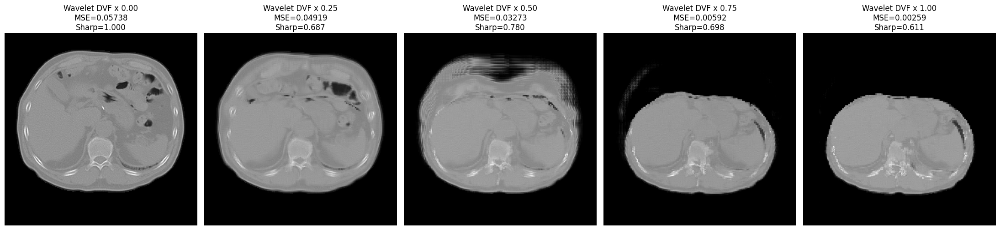

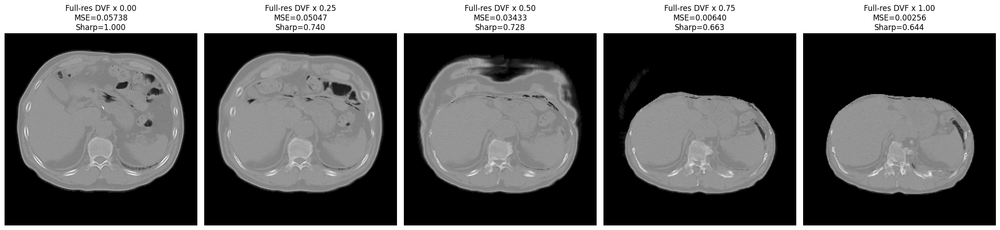

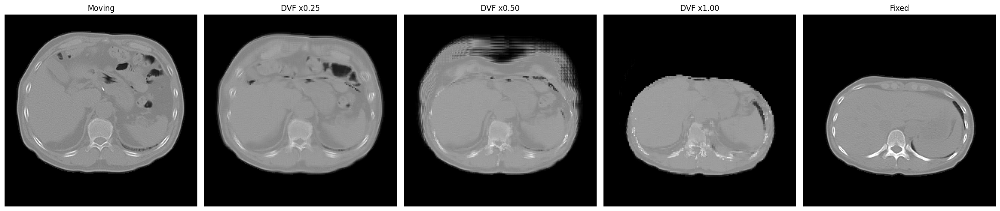

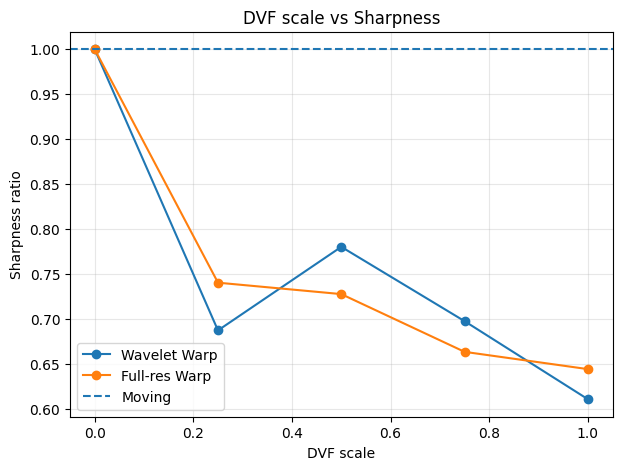

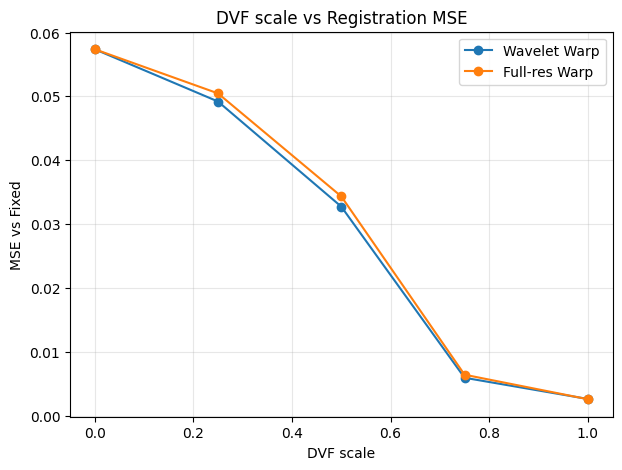


DIAGNOSIS
Wavelet sharpness:
  x0.25 = 0.6873
  x0.50 = 0.7802
  x1.00 = 0.6107

⚠ DVFを小さくすると画像が明確にシャープになります。
  → DVFの大きさが粗さの主要因である可能性が高いです。

DVF x1.0 の方がMSEは良いです。
ただしSharpnessを犠牲にしてMSEを下げている可能性があります。


VxmDense_128_256_256(
  (unet_model): Unet_128_256_128(
    (pooling): ModuleList(
      (0-5): 6 x MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (upsampling): ModuleList(
      (0-5): 6 x Upsample(scale_factor=2.0, mode='nearest')
    )
    (encoder_LLL): ModuleList(
      (0): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(2, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (1): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (2-4): 3 x ModuleList(
        (0): ConvBlock(
          (main): Conv3d(128, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
    )
    (encoder_L2H1): ModuleList(
      (0):

In [ ]:
# ============================================================
# DVF倍率比較
#
# 目的：
# learned_flow を
#
#   0.00
#   0.25
#   0.50
#   0.75
#   1.00
#
# 倍して、
#
# 1. Wavelet-space Warp
# 2. Full-resolution Warp
#
# の画像・MSE・Sharpnessを比較する
#
# 前提：
# 以下がすでに定義済み
#
# moving
# fixed
# moving_w
# learned_flow
# transformer
# transformer256
# up_sampling_3d
# synthesis_filter_3d
# synthesis_filters
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 0. 評価モード
# ============================================================

model3D.eval()


# ============================================================
# 1. 比較するDVF倍率
# ============================================================

flow_scales = [
    0.00,
    0.25,
    0.50,
    0.75,
    1.00
]


# ============================================================
# 2. Metric関数
# ============================================================

def calc_metrics(
    reference,
    image
):
    diff = reference - image

    mae = torch.mean(
        torch.abs(diff)
    ).item()

    mse = torch.mean(
        diff ** 2
    ).item()

    rmse = np.sqrt(
        mse
    )

    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse
    }


# ============================================================
# 3. Sharpness関数
# ============================================================

def gradient_sharpness(
    image
):
    dx = torch.abs(
        image[:, :, :, :, 1:]
        -
        image[:, :, :, :, :-1]
    ).mean()

    dy = torch.abs(
        image[:, :, :, 1:, :]
        -
        image[:, :, :, :-1, :]
    ).mean()

    dz = torch.abs(
        image[:, :, 1:, :, :]
        -
        image[:, :, :-1, :, :]
    ).mean()

    return (
        (dx + dy + dz) / 3.0
    ).item()


# ============================================================
# 4. Moving / FixedのSharpness
# ============================================================

sharp_moving = gradient_sharpness(
    moving
)

sharp_fixed = gradient_sharpness(
    fixed
)


# ============================================================
# 5. 結果格納
# ============================================================

wavelet_results = {}
fullres_results = {}


# ============================================================
# 6. 各DVF倍率でWarp
# ============================================================

with torch.no_grad():

    for scale in flow_scales:

        print()
        print("=" * 80)
        print(
            f"DVF SCALE = {scale:.2f}"
        )
        print("=" * 80)


        # ====================================================
        # Wavelet-space DVF
        # ====================================================

        scaled_flow = (
            learned_flow
            * scale
        )


        # ====================================================
        # Wavelet-space Warp
        # ====================================================

        warped_w = transformer(
            moving_w,
            scaled_flow
        )


        warped_w_up = up_sampling_3d(
            warped_w
        )


        wavelet_recon, _ = synthesis_filter_3d(
            warped_w_up,
            synthesis_filters
        )


        # ====================================================
        # Full-resolution DVF
        #
        # Wavelet voxel → Full-res voxel
        # 空間サイズ2倍なので変位量も ×2
        # ====================================================

        full_flow = F.interpolate(
            scaled_flow,
            size=(
                moving.shape[2],
                moving.shape[3],
                moving.shape[4]
            ),
            mode="trilinear",
            align_corners=False
        ) * 2.0


        # ====================================================
        # Full-resolution Warp
        # ====================================================

        full_warp = transformer256(
            moving,
            full_flow
        )


        # ====================================================
        # Wavelet metric
        # ====================================================

        wavelet_metric = calc_metrics(
            fixed,
            wavelet_recon
        )


        wavelet_sharp = gradient_sharpness(
            wavelet_recon
        )


        wavelet_results[
            scale
        ] = {
            "image": wavelet_recon.detach(),
            "MSE": wavelet_metric["MSE"],
            "MAE": wavelet_metric["MAE"],
            "RMSE": wavelet_metric["RMSE"],
            "sharpness": wavelet_sharp,
            "sharpness_ratio":
                wavelet_sharp
                / sharp_moving
        }


        # ====================================================
        # Full-resolution metric
        # ====================================================

        full_metric = calc_metrics(
            fixed,
            full_warp
        )


        full_sharp = gradient_sharpness(
            full_warp
        )


        fullres_results[
            scale
        ] = {
            "image": full_warp.detach(),
            "MSE": full_metric["MSE"],
            "MAE": full_metric["MAE"],
            "RMSE": full_metric["RMSE"],
            "sharpness": full_sharp,
            "sharpness_ratio":
                full_sharp
                / sharp_moving
        }


        # ====================================================
        # 表示
        # ====================================================

        print(
            "Wavelet Warp"
        )

        print(
            f"  MSE             : "
            f"{wavelet_metric['MSE']:.8f}"
        )

        print(
            f"  Sharpness       : "
            f"{wavelet_sharp:.8f}"
        )

        print(
            f"  Sharpness ratio : "
            f"{wavelet_sharp / sharp_moving:.4f}"
        )


        print()


        print(
            "Full-resolution Warp"
        )

        print(
            f"  MSE             : "
            f"{full_metric['MSE']:.8f}"
        )

        print(
            f"  Sharpness       : "
            f"{full_sharp:.8f}"
        )

        print(
            f"  Sharpness ratio : "
            f"{full_sharp / sharp_moving:.4f}"
        )


# ============================================================
# 7. 比較表
# ============================================================

print()
print("=" * 100)
print("SUMMARY")
print("=" * 100)

print(
    f"{'Scale':>8} "
    f"{'Wave MSE':>14} "
    f"{'Wave Sharp':>14} "
    f"{'Wave Ratio':>14} "
    f"{'Full MSE':>14} "
    f"{'Full Sharp':>14} "
    f"{'Full Ratio':>14}"
)

print("-" * 100)


for scale in flow_scales:

    wr = wavelet_results[
        scale
    ]

    fr = fullres_results[
        scale
    ]

    print(
        f"{scale:8.2f} "
        f"{wr['MSE']:14.8f} "
        f"{wr['sharpness']:14.8f} "
        f"{wr['sharpness_ratio']:14.4f} "
        f"{fr['MSE']:14.8f} "
        f"{fr['sharpness']:14.8f} "
        f"{fr['sharpness_ratio']:14.4f}"
    )


# ============================================================
# 8. 表示スライス
#
# 前回と同じslice_idxがあればそれを使う
# なければ中央
# ============================================================

if "slice_idx" not in globals():

    slice_idx = (
        moving.shape[2]
        // 2
    )


print()
print(
    "Display slice:",
    slice_idx
)


# ============================================================
# 9. Wavelet Warp比較
# ============================================================

plt.figure(
    figsize=(
        22,
        5
    )
)


for i, scale in enumerate(
    flow_scales
):

    image = wavelet_results[
        scale
    ]["image"]

    mse = wavelet_results[
        scale
    ]["MSE"]

    sharp_ratio = wavelet_results[
        scale
    ]["sharpness_ratio"]


    plt.subplot(
        1,
        len(flow_scales),
        i + 1
    )


    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .float()
        .cpu(),
        cmap="gray"
    )


    plt.title(
        f"Wavelet DVF x {scale:.2f}\n"
        f"MSE={mse:.5f}\n"
        f"Sharp={sharp_ratio:.3f}"
    )


    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 10. Full-resolution Warp比較
# ============================================================

plt.figure(
    figsize=(
        22,
        5
    )
)


for i, scale in enumerate(
    flow_scales
):

    image = fullres_results[
        scale
    ]["image"]

    mse = fullres_results[
        scale
    ]["MSE"]

    sharp_ratio = fullres_results[
        scale
    ]["sharpness_ratio"]


    plt.subplot(
        1,
        len(flow_scales),
        i + 1
    )


    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .float()
        .cpu(),
        cmap="gray"
    )


    plt.title(
        f"Full-res DVF x {scale:.2f}\n"
        f"MSE={mse:.5f}\n"
        f"Sharp={sharp_ratio:.3f}"
    )


    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 11. Moving / Fixed / DVF倍率比較
# ============================================================

comparison_images = [
    (
        "Moving",
        moving
    ),
    (
        "DVF x0.25",
        wavelet_results[
            0.25
        ]["image"]
    ),
    (
        "DVF x0.50",
        wavelet_results[
            0.50
        ]["image"]
    ),
    (
        "DVF x1.00",
        wavelet_results[
            1.00
        ]["image"]
    ),
    (
        "Fixed",
        fixed
    )
]


plt.figure(
    figsize=(
        22,
        5
    )
)


for i, (
    title,
    image
) in enumerate(
    comparison_images
):

    plt.subplot(
        1,
        5,
        i + 1
    )

    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .detach()
        .float()
        .cpu(),
        cmap="gray"
    )

    plt.title(
        title
    )

    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 12. DVF倍率とSharpnessの関係
# ============================================================

wavelet_sharp_ratios = [
    wavelet_results[
        scale
    ]["sharpness_ratio"]
    for scale in flow_scales
]


full_sharp_ratios = [
    fullres_results[
        scale
    ]["sharpness_ratio"]
    for scale in flow_scales
]


plt.figure(
    figsize=(
        7,
        5
    )
)


plt.plot(
    flow_scales,
    wavelet_sharp_ratios,
    marker="o",
    label="Wavelet Warp"
)


plt.plot(
    flow_scales,
    full_sharp_ratios,
    marker="o",
    label="Full-res Warp"
)


plt.axhline(
    1.0,
    linestyle="--",
    label="Moving"
)


plt.xlabel(
    "DVF scale"
)

plt.ylabel(
    "Sharpness ratio"
)

plt.title(
    "DVF scale vs Sharpness"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.show()


# ============================================================
# 13. DVF倍率とMSEの関係
# ============================================================

wavelet_mses = [
    wavelet_results[
        scale
    ]["MSE"]
    for scale in flow_scales
]


full_mses = [
    fullres_results[
        scale
    ]["MSE"]
    for scale in flow_scales
]


plt.figure(
    figsize=(
        7,
        5
    )
)


plt.plot(
    flow_scales,
    wavelet_mses,
    marker="o",
    label="Wavelet Warp"
)


plt.plot(
    flow_scales,
    full_mses,
    marker="o",
    label="Full-res Warp"
)


plt.xlabel(
    "DVF scale"
)

plt.ylabel(
    "MSE vs Fixed"
)

plt.title(
    "DVF scale vs Registration MSE"
)

plt.grid(
    alpha=0.3
)

plt.legend()

plt.show()


# ============================================================
# 14. 簡易診断
# ============================================================

print()
print("=" * 80)
print("DIAGNOSIS")
print("=" * 80)


sharp_025 = wavelet_results[
    0.25
]["sharpness_ratio"]

sharp_050 = wavelet_results[
    0.50
]["sharpness_ratio"]

sharp_100 = wavelet_results[
    1.00
]["sharpness_ratio"]


mse_025 = wavelet_results[
    0.25
]["MSE"]

mse_050 = wavelet_results[
    0.50
]["MSE"]

mse_100 = wavelet_results[
    1.00
]["MSE"]


print(
    f"Wavelet sharpness:"
)

print(
    f"  x0.25 = {sharp_025:.4f}"
)

print(
    f"  x0.50 = {sharp_050:.4f}"
)

print(
    f"  x1.00 = {sharp_100:.4f}"
)


print()


if (
    sharp_050
    >
    sharp_100 + 0.10
):

    print(
        "⚠ DVFを小さくすると画像が明確にシャープになります。"
    )

    print(
        "  → DVFの大きさが粗さの主要因である可能性が高いです。"
    )

else:

    print(
        "DVF倍率を小さくしてもSharpnessの改善は限定的です。"
    )

    print(
        "→ DVF magnitude以外の原因も確認した方がよいです。"
    )


print()


if (
    mse_100
    <
    mse_050
):

    print(
        "DVF x1.0 の方がMSEは良いです。"
    )

    print(
        "ただしSharpnessを犠牲にしてMSEを下げている可能性があります。"
    )

elif (
    mse_050
    <
    mse_100
):

    print(
        "DVF x0.5 の方がMSEも良いです。"
    )

    print(
        "→ 現在のDVFが過大になっている可能性がかなり高いです。"
    )


print("=" * 80)


# ============================================================
# Training modeに戻す
# ============================================================

model3D.train()


JACOBIAN DETERMINANT
Mean : 0.980790
Std  : 2.235787

P01  : -2.409994
P05  : -0.575476
P95  : 3.019343
P99  : 7.811917

Min  : -134.728622
Max  : 110.624664

FOLDING / COMPRESSION / EXPANSION
Jacobian <= 0  : 12.9966%
Jacobian < 0.5 : 31.6315%
Jacobian < 0.2 : 18.5500%
Jacobian > 2.0 : 10.2758%
Jacobian > 5.0 : 2.0888%

DVF GRADIENT
Mean absolute gradient : 0.368819
Maximum gradient       : 20.867321


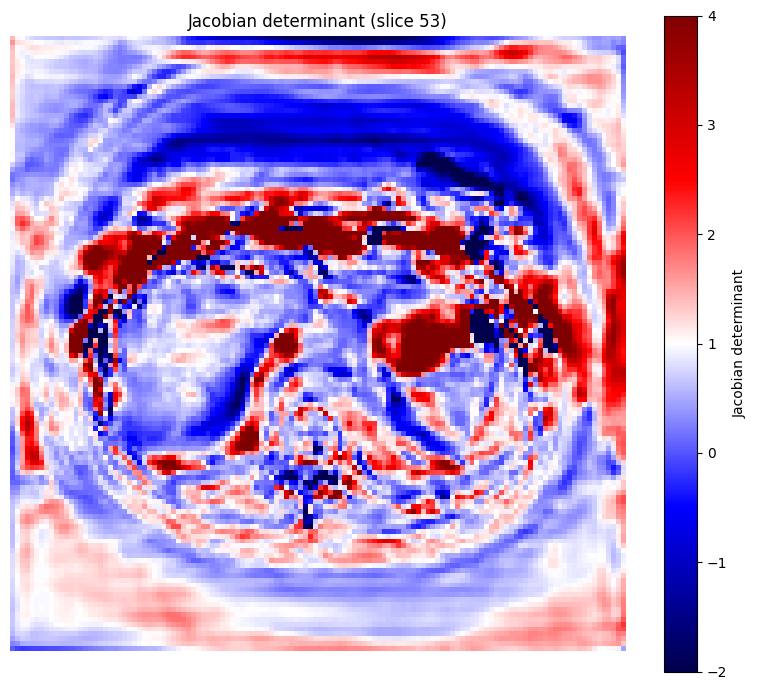

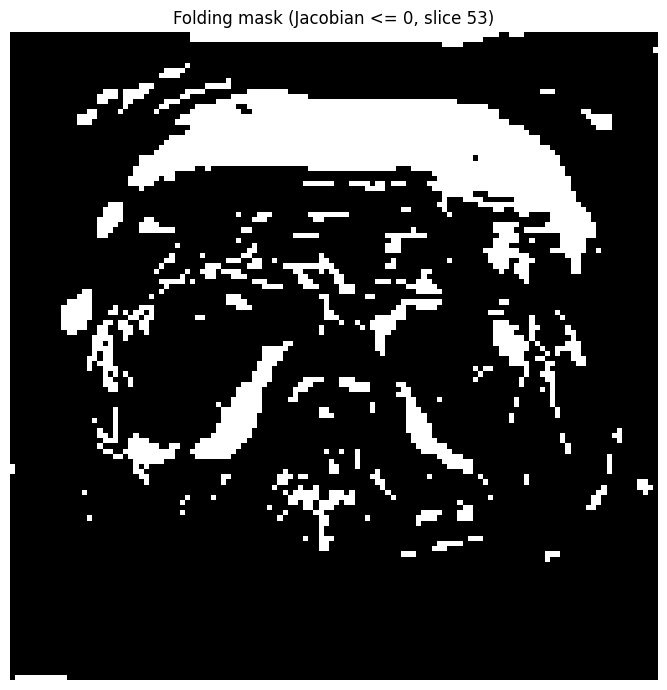


DIAGNOSIS
⚠ Foldingがかなり多いです。
  DVFの非滑らかさが画像崩れの主要因である可能性が高いです。

⚠ 強い局所圧縮が多数存在します。


In [ ]:
# ============================================================
# DVF Jacobian / Folding 診断
#
# learned_flow:
#   (B, 3, 64, 128, 128)
#
# 目的：
# ・Jacobian determinant
# ・folding率
# ・極端な圧縮 / 膨張
# ・DVF gradient
# を確認
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 1. Jacobian determinant
# ============================================================

def jacobian_determinant_3d(flow):

    """
    flow : (B, 3, D, H, W)

    deformation:
        phi(x) = x + flow(x)

    Jacobian:
        J_phi = I + grad(flow)
    """

    # --------------------------------------------------------
    # flow components
    # --------------------------------------------------------

    u = flow[:, 0]
    v = flow[:, 1]
    w = flow[:, 2]


    # --------------------------------------------------------
    # central difference
    #
    # 境界1voxelは除外
    # --------------------------------------------------------

    du_dz = (
        u[:, 2:, 1:-1, 1:-1]
        -
        u[:, :-2, 1:-1, 1:-1]
    ) / 2.0

    du_dy = (
        u[:, 1:-1, 2:, 1:-1]
        -
        u[:, 1:-1, :-2, 1:-1]
    ) / 2.0

    du_dx = (
        u[:, 1:-1, 1:-1, 2:]
        -
        u[:, 1:-1, 1:-1, :-2]
    ) / 2.0


    dv_dz = (
        v[:, 2:, 1:-1, 1:-1]
        -
        v[:, :-2, 1:-1, 1:-1]
    ) / 2.0

    dv_dy = (
        v[:, 1:-1, 2:, 1:-1]
        -
        v[:, 1:-1, :-2, 1:-1]
    ) / 2.0

    dv_dx = (
        v[:, 1:-1, 1:-1, 2:]
        -
        v[:, 1:-1, 1:-1, :-2]
    ) / 2.0


    dw_dz = (
        w[:, 2:, 1:-1, 1:-1]
        -
        w[:, :-2, 1:-1, 1:-1]
    ) / 2.0

    dw_dy = (
        w[:, 1:-1, 2:, 1:-1]
        -
        w[:, 1:-1, :-2, 1:-1]
    ) / 2.0

    dw_dx = (
        w[:, 1:-1, 1:-1, 2:]
        -
        w[:, 1:-1, 1:-1, :-2]
    ) / 2.0


    # ========================================================
    # J = I + grad(flow)
    #
    # [1+du/dx   du/dy     du/dz]
    # [dv/dx     1+dv/dy   dv/dz]
    # [dw/dx     dw/dy     1+dw/dz]
    # ========================================================

    J11 = 1.0 + du_dx
    J12 = du_dy
    J13 = du_dz

    J21 = dv_dx
    J22 = 1.0 + dv_dy
    J23 = dv_dz

    J31 = dw_dx
    J32 = dw_dy
    J33 = 1.0 + dw_dz


    # ========================================================
    # determinant
    # ========================================================

    detJ = (
        J11 * (
            J22 * J33
            -
            J23 * J32
        )
        -
        J12 * (
            J21 * J33
            -
            J23 * J31
        )
        +
        J13 * (
            J21 * J32
            -
            J22 * J31
        )
    )

    return detJ


# ============================================================
# 2. Calculate Jacobian
# ============================================================

with torch.no_grad():

    detJ = jacobian_determinant_3d(
        learned_flow.float()
    )


# ============================================================
# 3. Statistics
# ============================================================

det_flat = detJ.flatten()


jac_mean = det_flat.mean().item()
jac_std = det_flat.std().item()

jac_min = det_flat.min().item()
jac_max = det_flat.max().item()

jac_p01 = torch.quantile(
    det_flat,
    0.01
).item()

jac_p05 = torch.quantile(
    det_flat,
    0.05
).item()

jac_p95 = torch.quantile(
    det_flat,
    0.95
).item()

jac_p99 = torch.quantile(
    det_flat,
    0.99
).item()


# ============================================================
# 4. Folding
# ============================================================

folding_mask = (
    detJ <= 0
)


folding_ratio = (
    folding_mask.float().mean().item()
    * 100
)


# ============================================================
# 5. Strong compression / expansion
# ============================================================

compression_ratio = (
    (detJ < 0.5)
    .float()
    .mean()
    .item()
    * 100
)


strong_compression_ratio = (
    (detJ < 0.2)
    .float()
    .mean()
    .item()
    * 100
)


expansion_ratio = (
    (detJ > 2.0)
    .float()
    .mean()
    .item()
    * 100
)


strong_expansion_ratio = (
    (detJ > 5.0)
    .float()
    .mean()
    .item()
    * 100
)


# ============================================================
# 6. 表示
# ============================================================

print()
print("=" * 80)
print("JACOBIAN DETERMINANT")
print("=" * 80)

print(
    f"Mean : {jac_mean:.6f}"
)

print(
    f"Std  : {jac_std:.6f}"
)

print()

print(
    f"P01  : {jac_p01:.6f}"
)

print(
    f"P05  : {jac_p05:.6f}"
)

print(
    f"P95  : {jac_p95:.6f}"
)

print(
    f"P99  : {jac_p99:.6f}"
)

print()

print(
    f"Min  : {jac_min:.6f}"
)

print(
    f"Max  : {jac_max:.6f}"
)


print()
print("=" * 80)
print("FOLDING / COMPRESSION / EXPANSION")
print("=" * 80)

print(
    f"Jacobian <= 0  : "
    f"{folding_ratio:.4f}%"
)

print(
    f"Jacobian < 0.5 : "
    f"{compression_ratio:.4f}%"
)

print(
    f"Jacobian < 0.2 : "
    f"{strong_compression_ratio:.4f}%"
)

print(
    f"Jacobian > 2.0 : "
    f"{expansion_ratio:.4f}%"
)

print(
    f"Jacobian > 5.0 : "
    f"{strong_expansion_ratio:.4f}%"
)


# ============================================================
# 7. DVF gradient magnitude
# ============================================================

flow = learned_flow.float()


grad_z = (
    flow[:, :, 1:, :, :]
    -
    flow[:, :, :-1, :, :]
)


grad_y = (
    flow[:, :, :, 1:, :]
    -
    flow[:, :, :, :-1, :]
)


grad_x = (
    flow[:, :, :, :, 1:]
    -
    flow[:, :, :, :, :-1]
)


grad_mean = (
    grad_x.abs().mean()
    +
    grad_y.abs().mean()
    +
    grad_z.abs().mean()
) / 3.0


grad_max = torch.stack([
    grad_x.abs().max(),
    grad_y.abs().max(),
    grad_z.abs().max()
]).max()


print()
print("=" * 80)
print("DVF GRADIENT")
print("=" * 80)

print(
    f"Mean absolute gradient : "
    f"{grad_mean.item():.6f}"
)

print(
    f"Maximum gradient       : "
    f"{grad_max.item():.6f}"
)


# ============================================================
# 8. Jacobian画像
# ============================================================

jac_slice = min(
    slice_idx // 2,
    detJ.shape[1] - 1
)


plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    detJ[
        0,
        jac_slice
    ]
    .detach()
    .cpu(),
    cmap="seismic",
    vmin=-2,
    vmax=4
)


plt.colorbar(
    label="Jacobian determinant"
)


plt.title(
    f"Jacobian determinant "
    f"(slice {jac_slice})"
)


plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ============================================================
# 9. Foldingだけ表示
# ============================================================

plt.figure(
    figsize=(8, 7)
)


plt.imshow(
    folding_mask[
        0,
        jac_slice
    ]
    .detach()
    .cpu(),
    cmap="gray"
)


plt.title(
    f"Folding mask "
    f"(Jacobian <= 0, slice {jac_slice})"
)


plt.axis(
    "off"
)

plt.tight_layout()

plt.show()


# ============================================================
# 10. 判定
# ============================================================

print()
print("=" * 80)
print("DIAGNOSIS")
print("=" * 80)


if folding_ratio > 5:

    print(
        "⚠ Foldingがかなり多いです。"
    )

    print(
        "  DVFの非滑らかさが画像崩れの"
        "主要因である可能性が高いです。"
    )


elif folding_ratio > 1:

    print(
        "⚠ Foldingが確認されます。"
    )

    print(
        "  DVFのregularizationを"
        "追加・強化する価値があります。"
    )


else:

    print(
        "✓ Folding率は比較的小さいです。"
    )


print()


if (
    strong_compression_ratio > 5
):

    print(
        "⚠ 強い局所圧縮が多数存在します。"
    )


if (
    strong_expansion_ratio > 5
):

    print(
        "⚠ 強い局所膨張が多数存在します。"
    )


print("=" * 80)

Input
Moving: torch.Size([1, 1, 128, 256, 256])
Fixed : torch.Size([1, 1, 128, 256, 256])

Wavelet
Moving wavelet: torch.Size([1, 8, 64, 128, 128])
Fixed wavelet : torch.Size([1, 8, 64, 128, 128])

Learned DVF
Shape: torch.Size([1, 3, 64, 128, 128])
Full-resolution DVF: torch.Size([1, 3, 128, 256, 256])

1. ZERO-FLOW RECONSTRUCTION
Moving vs Zero-flow reconstruction
MAE     : 0.0000000588
MSE     : 0.0000000000
RMSE    : 0.0000001685
MaxAbs  : 0.0000098348

2. REGISTRATION ERROR

Wavelet-space warp vs Fixed
MAE     : 0.0577869415
MSE     : 0.0187861845
RMSE    : 0.1370627028
MaxAbs  : 1.0000000000

Full-resolution warp vs Fixed
MAE     : 0.0591347441
MSE     : 0.0196171757
RMSE    : 0.1400613283
MaxAbs  : 1.0000000000

3. WAVELET WARP vs FULL-RESOLUTION WARP
MAE     : 0.0094635915
MSE     : 0.0006691209
RMSE    : 0.0258673719
MaxAbs  : 0.7704805732

4. SHARPNESS
Moving          : 0.01345401
Fixed           : 0.01647437
Zero-flow recon : 0.01345399
Wavelet warp    : 0.01082164
Full-res 

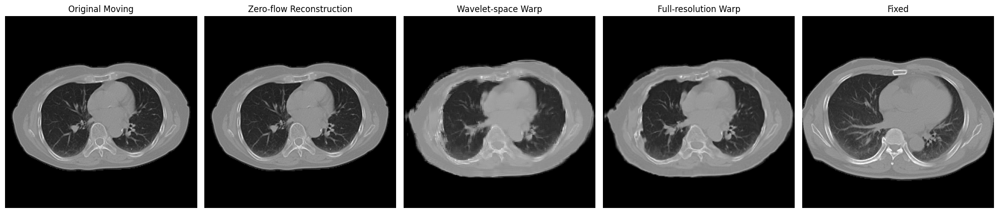

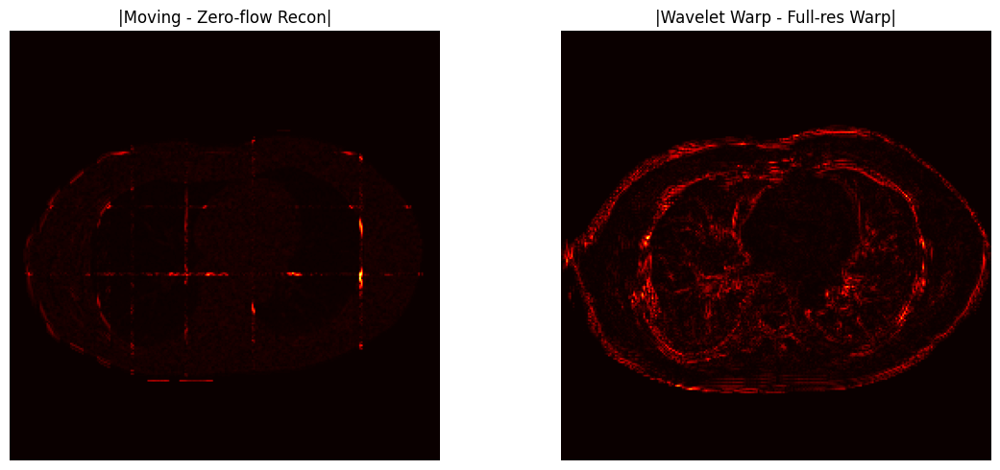


DIAGNOSTIC
✓ Zero-flow reconstruction error is small.
  → Wavelet Analysis/Synthesis itself is unlikely to be the main cause.

✓ Wavelet-space and Full-resolution sharpness are relatively similar.

✓ Zero-flow reconstruction preserves most of the original sharpness.


VxmDense_128_256_256(
  (unet_model): Unet_128_256_128(
    (pooling): ModuleList(
      (0-5): 6 x MaxPool3d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    )
    (upsampling): ModuleList(
      (0-5): 6 x Upsample(scale_factor=2.0, mode='nearest')
    )
    (encoder_LLL): ModuleList(
      (0): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(2, 64, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (1): ModuleList(
        (0): ConvBlock(
          (main): Conv3d(64, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
      (2-4): 3 x ModuleList(
        (0): ConvBlock(
          (main): Conv3d(128, 128, kernel_size=(3, 3, 3), stride=(1, 1, 1), padding=(1, 1, 1))
          (activation): LeakyReLU(negative_slope=0.2)
        )
      )
    )
    (encoder_L2H1): ModuleList(
      (0):

In [ ]:
# ============================================================
# Reconstruction / Blur Diagnostic
#
# 目的：
#
# ① Original Moving
# ② Zero-flow Wavelet reconstruction
# ③ Learned DVF + Wavelet-space warp
# ④ Learned DVF + Full-resolution warp
# ⑤ Fixed
#
# を比較して、どこで画像が粗くなっているか確認する
# ============================================================

import torch
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 0. Evaluation mode
# ============================================================

model3D.eval()


with torch.no_grad():

    # ========================================================
    # 1. 観察画像
    # ========================================================

    moving = obs_moving.to(
        device=device,
        dtype=torch.float32
    )

    fixed = obs_fixed.to(
        device=device,
        dtype=torch.float32
    )


    print("=" * 70)
    print("Input")
    print("=" * 70)

    print(
        "Moving:",
        moving.shape
    )

    print(
        "Fixed :",
        fixed.shape
    )


    # ========================================================
    # 2. Wavelet Analysis
    # ========================================================

    moving_analysis = analysis_filter_3d(
        moving,
        analysis
    )

    fixed_analysis = analysis_filter_3d(
        fixed,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    fixed_w = down_sampling_3d(
        fixed_analysis
    ).to(device)


    print()
    print("=" * 70)
    print("Wavelet")
    print("=" * 70)

    print(
        "Moving wavelet:",
        moving_w.shape
    )

    print(
        "Fixed wavelet :",
        fixed_w.shape
    )


    # ========================================================
    # 3. Zero-flow reconstruction
    #
    # DVF = 0
    #
    # Moving
    #   ↓
    # Analysis
    #   ↓
    # Downsample
    #   ↓
    # zero DVF
    #   ↓
    # Upsample
    #   ↓
    # Synthesis
    #
    # ここで粗ければWavelet再構成側が怪しい
    # ========================================================

    zero_flow = torch.zeros(
        (
            moving.shape[0],
            3,
            64,
            128,
            128
        ),
        dtype=torch.float32,
        device=device
    )


    zero_warped = transformer(
        moving_w,
        zero_flow
    )


    zero_warped_up = up_sampling_3d(
        zero_warped
    )


    (
        zero_reconstructed,
        _
    ) = synthesis_filter_3d(
        zero_warped_up,
        synthesis_filters
    )


    # ========================================================
    # 4. Learned DVF
    # ========================================================

    learned_flow = model3D(
        moving_w,
        fixed_w
    )


    print()
    print("=" * 70)
    print("Learned DVF")
    print("=" * 70)

    print(
        "Shape:",
        learned_flow.shape
    )


    # ========================================================
    # 5. Wavelet-space warp
    #
    # 今の研究手法そのもの
    # ========================================================

    wavelet_warped = transformer(
        moving_w,
        learned_flow
    )


    wavelet_warped_up = up_sampling_3d(
        wavelet_warped
    )


    (
        reconstructed_wavelet_warp,
        _
    ) = synthesis_filter_3d(
        wavelet_warped_up,
        synthesis_filters
    )


    # ========================================================
    # 6. DVFをFull-resolutionへ拡大
    #
    # (64,128,128)
    #       ↓
    # (128,256,256)
    #
    # 注意：
    #
    # Wavelet空間 1 voxel
    # =
    # Full-resolution 2 voxel
    #
    # なので ×2
    # ========================================================

    learned_flow_full = F.interpolate(
        learned_flow.float(),
        size=(
            128,
            256,
            256
        ),
        mode="trilinear",
        align_corners=False
    ) * 2.0


    print(
        "Full-resolution DVF:",
        learned_flow_full.shape
    )


    # ========================================================
    # 7. Full-resolution warp
    #
    # Wavelet係数ではなく元画像を直接warp
    #
    # これが綺麗でWavelet版だけ粗ければ、
    # Wavelet-space interpolationが原因の可能性が高い
    # ========================================================

    fullres_warped = transformer256(
        moving,
        learned_flow_full
    )


# ============================================================
# 8. Metrics functions
# ============================================================

def calc_metrics(
    reference,
    image
):

    diff = (
        reference
        - image
    )


    mae = torch.mean(
        torch.abs(diff)
    ).item()


    mse = torch.mean(
        diff ** 2
    ).item()


    rmse = np.sqrt(
        mse
    )


    max_abs = torch.max(
        torch.abs(diff)
    ).item()


    return {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "MaxAbs": max_abs
    }


# ============================================================
# 9. Sharpness
#
# 隣接voxel差の平均
#
# 大きい
# → エッジ・細部が多い
#
# 小さい
# → ぼけている可能性
# ============================================================

def calc_gradient_sharpness(
    image
):

    dz = torch.abs(
        image[:, :, 1:, :, :]
        - image[:, :, :-1, :, :]
    ).mean()


    dy = torch.abs(
        image[:, :, :, 1:, :]
        - image[:, :, :, :-1, :]
    ).mean()


    dx = torch.abs(
        image[:, :, :, :, 1:]
        - image[:, :, :, :, :-1]
    ).mean()


    sharpness = (
        dx
        + dy
        + dz
    ) / 3.0


    return sharpness.item()


# ============================================================
# 10. Zero-flow reconstruction error
#
# Movingと比較
# ============================================================

zero_metrics = calc_metrics(
    moving,
    zero_reconstructed
)


# ============================================================
# 11. Registration MSE
#
# Fixedと比較
# ============================================================

wavelet_metrics = calc_metrics(
    fixed,
    reconstructed_wavelet_warp
)


fullres_metrics = calc_metrics(
    fixed,
    fullres_warped
)


# ============================================================
# 12. Wavelet warp vs Full-res warp
# ============================================================

warp_difference = calc_metrics(
    fullres_warped,
    reconstructed_wavelet_warp
)


# ============================================================
# 13. Sharpness
# ============================================================

sharp_moving = calc_gradient_sharpness(
    moving
)

sharp_fixed = calc_gradient_sharpness(
    fixed
)

sharp_zero = calc_gradient_sharpness(
    zero_reconstructed
)

sharp_wavelet = calc_gradient_sharpness(
    reconstructed_wavelet_warp
)

sharp_fullres = calc_gradient_sharpness(
    fullres_warped
)


# ============================================================
# 14. Numerical results
# ============================================================

print()
print("=" * 70)
print("1. ZERO-FLOW RECONSTRUCTION")
print("=" * 70)

print(
    "Moving vs Zero-flow reconstruction"
)

for key, value in zero_metrics.items():

    print(
        f"{key:8s}: {value:.10f}"
    )


print()
print("=" * 70)
print("2. REGISTRATION ERROR")
print("=" * 70)

print()
print("Wavelet-space warp vs Fixed")

for key, value in wavelet_metrics.items():

    print(
        f"{key:8s}: {value:.10f}"
    )


print()
print("Full-resolution warp vs Fixed")

for key, value in fullres_metrics.items():

    print(
        f"{key:8s}: {value:.10f}"
    )


print()
print("=" * 70)
print("3. WAVELET WARP vs FULL-RESOLUTION WARP")
print("=" * 70)

for key, value in warp_difference.items():

    print(
        f"{key:8s}: {value:.10f}"
    )


print()
print("=" * 70)
print("4. SHARPNESS")
print("=" * 70)

print(
    f"Moving          : {sharp_moving:.8f}"
)

print(
    f"Fixed           : {sharp_fixed:.8f}"
)

print(
    f"Zero-flow recon : {sharp_zero:.8f}"
)

print(
    f"Wavelet warp    : {sharp_wavelet:.8f}"
)

print(
    f"Full-res warp   : {sharp_fullres:.8f}"
)


# ============================================================
# 15. Sharpness ratio
#
# Moving = 1.0
# ============================================================

print()
print("=" * 70)
print("5. SHARPNESS RATIO (Moving = 1.0)")
print("=" * 70)

print(
    f"Zero-flow recon : "
    f"{sharp_zero / sharp_moving:.4f}"
)

print(
    f"Wavelet warp    : "
    f"{sharp_wavelet / sharp_moving:.4f}"
)

print(
    f"Full-res warp   : "
    f"{sharp_fullres / sharp_moving:.4f}"
)


# ============================================================
# 16. Visualization
# ============================================================

slice_idx = moving.shape[2] // 2


images = [

    (
        "Original Moving",
        moving
    ),

    (
        "Zero-flow Reconstruction",
        zero_reconstructed
    ),

    (
        "Wavelet-space Warp",
        reconstructed_wavelet_warp
    ),

    (
        "Full-resolution Warp",
        fullres_warped
    ),

    (
        "Fixed",
        fixed
    ),
]


plt.figure(
    figsize=(
        20,
        5
    )
)


for i, (
    title,
    image
) in enumerate(
    images
):

    plt.subplot(
        1,
        5,
        i + 1
    )


    plt.imshow(
        image[
            0,
            0,
            slice_idx
        ]
        .detach()
        .float()
        .cpu(),
        cmap="gray"
    )


    plt.title(
        title
    )

    plt.axis(
        "off"
    )


plt.tight_layout()

plt.show()


# ============================================================
# 17. Difference image
# ============================================================

diff_zero = torch.abs(
    moving
    - zero_reconstructed
)


diff_wavelet_vs_full = torch.abs(
    reconstructed_wavelet_warp
    - fullres_warped
)


plt.figure(
    figsize=(
        12,
        5
    )
)


plt.subplot(
    1,
    2,
    1
)

plt.imshow(
    diff_zero[
        0,
        0,
        slice_idx
    ]
    .detach()
    .float()
    .cpu(),
    cmap="hot"
)

plt.title(
    "|Moving - Zero-flow Recon|"
)

plt.axis(
    "off"
)


plt.subplot(
    1,
    2,
    2
)

plt.imshow(
    diff_wavelet_vs_full[
        0,
        0,
        slice_idx
    ]
    .detach()
    .float()
    .cpu(),
    cmap="hot"
)

plt.title(
    "|Wavelet Warp - Full-res Warp|"
)

plt.axis(
    "off"
)


plt.tight_layout()

plt.show()


# ============================================================
# 18. Automatic interpretation
# ============================================================

print()
print("=" * 70)
print("DIAGNOSTIC")
print("=" * 70)


zero_ratio = (
    sharp_zero
    / sharp_moving
)


wavelet_ratio = (
    sharp_wavelet
    / sharp_moving
)


fullres_ratio = (
    sharp_fullres
    / sharp_moving
)


if zero_metrics["MAE"] < 1e-3:

    print(
        "✓ Zero-flow reconstruction error is small."
    )

    print(
        "  → Wavelet Analysis/Synthesis itself is "
        "unlikely to be the main cause."
    )

else:

    print(
        "⚠ Zero-flow reconstruction error is relatively large."
    )

    print(
        "  → Check Analysis / Downsampling / "
        "Upsampling / Synthesis first."
    )


print()


if (
    wavelet_ratio
    < fullres_ratio * 0.95
):

    print(
        "⚠ Wavelet-space warp is noticeably "
        "less sharp than Full-resolution warp."
    )

    print(
        "  → Wavelet-space DVF interpolation / "
        "coarse resolution may be causing blur."
    )

else:

    print(
        "✓ Wavelet-space and Full-resolution "
        "sharpness are relatively similar."
    )


print()


if (
    zero_ratio
    > 0.98
):

    print(
        "✓ Zero-flow reconstruction preserves "
        "most of the original sharpness."
    )

else:

    print(
        "⚠ Sharpness already decreases during "
        "zero-flow reconstruction."
    )


print(
    "=" * 70
)


# ============================================================
# Training modeへ戻す
# ============================================================

model3D.train()

In [ ]:
# ============================================================
# SPEED BOTTLENECK DIAGNOSTIC
#
# 目的:
#   1epoch ≈ 5 sec の原因を完全に切り分ける
#
# 測定:
#   1. CPU batch preparation
#   2. CPU -> GPU transfer
#   3. VoxelMorph forward
#   4. Wavelet warp
#   5. Upsampling + Synthesis
#   6. Loss
#   7. Backward
#   8. Gradient clipping
#   9. Optimizer step
#  10. Total epoch
#
# 前提:
#   vxm
#   nb_features
#   analysis
#   synthesis_filters
#   analysis_filter_3d
#   down_sampling_3d
#   up_sampling_3d
#   synthesis_filter_3d
#
# がすでに定義済み
# ============================================================

from pathlib import Path
import gc
import time

import numpy as np
import torch
import torch.optim as optim

from tqdm.notebook import tqdm


# ============================================================
# 0. SETTINGS
# ============================================================

DATA_DIR = Path("Data")

RAW_DATA_PATH = (
    DATA_DIR
    / "TrainData_NoBed.npz"
)

PRETRAINED_PATH = Path(
    "model_DVF_pretrain_final.pth"
)


WARMUP_EPOCHS = 5

MEASURE_EPOCHS = 20

BATCH_SIZE = 2

LEARNING_RATE = 1e-6

SMOOTHNESS_WEIGHT = 0.01

PAIR_SEED = 42

WAVELET_PRECOMPUTE_BATCH = 2


# ============================================================
# 1. DEVICE
# ============================================================

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

use_amp = (
    device.type == "cuda"
)


if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


print("=" * 80)
print("DEVICE")
print("=" * 80)

print("Device:", device)
print("CUDA  :", torch.cuda.is_available())

if torch.cuda.is_available():

    print(
        "GPU   :",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM  :",
        round(
            torch.cuda.get_device_properties(0)
            .total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

print("AMP   :", use_amp)


# ============================================================
# 2. DATA CANDIDATES
# ============================================================

MASKED_ARCHIVE_CANDIDATES = [

    DATA_DIR
    / "TrainData_NoBed_LungMasked.npz",

    DATA_DIR
    / "TrainData_NoBed_lung_masked.npz",

    DATA_DIR
    / "TrainData_NoBed_Masked.npz",

    DATA_DIR
    / "TrainData_NoBed_masked.npz",
]


VOLUME_KEYS = (

    "Train_lung_masked",

    "train_lung_masked",

    "TrainMasked",

    "masked_train",

    "Train",
)


MASK_KEYS = (

    "Train_lung_mask",

    "train_lung_mask",

    "LungMask",

    "lung_mask",

    "TrainMask",

    "train_mask",

    "Mask",

    "mask",
)


# ============================================================
# 3. DATA HELPERS
# ============================================================

def to_n_dhw(
    array,
    label
):

    array = np.asarray(
        array,
        dtype=np.float32
    )


    if array.ndim != 4:

        raise ValueError(
            f"{label}: expected 4-D, "
            f"got {array.shape}"
        )


    if array.shape[1:] == (
        128,
        256,
        256
    ):

        return array


    if array.shape[:3] == (
        128,
        256,
        256
    ):

        return np.transpose(
            array,
            (3,0,1,2)
        )


    if array.shape[1:] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (0,3,1,2)
        )


    if array.shape[:3] == (
        256,
        256,
        128
    ):

        return np.transpose(
            array,
            (3,2,0,1)
        )


    raise ValueError(
        f"{label}: unsupported shape "
        f"{array.shape}"
    )


def first_available_key(
    archive,
    candidates
):

    for key in candidates:

        if key in archive.files:

            return key

    return None


# ============================================================
# 4. LOAD DATA
# ============================================================

def load_training_data():

    masked_path = next(
        (
            p
            for p in MASKED_ARCHIVE_CANDIDATES
            if p.exists()
        ),
        None
    )


    archive_path = (
        masked_path
        if masked_path is not None
        else RAW_DATA_PATH
    )


    if not archive_path.exists():

        raise FileNotFoundError(
            f"Training data not found:\n"
            f"{archive_path.resolve()}"
        )


    with np.load(
        archive_path,
        allow_pickle=False
    ) as archive:


        volume_key = first_available_key(
            archive,
            VOLUME_KEYS
        )


        if volume_key is None:

            raise KeyError(
                f"No volume key found.\n"
                f"Available: {archive.files}"
            )


        volumes = to_n_dhw(
            archive[volume_key],
            volume_key
        )


        mask_key = first_available_key(
            archive,
            MASK_KEYS
        )


        if mask_key is None:

            masks = None

        else:

            masks = to_n_dhw(
                archive[mask_key],
                mask_key
            )

            masks = (
                masks > 0
            )


    if masks is not None:

        if masks.shape != volumes.shape:

            raise ValueError(
                f"Mismatch: "
                f"{volumes.shape} "
                f"vs "
                f"{masks.shape}"
            )


        volumes = (
            volumes
            *
            masks
        ).astype(
            np.float32,
            copy=False
        )


    return (
        volumes,
        masks,
        archive_path
    )


(
    volumes,
    lung_masks,
    archive_path
) = load_training_data()


volumes_cpu = torch.from_numpy(
    volumes
)


if lung_masks is None:

    masks_cpu = None

else:

    masks_cpu = torch.from_numpy(
        lung_masks
    )


N_PATIENTS = len(
    volumes_cpu
)


print()
print("=" * 80)
print("DATA")
print("=" * 80)

print(
    "Archive:",
    archive_path
)

print(
    "Volumes:",
    volumes_cpu.shape,
    volumes_cpu.dtype
)

print(
    "Masks:",
    None
    if masks_cpu is None
    else (
        masks_cpu.shape,
        masks_cpu.dtype
    )
)


# ============================================================
# 5. CREATE TEST PAIRS
# ============================================================

rng = np.random.default_rng(
    PAIR_SEED
)


TOTAL_EPOCHS = (
    WARMUP_EPOCHS
    +
    MEASURE_EPOCHS
)


moving_indices = []

fixed_indices = []


for _ in range(
    TOTAL_EPOCHS
):


    moving_ids = rng.integers(
        0,
        N_PATIENTS,
        size=BATCH_SIZE
    )


    fixed_ids = rng.integers(
        0,
        N_PATIENTS,
        size=BATCH_SIZE
    )


    same = (
        moving_ids
        ==
        fixed_ids
    )


    while np.any(
        same
    ):

        fixed_ids[
            same
        ] = rng.integers(
            0,
            N_PATIENTS,
            size=int(
                same.sum()
            )
        )

        same = (
            moving_ids
            ==
            fixed_ids
        )


    moving_indices.append(
        moving_ids
    )

    fixed_indices.append(
        fixed_ids
    )


moving_indices = torch.tensor(
    np.asarray(
        moving_indices
    ),
    dtype=torch.long
)


fixed_indices = torch.tensor(
    np.asarray(
        fixed_indices
    ),
    dtype=torch.long
)


# ============================================================
# 6. LOSS
# ============================================================

def masked_mse(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).square()


    if mask is None:

        return error.mean()


    return (
        error
        *
        mask
    ).sum() / (
        mask.sum()
        .clamp_min(
            eps
        )
    )


def smoothness_loss(
    flow
):

    dz = (
        flow[:,:,1:,:,:]
        -
        flow[:,:,:-1,:,:]
    ).square().mean()


    dy = (
        flow[:,:,:,1:,:]
        -
        flow[:,:,:,:-1,:]
    ).square().mean()


    dx = (
        flow[:,:,:,:,1:]
        -
        flow[:,:,:,:,:-1]
    ).square().mean()


    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 7. LOAD PRETRAINED
# ============================================================

if not PRETRAINED_PATH.exists():

    raise FileNotFoundError(
        PRETRAINED_PATH.resolve()
    )


try:

    checkpoint = torch.load(
        PRETRAINED_PATH,
        map_location="cpu",
        weights_only=True
    )

except TypeError:

    checkpoint = torch.load(
        PRETRAINED_PATH,
        map_location="cpu"
    )


if (
    isinstance(
        checkpoint,
        dict
    )
    and
    "model_state_dict"
    in checkpoint
):

    pretrained_state = (
        checkpoint[
            "model_state_dict"
        ]
    )

else:

    pretrained_state = checkpoint


# ============================================================
# 8. MODEL
# ============================================================

model3D = (
    vxm.networks.VxmDense_128_256_256(
        (128,256,256),
        nb_features,
        int_steps=0
    )
    .to(
        device
    )
)


model3D.load_state_dict(
    pretrained_state
)


transformer = (
    vxm.layers.SpatialTransformer(
        (64,128,128)
    )
    .to(
        device
    )
)


optimizer = optim.Adam(
    model3D.parameters(),
    lr=LEARNING_RATE
)


scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# 9. PRECOMPUTE WAVELET CACHE
# ============================================================

print()
print("=" * 80)
print("PRECOMPUTING WAVELET CACHE")
print("=" * 80)


wavelet_cache = torch.empty(
    (
        N_PATIENTS,
        8,
        64,
        128,
        128
    ),
    dtype=torch.float16,
    device="cpu"
)


with torch.inference_mode():


    for start in tqdm(
        range(
            0,
            N_PATIENTS,
            WAVELET_PRECOMPUTE_BATCH
        ),
        desc="Wavelet cache"
    ):


        end = min(
            start
            +
            WAVELET_PRECOMPUTE_BATCH,
            N_PATIENTS
        )


        x = (
            volumes_cpu[
                start:end
            ]
            .unsqueeze(1)
            .to(
                device=device,
                dtype=torch.float32
            )
        )


        with torch.cuda.amp.autocast(
            enabled=use_amp
        ):


            w = (
                down_sampling_3d(
                    analysis_filter_3d(
                        x,
                        analysis
                    )
                )
            )


        wavelet_cache[
            start:end
        ].copy_(
            w
            .detach()
            .cpu()
            .half()
        )


        del x
        del w


if torch.cuda.is_available():

    torch.cuda.synchronize()


print(
    "Cache:",
    wavelet_cache.shape
)

print(
    "Cache dtype:",
    wavelet_cache.dtype
)


# ============================================================
# 10. BATCH PREPARATION
# ============================================================

def prepare_batch(
    epoch_idx
):

    moving_ids = (
        moving_indices[
            epoch_idx
        ]
    )


    fixed_ids = (
        fixed_indices[
            epoch_idx
        ]
    )


    moving_w_cpu = torch.index_select(
        wavelet_cache,
        0,
        moving_ids
    )


    fixed_w_cpu = torch.index_select(
        wavelet_cache,
        0,
        fixed_ids
    )


    fixed_image_cpu = (
        torch.index_select(
            volumes_cpu,
            0,
            fixed_ids
        )
        .unsqueeze(1)
    )


    if masks_cpu is None:

        fixed_mask_cpu = None

    else:

        fixed_mask_cpu = (
            torch.index_select(
                masks_cpu,
                0,
                fixed_ids
            )
            .unsqueeze(1)
        )


    return (
        moving_w_cpu,
        fixed_w_cpu,
        fixed_image_cpu,
        fixed_mask_cpu
    )


# ============================================================
# 11. CUDA TIMER HELPERS
# ============================================================

def new_event():

    return torch.cuda.Event(
        enable_timing=True
    )


def sync():

    if torch.cuda.is_available():

        torch.cuda.synchronize()


# ============================================================
# 12. SINGLE EPOCH
# ============================================================

def run_one_epoch(
    epoch_idx,
    measure=False
):


    # ========================================================
    # CPU PREP
    # ========================================================

    cpu_start = time.perf_counter()


    (
        moving_w_cpu,
        fixed_w_cpu,
        fixed_image_cpu,
        fixed_mask_cpu
    ) = prepare_batch(
        epoch_idx
    )


    cpu_end = time.perf_counter()


    # ========================================================
    # GPU EVENTS
    # ========================================================

    transfer_start = new_event()
    transfer_end = new_event()

    model_start = new_event()
    model_end = new_event()

    warp_start = new_event()
    warp_end = new_event()

    synth_start = new_event()
    synth_end = new_event()

    loss_start = new_event()
    loss_end = new_event()

    backward_start = new_event()
    backward_end = new_event()

    clip_start = new_event()
    clip_end = new_event()

    step_start = new_event()
    step_end = new_event()


    # ========================================================
    # CPU -> GPU
    # ========================================================

    transfer_start.record()


    moving_w = (
        moving_w_cpu.to(
            device=device,
            dtype=torch.float16
            if use_amp
            else torch.float32
        )
    )


    fixed_w = (
        fixed_w_cpu.to(
            device=device,
            dtype=torch.float16
            if use_amp
            else torch.float32
        )
    )


    fixed_images = (
        fixed_image_cpu.to(
            device=device,
            dtype=torch.float32
        )
    )


    if fixed_mask_cpu is None:

        fixed_mask = None

    else:

        fixed_mask = (
            fixed_mask_cpu.to(
                device=device,
                dtype=torch.float32
            )
        )


    transfer_end.record()


    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # FORWARD
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        model_start.record()


        Vec = model3D(
            moving_w,
            fixed_w
        )


        model_end.record()


        # ====================================================
        # WARP
        # ====================================================

        warp_start.record()


        moving_warped = (
            transformer(
                moving_w,
                Vec
            )
        )


        warp_end.record()


        # ====================================================
        # SYNTHESIS
        # ====================================================

        synth_start.record()


        moving_warped_up = (
            up_sampling_3d(
                moving_warped
            )
        )


        (
            transformed_image,
            _
        ) = synthesis_filter_3d(
            moving_warped_up,
            synthesis_filters
        )


        synth_end.record()


        # ====================================================
        # LOSS
        # ====================================================

        loss_start.record()


        loss_image = masked_mse(
            fixed_images,
            transformed_image,
            fixed_mask
        )


        loss_smooth = smoothness_loss(
            Vec
        )


        loss = (
            loss_image
            +
            SMOOTHNESS_WEIGHT
            *
            loss_smooth
        )


        loss_end.record()


    # ========================================================
    # BACKWARD
    # ========================================================

    backward_start.record()


    scaler.scale(
        loss
    ).backward()


    backward_end.record()


    # ========================================================
    # GRAD CLIP
    # ========================================================

    clip_start.record()


    scaler.unscale_(
        optimizer
    )


    torch.nn.utils.clip_grad_norm_(
        model3D.parameters(),
        max_norm=1.0
    )


    clip_end.record()


    # ========================================================
    # OPTIMIZER
    # ========================================================

    step_start.record()


    scaler.step(
        optimizer
    )


    scaler.update()


    step_end.record()


    # ========================================================
    # Synchronize once
    # ========================================================

    sync()


    # ========================================================
    # Results
    # ========================================================

    result = {

        "cpu_prepare_ms":
            (
                cpu_end
                -
                cpu_start
            )
            *
            1000.0,

        "transfer_ms":
            transfer_start.elapsed_time(
                transfer_end
            ),

        "model_ms":
            model_start.elapsed_time(
                model_end
            ),

        "warp_ms":
            warp_start.elapsed_time(
                warp_end
            ),

        "synthesis_ms":
            synth_start.elapsed_time(
                synth_end
            ),

        "loss_ms":
            loss_start.elapsed_time(
                loss_end
            ),

        "backward_ms":
            backward_start.elapsed_time(
                backward_end
            ),

        "clip_ms":
            clip_start.elapsed_time(
                clip_end
            ),

        "step_ms":
            step_start.elapsed_time(
                step_end
            ),

        "loss":
            float(
                loss.detach().cpu()
            )
            if measure
            else None,
    }


    # ========================================================
    # cleanup
    # ========================================================

    del moving_w_cpu
    del fixed_w_cpu
    del fixed_image_cpu

    if fixed_mask_cpu is not None:
        del fixed_mask_cpu

    del moving_w
    del fixed_w
    del fixed_images

    if fixed_mask is not None:
        del fixed_mask

    del Vec
    del moving_warped
    del moving_warped_up
    del transformed_image

    del loss_image
    del loss_smooth
    del loss


    return result


# ============================================================
# 13. WARMUP
# ============================================================

print()
print("=" * 80)
print("WARMUP")
print("=" * 80)


model3D.train()


for i in tqdm(
    range(
        WARMUP_EPOCHS
    ),
    desc="Warmup"
):

    run_one_epoch(
        i,
        measure=False
    )


sync()


# ============================================================
# 14. MEASUREMENT
# ============================================================

print()
print("=" * 80)
print("MEASUREMENT")
print("=" * 80)


results = []


wall_start = time.perf_counter()


for i in tqdm(
    range(
        WARMUP_EPOCHS,
        TOTAL_EPOCHS
    ),
    desc="Benchmark"
):


    epoch_wall_start = (
        time.perf_counter()
    )


    r = run_one_epoch(
        i,
        measure=True
    )


    epoch_wall_end = (
        time.perf_counter()
    )


    r[
        "wall_total_ms"
    ] = (
        epoch_wall_end
        -
        epoch_wall_start
    ) * 1000.0


    results.append(
        r
    )


wall_end = time.perf_counter()


# ============================================================
# 15. CALCULATE AVERAGES
# ============================================================

keys = [

    "cpu_prepare_ms",

    "transfer_ms",

    "model_ms",

    "warp_ms",

    "synthesis_ms",

    "loss_ms",

    "backward_ms",

    "clip_ms",

    "step_ms",

    "wall_total_ms",
]


averages = {}


for key in keys:

    averages[
        key
    ] = float(
        np.mean(
            [
                r[key]
                for r in results
            ]
        )
    )


stds = {}


for key in keys:

    stds[
        key
    ] = float(
        np.std(
            [
                r[key]
                for r in results
            ]
        )
    )


# ============================================================
# 16. GPU MEMORY
# ============================================================

if torch.cuda.is_available():

    allocated_gb = (
        torch.cuda.memory_allocated()
        /
        1024**3
    )

    reserved_gb = (
        torch.cuda.memory_reserved()
        /
        1024**3
    )

    peak_gb = (
        torch.cuda.max_memory_allocated()
        /
        1024**3
    )

else:

    allocated_gb = 0
    reserved_gb = 0
    peak_gb = 0


# ============================================================
# 17. TRANSFER SIZE
# ============================================================

wavelet_elements_per_batch = (

    BATCH_SIZE
    *
    8
    *
    64
    *
    128
    *
    128
)


wavelet_bytes = (
    wavelet_elements_per_batch
    *
    2
    *
    2
)


fixed_image_bytes = (

    BATCH_SIZE
    *
    1
    *
    128
    *
    256
    *
    256
    *
    4
)


if masks_cpu is None:

    mask_bytes = 0

else:

    mask_bytes = (

        BATCH_SIZE
        *
        1
        *
        128
        *
        256
        *
        256
        *
        4
    )


total_transfer_mb = (

    wavelet_bytes
    +
    fixed_image_bytes
    +
    mask_bytes

) / 1024**2


# ============================================================
# 18. PRINT RESULTS
# ============================================================

print()
print()
print("=" * 90)
print("SPEED DIAGNOSTIC RESULT")
print("=" * 90)


labels = {

    "cpu_prepare_ms":
        "CPU batch preparation",

    "transfer_ms":
        "CPU -> GPU transfer",

    "model_ms":
        "VoxelMorph forward",

    "warp_ms":
        "SpatialTransformer warp",

    "synthesis_ms":
        "Upsampling + Synthesis",

    "loss_ms":
        "Loss calculation",

    "backward_ms":
        "Backward",

    "clip_ms":
        "Gradient clipping",

    "step_ms":
        "Optimizer step",

    "wall_total_ms":
        "TOTAL wall time",
}


for key in keys:

    print(
        f"{labels[key]:28s}: "
        f"{averages[key]:9.2f} ms "
        f"± {stds[key]:7.2f}"
    )


print()
print("-" * 90)


total_ms = averages[
    "wall_total_ms"
]


print(
    f"Average epoch time : "
    f"{total_ms / 1000:.3f} sec"
)


print(
    f"Epochs / second    : "
    f"{1000 / total_ms:.3f}"
)


print(
    f"Estimated 5000 ep  : "
    f"{total_ms * 5000 / 1000 / 60:.2f} min"
)


print(
    f"Estimated 20000 ep : "
    f"{total_ms * 20000 / 1000 / 3600:.2f} hours"
)


print()
print("-" * 90)


print(
    f"Approx H2D data / epoch : "
    f"{total_transfer_mb:.1f} MB"
)


print()
print(
    f"GPU allocated : "
    f"{allocated_gb:.2f} GB"
)

print(
    f"GPU reserved  : "
    f"{reserved_gb:.2f} GB"
)

print(
    f"GPU peak      : "
    f"{peak_gb:.2f} GB"
)


# ============================================================
# 19. PERCENTAGE BREAKDOWN
# ============================================================

print()
print("=" * 90)
print("BREAKDOWN")
print("=" * 90)


component_keys = [

    "cpu_prepare_ms",

    "transfer_ms",

    "model_ms",

    "warp_ms",

    "synthesis_ms",

    "loss_ms",

    "backward_ms",

    "clip_ms",

    "step_ms",
]


for key in component_keys:


    percent = (
        averages[key]
        /
        total_ms
        *
        100
    )


    print(
        f"{labels[key]:28s}: "
        f"{percent:6.2f}%"
    )


# ============================================================
# 20. AUTOMATIC DIAGNOSIS
# ============================================================

print()
print("=" * 90)
print("AUTOMATIC DIAGNOSIS")
print("=" * 90)


largest_key = max(
    component_keys,
    key=lambda k: averages[k]
)


print(
    "Largest measured component:"
)

print(
    f"  {labels[largest_key]}"
)

print(
    f"  {averages[largest_key]:.2f} ms"
)


print()


if averages[
    "cpu_prepare_ms"
] > 500:

    print(
        "⚠ CPU batch preparation is very slow."
    )

    print(
        "  → wavelet_cache index_select / RAM access "
        "is likely a bottleneck."
    )


if averages[
    "transfer_ms"
] > 500:

    print(
        "⚠ CPU -> GPU transfer is very slow."
    )

    print(
        "  → GPU-resident cache may greatly help."
    )


if averages[
    "model_ms"
] > 1000:

    print(
        "⚠ VoxelMorph forward itself is expensive."
    )


if averages[
    "backward_ms"
] > 1500:

    print(
        "⚠ Backward is the main GPU compute bottleneck."
    )


if averages[
    "synthesis_ms"
] > 500:

    print(
        "⚠ Synthesis is expensive."
    )


if averages[
    "clip_ms"
] > 300:

    print(
        "⚠ Gradient clipping has measurable overhead."
    )


measured_sum = sum(
    averages[k]
    for k in component_keys
)


unaccounted_ms = max(
    0.0,
    total_ms
    -
    measured_sum
)


print()
print(
    f"Measured components sum : "
    f"{measured_sum:.2f} ms"
)

print(
    f"Unaccounted / overhead  : "
    f"{unaccounted_ms:.2f} ms"
)


if (
    unaccounted_ms
    >
    total_ms * 0.20
):

    print()

    print(
        "⚠ Large unaccounted time detected."
    )

    print(
        "  → Python / allocator / synchronization / "
        "memory-management overhead may be large."
    )


print()
print("=" * 90)
print("DIAGNOSTIC FINISHED")
print("=" * 90)

DEVICE
Device: cuda
CUDA  : True
GPU   : NVIDIA GeForce RTX 3090
VRAM  : 24.0 GB
AMP   : True

DATA
Archive: Data\TrainData_NoBed.npz
Volumes: torch.Size([400, 128, 256, 256]) torch.float32
Masks: None
[64, 128, 128]

PRECOMPUTING WAVELET CACHE


Wavelet cache:   0%|          | 0/200 [00:00<?, ?it/s]

Cache: torch.Size([400, 8, 64, 128, 128])
Cache dtype: torch.float16

WARMUP


Warmup:   0%|          | 0/5 [00:00<?, ?it/s]


MEASUREMENT


Benchmark:   0%|          | 0/20 [00:00<?, ?it/s]



SPEED DIAGNOSTIC RESULT
CPU batch preparation       :     75.23 ms ±    7.86
CPU -> GPU transfer         :     19.81 ms ±    0.95
VoxelMorph forward          :    302.15 ms ±   42.36
SpatialTransformer warp     :      1.06 ms ±    0.04
Upsampling + Synthesis      :     16.27 ms ±    2.89
Loss calculation            :     14.60 ms ±    3.31
Backward                    :   4541.07 ms ±   81.30
Gradient clipping           :      0.29 ms ±    0.19
Optimizer step              :      2.17 ms ±    0.41
TOTAL wall time             :   4977.26 ms ±  101.78

------------------------------------------------------------------------------------------
Average epoch time : 4.977 sec
Epochs / second    : 0.201
Estimated 5000 ep  : 414.77 min
Estimated 20000 ep : 27.65 hours

------------------------------------------------------------------------------------------
Approx H2D data / epoch : 128.0 MB

GPU allocated : 16.06 GB
GPU reserved  : 25.35 GB
GPU peak      : 22.40 GB

BREAKDOWN
CPU batch prepa

In [ ]:
# ============================================================
# LOAD 80,000 EPOCH PRETRAINED WEIGHTS
# ============================================================

from pathlib import Path
import torch

PRETRAINED_PATH = Path(
    "model_DVF_pretrain_final.pth"
)

if not PRETRAINED_PATH.exists():
    raise FileNotFoundError(
        f"Pretrained model not found:\n"
        f"{PRETRAINED_PATH.resolve()}"
    )

print("=" * 80)
print("LOADING PRETRAINED MODEL")
print("=" * 80)

print(
    "Path:",
    PRETRAINED_PATH.resolve()
)

try:
    checkpoint = torch.load(
        PRETRAINED_PATH,
        map_location="cpu",
        weights_only=True
    )

except TypeError:
    checkpoint = torch.load(
        PRETRAINED_PATH,
        map_location="cpu"
    )


# ------------------------------------------------------------
# 通常のstate_dict保存とcheckpoint形式の両方に対応
# ------------------------------------------------------------

if (
    isinstance(checkpoint, dict)
    and
    "model_state_dict" in checkpoint
):
    pretrained_state = checkpoint[
        "model_state_dict"
    ]

else:
    pretrained_state = checkpoint


print(
    "Loaded successfully."
)

print(
    "Number of tensors:",
    len(pretrained_state)
)

print(
    "pretrained_state defined:",
    "pretrained_state" in globals()
)

print("=" * 80)

LOADING PRETRAINED MODEL
Path: D:\Saito\model_DVF_pretrain_final.pth
Loaded successfully.
Number of tensors: 59
pretrained_state defined: True


In [ ]:
# ============================================================
# DEVICE / CUDA / AMP SETTINGS
# ============================================================

import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

use_amp = (
    device.type == "cuda"
)

if torch.cuda.is_available():
    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True

print("=" * 80)
print("DEVICE SETTINGS")
print("=" * 80)

print("Device :", device)
print("AMP    :", use_amp)

if torch.cuda.is_available():
    print(
        "GPU    :",
        torch.cuda.get_device_name(0)
    )

    print(
        "VRAM   :",
        round(
            torch.cuda.get_device_properties(0).total_memory
            / 1024**3,
            2
        ),
        "GB"
    )

DEVICE SETTINGS
Device : cuda
AMP    : True
GPU    : NVIDIA GeForce RTX 3090
VRAM   : 24.0 GB


In [ ]:
# ============================================================
# CREATE FIXED MOVING / FIXED PAIRS FOR BENCHMARK
# ============================================================

import numpy as np
import torch

PAIR_SEED = 42

TOTAL_TEST_EPOCHS = (
    WARMUP_EPOCHS
    +
    MEASURE_EPOCHS
)

# 患者数
N_PATIENTS = len(volumes_cpu)

rng = np.random.default_rng(
    PAIR_SEED
)

moving_indices_list = []
fixed_indices_list = []

for _ in range(TOTAL_TEST_EPOCHS):

    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------
    moving_ids = rng.integers(
        low=0,
        high=N_PATIENTS,
        size=BATCH_SIZE_TEST
    )

    # --------------------------------------------------------
    # Fixed
    # --------------------------------------------------------
    fixed_ids = rng.integers(
        low=0,
        high=N_PATIENTS,
        size=BATCH_SIZE_TEST
    )

    # --------------------------------------------------------
    # Moving == Fixed を禁止
    # --------------------------------------------------------
    same = (
        moving_ids
        ==
        fixed_ids
    )

    while np.any(same):

        fixed_ids[same] = rng.integers(
            low=0,
            high=N_PATIENTS,
            size=int(same.sum())
        )

        same = (
            moving_ids
            ==
            fixed_ids
        )

    moving_indices_list.append(
        moving_ids
    )

    fixed_indices_list.append(
        fixed_ids
    )


# ============================================================
# Torch tensor化
# ============================================================

moving_indices = torch.tensor(
    np.asarray(
        moving_indices_list
    ),
    dtype=torch.long
)

fixed_indices = torch.tensor(
    np.asarray(
        fixed_indices_list
    ),
    dtype=torch.long
)


# ============================================================
# CHECK
# ============================================================

print("=" * 80)
print("BENCHMARK PAIRS CREATED")
print("=" * 80)

print(
    "N_PATIENTS       :",
    N_PATIENTS
)

print(
    "Total epochs     :",
    TOTAL_TEST_EPOCHS
)

print(
    "Batch size       :",
    BATCH_SIZE_TEST
)

print(
    "moving_indices   :",
    moving_indices.shape
)

print(
    "fixed_indices    :",
    fixed_indices.shape
)

print()

print(
    "First moving IDs :",
    moving_indices[0].tolist()
)

print(
    "First fixed IDs  :",
    fixed_indices[0].tolist()
)

# 念のため同一患者が混ざっていないことを確認
assert not torch.any(
    moving_indices
    ==
    fixed_indices
)

print()
print("✓ Moving != Fixed")
print("✓ Same pairs will be used for COMPILE OFF / ON")

NameError: name 'volumes_cpu' is not defined

In [ ]:
# ============================================================
# torch.compile SPEED COMPARISON
#
# 比較:
#   1. torch.compile OFF
#   2. torch.compile ON
#
# 学習条件は同一:
#   ・Full-resolution image loss
#   ・Smoothness weight = 0.01
#   ・Batch size = 2
#   ・Learning rate = 1e-6
#   ・同じ80k pretrained model
#   ・同じMoving / Fixed pair
#
# 前のSPEED DIAGNOSTICセル実行済み前提:
#
#   volumes_cpu
#   masks_cpu
#   wavelet_cache
#   moving_indices
#   fixed_indices
#   pretrained_state
#   transformer
#   device
#   use_amp
#   nb_features
#   vxm
#   synthesis_filters
#   up_sampling_3d
#   synthesis_filter_3d
#
# が存在していること
# ============================================================

import gc
import time
import numpy as np
import pandas as pd

import torch
import torch.optim as optim

from tqdm.notebook import tqdm


# ============================================================
# 0. SETTINGS
# ============================================================

WARMUP_EPOCHS = 10

MEASURE_EPOCHS = 20

BATCH_SIZE_TEST = 2

LEARNING_RATE_TEST = 1e-6

SMOOTHNESS_WEIGHT_TEST = 0.01


# ------------------------------------------------------------
# compile mode
#
# まずは default 推奨
#
# 候補:
#   "default"
#   "reduce-overhead"
#   "max-autotune"
# ------------------------------------------------------------

COMPILE_MODE = "default"


# ============================================================
# 1. CHECK
# ============================================================

print("=" * 90)
print("torch.compile SPEED COMPARISON")
print("=" * 90)

print("PyTorch:", torch.__version__)
print("Device :", device)

if torch.cuda.is_available():

    print(
        "GPU    :",
        torch.cuda.get_device_name(0)
    )

print(
    "torch.compile available:",
    hasattr(torch, "compile")
)

if not hasattr(torch, "compile"):

    raise RuntimeError(
        "このPyTorchではtorch.compileが使用できません。"
    )


# ============================================================
# 2. LOSS FUNCTIONS
# ============================================================

def benchmark_masked_mse(
    target,
    prediction,
    mask=None,
    eps=1e-6
):

    error = (
        target
        -
        prediction
    ).square()

    if mask is None:

        return error.mean()

    return (
        error
        *
        mask
    ).sum() / (
        mask.sum().clamp_min(eps)
    )


def benchmark_smoothness_loss(
    flow
):

    dz = (
        flow[:, :, 1:, :, :]
        -
        flow[:, :, :-1, :, :]
    ).square().mean()

    dy = (
        flow[:, :, :, 1:, :]
        -
        flow[:, :, :, :-1, :]
    ).square().mean()

    dx = (
        flow[:, :, :, :, 1:]
        -
        flow[:, :, :, :, :-1]
    ).square().mean()

    return (
        dx
        +
        dy
        +
        dz
    ) / 3.0


# ============================================================
# 3. CUDA TIMER
# ============================================================

def make_event():

    return torch.cuda.Event(
        enable_timing=True
    )


def cuda_sync():

    if torch.cuda.is_available():

        torch.cuda.synchronize()


# ============================================================
# 4. MODEL CREATOR
# ============================================================

def create_test_model(
    use_compile=False
):

    # --------------------------------------------------------
    # 毎回完全に新しいモデル
    # --------------------------------------------------------

    base_model = (
        vxm.networks.VxmDense_128_256_256(
            (128, 256, 256),
            nb_features,
            int_steps=0
        )
        .to(device)
    )


    # --------------------------------------------------------
    # 毎回同じ80k pretrained weights
    # --------------------------------------------------------

    base_model.load_state_dict(
        pretrained_state
    )


    base_model.train()


    # --------------------------------------------------------
    # compile
    # --------------------------------------------------------

    if use_compile:

        print()
        print(
            f"Compiling model "
            f"(mode={COMPILE_MODE})..."
        )

        model = torch.compile(
            base_model,
            mode=COMPILE_MODE
        )

    else:

        model = base_model


    return (
        model,
        base_model
    )


# ============================================================
# 5. BATCH PREPARATION
# ============================================================

def prepare_test_batch(
    epoch_idx
):

    moving_ids = (
        moving_indices[
            epoch_idx
        ]
    )

    fixed_ids = (
        fixed_indices[
            epoch_idx
        ]
    )


    # --------------------------------------------------------
    # Wavelet coefficients
    # --------------------------------------------------------

    moving_w_cpu = torch.index_select(
        wavelet_cache,
        0,
        moving_ids
    )


    fixed_w_cpu = torch.index_select(
        wavelet_cache,
        0,
        fixed_ids
    )


    # --------------------------------------------------------
    # Fixed full-resolution image
    # --------------------------------------------------------

    fixed_image_cpu = (
        torch.index_select(
            volumes_cpu,
            0,
            fixed_ids
        )
        .unsqueeze(1)
    )


    # --------------------------------------------------------
    # Fixed mask
    # --------------------------------------------------------

    if masks_cpu is None:

        fixed_mask_cpu = None

    else:

        fixed_mask_cpu = (
            torch.index_select(
                masks_cpu,
                0,
                fixed_ids
            )
            .unsqueeze(1)
        )


    return (
        moving_w_cpu,
        fixed_w_cpu,
        fixed_image_cpu,
        fixed_mask_cpu
    )


# ============================================================
# 6. ONE TRAINING STEP
# ============================================================

def run_test_step(
    model,
    optimizer,
    scaler,
    epoch_idx
):

    # ========================================================
    # CPU preparation
    # ========================================================

    cpu_start = time.perf_counter()


    (
        moving_w_cpu,
        fixed_w_cpu,
        fixed_image_cpu,
        fixed_mask_cpu
    ) = prepare_test_batch(
        epoch_idx
    )


    cpu_end = time.perf_counter()


    # ========================================================
    # CUDA events
    # ========================================================

    transfer_start = make_event()
    transfer_end = make_event()

    forward_start = make_event()
    forward_end = make_event()

    backward_start = make_event()
    backward_end = make_event()

    clip_start = make_event()
    clip_end = make_event()

    step_start = make_event()
    step_end = make_event()


    # ========================================================
    # Transfer
    # ========================================================

    transfer_start.record()


    moving_w = moving_w_cpu.to(
        device=device,
        dtype=(
            torch.float16
            if use_amp
            else torch.float32
        )
    )


    fixed_w = fixed_w_cpu.to(
        device=device,
        dtype=(
            torch.float16
            if use_amp
            else torch.float32
        )
    )


    fixed_images = fixed_image_cpu.to(
        device=device,
        dtype=torch.float32
    )


    if fixed_mask_cpu is None:

        fixed_mask = None

    else:

        fixed_mask = fixed_mask_cpu.to(
            device=device,
            dtype=torch.float32
        )


    transfer_end.record()


    # ========================================================
    # Zero grad
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # FORWARD
    #
    # ★ 元のFull-resolution Loss
    # ========================================================

    forward_start.record()


    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):

        # ----------------------------------------------------
        # VoxelMorph
        # ----------------------------------------------------

        Vec = model(
            moving_w,
            fixed_w
        )


        # ----------------------------------------------------
        # Wavelet warp
        # ----------------------------------------------------

        moving_warped = transformer(
            moving_w,
            Vec
        )


        # ----------------------------------------------------
        # Upsampling
        # ----------------------------------------------------

        moving_warped_up = (
            up_sampling_3d(
                moving_warped
            )
        )


        # ----------------------------------------------------
        # Synthesis
        # ----------------------------------------------------

        (
            transformed_image,
            _
        ) = synthesis_filter_3d(
            moving_warped_up,
            synthesis_filters
        )


        # ----------------------------------------------------
        # Full-resolution image loss
        # ----------------------------------------------------

        loss_image = benchmark_masked_mse(
            fixed_images,
            transformed_image,
            fixed_mask
        )


        # ----------------------------------------------------
        # Smoothness
        # ----------------------------------------------------

        loss_smooth = (
            benchmark_smoothness_loss(
                Vec
            )
        )


        # ----------------------------------------------------
        # Total loss
        # ----------------------------------------------------

        loss = (
            loss_image
            +
            SMOOTHNESS_WEIGHT_TEST
            *
            loss_smooth
        )


    forward_end.record()


    # ========================================================
    # BACKWARD
    # ========================================================

    backward_start.record()


    scaler.scale(
        loss
    ).backward()


    backward_end.record()


    # ========================================================
    # Gradient clipping
    # ========================================================

    clip_start.record()


    scaler.unscale_(
        optimizer
    )


    torch.nn.utils.clip_grad_norm_(
        model.parameters(),
        max_norm=1.0
    )


    clip_end.record()


    # ========================================================
    # Optimizer
    # ========================================================

    step_start.record()


    scaler.step(
        optimizer
    )


    scaler.update()


    step_end.record()


    # ========================================================
    # Wait GPU
    # ========================================================

    cuda_sync()


    # ========================================================
    # Timing
    # ========================================================

    result = {

        "cpu_ms":
            (
                cpu_end
                -
                cpu_start
            ) * 1000.0,

        "transfer_ms":
            transfer_start.elapsed_time(
                transfer_end
            ),

        "forward_ms":
            forward_start.elapsed_time(
                forward_end
            ),

        "backward_ms":
            backward_start.elapsed_time(
                backward_end
            ),

        "clip_ms":
            clip_start.elapsed_time(
                clip_end
            ),

        "step_ms":
            step_start.elapsed_time(
                step_end
            ),

        "loss":
            float(
                loss.detach().cpu()
            ),
    }


    # ========================================================
    # Cleanup
    # ========================================================

    del moving_w_cpu
    del fixed_w_cpu
    del fixed_image_cpu

    if fixed_mask_cpu is not None:
        del fixed_mask_cpu

    del moving_w
    del fixed_w
    del fixed_images

    if fixed_mask is not None:
        del fixed_mask

    del Vec
    del moving_warped
    del moving_warped_up
    del transformed_image

    del loss_image
    del loss_smooth
    del loss


    return result


# ============================================================
# 7. BENCHMARK FUNCTION
# ============================================================

def benchmark_model(
    use_compile
):

    label = (
        "COMPILE ON"
        if use_compile
        else "COMPILE OFF"
    )


    print()
    print()
    print("#" * 90)
    print(label)
    print("#" * 90)


    # ========================================================
    # Cleanup
    # ========================================================

    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()

        torch.cuda.reset_peak_memory_stats()


    # ========================================================
    # Model
    # ========================================================

    model, base_model = create_test_model(
        use_compile=use_compile
    )


    optimizer = optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE_TEST
    )


    scaler = torch.cuda.amp.GradScaler(
        enabled=use_amp
    )


    # ========================================================
    # WARMUP
    #
    # compile ONでは最初の実行でコンパイルされる
    # この時間は本計測から除外
    # ========================================================

    print()
    print(
        f"Warmup {WARMUP_EPOCHS} epochs..."
    )


    warmup_start = time.perf_counter()


    for i in tqdm(
        range(
            WARMUP_EPOCHS
        ),
        desc=f"{label} warmup"
    ):

        run_test_step(
            model,
            optimizer,
            scaler,
            i
        )


    cuda_sync()


    warmup_time = (
        time.perf_counter()
        -
        warmup_start
    )


    print(
        f"Warmup total: "
        f"{warmup_time:.2f} sec"
    )


    # ========================================================
    # Reset peak memory
    # ========================================================

    if torch.cuda.is_available():

        torch.cuda.reset_peak_memory_stats()


    # ========================================================
    # MEASURE
    # ========================================================

    print()
    print(
        f"Measuring {MEASURE_EPOCHS} epochs..."
    )


    results = []


    for i in tqdm(
        range(
            WARMUP_EPOCHS,
            WARMUP_EPOCHS
            +
            MEASURE_EPOCHS
        ),
        desc=f"{label} benchmark"
    ):


        wall_start = time.perf_counter()


        result = run_test_step(
            model,
            optimizer,
            scaler,
            i
        )


        wall_end = time.perf_counter()


        result[
            "total_ms"
        ] = (
            wall_end
            -
            wall_start
        ) * 1000.0


        results.append(
            result
        )


    # ========================================================
    # Statistics
    # ========================================================

    keys = [

        "cpu_ms",

        "transfer_ms",

        "forward_ms",

        "backward_ms",

        "clip_ms",

        "step_ms",

        "total_ms",
    ]


    avg = {}

    std = {}


    for key in keys:

        values = np.asarray(
            [
                r[key]
                for r in results
            ],
            dtype=np.float64
        )

        avg[key] = float(
            values.mean()
        )

        std[key] = float(
            values.std()
        )


    # ========================================================
    # GPU memory
    # ========================================================

    if torch.cuda.is_available():

        peak_memory_gb = (
            torch.cuda.max_memory_allocated()
            /
            1024**3
        )

        reserved_memory_gb = (
            torch.cuda.memory_reserved()
            /
            1024**3
        )

    else:

        peak_memory_gb = 0.0
        reserved_memory_gb = 0.0


    summary = {

        "compile":
            use_compile,

        "warmup_seconds":
            warmup_time,

        "cpu_ms":
            avg["cpu_ms"],

        "transfer_ms":
            avg["transfer_ms"],

        "forward_ms":
            avg["forward_ms"],

        "backward_ms":
            avg["backward_ms"],

        "clip_ms":
            avg["clip_ms"],

        "step_ms":
            avg["step_ms"],

        "epoch_ms":
            avg["total_ms"],

        "epoch_seconds":
            avg["total_ms"] / 1000.0,

        "peak_vram_gb":
            peak_memory_gb,

        "reserved_vram_gb":
            reserved_memory_gb,
    }


    print()
    print("=" * 90)
    print(label)
    print("=" * 90)


    pretty_names = {

        "cpu_ms":
            "CPU batch",

        "transfer_ms":
            "CPU -> GPU",

        "forward_ms":
            "Full forward",

        "backward_ms":
            "Backward",

        "clip_ms":
            "Gradient clipping",

        "step_ms":
            "Optimizer",

        "total_ms":
            "TOTAL",
    }


    for key in keys:

        print(
            f"{pretty_names[key]:24s}: "
            f"{avg[key]:9.2f} ms "
            f"± {std[key]:7.2f}"
        )


    print()

    print(
        f"Peak VRAM     : "
        f"{peak_memory_gb:.2f} GB"
    )

    print(
        f"Reserved VRAM : "
        f"{reserved_memory_gb:.2f} GB"
    )


    # ========================================================
    # Cleanup
    # ========================================================

    del model
    del base_model
    del optimizer
    del scaler


    gc.collect()

    if torch.cuda.is_available():

        torch.cuda.empty_cache()


    return summary


# ============================================================
# 8. RUN COMPILE OFF
# ============================================================

result_off = benchmark_model(
    use_compile=False
)


# ============================================================
# 9. RUN COMPILE ON
# ============================================================

result_on = benchmark_model(
    use_compile=True
)


# ============================================================
# 10. COMPARISON
# ============================================================

comparison = pd.DataFrame(
    [
        result_off,
        result_on
    ]
)


print()
print()
print("=" * 100)
print("FINAL COMPARISON")
print("=" * 100)

display(
    comparison
)


# ============================================================
# 11. SPEEDUP
# ============================================================

off_epoch = result_off[
    "epoch_seconds"
]

on_epoch = result_on[
    "epoch_seconds"
]


off_backward = result_off[
    "backward_ms"
]

on_backward = result_on[
    "backward_ms"
]


overall_speedup = (
    off_epoch
    /
    on_epoch
)


backward_speedup = (
    off_backward
    /
    on_backward
)


overall_reduction = (
    1.0
    -
    on_epoch
    /
    off_epoch
) * 100.0


backward_reduction = (
    1.0
    -
    on_backward
    /
    off_backward
) * 100.0


print()
print("=" * 100)
print("torch.compile RESULT")
print("=" * 100)


print(
    f"Compile OFF epoch : "
    f"{off_epoch:.3f} sec"
)

print(
    f"Compile ON epoch  : "
    f"{on_epoch:.3f} sec"
)

print()

print(
    f"Overall speedup    : "
    f"{overall_speedup:.2f}x"
)

print(
    f"Time reduction     : "
    f"{overall_reduction:.1f}%"
)

print()

print(
    f"OFF backward       : "
    f"{off_backward:.2f} ms"
)

print(
    f"ON backward        : "
    f"{on_backward:.2f} ms"
)

print(
    f"Backward speedup   : "
    f"{backward_speedup:.2f}x"
)

print(
    f"Backward reduction : "
    f"{backward_reduction:.1f}%"
)


# ============================================================
# 12. ESTIMATED TRAINING TIME
# ============================================================

print()
print("=" * 100)
print("ESTIMATED TRAINING TIME")
print("=" * 100)


for epochs in [
    1000,
    5000,
    20000,
    30000,
]:

    off_hours = (
        off_epoch
        *
        epochs
        /
        3600
    )

    on_hours = (
        on_epoch
        *
        epochs
        /
        3600
    )


    print(
        f"{epochs:5d} epochs | "
        f"OFF = {off_hours:6.2f} h | "
        f"ON = {on_hours:6.2f} h"
    )


# ============================================================
# 13. AUTOMATIC DECISION
# ============================================================

print()
print("=" * 100)
print("DECISION")
print("=" * 100)


if overall_speedup >= 1.5:

    print(
        "✓ torch.compileによる高速化が大きいです。"
    )

    print(
        "  → 本番Fine-tuningへの採用候補です。"
    )


elif overall_speedup >= 1.15:

    print(
        "✓ torch.compileによる高速化があります。"
    )

    print(
        "  → 15%以上速いので採用する価値があります。"
    )


elif overall_speedup >= 1.05:

    print(
        "△ 少し高速化しています。"
    )

    print(
        "  → 効果は小さいので、安定性と比較して判断してください。"
    )


else:

    print(
        "✗ torch.compileの効果は小さいです。"
    )

    print(
        "  → 次はPyTorch Profilerで"
        "VoxelMorph backward内部を調べるのがおすすめです。"
    )


print()
print("=" * 100)
print("COMPARISON FINISHED")
print("=" * 100)

torch.compile SPEED COMPARISON
PyTorch: 2.2.2
Device : cuda
GPU    : NVIDIA GeForce RTX 3090
torch.compile available: True


##########################################################################################
COMPILE OFF
##########################################################################################
[64, 128, 128]

Warmup 10 epochs...


COMPILE OFF warmup:   0%|          | 0/10 [00:00<?, ?it/s]

NameError: name 'moving_indices' is not defined

In [ ]:
from tqdm.notebook import tqdm
import os
import torch
import matplotlib.pyplot as plt
from pathlib import Path


# ============================================================
# 8万epochの事前学習済み重みを読み込む
# ============================================================

pretrained_path = 'model_DVF_pretrain_final.pth'

if not os.path.exists(pretrained_path):
    raise FileNotFoundError(
        f'事前学習済み重みが見つかりません: {pretrained_path}'
    )


# ============================================================
# 事前学習時と同一構造のモデル
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


model3D.load_state_dict(
    torch.load(
        pretrained_path,
        map_location=device,
        weights_only=True
    )
)

print(
    f'Loaded pretrained model: {pretrained_path}'
)


# ============================================================
# Fine-tuning optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=1e-5
)


# ============================================================
# AMP GradScaler
# ============================================================

use_amp = torch.cuda.is_available()

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# CUDA / cuDNN / TF32 settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True
    torch.backends.cuda.matmul.allow_tf32 = True
    torch.backends.cudnn.allow_tf32 = True


print("AMP enabled :", use_amp)

if torch.cuda.is_available():

    print(
        "GPU :",
        torch.cuda.get_device_name(0)
    )

    print(
        "TF32 matmul :",
        torch.backends.cuda.matmul.allow_tf32
    )

    print(
        "TF32 cuDNN  :",
        torch.backends.cudnn.allow_tf32
    )


# ============================================================
# Wavelet-space transformer
#
# DVFの適用にも
# 逆写像整合性のDVF compositionにも使用
# ============================================================

transformer = vxm.layers.SpatialTransformer(
    (64, 128, 128)
).to(device)


# ============================================================
# Training settings
# ============================================================

epochs = 30000


# ------------------------------------------------------------
# 逆写像整合性制約の重み
# ------------------------------------------------------------

lambda_inv = 0.01


# ------------------------------------------------------------
# Loss history
# ------------------------------------------------------------

losses = []

loss_images = []

loss_invs = []

loss_inv_forwards = []

loss_inv_backwards = []


# ============================================================
# Fine-tuning
# ============================================================

for epoch in tqdm(
    range(epochs)
):


    # ========================================================
    # Data
    # ========================================================

    train_batch, _ = next(
        train_generator
    )


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = train_batch[0].to(
            device=device,
            dtype=torch.float32
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    # --------------------------------------------------------
    # Fixed
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[1]
    ):

        fixed_images = train_batch[1].to(
            device=device,
            dtype=torch.float32
        )

    else:

        fixed_images = torch.as_tensor(
            train_batch[1],
            dtype=torch.float32,
            device=device
        )


    # ========================================================
    # Wavelet Analysis
    #
    # FP32
    # ========================================================

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )

    fixed_analysis = analysis_filter_3d(
        fixed_images,
        analysis
    )


    # ========================================================
    # Down Sampling
    #
    # 256
    # ↓
    # 128
    #
    # (128,256,256)
    # ↓
    # (64,128,128)
    # ========================================================

    moving_w = down_sampling_3d(
        moving_analysis
    ).to(device)

    fixed_w = down_sampling_3d(
        fixed_analysis
    ).to(device)


    # ========================================================
    # Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # AMP Forward
    # ========================================================

    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # 1. Forward registration
        #
        # Moving → Fixed
        # ====================================================

        Vec_forward = model3D(
            moving_w,
            fixed_w
        )


        # ====================================================
        # 2. Backward registration
        #
        # Fixed → Moving
        #
        # 逆写像整合性を計算するために
        # 入力を逆にしてもう一度VoxelMorphへ入力
        # ====================================================

        Vec_backward = model3D(
            fixed_w,
            moving_w
        )


        # ====================================================
        # Moving → Fixed deformation
        # ====================================================

        moving_warped = transformer(
            moving_w,
            Vec_forward
        )


        # ====================================================
        # Up Sampling
        # ====================================================

        moving_warped_up = up_sampling_3d(
            moving_warped
        )


        # ====================================================
        # Synthesis Filter
        # ====================================================

        transformed_image, filtered_bands = (
            synthesis_filter_3d(
                moving_warped_up,
                synthesis_filters
            )
        )


        # ====================================================
        # Image Loss
        #
        # Fixed と Warped Moving のMSE
        #
        # 従来のFine-tuning loss
        # ====================================================

        loss_image = MSE_Loss(
            fixed_images,
            transformed_image
        )


        # ====================================================
        # Inverse Consistency
        # ====================================================
        #
        # Forward:
        #
        # u_MF(x)
        # +
        # u_FM(x + u_MF(x))
        #
        # ≈ 0
        #
        # transformer(
        #     Vec_backward,
        #     Vec_forward
        # )
        #
        # によって
        #
        # backward DVFを
        # forward DVFによって変形する
        #
        # ====================================================

        Vec_backward_warped = transformer(
            Vec_backward,
            Vec_forward
        )


        composition_forward = (
            Vec_forward
            +
            Vec_backward_warped
        )


        # ====================================================
        # Reverse direction
        #
        # u_FM(x)
        # +
        # u_MF(x + u_FM(x))
        #
        # ≈ 0
        # ====================================================

        Vec_forward_warped = transformer(
            Vec_forward,
            Vec_backward
        )


        composition_backward = (
            Vec_backward
            +
            Vec_forward_warped
        )


        # ====================================================
        # Zero DVF
        # ====================================================

        zero_forward = torch.zeros_like(
            composition_forward
        )

        zero_backward = torch.zeros_like(
            composition_backward
        )


        # ====================================================
        # Forward inverse consistency loss
        # ====================================================

        loss_inv_forward = MSE_Loss(
            zero_forward,
            composition_forward
        )


        # ====================================================
        # Backward inverse consistency loss
        # ====================================================

        loss_inv_backward = MSE_Loss(
            zero_backward,
            composition_backward
        )


        # ====================================================
        # Bidirectional Inverse Consistency Loss
        # ====================================================

        loss_inv = (
            loss_inv_forward
            +
            loss_inv_backward
        ) / 2.0


        # ====================================================
        # Total Loss
        #
        # L =
        #
        # L_image
        #
        # +
        #
        # lambda_inv × L_inverse
        #
        # ====================================================

        loss = (
            loss_image
            +
            lambda_inv * loss_inv
        )


    # ========================================================
    # AMP Backward
    # ========================================================

    scaler.scale(
        loss
    ).backward()


    # ========================================================
    # AMP Optimizer Step
    # ========================================================

    scaler.step(
        optimizer
    )

    scaler.update()


    # ========================================================
    # Loss history
    # ========================================================

    losses.append(
        loss.detach()
        .float()
        .cpu()
        .item()
    )


    loss_images.append(
        loss_image.detach()
        .float()
        .cpu()
        .item()
    )


    loss_invs.append(
        loss_inv.detach()
        .float()
        .cpu()
        .item()
    )


    loss_inv_forwards.append(
        loss_inv_forward.detach()
        .float()
        .cpu()
        .item()
    )


    loss_inv_backwards.append(
        loss_inv_backward.detach()
        .float()
        .cpu()
        .item()
    )


    # ========================================================
    # Log / latest save
    #
    # 100 epochごと
    # ========================================================

    if (epoch + 1) % 100 == 0:

        print(
            f"Epoch {epoch + 1}/{epochs}, "
            f"Total Loss: {loss.item():.6f}, "
            f"Image: {loss_image.item():.6f}, "
            f"Inv: {loss_inv.item():.6f}, "
            f"Weighted Inv: "
            f"{(lambda_inv * loss_inv).item():.6f}"
        )


        # ----------------------------------------------------
        # Latest checkpoint
        # ----------------------------------------------------

        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "lambda_inv":
                    lambda_inv,

                "loss":
                    loss.item(),

                "loss_image":
                    loss_image.item(),

                "loss_inv":
                    loss_inv.item(),
            },

            'model_analysis_DVF_finetuned_inverse_latest.pth'
        )


    # ========================================================
    # Visualization
    #
    # 1000 epochごと
    # ========================================================

    if (epoch + 1) % 1000 == 0:

        plt.figure(
            figsize=(12, 4)
        )


        # ----------------------------------------------------
        # Moving
        # ----------------------------------------------------

        plt.subplot(
            1,
            3,
            1
        )

        plt.imshow(
            moving_images[
                0,
                0,
                64
            ]
            .detach()
            .float()
            .cpu(),

            cmap='gray'
        )

        plt.title(
            'Moving'
        )

        plt.axis(
            'off'
        )


        # ----------------------------------------------------
        # Fixed
        # ----------------------------------------------------

        plt.subplot(
            1,
            3,
            2
        )

        plt.imshow(
            fixed_images[
                0,
                0,
                64
            ]
            .detach()
            .float()
            .cpu(),

            cmap='gray'
        )

        plt.title(
            'Fixed'
        )

        plt.axis(
            'off'
        )


        # ----------------------------------------------------
        # Warped
        # ----------------------------------------------------

        plt.subplot(
            1,
            3,
            3
        )

        plt.imshow(
            transformed_image[
                0,
                0,
                64
            ]
            .detach()
            .float()
            .cpu(),

            cmap='gray'
        )

        plt.title(
            f'Warped - Epoch {epoch + 1}'
        )

        plt.axis(
            'off'
        )


        plt.tight_layout()

        plt.show()


        # ====================================================
        # Loss graph
        # ====================================================

        plt.figure(
            figsize=(10, 5)
        )


        plt.plot(
            losses,
            label='Total Loss'
        )

        plt.plot(
            loss_images,
            label='Image Loss'
        )

        plt.plot(
            [
                lambda_inv * x
                for x in loss_invs
            ],
            label='Weighted Inverse Loss'
        )


        plt.xlabel(
            'Epoch'
        )

        plt.ylabel(
            'Loss'
        )

        plt.title(
            'Fine-tuning Loss'
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


    # ========================================================
    # 1000 epochごとの履歴checkpoint
    # ========================================================

    if (epoch + 1) % 1000 == 0:

        checkpoint_dir = Path(
            "finetune_inverse_checkpoints"
        )

        checkpoint_dir.mkdir(
            exist_ok=True
        )


        checkpoint_path = (
            checkpoint_dir
            / f"finetune_inverse_epoch_{epoch + 1:05d}.pth"
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "lambda_inv":
                    lambda_inv,

                "loss":
                    loss.item(),

                "loss_image":
                    loss_image.item(),

                "loss_inv":
                    loss_inv.item(),

                "loss_inv_forward":
                    loss_inv_forward.item(),

                "loss_inv_backward":
                    loss_inv_backward.item(),
            },

            checkpoint_path
        )


        print(
            f"Checkpoint saved: "
            f"{checkpoint_path}"
        )


# ============================================================
# Final save
# ============================================================

FINAL_PATH = Path(
    "model_analysis_DVF_finetuned_inverse_final.pth"
)

torch.save(
    {
        "epoch":
            epochs,

        "model_state_dict":
            model3D.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "scaler_state_dict":
            scaler.state_dict(),

        "lambda_inv":
            lambda_inv,

        "loss":
            losses[-1] if len(losses) > 0 else None,

        "loss_image":
            loss_images[-1]
            if len(loss_images) > 0
            else None,

        "loss_inv":
            loss_invs[-1]
            if len(loss_invs) > 0
            else None,

        "loss_inv_forward":
            loss_inv_forwards[-1]
            if len(loss_inv_forwards) > 0
            else None,

        "loss_inv_backward":
            loss_inv_backwards[-1]
            if len(loss_inv_backwards) > 0
            else None,

        "losses":
            losses,

        "loss_images":
            loss_images,

        "loss_invs":
            loss_invs,

        "loss_inv_forwards":
            loss_inv_forwards,

        "loss_inv_backwards":
            loss_inv_backwards,

        "learning_rate":
            optimizer.param_groups[0]["lr"],
    },

    FINAL_PATH
)


print(
    "逆写像整合性制約付きFine-tuning済みモデルを保存しました:",
    FINAL_PATH.resolve()
)

[64, 128, 128]
Loaded pretrained model: model_DVF_pretrain_final.pth
AMP enabled : True
GPU : NVIDIA GeForce RTX 3090
TF32 matmul : True
TF32 cuDNN  : True


  0%|          | 0/30000 [00:00<?, ?it/s]

KeyboardInterrupt: 

d:\Saito
['            .pth', '         .pth', '.git', '.gitignore', '.ipynb_checkpoints', '.vscode', '128model_Test.ipynb', '128model_Train.ipynb', '256pictures.py', '256_128model_FinalEvaluation-Longitudinal22.ipynb', '256_128model_Test copy.ipynb', '256_128model_Test.ipynb', '256_128model_Train-Copy1.ipynb', '256_128model_Train-Copy1_curriculum_80k_monitor.ipynb', '256_128model_Train-Copy1_local_backup.ipynb', '256_128model_Train-Copy1_lung_regularized.ipynb', '256_128model_Train-Copy1_lung_regularized_1000epoch_monitor.ipynb', '256_128model_Train-Copy1_lung_regularized_4groups_light.ipynb', '256_128model_Train-Copy1_pretrain_wavelet_evaluation.ipynb', '256_128model_Train.ipynb', '256_128model_Train_different_patients_lung_finetune.ipynb', '256_128model_Train_different_patients_lung_finetune_github_backup.ipynb', '256_128model_Train_different_patients_lung_finetune_local_backup.ipynb', '256_128model_Train_different_patients_lung_finetune_seminar.ipynb', '256_128model_Train_local_bac

  0%|          | 0/30000 [00:00<?, ?it/s]

C:\Users\user\AppData\Local\Temp\ipykernel_7388\359836433.py:32: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  moving_images = torch.tensor(train_batch[0], dtype=torch.float32).to(device)
C:\Users\user\AppData\Local\Temp\ipykernel_7388\359836433.py:33: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  fixed_images = torch.tensor(train_batch[1], dtype=torch.float32).to(device)


Epoch 1/30000, Loss: 0.0102
Epoch 2/30000, Loss: 0.0135
Epoch 3/30000, Loss: 0.0143
Epoch 4/30000, Loss: 0.0062
Epoch 5/30000, Loss: 0.0109
Epoch 6/30000, Loss: 0.0095
Epoch 7/30000, Loss: 0.0173
Epoch 8/30000, Loss: 0.0148
Epoch 9/30000, Loss: 0.0087
Epoch 10/30000, Loss: 0.0202
Epoch 11/30000, Loss: 0.0145
Epoch 12/30000, Loss: 0.0234
Epoch 13/30000, Loss: 0.0129
Epoch 14/30000, Loss: 0.0127
Epoch 15/30000, Loss: 0.0170
Epoch 16/30000, Loss: 0.0089
Epoch 17/30000, Loss: 0.0100
Epoch 18/30000, Loss: 0.0105
Epoch 19/30000, Loss: 0.0169
Epoch 20/30000, Loss: 0.0255
Epoch 21/30000, Loss: 0.0103
Epoch 22/30000, Loss: 0.0154
Epoch 23/30000, Loss: 0.0041
Epoch 24/30000, Loss: 0.0141
Epoch 25/30000, Loss: 0.0104
Epoch 26/30000, Loss: 0.0062
Epoch 27/30000, Loss: 0.0075
Epoch 28/30000, Loss: 0.0265
Epoch 29/30000, Loss: 0.0141
Epoch 30/30000, Loss: 0.0142
Epoch 31/30000, Loss: 0.0101
Epoch 32/30000, Loss: 0.0214
Epoch 33/30000, Loss: 0.0152
Epoch 34/30000, Loss: 0.0111
Epoch 35/30000, Loss: 0

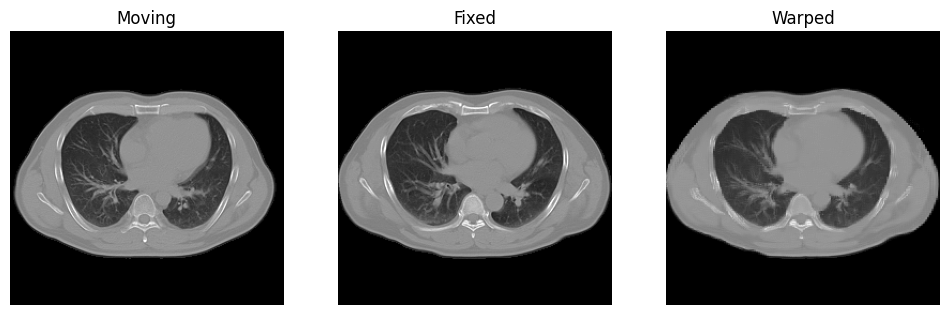

Epoch 101/30000, Loss: 0.0061
Epoch 102/30000, Loss: 0.0086
Epoch 103/30000, Loss: 0.0108
Epoch 104/30000, Loss: 0.0065
Epoch 105/30000, Loss: 0.0084
Epoch 106/30000, Loss: 0.0062
Epoch 107/30000, Loss: 0.0066
Epoch 108/30000, Loss: 0.0171
Epoch 109/30000, Loss: 0.0062
Epoch 110/30000, Loss: 0.0092
Epoch 111/30000, Loss: 0.0094
Epoch 112/30000, Loss: 0.0075
Epoch 113/30000, Loss: 0.0054
Epoch 114/30000, Loss: 0.0059
Epoch 115/30000, Loss: 0.0044
Epoch 116/30000, Loss: 0.0062
Epoch 117/30000, Loss: 0.0121
Epoch 118/30000, Loss: 0.0037
Epoch 119/30000, Loss: 0.0046
Epoch 120/30000, Loss: 0.0079
Epoch 121/30000, Loss: 0.0075
Epoch 122/30000, Loss: 0.0094
Epoch 123/30000, Loss: 0.0033
Epoch 124/30000, Loss: 0.0076
Epoch 125/30000, Loss: 0.0063
Epoch 126/30000, Loss: 0.0082
Epoch 127/30000, Loss: 0.0167
Epoch 128/30000, Loss: 0.0107
Epoch 129/30000, Loss: 0.0063
Epoch 130/30000, Loss: 0.0078
Epoch 131/30000, Loss: 0.0054
Epoch 132/30000, Loss: 0.0039
Epoch 133/30000, Loss: 0.0081
Epoch 134/

KeyboardInterrupt: 

In [ ]:
# ============================================================
# NotdecoderHight
# Pretraining + Inverse Consistency
# ============================================================

from tqdm.notebook import tqdm
from IPython.display import clear_output

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.optim as optim

from pathlib import Path
import time


# ============================================================
# 0. Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=1.0
):
    from scipy.ndimage import gaussian_filter

    tensor_np = (
        tensor
        .detach()
        .cpu()
        .numpy()
    )

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[
            0,
            0,
            sigma,
            sigma,
            sigma
        ]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )


# ============================================================
# 1. Inverse Consistency Loss
#
# SpatialTransformer:
#
# warped(x) = src(x + flow(x))
#
# forward flow:
#     u = Vec_fwd
#
# reverse flow:
#     v = Vec_rev
#
# composition:
#
#     u(x) + v(x + u(x)) ≈ 0
#
#     v(x) + u(x + v(x)) ≈ 0
#
# transformer(v, u)
#     = v(x + u(x))
#
# ============================================================

def inverse_consistency_loss(
    flow_forward,
    flow_reverse,
    transformer
):

    # --------------------------------------------------------
    # v(x + u(x))
    # --------------------------------------------------------

    reverse_warped_by_forward = transformer(
        flow_reverse,
        flow_forward
    )


    # --------------------------------------------------------
    # u(x + v(x))
    # --------------------------------------------------------

    forward_warped_by_reverse = transformer(
        flow_forward,
        flow_reverse
    )


    # --------------------------------------------------------
    # Forward -> Reverse composition
    # --------------------------------------------------------

    composition_forward = (
        flow_forward
        + reverse_warped_by_forward
    )


    # --------------------------------------------------------
    # Reverse -> Forward composition
    # --------------------------------------------------------

    composition_reverse = (
        flow_reverse
        + forward_warped_by_reverse
    )


    # --------------------------------------------------------
    # Identity displacement = 0
    # --------------------------------------------------------

    loss_forward = torch.mean(
        composition_forward ** 2
    )

    loss_reverse = torch.mean(
        composition_reverse ** 2
    )


    # --------------------------------------------------------
    # Symmetric inverse consistency
    # --------------------------------------------------------

    loss_inverse = (
        loss_forward
        + loss_reverse
    ) / 2.0


    return (
        loss_inverse,
        composition_forward,
        composition_reverse
    )


# ============================================================
# 2. 本番学習用モデル
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# 3. Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=1e-4
)


print(
    "本番学習用のmodel3D / optimizerを"
    "再初期化しました"
)


# ============================================================
# 4. CUDA / AMP
# ============================================================

use_amp = torch.cuda.is_available()


print(
    "========================================"
)

print(
    "CUDA / AMP settings"
)

print(
    "========================================"
)

print(
    "CUDA available :",
    torch.cuda.is_available()
)

print(
    "device         :",
    device
)


if torch.cuda.is_available():

    print(
        "GPU            :",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory     :",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB"
    )


print(
    "AMP enabled    :",
    use_amp
)

print(
    "========================================"
)


# ============================================================
# 5. AMP GradScaler
# ============================================================

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# 6. CUDA settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# 7. Training settings
# ============================================================

epochs = 80000

shift_range = 1


# ------------------------------------------------------------
# Loss weights
# ------------------------------------------------------------
#
# 元コード:
#
# loss_vec   * 0.01
# loss_image * 100
#
# に加えて
#
# inverse consistency
#
# を追加する
#
# 最初は 0.1 程度を推奨
# ------------------------------------------------------------

LAMBDA_VEC = 0.01

LAMBDA_IMAGE = 100.0

LAMBDA_INV = 0.1


print()
print(
    "========================================"
)

print(
    "Loss weights"
)

print(
    "========================================"
)

print(
    "Vector supervised :",
    LAMBDA_VEC
)

print(
    "Image similarity  :",
    LAMBDA_IMAGE
)

print(
    "Inverse consistency:",
    LAMBDA_INV
)

print(
    "========================================"
)


# ============================================================
# 8. Loss history
# ============================================================

losses = []

loss_vecs = []

loss_images = []

loss_images_forward = []

loss_images_reverse = []

loss_inverse_history = []


# ============================================================
# 9. Training from scratch
#
# Epoch 1から逆写像整合性ありで学習
# ============================================================

start_epoch = 0

shift_range = 1


print(
    "========================================"
)

print(
    "Training from scratch"
)

print(
    "========================================"
)

print(
    "Start epoch:",
    start_epoch
)

print(
    "Shift range:",
    f"±{shift_range}"
)

print(
    "Inverse consistency:"
    " ENABLED from Epoch 1"
)

print(
    "========================================"
)

print(
    "========================================"
)

print(
    "Resume training"
)

print(
    "========================================"
)

print(
    "Checkpoint :",
    checkpoint_path
)

print(
    "Start epoch:",
    start_epoch
)

print(
    "Shift range:",
    f"±{shift_range}"
)

print(
    "========================================"
)


# ============================================================
# 10. Timing settings
# ============================================================

PROFILE_FIRST_EPOCHS = 3

PROFILE_EVERY = 100

amp_dtype_checked = False


# ============================================================
# 11. Training
# ============================================================

model3D.train()


for epoch in tqdm(

    range(
        start_epoch,
        epochs
    ),

    initial=start_epoch,

    total=epochs
):


    # ========================================================
    # Profile
    # ========================================================

    do_profile = (

        epoch
        < start_epoch
        + PROFILE_FIRST_EPOCHS

        or

        (epoch + 1)
        % PROFILE_EVERY
        == 0
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    epoch_start = time.perf_counter()


    # ========================================================
    # 12. Curriculum
    # ========================================================

    if (
        epoch % 2000 == 0
        and epoch > 0
    ):

        shift_range += 1


        print(
            f"Epoch {epoch}: "
            f"Increasing shift range "
            f"to ±{shift_range} voxels."
        )


    # ========================================================
    # 13. Data
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # StopIteration対策
    # --------------------------------------------------------

    try:

        train_batch, _ = next(
            train_generator
        )

    except StopIteration:

        train_generator = (
            vxm_data_generator(
                x_train,
                batch_size=2
            )
        )

        train_batch, _ = next(
            train_generator
        )


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = (
            train_batch[0]
            .to(
                device=device,
                dtype=torch.float32,
                non_blocking=True
            )
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_data = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 14. Batch / coarse DVF
    # ========================================================

    B = moving_images.shape[0]

    D = 8

    H = 16

    W = 16


    # ========================================================
    # 15. Synthetic DVF
    # ========================================================

    t0 = time.perf_counter()


    displacement_field = (

        torch.rand(
            (
                B,
                3,
                D,
                H,
                W
            ),
            dtype=torch.float32,
            device=device
        )

        * 2
        - 1

    ) * shift_range


    # --------------------------------------------------------
    # Gaussian smooth
    # --------------------------------------------------------

    displacement_field = (
        gaussian_smooth_3d(
            displacement_field,
            sigma=2.0
        )
    )


    # --------------------------------------------------------
    # Full resolution
    #
    # (B,3,8,16,16)
    #
    # ->
    #
    # (B,3,128,256,256)
    # --------------------------------------------------------

    displacement_field = F.interpolate(
        displacement_field,
        size=(
            128,
            256,
            256
        ),
        mode="trilinear",
        align_corners=False
    )


    # --------------------------------------------------------
    # Wavelet resolution
    #
    # Full resolution voxel
    #
    # ->
    #
    # Wavelet voxel
    #
    # 1/2
    # --------------------------------------------------------

    displacement_field128 = F.interpolate(
        displacement_field,
        size=(
            64,
            128,
            128
        ),
        mode="trilinear",
        align_corners=False
    ) / 2.0


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_dvf = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 16. Synthetic deformation
    #
    # Moving
    #
    # ->
    #
    # Moving'
    # ========================================================

    t0 = time.perf_counter()


    moving_images2 = transformer256(
        moving_images,
        displacement_field
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_transformer256 = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 17. Wavelet Analysis
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(
        device
    )


    # --------------------------------------------------------
    # Moving'
    # --------------------------------------------------------

    moving_images2_analysis = (
        analysis_filter_3d(
            moving_images2,
            analysis
        )
    )


    moving_images2_w = down_sampling_3d(
        moving_images2_analysis
    ).to(
        device
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_wavelet_analysis = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 18. Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # 19. Forward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # A -> B
        #
        # Moving -> Moving'
        # ====================================================

        Vec_forward = model3D(
            moving_w,
            moving_images2_w
        )


        # ====================================================
        # B -> A
        #
        # Moving' -> Moving
        #
        # 同じネットワークを逆順入力で使用
        # ====================================================

        Vec_reverse = model3D(
            moving_images2_w,
            moving_w
        )


        # ====================================================
        # AMP dtype check
        # ====================================================

        if not amp_dtype_checked:

            print()

            print(
                "========================================"
            )

            print(
                "AMP dtype check"
            )

            print(
                "========================================"
            )

            print(
                "moving_w dtype   :",
                moving_w.dtype
            )

            print(
                "Vec_forward dtype:",
                Vec_forward.dtype
            )

            print(
                "Vec_reverse dtype:",
                Vec_reverse.dtype
            )

            print(
                "========================================"
            )

            print()


            amp_dtype_checked = True


        # ====================================================
        # 20. Forward deformation
        #
        # Moving -> Moving'
        # ====================================================

        moving_warped_forward = transformer(
            moving_w,
            Vec_forward
        )


        moving_warped_forward_up = (
            up_sampling_3d(
                moving_warped_forward
            )
        )


        (
            transformed_forward,
            _
        ) = synthesis_filter_3d(
            moving_warped_forward_up,
            synthesis_filters
        )


        # ====================================================
        # 21. Reverse deformation
        #
        # Moving' -> Moving
        # ====================================================

        moving_warped_reverse = transformer(
            moving_images2_w,
            Vec_reverse
        )


        moving_warped_reverse_up = (
            up_sampling_3d(
                moving_warped_reverse
            )
        )


        (
            transformed_reverse,
            _
        ) = synthesis_filter_3d(
            moving_warped_reverse_up,
            synthesis_filters
        )


        # ====================================================
        # 22. Supervised DVF loss
        #
        # Synthetic DVFはForwardだけ正解が分かっている
        #
        # Vec_reverse = -Vec_forward
        #
        # とはしない
        # ====================================================

        loss_vec_raw = MSE_Loss(
            displacement_field128,
            Vec_forward
        )


        loss_vec = (
            loss_vec_raw
            * LAMBDA_VEC
        )


        # ====================================================
        # 23. Forward image loss
        #
        # Moving -> Moving'
        # ====================================================

        loss_image_forward_raw = MSE_Loss(
            moving_images2,
            transformed_forward
        )


        # ====================================================
        # 24. Reverse image loss
        #
        # Moving' -> Moving
        # ====================================================

        loss_image_reverse_raw = MSE_Loss(
            moving_images,
            transformed_reverse
        )


        # ====================================================
        # 25. Symmetric image loss
        #
        # 平均を取ることで
        #
        # 元の ×100 スケールを維持
        # ====================================================

        loss_image_raw = (

            loss_image_forward_raw
            + loss_image_reverse_raw

        ) / 2.0


        loss_image = (
            loss_image_raw
            * LAMBDA_IMAGE
        )


        # ====================================================
        # 26. Inverse Consistency
        # ====================================================

        (
            loss_inverse_raw,
            composition_forward,
            composition_reverse

        ) = inverse_consistency_loss(

            Vec_forward,
            Vec_reverse,
            transformer
        )


        loss_inverse = (
            loss_inverse_raw
            * LAMBDA_INV
        )


        # ====================================================
        # 27. Total Loss
        # ====================================================

        loss = (

            loss_vec

            + loss_image

            + loss_inverse
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_forward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 28. AMP Backward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.scale(
        loss
    ).backward()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_backward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 29. Optimizer
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.step(
        optimizer
    )

    scaler.update()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_optimizer = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 30. Loss history
    # ========================================================

    loss_value = (
        loss
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_vec_value = (
        loss_vec
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_image_value = (
        loss_image
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_forward_value = (
        loss_image_forward_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_reverse_value = (
        loss_image_reverse_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_inverse_value = (
        loss_inverse
        .detach()
        .float()
        .cpu()
        .item()
    )


    losses.append(
        loss_value
    )

    loss_vecs.append(
        loss_vec_value
    )

    loss_images.append(
        loss_image_value
    )

    loss_images_forward.append(
        loss_forward_value
    )

    loss_images_reverse.append(
        loss_reverse_value
    )

    loss_inverse_history.append(
        loss_inverse_value
    )


    # ========================================================
    # 31. Curriculum observation
    # ========================================================

    if (

        (epoch + 1)
        % OBSERVE_EVERY
        == 0

        or

        (epoch + 1)
        == epochs

    ):

        model3D.eval()


        with torch.no_grad():

            observe_curriculum_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
                shifts=OBSERVE_SHIFTS,
            )


            observe_random_deformation_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
            )


        model3D.train()


    # ========================================================
    # 32. Latest model
    #
    # 100 epoch
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        torch.save(
            model3D.state_dict(),
            "model_DVF_pretrain_latest.pth"
        )


    # ========================================================
    # 33. Full checkpoint
    # ========================================================

    if (
        (epoch + 1)
        % OBSERVE_EVERY
        == 0
    ):

        checkpoint_dir = Path(
            "curriculum_checkpoints"
        )


        checkpoint_dir.mkdir(
            exist_ok=True
        )


        checkpoint_save_path = (

            checkpoint_dir

            / (
                f"pretrain_inverse_epoch_"
                f"{epoch + 1:05d}.pth"
            )
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "shift_range":
                    shift_range,

                "lambda_vec":
                    LAMBDA_VEC,

                "lambda_image":
                    LAMBDA_IMAGE,

                "lambda_inverse":
                    LAMBDA_INV,

                "loss":
                    loss_value,

                "loss_vec":
                    loss_vec_value,

                "loss_image":
                    loss_image_value,

                "loss_inverse":
                    loss_inverse_value,
            },

            checkpoint_save_path
        )


        print(
            "Checkpoint saved:",
            checkpoint_save_path
        )


    # ========================================================
    # 34. Loss plot
    # ========================================================

    if (
        (epoch + 1)
        % 500
        == 0
    ):

        clear_output(
            wait=True
        )


        # ----------------------------------------------------
        # Weighted total losses
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                11,
                5
            )
        )


        plt.plot(
            losses,
            label="Total Loss"
        )

        plt.plot(
            loss_vecs,
            label="Vector Loss"
        )

        plt.plot(
            loss_images,
            label="Image Loss"
        )

        plt.plot(
            loss_inverse_history,
            label="Inverse Loss"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Weighted Loss"
        )

        plt.title(
            "Training Loss Progress"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


        # ----------------------------------------------------
        # Forward / Reverse image MSE
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                10,
                4
            )
        )


        plt.plot(
            loss_images_forward,
            label="Forward Image MSE"
        )

        plt.plot(
            loss_images_reverse,
            label="Reverse Image MSE"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Raw MSE"
        )

        plt.title(
            "Forward / Reverse Image MSE"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


    # ========================================================
    # 35. Log
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        # ----------------------------------------------------
        # Composition error
        # ----------------------------------------------------

        comp_fwd_mean = (
            composition_forward
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        comp_rev_mean = (
            composition_reverse
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        print(

            f"Epoch {epoch + 1}/{epochs}, "

            f"Loss: {loss_value:.6f}, "

            f"Vec: {loss_vec_value:.6f}, "

            f"Image: {loss_image_value:.6f}, "

            f"Inv: {loss_inverse_value:.6f}, "

            f"Fwd MSE: {loss_forward_value:.6f}, "

            f"Rev MSE: {loss_reverse_value:.6f}, "

            f"Comp F: {comp_fwd_mean:.6f}, "

            f"Comp R: {comp_rev_mean:.6f}, "

            f"Shift: ±{shift_range}"
        )


    # ========================================================
    # 36. Timing
    # ========================================================

    if do_profile:

        if torch.cuda.is_available():

            torch.cuda.synchronize()


        epoch_total = (
            time.perf_counter()
            - epoch_start
        )


        print(

            "\n"

            f"[Timing Epoch {epoch + 1}]\n"

            f"Data              : "
            f"{t_data:.4f} sec\n"

            f"DVF generation    : "
            f"{t_dvf:.4f} sec\n"

            f"Transformer256    : "
            f"{t_transformer256:.4f} sec\n"

            f"Wavelet analysis  : "
            f"{t_wavelet_analysis:.4f} sec\n"

            f"AMP forward       : "
            f"{t_forward:.4f} sec\n"

            f"AMP backward      : "
            f"{t_backward:.4f} sec\n"

            f"Optimizer         : "
            f"{t_optimizer:.4f} sec\n"

            f"Total             : "
            f"{epoch_total:.4f} sec\n"
        )


# ============================================================
# 37. Final save
# ============================================================

FINAL_MODEL_PATH = Path(
    "model_DVF_pretrain_inverse_final001.pth"
)


torch.save(
    model3D.state_dict(),
    FINAL_MODEL_PATH
)


print()

print(
    "========================================"
)

print(
    "Pretraining completed"
)

print(
    "========================================"
)

print(
    "Final model:",
    FINAL_MODEL_PATH.resolve()
)

In [ ]:
# ============================================================
# NotdecoderHight
# Pretraining + Inverse Consistency
# ============================================================

from tqdm.notebook import tqdm
from IPython.display import clear_output

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.optim as optim

from pathlib import Path
import time


# ============================================================
# 0. Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=1.0
):
    from scipy.ndimage import gaussian_filter

    tensor_np = (
        tensor
        .detach()
        .cpu()
        .numpy()
    )

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[
            0,
            0,
            sigma,
            sigma,
            sigma
        ]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )


# ============================================================
# 1. Inverse Consistency Loss
#
# SpatialTransformer:
#
# warped(x) = src(x + flow(x))
#
# forward flow:
#     u = Vec_fwd
#
# reverse flow:
#     v = Vec_rev
#
# composition:
#
#     u(x) + v(x + u(x)) ≈ 0
#
#     v(x) + u(x + v(x)) ≈ 0
#
# transformer(v, u)
#     = v(x + u(x))
#
# ============================================================

def inverse_consistency_loss(
    flow_forward,
    flow_reverse,
    transformer
):

    # --------------------------------------------------------
    # v(x + u(x))
    # --------------------------------------------------------

    reverse_warped_by_forward = transformer(
        flow_reverse,
        flow_forward
    )


    # --------------------------------------------------------
    # u(x + v(x))
    # --------------------------------------------------------

    forward_warped_by_reverse = transformer(
        flow_forward,
        flow_reverse
    )


    # --------------------------------------------------------
    # Forward -> Reverse composition
    # --------------------------------------------------------

    composition_forward = (
        flow_forward
        + reverse_warped_by_forward
    )


    # --------------------------------------------------------
    # Reverse -> Forward composition
    # --------------------------------------------------------

    composition_reverse = (
        flow_reverse
        + forward_warped_by_reverse
    )


    # --------------------------------------------------------
    # Identity displacement = 0
    # --------------------------------------------------------

    loss_forward = torch.mean(
        composition_forward ** 2
    )

    loss_reverse = torch.mean(
        composition_reverse ** 2
    )


    # --------------------------------------------------------
    # Symmetric inverse consistency
    # --------------------------------------------------------

    loss_inverse = (
        loss_forward
        + loss_reverse
    ) / 2.0


    return (
        loss_inverse,
        composition_forward,
        composition_reverse
    )


# ============================================================
# 2. 本番学習用モデル
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# 3. Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=1e-4
)


print(
    "本番学習用のmodel3D / optimizerを"
    "再初期化しました"
)


# ============================================================
# 4. CUDA / AMP
# ============================================================

use_amp = torch.cuda.is_available()


print(
    "========================================"
)

print(
    "CUDA / AMP settings"
)

print(
    "========================================"
)

print(
    "CUDA available :",
    torch.cuda.is_available()
)

print(
    "device         :",
    device
)


if torch.cuda.is_available():

    print(
        "GPU            :",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory     :",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB"
    )


print(
    "AMP enabled    :",
    use_amp
)

print(
    "========================================"
)


# ============================================================
# 5. AMP GradScaler
# ============================================================

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# 6. CUDA settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# 7. Training settings
# ============================================================

epochs = 80000

shift_range = 1


# ------------------------------------------------------------
# Loss weights
# ------------------------------------------------------------
#
# 元コード:
#
# loss_vec   * 0.01
# loss_image * 100
#
# に加えて
#
# inverse consistency
#
# を追加する
#
# 最初は 0.1 程度を推奨
# ------------------------------------------------------------

LAMBDA_VEC = 0.01

LAMBDA_IMAGE = 100.0

LAMBDA_INV = 0.01


print()
print(
    "========================================"
)

print(
    "Loss weights"
)

print(
    "========================================"
)

print(
    "Vector supervised :",
    LAMBDA_VEC
)

print(
    "Image similarity  :",
    LAMBDA_IMAGE
)

print(
    "Inverse consistency:",
    LAMBDA_INV
)

print(
    "========================================"
)


# ============================================================
# 8. Loss history
# ============================================================

losses = []

loss_vecs = []

loss_images = []

loss_images_forward = []

loss_images_reverse = []

loss_inverse_history = []


# ============================================================
# 9. Training from scratch
#
# Epoch 1から逆写像整合性ありで学習
# ============================================================

start_epoch = 0

shift_range = 1


print(
    "========================================"
)

print(
    "Training from scratch"
)

print(
    "========================================"
)

print(
    "Start epoch:",
    start_epoch
)

print(
    "Shift range:",
    f"±{shift_range}"
)

print(
    "Inverse consistency:"
    " ENABLED from Epoch 1"
)

print(
    "========================================"
)


# ============================================================
# 10. Timing settings
# ============================================================

PROFILE_FIRST_EPOCHS = 3

PROFILE_EVERY = 100

amp_dtype_checked = False


# ============================================================
# 11. Training
# ============================================================

model3D.train()


for epoch in tqdm(

    range(
        start_epoch,
        epochs
    ),

    initial=start_epoch,

    total=epochs
):


    # ========================================================
    # Profile
    # ========================================================

    do_profile = (

        epoch
        < start_epoch
        + PROFILE_FIRST_EPOCHS

        or

        (epoch + 1)
        % PROFILE_EVERY
        == 0
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    epoch_start = time.perf_counter()


    # ========================================================
    # 12. Curriculum
    # ========================================================

    if (
        epoch % 2000 == 0
        and epoch > 0
    ):

        shift_range += 1


        print(
            f"Epoch {epoch}: "
            f"Increasing shift range "
            f"to ±{shift_range} voxels."
        )


    # ========================================================
    # 13. Data
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # StopIteration対策
    # --------------------------------------------------------

    try:

        train_batch, _ = next(
            train_generator
        )

    except StopIteration:

        train_generator = (
            vxm_data_generator(
                x_train,
                batch_size=2
            )
        )

        train_batch, _ = next(
            train_generator
        )


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = (
            train_batch[0]
            .to(
                device=device,
                dtype=torch.float32,
                non_blocking=True
            )
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_data = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 14. Batch / coarse DVF
    # ========================================================

    B = moving_images.shape[0]

    D = 8

    H = 16

    W = 16


    # ========================================================
    # 15. Synthetic DVF
    # ========================================================

    t0 = time.perf_counter()


    displacement_field = (

        torch.rand(
            (
                B,
                3,
                D,
                H,
                W
            ),
            dtype=torch.float32,
            device=device
        )

        * 2
        - 1

    ) * shift_range


    # --------------------------------------------------------
    # Gaussian smooth
    # --------------------------------------------------------

    displacement_field = (
        gaussian_smooth_3d(
            displacement_field,
            sigma=2.0
        )
    )


    # --------------------------------------------------------
    # Full resolution
    #
    # (B,3,8,16,16)
    #
    # ->
    #
    # (B,3,128,256,256)
    # --------------------------------------------------------

    displacement_field = F.interpolate(
        displacement_field,
        size=(
            128,
            256,
            256
        ),
        mode="trilinear",
        align_corners=False
    )


    # --------------------------------------------------------
    # Wavelet resolution
    #
    # Full resolution voxel
    #
    # ->
    #
    # Wavelet voxel
    #
    # 1/2
    # --------------------------------------------------------

    displacement_field128 = F.interpolate(
        displacement_field,
        size=(
            64,
            128,
            128
        ),
        mode="trilinear",
        align_corners=False
    ) / 2.0


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_dvf = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 16. Synthetic deformation
    #
    # Moving
    #
    # ->
    #
    # Moving'
    # ========================================================

    t0 = time.perf_counter()


    moving_images2 = transformer256(
        moving_images,
        displacement_field
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_transformer256 = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 17. Wavelet Analysis
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(
        device
    )


    # --------------------------------------------------------
    # Moving'
    # --------------------------------------------------------

    moving_images2_analysis = (
        analysis_filter_3d(
            moving_images2,
            analysis
        )
    )


    moving_images2_w = down_sampling_3d(
        moving_images2_analysis
    ).to(
        device
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_wavelet_analysis = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 18. Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # 19. Forward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # A -> B
        #
        # Moving -> Moving'
        # ====================================================

        Vec_forward = model3D(
            moving_w,
            moving_images2_w
        )


        # ====================================================
        # B -> A
        #
        # Moving' -> Moving
        #
        # 同じネットワークを逆順入力で使用
        # ====================================================

        Vec_reverse = model3D(
            moving_images2_w,
            moving_w
        )


        # ====================================================
        # AMP dtype check
        # ====================================================

        if not amp_dtype_checked:

            print()

            print(
                "========================================"
            )

            print(
                "AMP dtype check"
            )

            print(
                "========================================"
            )

            print(
                "moving_w dtype   :",
                moving_w.dtype
            )

            print(
                "Vec_forward dtype:",
                Vec_forward.dtype
            )

            print(
                "Vec_reverse dtype:",
                Vec_reverse.dtype
            )

            print(
                "========================================"
            )

            print()


            amp_dtype_checked = True


        # ====================================================
        # 20. Forward deformation
        #
        # Moving -> Moving'
        # ====================================================

        moving_warped_forward = transformer(
            moving_w,
            Vec_forward
        )


        moving_warped_forward_up = (
            up_sampling_3d(
                moving_warped_forward
            )
        )


        (
            transformed_forward,
            _
        ) = synthesis_filter_3d(
            moving_warped_forward_up,
            synthesis_filters
        )


        # ====================================================
        # 21. Reverse deformation
        #
        # Moving' -> Moving
        # ====================================================

        moving_warped_reverse = transformer(
            moving_images2_w,
            Vec_reverse
        )


        moving_warped_reverse_up = (
            up_sampling_3d(
                moving_warped_reverse
            )
        )


        (
            transformed_reverse,
            _
        ) = synthesis_filter_3d(
            moving_warped_reverse_up,
            synthesis_filters
        )


        # ====================================================
        # 22. Supervised DVF loss
        #
        # Synthetic DVFはForwardだけ正解が分かっている
        #
        # Vec_reverse = -Vec_forward
        #
        # とはしない
        # ====================================================

        loss_vec_raw = MSE_Loss(
            displacement_field128,
            Vec_forward
        )


        loss_vec = (
            loss_vec_raw
            * LAMBDA_VEC
        )


        # ====================================================
        # 23. Forward image loss
        #
        # Moving -> Moving'
        # ====================================================

        loss_image_forward_raw = MSE_Loss(
            moving_images2,
            transformed_forward
        )


        # ====================================================
        # 24. Reverse image loss
        #
        # Moving' -> Moving
        # ====================================================

        loss_image_reverse_raw = MSE_Loss(
            moving_images,
            transformed_reverse
        )


        # ====================================================
        # 25. Symmetric image loss
        #
        # 平均を取ることで
        #
        # 元の ×100 スケールを維持
        # ====================================================

        loss_image_raw = (

            loss_image_forward_raw
            + loss_image_reverse_raw

        ) / 2.0


        loss_image = (
            loss_image_raw
            * LAMBDA_IMAGE
        )


        # ====================================================
        # 26. Inverse Consistency
        # ====================================================

        (
            loss_inverse_raw,
            composition_forward,
            composition_reverse

        ) = inverse_consistency_loss(

            Vec_forward,
            Vec_reverse,
            transformer
        )


        loss_inverse = (
            loss_inverse_raw
            * LAMBDA_INV
        )


        # ====================================================
        # 27. Total Loss
        # ====================================================

        loss = (

            loss_vec

            + loss_image

            + loss_inverse
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_forward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 28. AMP Backward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.scale(
        loss
    ).backward()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_backward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 29. Optimizer
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.step(
        optimizer
    )

    scaler.update()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_optimizer = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 30. Loss history
    # ========================================================

    loss_value = (
        loss
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_vec_value = (
        loss_vec
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_image_value = (
        loss_image
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_forward_value = (
        loss_image_forward_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_reverse_value = (
        loss_image_reverse_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_inverse_value = (
        loss_inverse
        .detach()
        .float()
        .cpu()
        .item()
    )


    losses.append(
        loss_value
    )

    loss_vecs.append(
        loss_vec_value
    )

    loss_images.append(
        loss_image_value
    )

    loss_images_forward.append(
        loss_forward_value
    )

    loss_images_reverse.append(
        loss_reverse_value
    )

    loss_inverse_history.append(
        loss_inverse_value
    )


    # ========================================================
    # 31. Curriculum observation
    # ========================================================

    if (

        (epoch + 1)
        % OBSERVE_EVERY
        == 0

        or

        (epoch + 1)
        == epochs

    ):

        model3D.eval()


        with torch.no_grad():

            observe_curriculum_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
                shifts=OBSERVE_SHIFTS,
            )


            observe_random_deformation_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
            )


        model3D.train()


    # ========================================================
    # 32. Latest model
    #
    # 100 epoch
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        torch.save(
            model3D.state_dict(),
            "model_DVF_pretrain_latest.pth"
        )


    # ========================================================
    # 33. Full checkpoint
    # ========================================================

    if (
        (epoch + 1)
        % OBSERVE_EVERY
        == 0
    ):

        checkpoint_dir = Path(
            "curriculum_checkpoints"
        )


        checkpoint_dir.mkdir(
            exist_ok=True
        )


        checkpoint_save_path = (

            checkpoint_dir

            / (
                f"pretrain_inverse_epoch_"
                f"{epoch + 1:05d}.pth"
            )
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "shift_range":
                    shift_range,

                "lambda_vec":
                    LAMBDA_VEC,

                "lambda_image":
                    LAMBDA_IMAGE,

                "lambda_inverse":
                    LAMBDA_INV,

                "loss":
                    loss_value,

                "loss_vec":
                    loss_vec_value,

                "loss_image":
                    loss_image_value,

                "loss_inverse":
                    loss_inverse_value,
            },

            checkpoint_save_path
        )


        print(
            "Checkpoint saved:",
            checkpoint_save_path
        )


    # ========================================================
    # 34. Loss plot
    # ========================================================

    if (
        (epoch + 1)
        % 500
        == 0
    ):

        clear_output(
            wait=True
        )


        # ----------------------------------------------------
        # Weighted total losses
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                11,
                5
            )
        )


        plt.plot(
            losses,
            label="Total Loss"
        )

        plt.plot(
            loss_vecs,
            label="Vector Loss"
        )

        plt.plot(
            loss_images,
            label="Image Loss"
        )

        plt.plot(
            loss_inverse_history,
            label="Inverse Loss"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Weighted Loss"
        )

        plt.title(
            "Training Loss Progress"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


        # ----------------------------------------------------
        # Forward / Reverse image MSE
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                10,
                4
            )
        )


        plt.plot(
            loss_images_forward,
            label="Forward Image MSE"
        )

        plt.plot(
            loss_images_reverse,
            label="Reverse Image MSE"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Raw MSE"
        )

        plt.title(
            "Forward / Reverse Image MSE"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


    # ========================================================
    # 35. Log
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        # ----------------------------------------------------
        # Composition error
        # ----------------------------------------------------

        comp_fwd_mean = (
            composition_forward
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        comp_rev_mean = (
            composition_reverse
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        print(

            f"Epoch {epoch + 1}/{epochs}, "

            f"Loss: {loss_value:.6f}, "

            f"Vec: {loss_vec_value:.6f}, "

            f"Image: {loss_image_value:.6f}, "

            f"Inv: {loss_inverse_value:.6f}, "

            f"Fwd MSE: {loss_forward_value:.6f}, "

            f"Rev MSE: {loss_reverse_value:.6f}, "

            f"Comp F: {comp_fwd_mean:.6f}, "

            f"Comp R: {comp_rev_mean:.6f}, "

            f"Shift: ±{shift_range}"
        )


    # ========================================================
    # 36. Timing
    # ========================================================

    if do_profile:

        if torch.cuda.is_available():

            torch.cuda.synchronize()


        epoch_total = (
            time.perf_counter()
            - epoch_start
        )


        print(

            "\n"

            f"[Timing Epoch {epoch + 1}]\n"

            f"Data              : "
            f"{t_data:.4f} sec\n"

            f"DVF generation    : "
            f"{t_dvf:.4f} sec\n"

            f"Transformer256    : "
            f"{t_transformer256:.4f} sec\n"

            f"Wavelet analysis  : "
            f"{t_wavelet_analysis:.4f} sec\n"

            f"AMP forward       : "
            f"{t_forward:.4f} sec\n"

            f"AMP backward      : "
            f"{t_backward:.4f} sec\n"

            f"Optimizer         : "
            f"{t_optimizer:.4f} sec\n"

            f"Total             : "
            f"{epoch_total:.4f} sec\n"
        )


# ============================================================
# 37. Final save
# ============================================================

FINAL_MODEL_PATH = Path(
    "model_DVF_pretrain_inverse_final0001.pth"
)


torch.save(
    model3D.state_dict(),
    FINAL_MODEL_PATH
)


print()

print(
    "========================================"
)

print(
    "Pretraining completed"
)

print(
    "========================================"
)

print(
    "Final model:",
    FINAL_MODEL_PATH.resolve()
)

In [ ]:
# ============================================================
# NotdecoderHight
# Pretraining + Inverse Consistency
# ============================================================

from tqdm.notebook import tqdm
from IPython.display import clear_output

import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
import torch.optim as optim

from pathlib import Path
import time


# ============================================================
# 0. Gaussian smoothing
# ============================================================

def gaussian_smooth_3d(
    tensor,
    sigma=1.0
):
    from scipy.ndimage import gaussian_filter

    tensor_np = (
        tensor
        .detach()
        .cpu()
        .numpy()
    )

    smoothed_np = gaussian_filter(
        tensor_np,
        sigma=[
            0,
            0,
            sigma,
            sigma,
            sigma
        ]
    )

    return torch.tensor(
        smoothed_np,
        dtype=tensor.dtype,
        device=tensor.device
    )


# ============================================================
# 1. Inverse Consistency Loss
#
# SpatialTransformer:
#
# warped(x) = src(x + flow(x))
#
# forward flow:
#     u = Vec_fwd
#
# reverse flow:
#     v = Vec_rev
#
# composition:
#
#     u(x) + v(x + u(x)) ≈ 0
#
#     v(x) + u(x + v(x)) ≈ 0
#
# transformer(v, u)
#     = v(x + u(x))
#
# ============================================================

def inverse_consistency_loss(
    flow_forward,
    flow_reverse,
    transformer
):

    # --------------------------------------------------------
    # v(x + u(x))
    # --------------------------------------------------------

    reverse_warped_by_forward = transformer(
        flow_reverse,
        flow_forward
    )


    # --------------------------------------------------------
    # u(x + v(x))
    # --------------------------------------------------------

    forward_warped_by_reverse = transformer(
        flow_forward,
        flow_reverse
    )


    # --------------------------------------------------------
    # Forward -> Reverse composition
    # --------------------------------------------------------

    composition_forward = (
        flow_forward
        + reverse_warped_by_forward
    )


    # --------------------------------------------------------
    # Reverse -> Forward composition
    # --------------------------------------------------------

    composition_reverse = (
        flow_reverse
        + forward_warped_by_reverse
    )


    # --------------------------------------------------------
    # Identity displacement = 0
    # --------------------------------------------------------

    loss_forward = torch.mean(
        composition_forward ** 2
    )

    loss_reverse = torch.mean(
        composition_reverse ** 2
    )


    # --------------------------------------------------------
    # Symmetric inverse consistency
    # --------------------------------------------------------

    loss_inverse = (
        loss_forward
        + loss_reverse
    ) / 2.0


    return (
        loss_inverse,
        composition_forward,
        composition_reverse
    )


# ============================================================
# 2. 本番学習用モデル
# ============================================================

model3D = vxm.networks.VxmDense_128_256_256(
    (128, 256, 256),
    nb_features,
    int_steps=0
).to(device)


# ============================================================
# 3. Optimizer
# ============================================================

optimizer = optim.Adam(
    model3D.parameters(),
    lr=1e-4
)


print(
    "本番学習用のmodel3D / optimizerを"
    "再初期化しました"
)


# ============================================================
# 4. CUDA / AMP
# ============================================================

use_amp = torch.cuda.is_available()


print(
    "========================================"
)

print(
    "CUDA / AMP settings"
)

print(
    "========================================"
)

print(
    "CUDA available :",
    torch.cuda.is_available()
)

print(
    "device         :",
    device
)


if torch.cuda.is_available():

    print(
        "GPU            :",
        torch.cuda.get_device_name(0)
    )

    print(
        "GPU memory     :",
        f"{torch.cuda.get_device_properties(0).total_memory / 1024**3:.1f} GB"
    )


print(
    "AMP enabled    :",
    use_amp
)

print(
    "========================================"
)


# ============================================================
# 5. AMP GradScaler
# ============================================================

scaler = torch.cuda.amp.GradScaler(
    enabled=use_amp
)


# ============================================================
# 6. CUDA settings
# ============================================================

if torch.cuda.is_available():

    torch.backends.cudnn.benchmark = True

    torch.backends.cuda.matmul.allow_tf32 = True

    torch.backends.cudnn.allow_tf32 = True


# ============================================================
# 7. Training settings
# ============================================================

epochs = 80000

shift_range = 1


# ------------------------------------------------------------
# Loss weights
# ------------------------------------------------------------
#
# 元コード:
#
# loss_vec   * 0.01
# loss_image * 100
#
# に加えて
#
# inverse consistency
#
# を追加する
#
# 最初は 0.1 程度を推奨
# ------------------------------------------------------------

LAMBDA_VEC = 0.01

LAMBDA_IMAGE = 100.0

LAMBDA_INV = 1.0


print()
print(
    "========================================"
)

print(
    "Loss weights"
)

print(
    "========================================"
)

print(
    "Vector supervised :",
    LAMBDA_VEC
)

print(
    "Image similarity  :",
    LAMBDA_IMAGE
)

print(
    "Inverse consistency:",
    LAMBDA_INV
)

print(
    "========================================"
)


# ============================================================
# 8. Loss history
# ============================================================

losses = []

loss_vecs = []

loss_images = []

loss_images_forward = []

loss_images_reverse = []

loss_inverse_history = []


# ============================================================
# 9. Training from scratch
#
# Epoch 1から逆写像整合性ありで学習
# ============================================================

start_epoch = 0

shift_range = 1


print(
    "========================================"
)

print(
    "Training from scratch"
)

print(
    "========================================"
)

print(
    "Start epoch:",
    start_epoch
)

print(
    "Shift range:",
    f"±{shift_range}"
)

print(
    "Inverse consistency:"
    " ENABLED from Epoch 1"
)

print(
    "========================================"
)

# ============================================================
# 10. Timing settings
# ============================================================

PROFILE_FIRST_EPOCHS = 3

PROFILE_EVERY = 100

amp_dtype_checked = False


# ============================================================
# 11. Training
# ============================================================

model3D.train()


for epoch in tqdm(

    range(
        start_epoch,
        epochs
    ),

    initial=start_epoch,

    total=epochs
):


    # ========================================================
    # Profile
    # ========================================================

    do_profile = (

        epoch
        < start_epoch
        + PROFILE_FIRST_EPOCHS

        or

        (epoch + 1)
        % PROFILE_EVERY
        == 0
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    epoch_start = time.perf_counter()


    # ========================================================
    # 12. Curriculum
    # ========================================================

    if (
        epoch % 2000 == 0
        and epoch > 0
    ):

        shift_range += 1


        print(
            f"Epoch {epoch}: "
            f"Increasing shift range "
            f"to ±{shift_range} voxels."
        )


    # ========================================================
    # 13. Data
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # StopIteration対策
    # --------------------------------------------------------

    try:

        train_batch, _ = next(
            train_generator
        )

    except StopIteration:

        train_generator = (
            vxm_data_generator(
                x_train,
                batch_size=2
            )
        )

        train_batch, _ = next(
            train_generator
        )


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    if torch.is_tensor(
        train_batch[0]
    ):

        moving_images = (
            train_batch[0]
            .to(
                device=device,
                dtype=torch.float32,
                non_blocking=True
            )
        )

    else:

        moving_images = torch.as_tensor(
            train_batch[0],
            dtype=torch.float32,
            device=device
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_data = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 14. Batch / coarse DVF
    # ========================================================

    B = moving_images.shape[0]

    D = 8

    H = 16

    W = 16


    # ========================================================
    # 15. Synthetic DVF
    # ========================================================

    t0 = time.perf_counter()


    displacement_field = (

        torch.rand(
            (
                B,
                3,
                D,
                H,
                W
            ),
            dtype=torch.float32,
            device=device
        )

        * 2
        - 1

    ) * shift_range


    # --------------------------------------------------------
    # Gaussian smooth
    # --------------------------------------------------------

    displacement_field = (
        gaussian_smooth_3d(
            displacement_field,
            sigma=2.0
        )
    )


    # --------------------------------------------------------
    # Full resolution
    #
    # (B,3,8,16,16)
    #
    # ->
    #
    # (B,3,128,256,256)
    # --------------------------------------------------------

    displacement_field = F.interpolate(
        displacement_field,
        size=(
            128,
            256,
            256
        ),
        mode="trilinear",
        align_corners=False
    )


    # --------------------------------------------------------
    # Wavelet resolution
    #
    # Full resolution voxel
    #
    # ->
    #
    # Wavelet voxel
    #
    # 1/2
    # --------------------------------------------------------

    displacement_field128 = F.interpolate(
        displacement_field,
        size=(
            64,
            128,
            128
        ),
        mode="trilinear",
        align_corners=False
    ) / 2.0


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_dvf = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 16. Synthetic deformation
    #
    # Moving
    #
    # ->
    #
    # Moving'
    # ========================================================

    t0 = time.perf_counter()


    moving_images2 = transformer256(
        moving_images,
        displacement_field
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_transformer256 = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 17. Wavelet Analysis
    # ========================================================

    t0 = time.perf_counter()


    # --------------------------------------------------------
    # Moving
    # --------------------------------------------------------

    moving_analysis = analysis_filter_3d(
        moving_images,
        analysis
    )


    moving_w = down_sampling_3d(
        moving_analysis
    ).to(
        device
    )


    # --------------------------------------------------------
    # Moving'
    # --------------------------------------------------------

    moving_images2_analysis = (
        analysis_filter_3d(
            moving_images2,
            analysis
        )
    )


    moving_images2_w = down_sampling_3d(
        moving_images2_analysis
    ).to(
        device
    )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_wavelet_analysis = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 18. Gradient reset
    # ========================================================

    optimizer.zero_grad(
        set_to_none=True
    )


    # ========================================================
    # 19. Forward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    with torch.cuda.amp.autocast(
        enabled=use_amp
    ):


        # ====================================================
        # A -> B
        #
        # Moving -> Moving'
        # ====================================================

        Vec_forward = model3D(
            moving_w,
            moving_images2_w
        )


        # ====================================================
        # B -> A
        #
        # Moving' -> Moving
        #
        # 同じネットワークを逆順入力で使用
        # ====================================================

        Vec_reverse = model3D(
            moving_images2_w,
            moving_w
        )


        # ====================================================
        # AMP dtype check
        # ====================================================

        if not amp_dtype_checked:

            print()

            print(
                "========================================"
            )

            print(
                "AMP dtype check"
            )

            print(
                "========================================"
            )

            print(
                "moving_w dtype   :",
                moving_w.dtype
            )

            print(
                "Vec_forward dtype:",
                Vec_forward.dtype
            )

            print(
                "Vec_reverse dtype:",
                Vec_reverse.dtype
            )

            print(
                "========================================"
            )

            print()


            amp_dtype_checked = True


        # ====================================================
        # 20. Forward deformation
        #
        # Moving -> Moving'
        # ====================================================

        moving_warped_forward = transformer(
            moving_w,
            Vec_forward
        )


        moving_warped_forward_up = (
            up_sampling_3d(
                moving_warped_forward
            )
        )


        (
            transformed_forward,
            _
        ) = synthesis_filter_3d(
            moving_warped_forward_up,
            synthesis_filters
        )


        # ====================================================
        # 21. Reverse deformation
        #
        # Moving' -> Moving
        # ====================================================

        moving_warped_reverse = transformer(
            moving_images2_w,
            Vec_reverse
        )


        moving_warped_reverse_up = (
            up_sampling_3d(
                moving_warped_reverse
            )
        )


        (
            transformed_reverse,
            _
        ) = synthesis_filter_3d(
            moving_warped_reverse_up,
            synthesis_filters
        )


        # ====================================================
        # 22. Supervised DVF loss
        #
        # Synthetic DVFはForwardだけ正解が分かっている
        #
        # Vec_reverse = -Vec_forward
        #
        # とはしない
        # ====================================================

        loss_vec_raw = MSE_Loss(
            displacement_field128,
            Vec_forward
        )


        loss_vec = (
            loss_vec_raw
            * LAMBDA_VEC
        )


        # ====================================================
        # 23. Forward image loss
        #
        # Moving -> Moving'
        # ====================================================

        loss_image_forward_raw = MSE_Loss(
            moving_images2,
            transformed_forward
        )


        # ====================================================
        # 24. Reverse image loss
        #
        # Moving' -> Moving
        # ====================================================

        loss_image_reverse_raw = MSE_Loss(
            moving_images,
            transformed_reverse
        )


        # ====================================================
        # 25. Symmetric image loss
        #
        # 平均を取ることで
        #
        # 元の ×100 スケールを維持
        # ====================================================

        loss_image_raw = (

            loss_image_forward_raw
            + loss_image_reverse_raw

        ) / 2.0


        loss_image = (
            loss_image_raw
            * LAMBDA_IMAGE
        )


        # ====================================================
        # 26. Inverse Consistency
        # ====================================================

        (
            loss_inverse_raw,
            composition_forward,
            composition_reverse

        ) = inverse_consistency_loss(

            Vec_forward,
            Vec_reverse,
            transformer
        )


        loss_inverse = (
            loss_inverse_raw
            * LAMBDA_INV
        )


        # ====================================================
        # 27. Total Loss
        # ====================================================

        loss = (

            loss_vec

            + loss_image

            + loss_inverse
        )


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_forward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 28. AMP Backward
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.scale(
        loss
    ).backward()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_backward = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 29. Optimizer
    # ========================================================

    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t0 = time.perf_counter()


    scaler.step(
        optimizer
    )

    scaler.update()


    if (
        do_profile
        and torch.cuda.is_available()
    ):

        torch.cuda.synchronize()


    t_optimizer = (
        time.perf_counter()
        - t0
    )


    # ========================================================
    # 30. Loss history
    # ========================================================

    loss_value = (
        loss
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_vec_value = (
        loss_vec
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_image_value = (
        loss_image
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_forward_value = (
        loss_image_forward_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_reverse_value = (
        loss_image_reverse_raw
        .detach()
        .float()
        .cpu()
        .item()
    )


    loss_inverse_value = (
        loss_inverse
        .detach()
        .float()
        .cpu()
        .item()
    )


    losses.append(
        loss_value
    )

    loss_vecs.append(
        loss_vec_value
    )

    loss_images.append(
        loss_image_value
    )

    loss_images_forward.append(
        loss_forward_value
    )

    loss_images_reverse.append(
        loss_reverse_value
    )

    loss_inverse_history.append(
        loss_inverse_value
    )


    # ========================================================
    # 31. Curriculum observation
    # ========================================================

    if (

        (epoch + 1)
        % OBSERVE_EVERY
        == 0

        or

        (epoch + 1)
        == epochs

    ):

        model3D.eval()


        with torch.no_grad():

            observe_curriculum_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
                shifts=OBSERVE_SHIFTS,
            )


            observe_random_deformation_progress(
                model=model3D,
                epoch=epoch + 1,
                moving_image=observation_moving,
            )


        model3D.train()


    # ========================================================
    # 32. Latest model
    #
    # 100 epoch
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        torch.save(
            model3D.state_dict(),
            "model_DVF_pretrain_latest.pth"
        )


    # ========================================================
    # 33. Full checkpoint
    # ========================================================

    if (
        (epoch + 1)
        % OBSERVE_EVERY
        == 0
    ):

        checkpoint_dir = Path(
            "curriculum_checkpoints"
        )


        checkpoint_dir.mkdir(
            exist_ok=True
        )


        checkpoint_save_path = (

            checkpoint_dir

            / (
                f"pretrain_inverse_epoch_"
                f"{epoch + 1:05d}.pth"
            )
        )


        torch.save(
            {
                "epoch":
                    epoch + 1,

                "model_state_dict":
                    model3D.state_dict(),

                "optimizer_state_dict":
                    optimizer.state_dict(),

                "scaler_state_dict":
                    scaler.state_dict(),

                "shift_range":
                    shift_range,

                "lambda_vec":
                    LAMBDA_VEC,

                "lambda_image":
                    LAMBDA_IMAGE,

                "lambda_inverse":
                    LAMBDA_INV,

                "loss":
                    loss_value,

                "loss_vec":
                    loss_vec_value,

                "loss_image":
                    loss_image_value,

                "loss_inverse":
                    loss_inverse_value,
            },

            checkpoint_save_path
        )


        print(
            "Checkpoint saved:",
            checkpoint_save_path
        )


    # ========================================================
    # 34. Loss plot
    # ========================================================

    if (
        (epoch + 1)
        % 500
        == 0
    ):

        clear_output(
            wait=True
        )


        # ----------------------------------------------------
        # Weighted total losses
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                11,
                5
            )
        )


        plt.plot(
            losses,
            label="Total Loss"
        )

        plt.plot(
            loss_vecs,
            label="Vector Loss"
        )

        plt.plot(
            loss_images,
            label="Image Loss"
        )

        plt.plot(
            loss_inverse_history,
            label="Inverse Loss"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Weighted Loss"
        )

        plt.title(
            "Training Loss Progress"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


        # ----------------------------------------------------
        # Forward / Reverse image MSE
        # ----------------------------------------------------

        plt.figure(
            figsize=(
                10,
                4
            )
        )


        plt.plot(
            loss_images_forward,
            label="Forward Image MSE"
        )

        plt.plot(
            loss_images_reverse,
            label="Reverse Image MSE"
        )


        plt.xlabel(
            "Epoch"
        )

        plt.ylabel(
            "Raw MSE"
        )

        plt.title(
            "Forward / Reverse Image MSE"
        )

        plt.legend()

        plt.grid(
            True
        )

        plt.tight_layout()

        plt.show()


    # ========================================================
    # 35. Log
    # ========================================================

    if (
        (epoch + 1)
        % 100
        == 0
    ):

        # ----------------------------------------------------
        # Composition error
        # ----------------------------------------------------

        comp_fwd_mean = (
            composition_forward
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        comp_rev_mean = (
            composition_reverse
            .detach()
            .float()
            .abs()
            .mean()
            .cpu()
            .item()
        )


        print(

            f"Epoch {epoch + 1}/{epochs}, "

            f"Loss: {loss_value:.6f}, "

            f"Vec: {loss_vec_value:.6f}, "

            f"Image: {loss_image_value:.6f}, "

            f"Inv: {loss_inverse_value:.6f}, "

            f"Fwd MSE: {loss_forward_value:.6f}, "

            f"Rev MSE: {loss_reverse_value:.6f}, "

            f"Comp F: {comp_fwd_mean:.6f}, "

            f"Comp R: {comp_rev_mean:.6f}, "

            f"Shift: ±{shift_range}"
        )


    # ========================================================
    # 36. Timing
    # ========================================================

    if do_profile:

        if torch.cuda.is_available():

            torch.cuda.synchronize()


        epoch_total = (
            time.perf_counter()
            - epoch_start
        )


        print(

            "\n"

            f"[Timing Epoch {epoch + 1}]\n"

            f"Data              : "
            f"{t_data:.4f} sec\n"

            f"DVF generation    : "
            f"{t_dvf:.4f} sec\n"

            f"Transformer256    : "
            f"{t_transformer256:.4f} sec\n"

            f"Wavelet analysis  : "
            f"{t_wavelet_analysis:.4f} sec\n"

            f"AMP forward       : "
            f"{t_forward:.4f} sec\n"

            f"AMP backward      : "
            f"{t_backward:.4f} sec\n"

            f"Optimizer         : "
            f"{t_optimizer:.4f} sec\n"

            f"Total             : "
            f"{epoch_total:.4f} sec\n"
        )


# ============================================================
# 37. Final save
# ============================================================

FINAL_MODEL_PATH = Path(
    "model_DVF_pretrain_inverse_final010.pth"
)


torch.save(
    model3D.state_dict(),
    FINAL_MODEL_PATH
)


print()

print(
    "========================================"
)

print(
    "Pretraining completed"
)

print(
    "========================================"
)

print(
    "Final model:",
    FINAL_MODEL_PATH.resolve()
)

In [ ]:
# Check_Perfect_Reconstruction.py
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import math
import matplotlib.pyplot as plt

pr_names = ['LLL', 'LLH', 'LHL', 'LHH', 'HLL', 'HLH', 'HHL', 'HHH']

class CheckPRHaar3DAnalysis(nn.Module):
    def __init__(self):
        super().__init__()
        hL = torch.tensor([1.0, 1.0], dtype=torch.float32) / math.sqrt(2)
        hH = torch.tensor([1.0, -1.0], dtype=torch.float32) / math.sqrt(2)

        filters = []
        filter_names = []
        for z_name, z_filter in zip(['L', 'H'], [hL, hH]):
            for y_name, y_filter in zip(['L', 'H'], [hL, hH]):
                for x_name, x_filter in zip(['L', 'H'], [hL, hH]):
                    kernel = (
                        z_filter[:, None, None]
                        * y_filter[None, :, None]
                        * x_filter[None, None, :]
                    )
                    filters.append(kernel)
                    filter_names.append(z_name + y_name + x_name)

        weight = torch.stack(filters, dim=0).unsqueeze(1)
        self.register_buffer('weight', weight)
        self.names = filter_names

    def forward(self, x):
        x_pad = F.pad(x, (0, 1, 0, 1, 0, 1))
        w = F.conv3d(x_pad, self.weight, stride=1, padding=0)
        return w

def check_pr_downsample_3d(w):
    return w[:, :, ::2, ::2, ::2]

def check_pr_upsample_3d(w_down):
    B, C, D, H, W = w_down.shape
    w_up = torch.zeros(B, C, D * 2, H * 2, W * 2, dtype=w_down.dtype, device=w_down.device)
    w_up[:, :, ::2, ::2, ::2] = w_down
    return w_up

def check_pr_make_3d_filter(fz, fy, fx):
    return fz[:, None, None] * fy[None, :, None] * fx[None, None, :]

class CheckPRHaar3DSynthesis(nn.Module):
    def __init__(self):
        super().__init__()
        sqrt2 = math.sqrt(2.0)
        low = torch.tensor([1.0, 1.0], dtype=torch.float32) / sqrt2
        high = torch.tensor([1.0, -1.0], dtype=torch.float32) / sqrt2

        filters = torch.stack([
            check_pr_make_3d_filter(low, low, low),
            check_pr_make_3d_filter(low, low, high),
            check_pr_make_3d_filter(low, high, low),
            check_pr_make_3d_filter(low, high, high),
            check_pr_make_3d_filter(high, low, low),
            check_pr_make_3d_filter(high, low, high),
            check_pr_make_3d_filter(high, high, low),
            check_pr_make_3d_filter(high, high, high),
        ], dim=0)

        filters = torch.flip(filters, dims=[1, 2, 3]).unsqueeze(1)
        self.register_buffer('filters', filters)

    def forward(self, w_up):
        B, C, D, H, W = w_up.shape
        filtered_bands = []
        for i, name in enumerate(pr_names):
            band = w_up[:, i:i + 1, :, :, :]
            kernel = self.filters[i:i + 1]
            filtered = F.conv3d(band, kernel, stride=1, padding=1)
            filtered = filtered[:, :, :D, :H, :W]
            filtered_bands.append(filtered)
            print(name, 'Synthesis後:', filtered.shape)

        filtered_bands = torch.cat(filtered_bands, dim=1)
        reconstructed = torch.sum(filtered_bands, dim=1, keepdim=True)
        return filtered_bands, reconstructed

def check_pr_frequency_response(h, omega):
    n = np.arange(len(h))
    response = np.sum(h[None, :] * np.exp(-1j * omega[:, None] * n[None, :]), axis=1)
    return response

In [ ]:
# Check_Perfect_Reconstruction.py: reconstruction check
check_pr_x = torch.as_tensor(
    x_train[0:1],
    dtype=torch.float32,
    device=device
).unsqueeze(1)

print('\n===================================')
print('入力')
print('===================================')
print('元画像:', check_pr_x.shape)

print('\n===================================')
print('1. Analysis Filter')
print('===================================')
check_pr_analysis = CheckPRHaar3DAnalysis().to(device)
check_pr_w = check_pr_analysis(check_pr_x)
print('Analysis後:', check_pr_w.shape)
print('周波数成分:', check_pr_analysis.names)

print('\n===================================')
print('2. Downsampling')
print('===================================')
check_pr_w_down = check_pr_downsample_3d(check_pr_w)
print('Downsampling後:', check_pr_w_down.shape)

print('\n===================================')
print('3. Upsampling')
print('===================================')
check_pr_w_up = check_pr_upsample_3d(check_pr_w_down)
print('Upsampling後:', check_pr_w_up.shape)

check_pr_up_error = torch.abs(check_pr_w_up[:, :, ::2, ::2, ::2] - check_pr_w_down)
print('Upsampling配置確認 平均誤差:', check_pr_up_error.mean().item())
print('Upsampling配置確認 最大誤差:', check_pr_up_error.max().item())

print('\n===================================')
print('4. Synthesis Filter')
print('===================================')
check_pr_synthesis = CheckPRHaar3DSynthesis().to(device)
check_pr_filtered_bands, check_pr_reconstructed = check_pr_synthesis(check_pr_w_up)
print('\nSynthesis後8成分:', check_pr_filtered_bands.shape)
print('再構成画像:', check_pr_reconstructed.shape)

print('\n===================================')
print('5. Reconstruction Error')
print('===================================')

if check_pr_x.shape != check_pr_reconstructed.shape:
    print('サイズが一致していません')
    print('Original:', check_pr_x.shape)
    print('Reconstructed:', check_pr_reconstructed.shape)
else:
    print('サイズ一致')
    check_pr_diff = check_pr_x - check_pr_reconstructed
    check_pr_absolute_error = torch.abs(check_pr_diff)
    check_pr_mae = torch.mean(check_pr_absolute_error)
    check_pr_max_error = torch.max(check_pr_absolute_error)
    check_pr_mse = torch.mean(check_pr_diff ** 2)
    check_pr_relative_error = torch.norm(check_pr_diff) / torch.norm(check_pr_x)
    print('\n===== 再構成誤差 =====')
    print('MAE:', check_pr_mae.item())
    print('最大絶対誤差:', check_pr_max_error.item())
    print('MSE:', check_pr_mse.item())
    print('相対誤差:', check_pr_relative_error.item())

    if check_pr_max_error.item() > 0:
         check_pr_error_order = int(np.floor(np.log10(check_pr_max_error.item())))
         check_pr_error_scale = 10.0 ** (-check_pr_error_order)
    else:
         check_pr_error_order = 0
         check_pr_error_scale = 1.0

    print('誤差表示スケール:', f'x 1e{-check_pr_error_order}' if check_pr_max_error.item() > 0 else 'no scaling')

print('\n===================================')
print('6. Save Results')
print('===================================')
np.save(r'D:\Saito\wavelet_reconstructed.npy', check_pr_reconstructed.detach().cpu().numpy())
print('再構成画像を保存しました')

if check_pr_x.shape == check_pr_reconstructed.shape:
    check_pr_slice_index = check_pr_x.shape[2] // 2

    plt.figure(figsize=(8, 8))
    plt.imshow(check_pr_x[0, 0, check_pr_slice_index].detach().cpu().numpy(), cmap='gray')
    plt.title('Original Image')
    plt.axis('off')
    plt.savefig(r'D:\Saito\wavelet_original.png', dpi=300, bbox_inches='tight')
    plt.close()

    plt.figure(figsize=(8, 8))
    plt.imshow(check_pr_reconstructed[0, 0, check_pr_slice_index].detach().cpu().numpy(), cmap='gray')
    plt.title('Reconstructed Image')
    plt.axis('off')
    plt.savefig(r'D:\Saito\wavelet_reconstructed.png', dpi=300, bbox_inches='tight')
    plt.close()

    plt.figure(figsize=(8, 8))
    plt.imshow(
         check_pr_absolute_error[0, 0, check_pr_slice_index].detach().cpu().numpy(),
         cmap='inferno',
         vmin=0.0,
         vmax=check_pr_max_error.item()
     )
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.title('Absolute Reconstruction Error')
    plt.axis('off')
    plt.savefig(r'D:\Saito\wavelet_error.png', dpi=300, bbox_inches='tight')
    plt.close()

    plt.figure(figsize=(8, 8))
    plt.imshow(
       (check_pr_absolute_error[0, 0, check_pr_slice_index] * check_pr_error_scale).detach().cpu().numpy(),
       cmap='inferno'
     )
    plt.colorbar(fraction=0.046, pad=0.04)
    plt.title(
         f'Scaled Error (x 1e{-check_pr_error_order})'
         if check_pr_max_error.item() > 0
         else 'Scaled Error'
     )
    plt.axis('off')
    plt.savefig(r'D:\Saito\wavelet_error_scaled.png', dpi=300, bbox_inches='tight')
    plt.close()


入力
元画像: torch.Size([1, 1, 128, 256, 256])

1. Analysis Filter
Analysis後: torch.Size([1, 8, 128, 256, 256])
周波数成分: ['LLL', 'LLH', 'LHL', 'LHH', 'HLL', 'HLH', 'HHL', 'HHH']

2. Downsampling
Downsampling後: torch.Size([1, 8, 64, 128, 128])

3. Upsampling
Upsampling後: torch.Size([1, 8, 128, 256, 256])
Upsampling配置確認 平均誤差: 0.0
Upsampling配置確認 最大誤差: 0.0

4. Synthesis Filter
LLL Synthesis後: torch.Size([1, 1, 128, 256, 256])
LLH Synthesis後: torch.Size([1, 1, 128, 256, 256])
LHL Synthesis後: torch.Size([1, 1, 128, 256, 256])
LHH Synthesis後: torch.Size([1, 1, 128, 256, 256])
HLL Synthesis後: torch.Size([1, 1, 128, 256, 256])
HLH Synthesis後: torch.Size([1, 1, 128, 256, 256])
HHL Synthesis後: torch.Size([1, 1, 128, 256, 256])
HHH Synthesis後: torch.Size([1, 1, 128, 256, 256])

Synthesis後8成分: torch.Size([1, 8, 128, 256, 256])
再構成画像: torch.Size([1, 1, 128, 256, 256])

5. Reconstruction Error
サイズ一致

===== 再構成誤差 =====
MAE: 3.967887707290174e-08
最大絶対誤差: 4.172325134277344e-07
MSE: 5.188463472473011e-15
相対誤差:

In [ ]:
if check_pr_x.shape == check_pr_reconstructed.shape:
    check_pr_slice_index = check_pr_x.shape[2] // 2

    # ========================================
    # 元画像
    # ========================================
    plt.figure(figsize=(8, 8))

    plt.imshow(
        check_pr_x[
            0,
            0,
            check_pr_slice_index
        ].detach().cpu().numpy(),
        cmap='gray'
    )

    plt.title('Original Image')
    plt.axis('off')

    plt.savefig(
        r'D:\Saito\wavelet_original.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()


    # ========================================
    # 再構成画像
    # ========================================
    plt.figure(figsize=(8, 8))

    plt.imshow(
        check_pr_reconstructed[
            0,
            0,
            check_pr_slice_index
        ].detach().cpu().numpy(),
        cmap='gray'
    )

    plt.title('Reconstructed Image')
    plt.axis('off')

    plt.savefig(
        r'D:\Saito\wavelet_reconstructed.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()


    # ========================================
    # 絶対誤差画像
    # ========================================
    plt.figure(figsize=(8, 8))

    plt.imshow(
        check_pr_absolute_error[
            0,
            0,
            check_pr_slice_index
        ].detach().cpu().numpy(),
        cmap='inferno',
        vmin=0.0,
        vmax=check_pr_max_error.item()
    )

    plt.colorbar(
        fraction=0.046,
        pad=0.04
    )

    plt.title('Absolute Reconstruction Error')
    plt.axis('off')

    plt.savefig(
        r'D:\Saito\wavelet_error.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()


    # ========================================
    # 拡大表示した誤差画像
    # ========================================
    plt.figure(figsize=(8, 8))

    check_pr_scaled_error = (
        check_pr_absolute_error[
            0,
            0,
            check_pr_slice_index
        ]
        * check_pr_error_scale
    ).detach().cpu().numpy()

    plt.imshow(
        check_pr_scaled_error,
        cmap='inferno'
    )

    plt.colorbar(
        fraction=0.046,
        pad=0.04
    )

    if check_pr_max_error.item() > 0:
        plt.title(
            f'Scaled Error (x 1e{-check_pr_error_order})'
        )
    else:
        plt.title('Scaled Error')

    plt.axis('off')

    plt.savefig(
        r'D:\Saito\wavelet_error_scaled.png',
        dpi=300,
        bbox_inches='tight'
    )

    plt.close()

    print('画像を保存しました')

画像を保存しました


Teacher image: (1, 1, 128, 256, 256)
Oracle image : (1, 1, 128, 256, 256)
MAE : 0.00817456
RMSE: 0.02472433


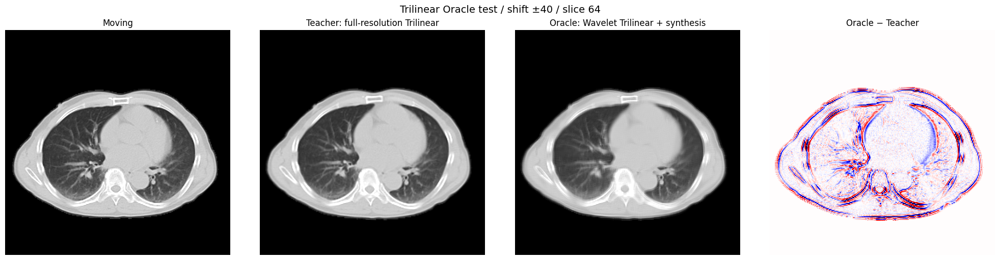

In [44]:
# ============================================================
# Oracle DVF test: Trilinear
# Full-resolution Trilinear teacher
# vs Wavelet-domain Trilinear + Haar synthesis
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


SAMPLE_INDEX = 0
ORACLE_SHIFT = 40

moving = torch.from_numpy(
    x_train[SAMPLE_INDEX:SAMPLE_INDEX + 1]
).float().unsqueeze(1).to(device)

# Trilinear学習時と同じ人工DVFを作成
with torch.no_grad():
    coarse_flow = (
        torch.rand(
            (1, 3, 8, 16, 16),
            device=device,
            dtype=torch.float32,
        ) * 2.0 - 1.0
    ) * ORACLE_SHIFT

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    # Full画像座標系の真のDVF
    true_flow_full = F.interpolate(
        coarse_flow,
        size=(128, 256, 256),
        mode="trilinear",
        align_corners=False,
    )

    # Wavelet空間座標系の真のDVF
    true_flow_low = F.interpolate(
        true_flow_full,
        size=(64, 128, 128),
        mode="trilinear",
        align_corners=False,
    ) / 2.0

    # ① Full-resolution Trilinear教師画像
    teacher_image = transformer256(
        moving,
        true_flow_full,
    )

    # ② Wavelet領域Trilinear → Haar再構成
    moving_analysis = analysis_filter_3d(
        moving,
        analysis,
    )

    moving_w = down_sampling_3d(
        moving_analysis,
    )

    oracle_warped_w = transformer(
        moving_w,
        true_flow_low,
    )

    oracle_warped_up = up_sampling_3d(
        oracle_warped_w,
    )

    oracle_image, _ = synthesis_filter_3d(
        oracle_warped_up,
        synthesis_filters,
    )

error = oracle_image - teacher_image

mae = error.abs().mean().item()
rmse = error.square().mean().sqrt().item()

print("Teacher image:", tuple(teacher_image.shape))
print("Oracle image :", tuple(oracle_image.shape))
print(f"MAE : {mae:.8f}")
print(f"RMSE: {rmse:.8f}")

moving_np = moving[0, 0].cpu().numpy()
teacher_np = teacher_image[0, 0].cpu().numpy()
oracle_np = oracle_image[0, 0].cpu().numpy()
error_np = error[0, 0].cpu().numpy()

slice_index = 64

vmin, vmax = np.percentile(
    np.concatenate([
        teacher_np[slice_index].ravel(),
        oracle_np[slice_index].ravel(),
    ]),
    [1, 99],
)

error_limit = np.percentile(
    np.abs(error_np[slice_index]),
    99.5,
)

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
    constrained_layout=True,
)

for axis, image, title in zip(
    axes[:3],
    [
        moving_np[slice_index],
        teacher_np[slice_index],
        oracle_np[slice_index],
    ],
    [
        "Moving",
        "Teacher: full-resolution Trilinear",
        "Oracle: Wavelet Trilinear + synthesis",
    ],
):
    axis.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axis.set_title(title)
    axis.axis("off")

axes[3].imshow(
    error_np[slice_index],
    cmap="seismic",
    vmin=-error_limit,
    vmax=error_limit,
)
axes[3].set_title("Oracle − Teacher")
axes[3].axis("off")

fig.suptitle(
    f"Trilinear Oracle test / shift ±{ORACLE_SHIFT} / slice {slice_index}",
    fontsize=14,
)
plt.show()

Moving                  : (1, 1, 128, 256, 256)
True full DVF           : (1, 3, 128, 256, 256)
True low DVF            : (1, 3, 64, 128, 128)
Upsampled low → full DVF: (1, 3, 128, 256, 256)

MAE : 0.00003059
RMSE: 0.00018277
MAX : 0.01183844


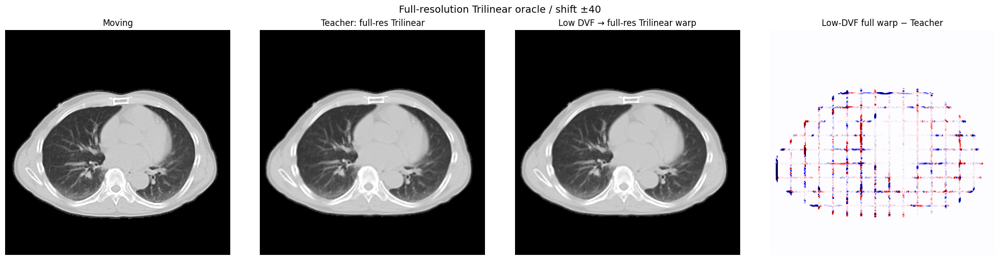

In [45]:
# ============================================================
# Oracle test:
# Low-resolution DVF → Full-resolution Trilinear warp
#
# Wavelet係数は変形しない。
# 真のLow-res DVFをFull-resへ戻し、Moving画像を直接変形する。
# ============================================================

import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt


SAMPLE_INDEX = 0
ORACLE_SHIFT = 40

FULL_SIZE_ORACLE = (128, 256, 256)
LOW_SIZE_ORACLE = (64, 128, 128)

moving = torch.from_numpy(
    x_train[SAMPLE_INDEX:SAMPLE_INDEX + 1]
).float().unsqueeze(1).to(device)

with torch.no_grad():
    # --------------------------------------------------------
    # 1. Trilinear学習と同じ人工DVF
    # --------------------------------------------------------
    coarse_flow = (
        torch.rand(
            (1, 3, 8, 16, 16),
            dtype=torch.float32,
            device=device,
        ) * 2.0 - 1.0
    ) * ORACLE_SHIFT

    coarse_flow = gaussian_smooth_3d(
        coarse_flow,
        sigma=2.0,
    )

    true_flow_full = F.interpolate(
        coarse_flow,
        size=FULL_SIZE_ORACLE,
        mode="trilinear",
        align_corners=False,
    )

    # モデルが教師として見るLow-res DVF
    true_flow_low = F.interpolate(
        true_flow_full,
        size=LOW_SIZE_ORACLE,
        mode="trilinear",
        align_corners=False,
    ) / 2.0

    # --------------------------------------------------------
    # 2. Full-resolution Trilinear教師画像
    # --------------------------------------------------------
    teacher_image = transformer256(
        moving,
        true_flow_full,
    )

    # --------------------------------------------------------
    # 3. Low DVFをFull DVFへ復元
    #
    # 空間サイズが各軸2倍なので、DVF値も2倍へ戻す
    # --------------------------------------------------------
    flow_low_to_full = F.interpolate(
        true_flow_low,
        size=FULL_SIZE_ORACLE,
        mode="trilinear",
        align_corners=False,
    ) * 2.0

    # --------------------------------------------------------
    # 4. Moving画像をフル解像度で直接Trilinear変形
    # --------------------------------------------------------
    full_warp_from_low_dvf = transformer256(
        moving,
        flow_low_to_full,
    )

error = full_warp_from_low_dvf - teacher_image

mae = error.abs().mean().item()
rmse = error.square().mean().sqrt().item()
max_error = error.abs().max().item()

print("Moving                  :", tuple(moving.shape))
print("True full DVF           :", tuple(true_flow_full.shape))
print("True low DVF            :", tuple(true_flow_low.shape))
print("Upsampled low → full DVF:", tuple(flow_low_to_full.shape))
print()
print(f"MAE : {mae:.8f}")
print(f"RMSE: {rmse:.8f}")
print(f"MAX : {max_error:.8f}")

# ------------------------------------------------------------
# 可視化
# ------------------------------------------------------------
moving_np = moving[0, 0].cpu().numpy()
teacher_np = teacher_image[0, 0].cpu().numpy()
full_warp_np = full_warp_from_low_dvf[0, 0].cpu().numpy()
error_np = error[0, 0].cpu().numpy()

slice_index = 64

vmin, vmax = np.percentile(
    np.concatenate([
        teacher_np[slice_index].ravel(),
        full_warp_np[slice_index].ravel(),
    ]),
    [1, 99],
)

error_limit = np.percentile(
    np.abs(error_np[slice_index]),
    99.5,
)

fig, axes = plt.subplots(
    1, 4,
    figsize=(20, 5),
    constrained_layout=True,
)

images = [
    moving_np[slice_index],
    teacher_np[slice_index],
    full_warp_np[slice_index],
]

titles = [
    "Moving",
    "Teacher: full-res Trilinear",
    "Low DVF → full-res Trilinear warp",
]

for axis, image, title in zip(axes[:3], images, titles):
    axis.imshow(image, cmap="gray", vmin=vmin, vmax=vmax)
    axis.set_title(title)
    axis.axis("off")

axes[3].imshow(
    error_np[slice_index],
    cmap="seismic",
    vmin=-error_limit,
    vmax=error_limit,
)
axes[3].set_title("Low-DVF full warp − Teacher")
axes[3].axis("off")

fig.suptitle(
    f"Full-resolution Trilinear oracle / shift ±{ORACLE_SHIFT}",
    fontsize=14,
)

plt.show()

In [ ]:
# ファインチューニングは上の3万epochセルに統合済みです。ここでは何もしません。

In [ ]:
# チェックポイント保存は上の3万epochセルで100epochごとに実行されます。

In [ ]:
# 最終モデル保存は上の3万epochセルの完了時に実行されます。